# BDS Innovative Assignment: Dementia Prediction Shortcut Audit

**Working title:** *Do Sleep-Based AI Models Really Predict Dementia? Auditing Shortcut Effects in a Multi-Hospital Sleep Study Dataset*

## Notebook 1 — Metadata baseline and shortcut audit

This notebook uses the downloaded `demographics.csv` file to:
1. inspect the dataset and target labels;
2. audit label patterns across sites and creation dates;
3. train metadata-only machine-learning baselines;
4. compare models with and without administrative metadata;
5. evaluate using a held-out test set and stratified cross-validation.

**Important scope note:** This notebook does not use physiological sleep features yet. It is the metadata-only stage of the project, not proof that sleep signals do or do not predict cognitive impairment. `CreationTime` is treated as a *candidate proxy* and must not be described as the true recording date until the dataset documentation confirms that interpretation.

### Leakage safeguards
- Exclude `Time_to_Event` and `Time_to_Last_Visit` from predictors because they may encode the label/follow-up rule.
- Exclude `Last_Known_Visit_Date`, patient identifiers, folder identifiers, and session IDs from predictors.
- Fit imputation, encoding, and scaling only on training folds through scikit-learn pipelines.
- Compare held-out test performance; do not select a model based on the test set.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
from pathlib import Path
import pandas as pd

# Your actual project directory
PROJECT_DIR = Path(r"D:\Downloads\BEST AI PROJECTS\BDS")
DATA_PATH = PROJECT_DIR / "data" / "demographics.csv"

print("Current working directory:", Path.cwd())
print("Dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Current working directory: d:\Downloads\BEST AI PROJECTS\BDS
Dataset path: D:\Downloads\BEST AI PROJECTS\BDS\data\demographics.csv
File exists: True

Dataset loaded successfully!
Dataset shape: (1103, 14)


,SiteID,BDSPPatientID,CreationTime,BidsFolder,SessionID,Age,Sex,Race,Ethnicity,BMI,Time_to_Event,Cognitive_Impairment,Last_Known_Visit_Date,Time_to_Last_Visit
0,S0001,120173185,2008-12-04 21:50:00,sub-S0001120173185,1,51,Male,White,Not Hispanic,NaN,NaN,False,2022-10-13 00:00:00,5060
1,S0001,112722303,2016-05-14 22:30:01,sub-S0001112722303,1,73,Female,White,Not Hispanic,24.55,NaN,False,2024-01-03 00:00:00,2789
2,S0001,116945514,2009-08-13 01:37:44,sub-S0001116945514,1,55,Male,White,Not Hispanic,NaN,NaN,False,2022-11-10 00:00:00,4836
3,S0001,113953169,2010-07-27 22:25:00,sub-S0001113953169,1,57,Male,White,Not Hispanic,NaN,NaN,False,2024-06-08 00:00:00,5064
4,S0001,111625329,2014-02-28 21:37:52,sub-S0001111625329,1,57,Female,Others,Hispanic,NaN,NaN,False,2024-08-12 00:00:00,3817


In [8]:
# 1. Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# 2. Column names and data types
print("\nDataset information:")
df.info()

# 3. Missing values in each column
print("\nMissing values:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

# 4. Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Statistical summary
print("\nNumerical columns summary:")
display(df.describe())

print("\nCategorical columns summary:")
display(df.describe(include="object"))

Number of rows: 1103
Number of columns: 14

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1103 entries, 0 to 1102
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SiteID                 1103 non-null   str    
 1   BDSPPatientID          1103 non-null   int64  
 2   CreationTime           1103 non-null   str    
 3   BidsFolder             1103 non-null   str    
 4   SessionID              1103 non-null   int64  
 5   Age                    1103 non-null   int64  
 6   Sex                    1103 non-null   str    
 7   Race                   1103 non-null   str    
 8   Ethnicity              1103 non-null   str    
 9   BMI                    266 non-null    float64
 10  Time_to_Event          84 non-null     float64
 11  Cognitive_Impairment   1103 non-null   bool   
 12  Last_Known_Visit_Date  1103 non-null   str    
 13  Time_to_Last_Visit     1103 non-null   int64  
dtypes:

,BDSPPatientID,SessionID,Age,BMI,Time_to_Event,Time_to_Last_Visit
count,1.103000e+03,1103.000000,1103.000000,266.000000,84.000000,1103.000000
mean,1.292624e+08,1.061650,61.997280,32.841278,1182.988095,3559.016319
std,2.410680e+07,0.324174,8.487152,8.026469,509.540367,1121.663151
min,1.111918e+08,1.000000,50.000000,18.540000,390.000000,530.000000
25%,1.148297e+08,1.000000,55.000000,27.287500,733.750000,2622.000000
50%,1.184426e+08,1.000000,61.000000,31.395000,1206.500000,3541.000000
75%,1.219471e+08,1.000000,68.000000,36.860000,1553.250000,4370.000000
max,1.790160e+08,5.000000,88.000000,63.080000,2175.000000,18749.000000



Categorical columns summary:


C:\Users\Jay\AppData\Local\Temp\ipykernel_30904\2253461303.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,SiteID,CreationTime,BidsFolder,Sex,Race,Ethnicity,Last_Known_Visit_Date
count,1103,1103,1103,1103,1103,1103,1103
unique,3,1093,1103,2,5,3,759
top,S0001,2013-03-27 00:00:00,sub-S0001120173185,Male,White,Not Hispanic,2023-05-26 00:00:00
freq,857,2,1,585,849,976,6


In [9]:
# Check target label counts
print("Cognitive Impairment Distribution:")
print(df["Cognitive_Impairment"].value_counts(dropna=False))

print("\nTarget label percentages:")
print(
    df["Cognitive_Impairment"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Cognitive Impairment Distribution:
Cognitive_Impairment
False    1019
True       84
Name: count, dtype: int64

Target label percentages:
Cognitive_Impairment
False    92.38
True      7.62
Name: proportion, dtype: float64


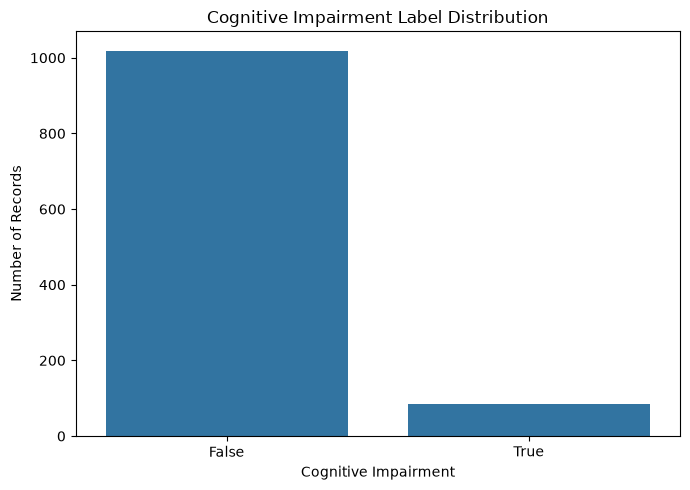

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Cognitive_Impairment"
)

plt.title("Cognitive Impairment Label Distribution")
plt.xlabel("Cognitive Impairment")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [11]:
# Count records for each hospital
print("Records per hospital:")
display(df["SiteID"].value_counts())

# Compare target labels across hospitals
print("\nCognitive impairment by hospital:")
site_labels = pd.crosstab(
    df["SiteID"],
    df["Cognitive_Impairment"],
    margins=True
)

display(site_labels)

Records per hospital:


SiteID
S0001    857
I0006    192
I0002     54
Name: count, dtype: int64


Cognitive impairment by hospital:


Cognitive_Impairment,False,True,All
SiteID,,,
I0002,46,8,54
I0006,172,20,192
S0001,801,56,857
All,1019,84,1103


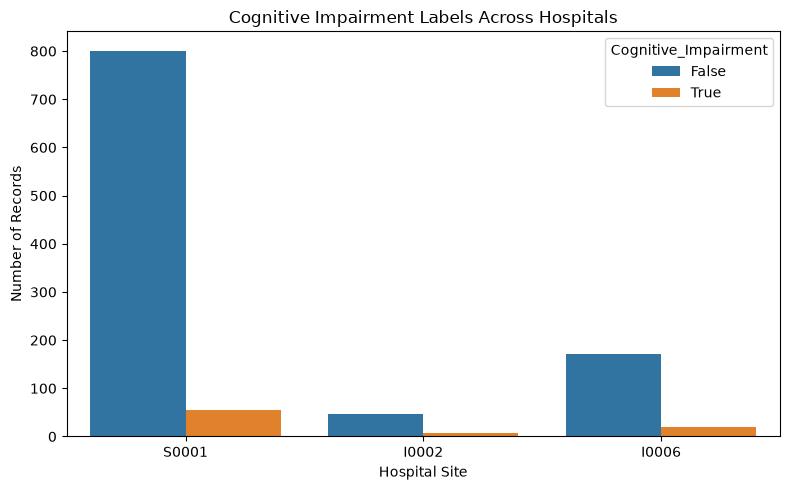

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="SiteID",
    hue="Cognitive_Impairment"
)

plt.title("Cognitive Impairment Labels Across Hospitals")
plt.xlabel("Hospital Site")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [13]:
# Select initial demographic features
features = [
    "Age",
    "Sex",
    "Race",
    "Ethnicity",
    "BMI"
]

X = df[features].copy()
y = df["Cognitive_Impairment"].copy()

# Remove records with missing target labels
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(bool).astype(int)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True).round(4))

Feature matrix shape: (1103, 5)
Target shape: (1103,)

Features:
['Age', 'Sex', 'Race', 'Ethnicity', 'BMI']

Target distribution:
Cognitive_Impairment
0    1019
1      84
Name: count, dtype: int64

Target proportions:
Cognitive_Impairment
0    0.9238
1    0.0762
Name: proportion, dtype: float64


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (827, 5)
Testing features: (276, 5)

Training target distribution:
Cognitive_Impairment
0    764
1     63
Name: count, dtype: int64

Testing target distribution:
Cognitive_Impairment
0    255
1     21
Name: count, dtype: int64


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate feature types
numeric_features = ["Age", "BMI"]
categorical_features = ["Sex", "Race", "Ethnicity"]

# Process numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit only on training data; transform the test data without refitting
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Preprocessing completed successfully!")

Processed training shape: (827, 12)
Processed testing shape: (276, 12)
Preprocessing completed successfully!


In [16]:
from sklearn.linear_model import LogisticRegression

# Initialize the model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [17]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict class labels and positive-class probabilities
y_pred = lr_model.predict(X_test_processed)
y_prob = lr_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
print("LOGISTIC REGRESSION — TEST RESULTS")
print("-" * 40)
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Precision:         {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:            {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:          {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_prob):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

LOGISTIC REGRESSION — TEST RESULTS
----------------------------------------
Accuracy:          0.7029
Balanced Accuracy: 0.6207
Precision:         0.1325
Recall:            0.5238
F1-score:          0.2115
ROC-AUC:           0.7044

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.72      0.82       255
           1       0.13      0.52      0.21        21

    accuracy                           0.70       276
   macro avg       0.54      0.62      0.51       276
weighted avg       0.89      0.70      0.77       276

Confusion Matrix:
[[183  72]
 [ 10  11]]


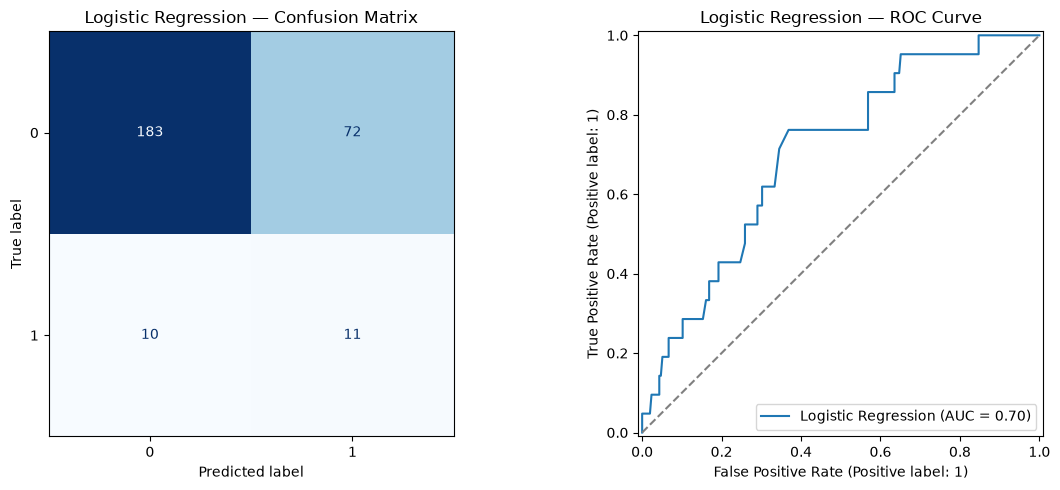

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("Logistic Regression — Confusion Matrix")

# ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=axes[1],
    name="Logistic Regression"
)
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("Logistic Regression — ROC Curve")

plt.tight_layout()
plt.show()

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    min_samples_leaf=3,
    random_state=42
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("RANDOM FOREST — EVALUATION")
print("-" * 40)

print(f"Accuracy:  {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision: {precision_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, rf_prob):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["No Cognitive Impairment", "Cognitive Impairment"],
    zero_division=0
))

RANDOM FOREST — EVALUATION
----------------------------------------
Accuracy:  0.7862
Precision: 0.1833
Recall:    0.5238
F1-score:  0.2716
ROC-AUC:   0.7346

Classification Report:
                         precision    recall  f1-score   support

No Cognitive Impairment       0.95      0.81      0.87       255
   Cognitive Impairment       0.18      0.52      0.27        21

               accuracy                           0.79       276
              macro avg       0.57      0.67      0.57       276
           weighted avg       0.90      0.79      0.83       276



In [21]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Recall": recall_score(y_test, rf_pred, zero_division=0),
        "F1-score": f1_score(y_test, rf_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, rf_prob)
    }
])

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7029,0.1325,0.5238,0.2115,0.7044
1,Random Forest,0.7862,0.1833,0.5238,0.2716,0.7346


In [22]:
# Inspect time-related variables and their data types

time_columns = [
    "CreationTime",
    "Time_to_Event",
    "Last_Known_Visit_Date",
    "Time_to_Last_Visit"
]

print("TIME-RELATED COLUMN SUMMARY")
print("-" * 50)

for col in time_columns:
    print(f"\nColumn: {col}")
    print("Data type:", df[col].dtype)
    print("Missing values:", df[col].isna().sum())
    print("Unique values:", df[col].nunique())
    print("Sample values:")
    print(df[col].dropna().head(5).to_list())

TIME-RELATED COLUMN SUMMARY
--------------------------------------------------

Column: CreationTime
Data type: str
Missing values: 0
Unique values: 1093
Sample values:
['2008-12-04 21:50:00', '2016-05-14 22:30:01', '2009-08-13 01:37:44', '2010-07-27 22:25:00', '2014-02-28 21:37:52']

Column: Time_to_Event
Data type: float64
Missing values: 1019
Unique values: 82
Sample values:
[1971.0, 1539.0, 1199.0, 911.0, 1485.0]

Column: Last_Known_Visit_Date
Data type: str
Missing values: 0
Unique values: 759
Sample values:
['2022-10-13 00:00:00', '2024-01-03 00:00:00', '2022-11-10 00:00:00', '2024-06-08 00:00:00', '2024-08-12 00:00:00']

Column: Time_to_Last_Visit
Data type: int64
Missing values: 0
Unique values: 931
Sample values:
[5060, 2789, 4836, 5064, 3817]


In [23]:
# Check whether Time_to_Event missingness aligns with the target

print("TARGET COUNTS")
print(df["Cognitive_Impairment"].value_counts(dropna=False))

print("\nTIME_TO_EVENT MISSINGNESS BY TARGET")
missingness_table = pd.crosstab(
    df["Cognitive_Impairment"],
    df["Time_to_Event"].isna(),
    margins=True
)

missingness_table.columns = [
    "Time_to_Event Present",
    "Time_to_Event Missing",
    "Total"
]

display(missingness_table)

print("\nTARGET DISTRIBUTION BY MISSINGNESS")
display(
    pd.crosstab(
        df["Time_to_Event"].isna(),
        df["Cognitive_Impairment"],
        normalize="index"
    ).round(4)
)

TARGET COUNTS
Cognitive_Impairment
False    1019
True       84
Name: count, dtype: int64

TIME_TO_EVENT MISSINGNESS BY TARGET


,Time_to_Event Present,Time_to_Event Missing,Total
Cognitive_Impairment,,,
False,0,1019,1019
True,84,0,84
All,84,1019,1103



TARGET DISTRIBUTION BY MISSINGNESS


Cognitive_Impairment,False,True
Time_to_Event,,
False,0.0,1.0
True,1.0,0.0


In [24]:
# Demonstrate whether Time_to_Event missingness predicts the target

shortcut_pred = df["Time_to_Event"].notna().astype(int)
actual_target = df["Cognitive_Impairment"].astype(int)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("TIME_TO_EVENT MISSINGNESS-ONLY BASELINE")
print("-" * 45)
print(f"Accuracy:  {accuracy_score(actual_target, shortcut_pred):.4f}")
print(f"Precision: {precision_score(actual_target, shortcut_pred):.4f}")
print(f"Recall:    {recall_score(actual_target, shortcut_pred):.4f}")
print(f"F1-score:  {f1_score(actual_target, shortcut_pred):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(actual_target, shortcut_pred))

TIME_TO_EVENT MISSINGNESS-ONLY BASELINE
---------------------------------------------
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000

Confusion Matrix:
[[1019    0]
 [   0   84]]


In [25]:
print("FOLLOW-UP DURATION BY TARGET")
display(
    df.groupby("Cognitive_Impairment")["Time_to_Last_Visit"]
    .agg(["count", "median", "mean", "min", "max"])
    .round(2)
)

print("\nCREATION TIME RANGE BY TARGET")
df["CreationTime"] = pd.to_datetime(df["CreationTime"], errors="coerce")

display(
    df.groupby("Cognitive_Impairment")["CreationTime"]
    .agg(["min", "median", "max"])
)

FOLLOW-UP DURATION BY TARGET


,count,median,mean,min,max
Cognitive_Impairment,,,,,
False,1019,3637.0,3632.38,2192,18749
True,84,2465.5,2669.05,530,5368



CREATION TIME RANGE BY TARGET


,min,median,max
Cognitive_Impairment,,,
False,2007-08-11 22:34:03,2012-11-12 22:56:37,2019-05-10 21:42:13
True,2008-05-15 22:59:49,2015-07-13 22:54:48,2020-10-19 19:12:59


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.linear_model import LogisticRegression

# Use database creation year only
time_df = df[["CreationTime", "Cognitive_Impairment"]].dropna().copy()

time_df["CreationYear"] = time_df["CreationTime"].dt.year

X_time = time_df[["CreationYear"]]
y_time = time_df["Cognitive_Impairment"].astype(int)

X_train_time, X_test_time, y_train_time, y_test_time = train_test_split(
    X_time,
    y_time,
    test_size=0.25,
    random_state=42,
    stratify=y_time
)

time_model = LogisticRegression(class_weight="balanced", max_iter=1000)
time_model.fit(X_train_time, y_train_time)

time_pred = time_model.predict(X_test_time)
time_prob = time_model.predict_proba(X_test_time)[:, 1]

print("CREATION-YEAR-ONLY BASELINE")
print("-" * 35)
print(f"Accuracy: {accuracy_score(y_test_time, time_pred):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test_time, time_prob):.4f}")

CREATION-YEAR-ONLY BASELINE
-----------------------------------
Accuracy: 0.6014
ROC-AUC:  0.6725


In [27]:
baseline_comparison = pd.DataFrame([
    {
        "Baseline": "Demographics - Logistic Regression",
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    },
    {
        "Baseline": "Demographics - Random Forest",
        "ROC-AUC": roc_auc_score(y_test, rf_prob)
    },
    {
        "Baseline": "Creation Year Only",
        "ROC-AUC": roc_auc_score(y_test_time, time_prob)
    }
])

display(baseline_comparison.round(4))

,Baseline,ROC-AUC
0,Demographics - Logistic Regression,0.7044
1,Demographics - Random Forest,0.7346
2,Creation Year Only,0.6725


In [28]:
site_summary = (
    df.groupby("SiteID")["Cognitive_Impairment"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Total Records",
        "sum": "Positive Cases",
        "mean": "Positive Rate"
    })
)

site_summary["Positive Rate"] *= 100

display(site_summary.round(2))

,Total Records,Positive Cases,Positive Rate
SiteID,,,
I0002,54,8,14.81
I0006,192,20,10.42
S0001,857,56,6.53


In [29]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score

# Use the same train/test rows as the demographic models
X_site = df.loc[X.index, ["SiteID"]]

X_train_site = X_site.loc[X_train.index]
X_test_site = X_site.loc[X_test.index]

site_model = make_pipeline(
    OneHotEncoder(handle_unknown="ignore"),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)

site_model.fit(X_train_site, y_train)

site_prob = site_model.predict_proba(X_test_site)[:, 1]
site_pred = site_model.predict(X_test_site)

print("SITE-ONLY BASELINE")
print("-" * 35)
print(f"Accuracy: {accuracy_score(y_test, site_pred):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, site_prob):.4f}")

SITE-ONLY BASELINE
-----------------------------------
Accuracy: 0.7464
ROC-AUC:  0.5195


In [30]:
# Inspect how the dataset references sleep recordings

print("BIDS FOLDER EXAMPLES")
display(df[["SiteID", "BDSPPatientID", "SessionID", "BidsFolder"]].head(10))

print("\nSESSION COUNTS")
display(df["SessionID"].value_counts(dropna=False))

print("\nBIDS FOLDER SUMMARY")
print("Missing BidsFolder values:", df["BidsFolder"].isna().sum())
print("Unique BidsFolder values:", df["BidsFolder"].nunique())

print("\nEXAMPLE BIDS FOLDER VALUES")
for value in df["BidsFolder"].dropna().unique()[:10]:
    print(value)

BIDS FOLDER EXAMPLES


,SiteID,BDSPPatientID,SessionID,BidsFolder
0,S0001,120173185,1,sub-S0001120173185
1,S0001,112722303,1,sub-S0001112722303
2,S0001,116945514,1,sub-S0001116945514
3,S0001,113953169,1,sub-S0001113953169
4,S0001,111625329,1,sub-S0001111625329
5,S0001,120942410,1,sub-S0001120942410
6,I0002,150028151,1,sub-I0002150028151
7,I0006,179013367,1,sub-I0006179013367
8,S0001,113230703,1,sub-S0001113230703
9,I0002,150028366,1,sub-I0002150028366



SESSION COUNTS


SessionID
1    1054
2      36
3       8
4       4
5       1
Name: count, dtype: int64


BIDS FOLDER SUMMARY
Missing BidsFolder values: 0
Unique BidsFolder values: 1103

EXAMPLE BIDS FOLDER VALUES
sub-S0001120173185
sub-S0001112722303
sub-S0001116945514
sub-S0001113953169
sub-S0001111625329
sub-S0001120942410
sub-I0002150028151
sub-I0006179013367
sub-S0001113230703
sub-I0002150028366


In [31]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "kaggle",
        "datasets",
        "files",
        "-d",
        "physionet/physionetchallenge2026data"
    ],
    capture_output=True,
    text=True,
    timeout=120
)

print("Return code:", result.returncode)
print("\nFILE INVENTORY (first 10000 characters):")
print(result.stdout[:10000])

if result.stderr:
    print("\nERROR / STATUS:")
    print(result.stderr[:3000])

Return code: 0

FILE INVENTORY (first 10000 characters):
Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7iZrKcmKWs7srR2ona009zYeT2qN2xbrDG3wuRmkG0SDblodxGuDAeR6WhsywzUrmSVeAv8Mg2PBPPKhn_U0z-Ji7eZK8LsfyOkQLOJ2nx6ztNTpSTmlOuBqC9-WHHHtsbM9RCUVzhCmnyUDtwjPl94jF4Uy3vm7B-LfRqF4tl8dkfd6EQ93tGjeIZzrKyC-g9eAqFo
name                                                                            size  creationDate                
----------------------------------------------------------------------------  ------  --------------------------  
ICD_codes_CI.csv                                                               88731  2026-06-03 17:07:43.485000  
algorithmic_annotations/I0002/sub-I0002150000076_ses-1_caisr_annotations.edf  507864  2026-06-03 17:07:47.165000  
algorithmic_annotations/I0002/sub-I0002150000540_ses-2_caisr_annotations.edf  413400  2026-06-03 17:07:47.147000  
algorithmic_annotations/I0002/sub-I0002150000686_ses-1_caisr_annotations.edf  429636  2026-06-03 17:07:47.174000  
algorithmi

In [32]:
import subprocess
import sys
import re

dataset = "physionet/physionetchallenge2026data"
page_token = None
all_pages = []

for page in range(5):
    command = [
        sys.executable, "-m", "kaggle",
        "datasets", "files", "-d", dataset
    ]

    if page_token:
        command.extend(["-m", page_token])

    result = subprocess.run(
        command, capture_output=True, text=True, timeout=120
    )

    if result.returncode != 0:
        print("Inventory request failed:")
        print(result.stderr[:2000])
        break

    output = result.stdout
    all_pages.append(output)

    match = re.search(r"Next Page Token = (.+)", output)
    page_token = match.group(1).strip() if match else None

    print(f"Inventory page {page + 1} retrieved.")

    if not page_token:
        print("No additional page token found.")
        break

print("\nPOSSIBLE SLEEP SIGNAL FILES")
print("-" * 60)

extensions = (".edf", ".bdf", ".fif", ".vhdr", ".eeg", ".set", ".mat")
found = set()

for output in all_pages:
    for line in output.splitlines():
        lower = line.lower()
        if (
            lower.strip().endswith(extensions)
            and "algorithmic_annotations/" not in lower
        ):
            found.add(line.strip())

for filename in sorted(found)[:60]:
    print(filename)

print(f"\nMatching entries across retrieved pages: {len(found)}")

Inventory page 1 retrieved.
Inventory request failed:
usage: __main__.py [-h] [-v] [-W]
                   {competitions,c,datasets,d,kernels,k,models,m,files,forums,f,benchmarks,b,config,auth,quota}
                   ...
__main__.py: error: unrecognized arguments: -m


POSSIBLE SLEEP SIGNAL FILES
------------------------------------------------------------

Matching entries across retrieved pages: 0


In [33]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable, "-m", "kaggle",
        "datasets", "files", "--help"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
if result.stderr:
    print(result.stderr)

usage: __main__.py datasets files [-h] [-v | --format OUTPUT_FORMAT]
                                  [--page-token PAGE_TOKEN]
                                  [--page-size PAGE_SIZE]
                                  [dataset]

options:
  -h, --help            show this help message and exit
  dataset               Dataset URL suffix in format <owner>/<dataset-name> (use "kaggle datasets list" to show options)
  -v, --csv             Print results in CSV format (if not set print in table format)
  --format OUTPUT_FORMAT
                        Print results in selected format (csv, table, json). For details on advanced options, see
                        https://github.com/Kaggle/kaggle-cli/blob/main/docs/output_format.md
  --page-token PAGE_TOKEN
                        Page token for results paging.
  --page-size PAGE_SIZE
                        Number of items to show on a page. Default size is 20, max is 200



In [34]:
import subprocess
import sys
import re

dataset = "physionet/physionetchallenge2026data"
page_token = None
all_pages = []

for page in range(5):
    command = [
        sys.executable, "-m", "kaggle",
        "datasets", "files",
        "--page-size", "200",
        "--format", "json",
        dataset
    ]

    if page_token:
        command.extend(["--page-token", page_token])

    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=120
    )

    if result.returncode != 0:
        print("Request failed:")
        print(result.stderr[:2000])
        break

    output = result.stdout
    all_pages.append(output)

    # Extract the next-page token if provided
    match = re.search(r'"nextPageToken"\s*:\s*"([^"]+)"', output)
    page_token = match.group(1) if match else None

    print(f"Inventory page {page + 1} retrieved.")

    if not page_token:
        print("No additional page token found.")
        break

print("\nPOSSIBLE RAW SLEEP SIGNAL FILES")
print("-" * 50)

extensions = (".edf", ".bdf", ".fif", ".vhdr", ".eeg", ".set", ".mat")
found = set()

for output in all_pages:
    for line in output.splitlines():
        lower = line.lower()
        if (
            lower.strip().endswith(extensions)
            and "algorithmic_annotations/" not in lower
        ):
            found.add(line.strip())

for filename in sorted(found)[:60]:
    print(filename)

print(f"\nMatching entries: {len(found)}")

Inventory page 1 retrieved.
No additional page token found.

POSSIBLE RAW SLEEP SIGNAL FILES
--------------------------------------------------

Matching entries: 0


In [35]:
import subprocess
import sys
import json

result = subprocess.run(
    [
        sys.executable, "-m", "kaggle",
        "datasets", "files",
        "--page-size", "5",
        "--format", "json",
        "physionet/physionetchallenge2026data"
    ],
    capture_output=True,
    text=True,
    timeout=120
)

print("Return code:", result.returncode)
print("\nRAW JSON RESPONSE:")
print(result.stdout[:6000])

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr[:2000])

try:
    payload = json.loads(result.stdout)
    print("\nJSON TYPE:", type(payload).__name__)
    if isinstance(payload, dict):
        print("TOP-LEVEL KEYS:", list(payload.keys()))
except json.JSONDecodeError as exc:
    print("\nJSON parsing error:", exc)

Return code: 0

RAW JSON RESPONSE:
Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7jqzqkhAkrSaxn5QquMX5QwJAh_fMMU1699oCLyPTBNbQQ4LRKN6-mqk4-xhoLFc3Osd-RglR1ZNaq-luDxJpWcmoLk_oJzjfo4azuEzUNn7RnYvmQ5ClelBEs5_L7nVK1tOtQpEce9HNd-V9Gv82qfZgsC5GmiUnuF_xunKCCShqu71NSpH9EXYZ2ENHpUY4ZIifzv
[
  {
    "name": "ICD_codes_CI.csv",
    "size": 88731,
    "creationDate": "2026-06-03T17:07:43.485000"
  },
  {
    "name": "algorithmic_annotations/I0002/sub-I0002150000076_ses-1_caisr_annotations.edf",
    "size": 507864,
    "creationDate": "2026-06-03T17:07:47.165000"
  },
  {
    "name": "algorithmic_annotations/I0002/sub-I0002150000540_ses-2_caisr_annotations.edf",
    "size": 413400,
    "creationDate": "2026-06-03T17:07:47.147000"
  },
  {
    "name": "algorithmic_annotations/I0002/sub-I0002150000686_ses-1_caisr_annotations.edf",
    "size": 429636,
    "creationDate": "2026-06-03T17:07:47.174000"
  },
  {
    "name": "algorithmic_annotations/I0002/sub-I0002150003895_ses-1_caisr_annotations.edf",
    "

In [36]:
import subprocess
import sys
import json
import re

dataset = "physionet/physionetchallenge2026data"
page_token = None
all_files = []

for page in range(5):
    command = [
        sys.executable, "-m", "kaggle",
        "datasets", "files",
        "--page-size", "200",
        "--format", "json",
        dataset
    ]

    if page_token:
        command.extend(["--page-token", page_token])

    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=120
    )

    if result.returncode != 0:
        print(result.stderr)
        break

    output = result.stdout

    # Extract token from the text preceding the JSON array
    token_match = re.search(
        r"Next Page Token\s*=\s*(.+)",
        output
    )
    page_token = token_match.group(1).strip() if token_match else None

    # Parse the JSON array separately
    json_start = output.find("[")
    if json_start == -1:
        print("Could not find JSON array on page", page + 1)
        print(output[:1000])
        break

    files_on_page = json.loads(output[json_start:])
    all_files.extend(files_on_page)

    print(f"Page {page + 1}: {len(files_on_page)} files")

    if not page_token:
        print("No further page token.")
        break

print("\nTOTAL FILES RETRIEVED:", len(all_files))

print("\nPOSSIBLE RAW SLEEP RECORDINGS")
extensions = (".edf", ".bdf", ".fif", ".vhdr", ".eeg", ".set", ".mat")

raw_files = [
    item for item in all_files
    if item["name"].lower().endswith(extensions)
    and "algorithmic_annotations/" not in item["name"].lower()
]

for item in raw_files[:40]:
    print(f'{item["size"] / (1024**2):.2f} MB | {item["name"]}')

print("\nPotential raw recording files found:", len(raw_files))

Page 1: 200 files
Page 2: 200 files
Page 3: 200 files
Page 4: 200 files
Page 5: 200 files

TOTAL FILES RETRIEVED: 1000

POSSIBLE RAW SLEEP RECORDINGS

Potential raw recording files found: 0


In [37]:
import subprocess
import sys
import json
import re
from collections import Counter

dataset = "physionet/physionetchallenge2026data"

# Continue from the last page retrieved in Cell 29
for page in range(25):
    if not page_token:
        print("Reached the end of the inventory.")
        break

    result = subprocess.run(
        [
            sys.executable, "-m", "kaggle",
            "datasets", "files",
            "--page-size", "200",
            "--format", "json",
            "--page-token", page_token,
            dataset
        ],
        capture_output=True,
        text=True,
        timeout=120
    )

    if result.returncode != 0:
        print("Request failed:", result.stderr[:1000])
        break

    output = result.stdout
    token_match = re.search(r"Next Page Token\s*=\s*(.+)", output)
    next_token = token_match.group(1).strip() if token_match else None

    json_start = output.find("[")
    if json_start == -1:
        print("Could not parse page output.")
        break

    page_files = json.loads(output[json_start:])
    all_files.extend(page_files)
    page_token = next_token

    print(f"Additional page {page + 1}: {len(page_files)} files")

    if not page_token:
        print("Reached the end of the inventory.")
        break

print("\nTOTAL INVENTORY ENTRIES:", len(all_files))

# Summarize file extensions and top-level directories
extensions = Counter()
folders = Counter()

for item in all_files:
    name = item["name"]
    lower = name.lower()
    extension = "." + lower.rsplit(".", 1)[-1] if "." in lower else "[no extension]"
    extensions[extension] += 1
    folders[name.split("/")[0]] += 1

print("\nTOP-LEVEL FOLDERS")
for folder, count in folders.most_common(25):
    print(f"{folder}: {count}")

print("\nFILE EXTENSIONS")
for extension, count in extensions.most_common(25):
    print(f"{extension}: {count}")

print("\nPOTENTIAL RAW EDF FILES")
raw_edf = [
    item for item in all_files
    if item["name"].lower().endswith(".edf")
    and "algorithmic_annotations/" not in item["name"].lower()
]
for item in raw_edf[:30]:
    print(f'{item["size"] / (1024**2):.2f} MB | {item["name"]}')

print("Raw EDF candidates found:", len(raw_edf))

Additional page 1: 200 files
Additional page 2: 200 files
Additional page 3: 200 files
Additional page 4: 200 files
Additional page 5: 200 files
Additional page 6: 200 files
Additional page 7: 200 files
Additional page 8: 200 files
Additional page 9: 200 files
Additional page 10: 200 files
Additional page 11: 200 files
Additional page 12: 92 files
Reached the end of the inventory.

TOTAL INVENTORY ENTRIES: 3292

TOP-LEVEL FOLDERS
physiological_data: 1103
human_annotations: 1097
algorithmic_annotations: 1090
ICD_codes_CI.csv: 1
demographics.csv: 1

FILE EXTENSIONS
.edf: 3290
.csv: 2

POTENTIAL RAW EDF FILES
0.24 MB | human_annotations/I0002/sub-I0002150000076_ses-1_expert_annotations.edf
0.19 MB | human_annotations/I0002/sub-I0002150000540_ses-2_expert_annotations.edf
0.20 MB | human_annotations/I0002/sub-I0002150000686_ses-1_expert_annotations.edf
0.23 MB | human_annotations/I0002/sub-I0002150003895_ses-1_expert_annotations.edf
0.32 MB | human_annotations/I0002/sub-I0002150007182_ses-1

In [38]:
# Build a file lookup from the Kaggle inventory

inventory_names = {item["name"] for item in all_files}

def recording_path(site, bids_folder, session):
    return (
        f"physiological_data/{site}/"
        f"{bids_folder}_ses-{session}.edf"
    )

def human_annotation_path(site, bids_folder, session):
    return (
        f"human_annotations/{site}/"
        f"{bids_folder}_ses-{session}_expert_annotations.edf"
    )

def algorithmic_annotation_path(site, bids_folder, session):
    return (
        f"algorithmic_annotations/{site}/"
        f"{bids_folder}_ses-{session}_caisr_annotations.edf"
    )

cohort_files = df.copy()

cohort_files["PhysiologyPath"] = cohort_files.apply(
    lambda r: recording_path(
        r["SiteID"], r["BidsFolder"], r["SessionID"]
    ),
    axis=1
)

cohort_files["HumanAnnotationPath"] = cohort_files.apply(
    lambda r: human_annotation_path(
        r["SiteID"], r["BidsFolder"], r["SessionID"]
    ),
    axis=1
)

cohort_files["AlgorithmicAnnotationPath"] = cohort_files.apply(
    lambda r: algorithmic_annotation_path(
        r["SiteID"], r["BidsFolder"], r["SessionID"]
    ),
    axis=1
)

cohort_files["HasPhysiology"] = cohort_files["PhysiologyPath"].isin(
    inventory_names
)

cohort_files["HasHumanAnnotation"] = cohort_files[
    "HumanAnnotationPath"
].isin(inventory_names)

cohort_files["HasAlgorithmicAnnotation"] = cohort_files[
    "AlgorithmicAnnotationPath"
].isin(inventory_names)

display(
    cohort_files[
        [
            "SiteID", "BidsFolder", "SessionID",
            "HasPhysiology", "HasHumanAnnotation",
            "HasAlgorithmicAnnotation"
        ]
    ].head(10)
)

print("\nMATCHING SUMMARY")
display(
    cohort_files[
        [
            "HasPhysiology",
            "HasHumanAnnotation",
            "HasAlgorithmicAnnotation"
        ]
    ].sum().to_frame("Matched records")
)

,SiteID,BidsFolder,SessionID,HasPhysiology,HasHumanAnnotation,HasAlgorithmicAnnotation
0,S0001,sub-S0001120173185,1,True,True,True
1,S0001,sub-S0001112722303,1,True,True,True
2,S0001,sub-S0001116945514,1,True,True,True
3,S0001,sub-S0001113953169,1,True,True,True
4,S0001,sub-S0001111625329,1,True,True,True
5,S0001,sub-S0001120942410,1,True,True,True
6,I0002,sub-I0002150028151,1,True,True,True
7,I0006,sub-I0006179013367,1,True,True,True
8,S0001,sub-S0001113230703,1,True,True,True
9,I0002,sub-I0002150028366,1,True,True,True



MATCHING SUMMARY


,Matched records
HasPhysiology,1103
HasHumanAnnotation,1097
HasAlgorithmicAnnotation,1090


In [39]:
# Select one record with all three file types available

eligible = cohort_files[
    cohort_files["HasPhysiology"]
    & cohort_files["HasHumanAnnotation"]
    & cohort_files["HasAlgorithmicAnnotation"]
].copy()

print("Eligible records:", len(eligible))

# Select one positive and one negative record for later comparison
print("\nAvailable target counts:")
display(eligible["Cognitive_Impairment"].value_counts())

# Start with one positive record for inspection
positive_example = eligible[
    eligible["Cognitive_Impairment"] == True
].iloc[0]

print("\nSelected example:")
display(
    positive_example[
        [
            "SiteID",
            "BidsFolder",
            "SessionID",
            "Cognitive_Impairment",
            "PhysiologyPath",
            "HumanAnnotationPath",
            "AlgorithmicAnnotationPath"
        ]
    ].to_frame("Value")
)

Eligible records: 1085

Available target counts:


Cognitive_Impairment
False    1001
True       84
Name: count, dtype: int64


Selected example:


,Value
SiteID,S0001
BidsFolder,sub-S0001118606205
SessionID,1
Cognitive_Impairment,True
PhysiologyPath,physiological_data/S0001/sub-S0001118606205_se...
HumanAnnotationPath,human_annotations/S0001/sub-S0001118606205_ses...
AlgorithmicAnnotationPath,algorithmic_annotations/S0001/sub-S00011186062...


In [40]:
import subprocess
import sys
from pathlib import Path

PROJECT_DIR = Path(r"D:\Downloads\BEST AI PROJECTS\BDS")
DOWNLOAD_DIR = PROJECT_DIR / "data" / "sample_edf"
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

selected_path = positive_example["PhysiologyPath"]

print("Selected file:", selected_path)
print("Download directory:", DOWNLOAD_DIR)

result = subprocess.run(
    [
        sys.executable, "-m", "kaggle",
        "datasets", "download",
        "-d", "physionet/physionetchallenge2026data",
        "-f", selected_path,
        "-p", str(DOWNLOAD_DIR)
    ],
    capture_output=True,
    text=True,
    timeout=600
)

print("\nReturn code:", result.returncode)
print(result.stdout[-3000:])

if result.stderr:
    print("\nStatus / errors:")
    print(result.stderr[-2000:])

Selected file: physiological_data/S0001/sub-S0001118606205_ses-1.edf
Download directory: D:\Downloads\BEST AI PROJECTS\BDS\data\sample_edf

Return code: 0
Dataset URL: https://www.kaggle.com/datasets/physionet/physionetchallenge2026data
License(s): other
sub-S0001118606205_ses-1.edf: Skipping, found more recently modified local copy (use --force to force download)



In [41]:
from pathlib import Path

DOWNLOAD_DIR = Path(r"D:\Downloads\BEST AI PROJECTS\BDS\data\sample_edf")

print("Files in download directory:\n")

for file in DOWNLOAD_DIR.iterdir():
    print(f"{file.name} | {file.stat().st_size / (1024**2):.2f} MB")

Files in download directory:

sub-I0002150027762_ses-1.edf | 387.46 MB
sub-I0002150030167_ses-1.edf | 345.07 MB
sub-I0006179001236_ses-1.edf | 192.22 MB
sub-S0001111224131_ses-1.edf | 209.43 MB
sub-S0001117780148_ses-1.edf | 171.23 MB
sub-S0001118406770_ses-1.edf | 189.38 MB
sub-S0001118606205_ses-1.edf | 184.09 MB
sub-S0001118606205_ses-1_expert_annotations.edf | 0.22 MB
sub-S0001119183838_ses-1.edf | 213.28 MB
sub-S0001120173185_ses-1.edf | 190.82 MB
sub-S0001120173185_ses-1_expert_annotations.edf | 0.23 MB
sub-S0001120531112_ses-1.edf | 163.39 MB
sub-S0001121888695_ses-1.edf | 197.38 MB
sub-S0001121888695_ses-1_expert_annotations.edf | 0.22 MB
sub-S0001122301678_ses-1.edf | 207.95 MB


In [42]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable, "-m", "pip",
        "install", "mne"
    ],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace",
    timeout=300
)

print("Return code:", result.returncode)
print(result.stdout[-3000:])

if result.returncode != 0:
    print(result.stderr[-3000:])

Return code: 0



In [43]:
from pathlib import Path
import mne

EDF_PATH = Path(
    r"D:\Downloads\BEST AI PROJECTS\BDS\data\sample_edf"
    r"\sub-S0001118606205_ses-1.edf"
)

if not EDF_PATH.exists():
    raise FileNotFoundError(EDF_PATH)

raw = mne.io.read_raw_edf(
    EDF_PATH,
    preload=False,
    verbose="ERROR"
)

print("RECORDING SUMMARY")
print("-" * 40)
print("File size (MB):", round(EDF_PATH.stat().st_size / (1024**2), 2))
print("Number of channels:", len(raw.ch_names))
print("Recording duration (hours):", round(raw.times[-1] / 3600, 2))
print("Channel names:")
for name in raw.ch_names:
    print(" -", name)

print("\nCHANNEL SAMPLING INFORMATION")
print(raw.info["sfreq"], "Hz (MNE's common sampling frequency)")
print("First sample:", raw.first_samp)
print("Last sample:", raw.last_samp)

RECORDING SUMMARY
----------------------------------------
File size (MB): 184.09
Number of channels: 17
Recording duration (hours): 7.88
Channel names:
 - F3-M2
 - F4-M1
 - C3-M2
 - C4-M1
 - O1-M2
 - O2-M1
 - E1-M2
 - E2-M2
 - CHIN1-CHIN2
 - LAT
 - RAT
 - AIRFLOW
 - PTAF
 - SaO2
 - CHEST
 - ABD
 - EKG

CHANNEL SAMPLING INFORMATION
200.0 Hz (MNE's common sampling frequency)
First sample: 0
Last sample: 5677199


In [44]:
import numpy as np
import pandas as pd

# Select EEG channels only
eeg_channels = [
    "F3-M2", "F4-M1",
    "C3-M2", "C4-M1",
    "O1-M2", "O2-M1"
]

# Read the first 30 seconds without loading the full recording
start_time = 0
duration_seconds = 30

eeg_data, times = raw.get_data(
    picks=eeg_channels,
    start=int(start_time * raw.info["sfreq"]),
    stop=int((start_time + duration_seconds) * raw.info["sfreq"]),
    return_times=True
)

print("EEG DATA SUMMARY")
print("-" * 40)
print("Shape (channels, samples):", eeg_data.shape)
print("Duration (seconds):", times[-1] - times[0])
print("Sampling rate (Hz):", raw.info["sfreq"])

# Descriptive statistics in the units provided by the EDF reader
eeg_summary = pd.DataFrame({
    "Channel": eeg_channels,
    "Mean": eeg_data.mean(axis=1),
    "Std": eeg_data.std(axis=1),
    "Minimum": eeg_data.min(axis=1),
    "Maximum": eeg_data.max(axis=1)
})

display(eeg_summary.round(6))

EEG DATA SUMMARY
----------------------------------------
Shape (channels, samples): (6, 6000)
Duration (seconds): 29.995
Sampling rate (Hz): 200.0


,Channel,Mean,Std,Minimum,Maximum
0,F3-M2,-0.0,0.000011,-0.000062,0.000050
1,F4-M1,-0.0,0.000010,-0.000049,0.000050
2,C3-M2,-0.0,0.000009,-0.000036,0.000044
3,C4-M1,0.0,0.000010,-0.000053,0.000051
4,O1-M2,0.0,0.000009,-0.000038,0.000036
5,O2-M1,-0.0,0.000010,-0.000045,0.000037


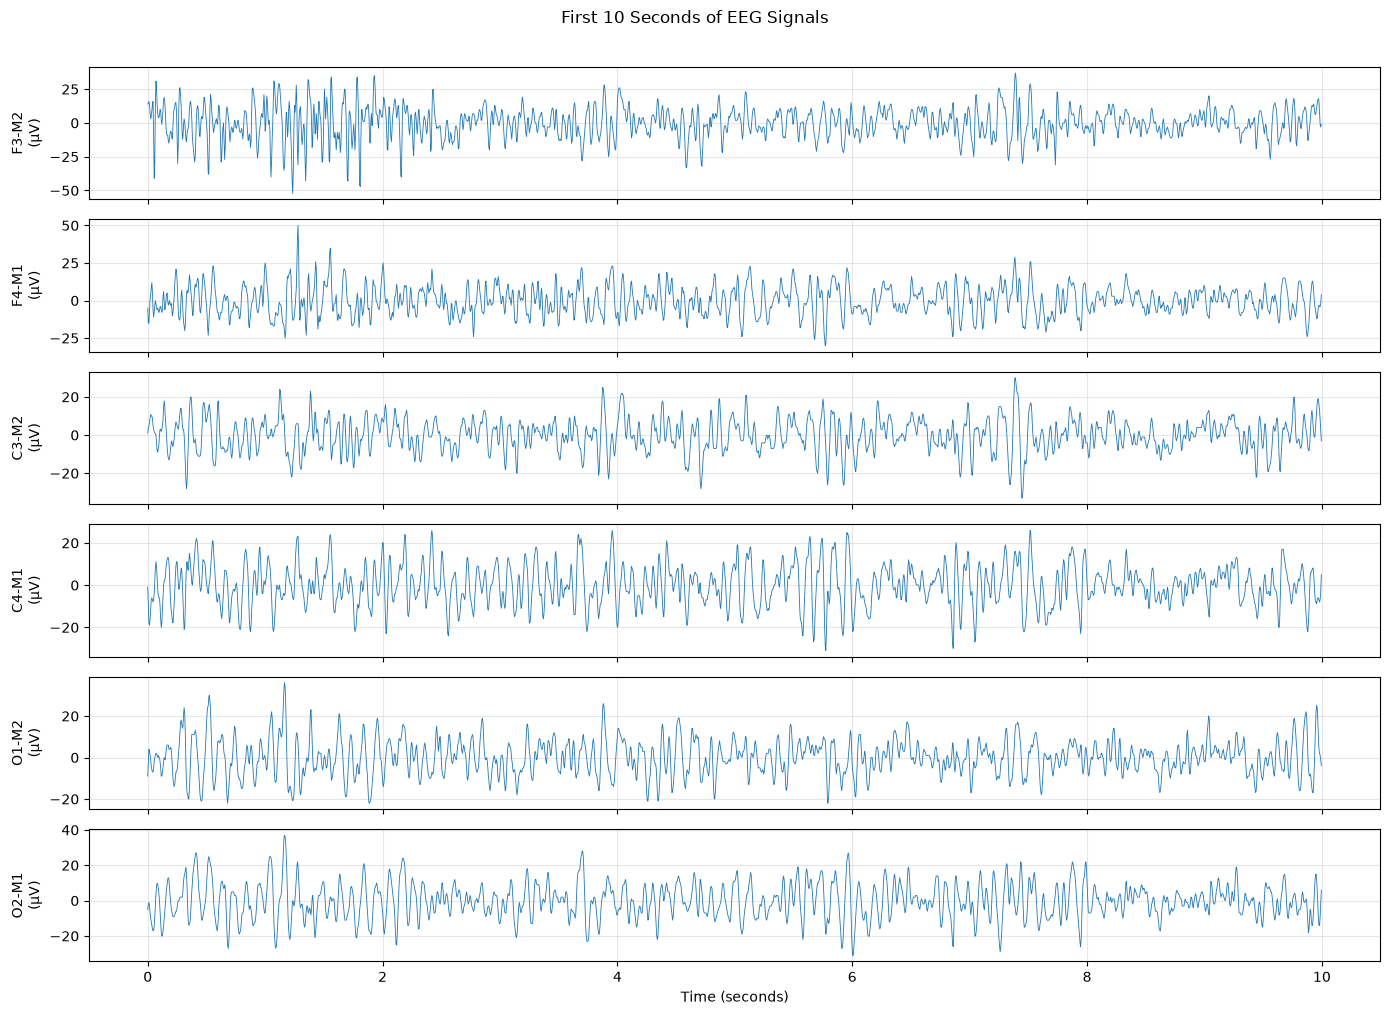

In [45]:
import matplotlib.pyplot as plt

plot_duration = 10
n_samples = int(plot_duration * raw.info["sfreq"])

fig, axes = plt.subplots(
    len(eeg_channels), 1,
    figsize=(14, 10),
    sharex=True
)

for i, channel in enumerate(eeg_channels):
    axes[i].plot(
        times[:n_samples],
        eeg_data[i, :n_samples] * 1e6,
        linewidth=0.6
    )
    axes[i].set_ylabel(f"{channel}\n(µV)")
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("First 10 Seconds of EEG Signals", y=1.01)
plt.tight_layout()
plt.show()

In [46]:
import subprocess
import sys
from pathlib import Path

PROJECT_DIR = Path(r"D:\Downloads\BEST AI PROJECTS\BDS")
ANNOTATION_DIR = PROJECT_DIR / "data" / "sample_edf"
ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)

selected_annotation = positive_example["HumanAnnotationPath"]

print("Selected annotation:", selected_annotation)

result = subprocess.run(
    [
        sys.executable, "-m", "kaggle",
        "datasets", "download",
        "-d", "physionet/physionetchallenge2026data",
        "-f", selected_annotation,
        "-p", str(ANNOTATION_DIR)
    ],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace",
    timeout=600
)

print("\nReturn code:", result.returncode)
print(result.stdout[-2000:])

if result.returncode != 0:
    print(result.stderr[-2000:])
    

Selected annotation: human_annotations/S0001/sub-S0001118606205_ses-1_expert_annotations.edf

Return code: 0
Dataset URL: https://www.kaggle.com/datasets/physionet/physionetchallenge2026data
License(s): other
sub-S0001118606205_ses-1_expert_annotations.edf: Skipping, found more recently modified local copy (use --force to force download)



In [47]:
from pathlib import Path
import mne

ANNOTATION_PATH = (
    ANNOTATION_DIR /
    f'{positive_example["BidsFolder"]}_ses-{positive_example["SessionID"]}_expert_annotations.edf'
)

print("Annotation path:", ANNOTATION_PATH)
print("File exists:", ANNOTATION_PATH.exists())

if ANNOTATION_PATH.exists():
    annotations_raw = mne.io.read_raw_edf(
        ANNOTATION_PATH,
        preload=False,
        verbose="ERROR"
    )

    print("\nANNOTATION FILE SUMMARY")
    print("Channels:", annotations_raw.ch_names)
    print("Duration (hours):", round(annotations_raw.times[-1] / 3600, 2))
    print("Sampling frequency:", annotations_raw.info["sfreq"])

Annotation path: D:\Downloads\BEST AI PROJECTS\BDS\data\sample_edf\sub-S0001118606205_ses-1_expert_annotations.edf
File exists: True

ANNOTATION FILE SUMMARY
Channels: ['arousal_expert', 'limb_expert', 'resp_expert', 'stage_expert']
Duration (hours): 7.88
Sampling frequency: 2.0


In [48]:
import numpy as np
import pandas as pd

# Read only the sleep-stage annotation channel
stage_data, stage_times = annotations_raw.get_data(
    picks=["stage_expert"],
    return_times=True
)

stage_values = stage_data[0]

print("SLEEP STAGE ANNOTATION SUMMARY")
print("-" * 40)
print("Number of samples:", len(stage_values))
print("Sampling frequency:", annotations_raw.info["sfreq"])
print("Duration (seconds):", round(stage_times[-1] - stage_times[0], 2))

print("\nUnique values and their counts:")
unique_values, counts = np.unique(stage_values, return_counts=True)

display(pd.DataFrame({
    "Annotation Value": unique_values,
    "Sample Count": counts,
    "Duration (minutes)": counts / annotations_raw.info["sfreq"] / 60
}).round(3))

SLEEP STAGE ANNOTATION SUMMARY
----------------------------------------
Number of samples: 56760
Sampling frequency: 2.0
Duration (seconds): 28379.5

Unique values and their counts:


,Annotation Value,Sample Count,Duration (minutes)
0,0.485,1,0.008
1,0.485,1,0.008
2,0.486,1,0.008
3,0.487,1,0.008
4,0.488,1,0.008
...,...,...,...
55862,9.550,1,0.008
55863,9.551,1,0.008
55864,9.551,1,0.008
55865,9.551,1,0.008


In [49]:
import numpy as np
import pandas as pd

stage_data, stage_times = annotations_raw.get_data(
    picks=["stage_expert"],
    return_times=True
)

stage_values = stage_data[0]

print("FIRST 20 VALUES")
print(stage_values[:20])

print("\nFIRST 20 SAMPLE TIMES")
print(stage_times[:20])

print("\nBASIC STATISTICS")
print(pd.Series(stage_values).describe())

print("\nSAMPLE-TO-SAMPLE DIFFERENCES")
print(np.diff(stage_values[:20]))

FIRST 20 VALUES
[9.         9.04448332 9.08712117 9.12789379 9.16678439 9.20377926
 9.23886768 9.272042   9.30329758 9.33263281 9.36004907 9.38555072
 9.40914508 9.43084237 9.45065567 9.46860093 9.48469684 9.49896483
 9.51142899 9.52211601]

FIRST 20 SAMPLE TIMES
[0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5.  5.5 6.  6.5 7.  7.5 8.  8.5
 9.  9.5]

BASIC STATISTICS
count    56760.000000
mean         3.139535
std          1.592671
min          0.485046
25%          1.986880
50%          2.227115
75%          4.774598
max          9.551922
dtype: float64

SAMPLE-TO-SAMPLE DIFFERENCES
[0.04448332 0.04263786 0.04077261 0.03889061 0.03699486 0.03508842
 0.03317432 0.03125558 0.02933523 0.02741626 0.02550166 0.02359436
 0.02169728 0.01981331 0.01794526 0.01609591 0.01426799 0.01246416
 0.01068702]


In [50]:
import numpy as np
import pandas as pd

annotation_summary = []

for channel in annotations_raw.ch_names:
    data = annotations_raw.get_data(picks=[channel])[0]

    annotation_summary.append({
        "Channel": channel,
        "Minimum": np.min(data),
        "Maximum": np.max(data),
        "Mean": np.mean(data),
        "Unique values": len(np.unique(data)),
        "First 10 values": np.round(data[:10], 4).tolist()
    })

display(pd.DataFrame(annotation_summary))

,Channel,Minimum,Maximum,Mean,Unique values,First 10 values
0,arousal_expert,0.000000,1.000000,0.050828,2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,limb_expert,-2.122297,10.000000,0.023291,53836,"[-0.0, -0.0099, -0.0, 0.0097, -0.0, -0.0094, -..."
2,resp_expert,-2.306560,11.129812,0.499859,35491,"[0.0, 0.0025, -0.0, -0.0025, -0.0, 0.0025, 0.0..."
3,stage_expert,0.485046,9.551922,3.139535,55867,"[9.0, 9.0445, 9.0871, 9.1279, 9.1668, 9.2038, ..."


In [51]:
# Inspect EDF metadata for the annotation channels

print("CHANNEL METADATA")
print("-" * 50)

for channel in annotations_raw.info["chs"]:
    print({
        "name": channel["ch_name"],
        "kind": channel["kind"],
        "unit": channel["unit"],
        "cal": channel["cal"],
        "range": channel["range"]
    })

print("\nEDF HEADER INFORMATION")
print("File:", ANNOTATION_PATH)
print("Channels:", annotations_raw.ch_names)
print("Sampling frequency:", annotations_raw.info["sfreq"])

CHANNEL METADATA
--------------------------------------------------
{'name': 'arousal_expert', 'kind': 2 (FIFFV_EEG_CH), 'unit': 107 (FIFF_UNIT_V), 'cal': 1.0, 'range': 1.0}
{'name': 'limb_expert', 'kind': 2 (FIFFV_EEG_CH), 'unit': 107 (FIFF_UNIT_V), 'cal': 1.0, 'range': 1.0}
{'name': 'resp_expert', 'kind': 2 (FIFFV_EEG_CH), 'unit': 107 (FIFF_UNIT_V), 'cal': 1.0, 'range': 1.0}
{'name': 'stage_expert', 'kind': 2 (FIFFV_EEG_CH), 'unit': 107 (FIFF_UNIT_V), 'cal': 1.0, 'range': 1.0}

EDF HEADER INFORMATION
File: D:\Downloads\BEST AI PROJECTS\BDS\data\sample_edf\sub-S0001118606205_ses-1_expert_annotations.edf
Channels: ['arousal_expert', 'limb_expert', 'resp_expert', 'stage_expert']
Sampling frequency: 2.0


In [52]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable, "-m", "pip",
        "install", "pyedflib"
    ],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace",
    timeout=300
)

print("Return code:", result.returncode)
print(result.stdout[-2000:])

if result.returncode != 0:
    print(result.stderr[-2000:])

Return code: 0



In [53]:
import pyedflib
import numpy as np

reader = pyedflib.EdfReader(str(ANNOTATION_PATH))

try:
    print("SIGNAL LABELS:", reader.getSignalLabels())

    for i, label in enumerate(reader.getSignalLabels()):
        print(f"\nChannel: {label}")
        print("Samples:", reader.getNSamples()[i])
        print("Sample frequency:", reader.getSampleFrequency(i))
        print("Physical range:", reader.getPhysicalMinimum(i),
              "to", reader.getPhysicalMaximum(i))
        print("Digital range:", reader.getDigitalMinimum(i),
              "to", reader.getDigitalMaximum(i))

        if label == "stage_expert":
            samples = reader.readSignal(i, digital=True)
            print("First 30 digital samples:", samples[:30])
            print("Unique digital values (first 1000 samples):",
                  np.unique(samples[:1000]))
finally:
    reader.close()

SIGNAL LABELS: ['arousal_expert', 'limb_expert', 'resp_expert', 'stage_expert']

Channel: arousal_expert
Samples: 56760
Sample frequency: 2.0
Physical range: 0.0 to 1.0
Digital range: 0 to 1

Channel: limb_expert
Samples: 28380
Sample frequency: 1.0
Physical range: 0.0 to 10.0
Digital range: 0 to 10

Channel: resp_expert
Samples: 28380
Sample frequency: 1.0
Physical range: 0.0 to 10.0
Digital range: 0 to 10

Channel: stage_expert
Samples: 946
Sample frequency: 0.03333333333333333
Physical range: 1.0 to 9.0
Digital range: 1 to 9
First 30 digital samples: [9 9 9 9 9 9 9 9 9 9 9 9 9 9 9 9 9 9 5 5 5 5 5 5 5 3 3 2 3 5]
Unique digital values (first 1000 samples): [1 2 3 4 5 9]


In [54]:
import pyedflib
import pandas as pd

reader = pyedflib.EdfReader(str(ANNOTATION_PATH))

try:
    labels = reader.getSignalLabels()
    stage_index = labels.index("stage_expert")

    stage_codes = reader.readSignal(stage_index, digital=True)

    stage_df = pd.DataFrame({
        "epoch": range(len(stage_codes)),
        "start_seconds": range(0, len(stage_codes) * 30, 30),
        "stage_code": stage_codes.astype(int)
    })

finally:
    reader.close()

stage_names = {
    1: "N3 sleep",
    2: "N2 sleep",
    3: "N1 sleep",
    4: "REM sleep",
    5: "Wake",
    9: "Unavailable"
}

stage_df["stage_name"] = stage_df["stage_code"].map(stage_names)

print("Total 30-second epochs:", len(stage_df))
print("\nSleep-stage counts:")
print(stage_df["stage_name"].value_counts())

print("\nFirst 30 epochs:")
display(stage_df.head(30))

Total 30-second epochs: 946

Sleep-stage counts:
stage_name
N2 sleep       421
Wake           242
REM sleep      101
N1 sleep        94
N3 sleep        70
Unavailable     18
Name: count, dtype: int64

First 30 epochs:


,epoch,start_seconds,stage_code,stage_name
0,0,0,9,Unavailable
1,1,30,9,Unavailable
2,2,60,9,Unavailable
3,3,90,9,Unavailable
4,4,120,9,Unavailable
5,5,150,9,Unavailable
6,6,180,9,Unavailable
7,7,210,9,Unavailable
8,8,240,9,Unavailable
9,9,270,9,Unavailable


In [55]:
# Keep only epochs with a valid scored stage
valid_stages = stage_df[stage_df["stage_code"].isin([1, 2, 3, 4, 5])].copy()

stage_summary = (
    valid_stages.groupby("stage_name")
    .size()
    .rename("epochs")
    .to_frame()
)

stage_summary["duration_minutes"] = stage_summary["epochs"] * 30 / 60
stage_summary["percentage_of_scored_time"] = (
    stage_summary["epochs"] / len(valid_stages) * 100
)

stage_summary = stage_summary.sort_values(
    "percentage_of_scored_time", ascending=False
)

print("Scored epochs:", len(valid_stages))
print("Unavailable epochs:", len(stage_df) - len(valid_stages))
print("\nSleep architecture:")
display(stage_summary.round(2))

Scored epochs: 928
Unavailable epochs: 18

Sleep architecture:


,epochs,duration_minutes,percentage_of_scored_time
stage_name,,,
N2 sleep,421,210.5,45.37
Wake,242,121.0,26.08
REM sleep,101,50.5,10.88
N1 sleep,94,47.0,10.13
N3 sleep,70,35.0,7.54


In [56]:
import mne
import numpy as np
import pandas as pd

# Read the EEG recording
raw = mne.io.read_raw_edf(
    str(EDF_PATH),
    preload=False,
    verbose="ERROR"
)

channel_name = "C3-M2"
sfreq = raw.info["sfreq"]

# Extract the EEG signal in microvolts
eeg = raw.get_data(
    picks=[channel_name],
    units="uV"
)[0]

epoch_seconds = 30
samples_per_epoch = int(sfreq * epoch_seconds)
n_epochs = len(eeg) // samples_per_epoch

# Use only complete 30-second epochs
eeg = eeg[:n_epochs * samples_per_epoch]
eeg_epochs = eeg.reshape(n_epochs, samples_per_epoch)

# Calculate simple features for each epoch
eeg_features = pd.DataFrame({
    "epoch": np.arange(n_epochs),
    "start_seconds": np.arange(n_epochs) * epoch_seconds,
    "eeg_mean_uv": eeg_epochs.mean(axis=1),
    "eeg_std_uv": eeg_epochs.std(axis=1),
    "eeg_rms_uv": np.sqrt(np.mean(eeg_epochs ** 2, axis=1)),
    "eeg_peak_to_peak_uv": (
        eeg_epochs.max(axis=1) - eeg_epochs.min(axis=1)
    )
})

print("EEG channel:", channel_name)
print("Sampling frequency:", sfreq, "Hz")
print("Complete EEG epochs:", n_epochs)
print("\nFirst 10 epochs:")
display(eeg_features.head(10).round(3))

EEG channel: C3-M2
Sampling frequency: 200.0 Hz
Complete EEG epochs: 946

First 10 epochs:


,epoch,start_seconds,eeg_mean_uv,eeg_std_uv,eeg_rms_uv,eeg_peak_to_peak_uv
0,0,0,-0.062,9.295,9.295,79.901
1,1,30,-0.059,42.718,42.718,673.838
2,2,60,-0.031,13.762,13.762,348.916
3,3,90,-0.074,14.397,14.397,122.097
4,4,120,-0.039,13.701,13.701,122.806
5,5,150,0.008,10.858,10.858,189.823
6,6,180,-0.138,13.284,13.285,106.968
7,7,210,-0.072,10.957,10.957,79.073
8,8,240,-0.046,14.272,14.273,93.966
9,9,270,-0.054,13.625,13.625,104.013


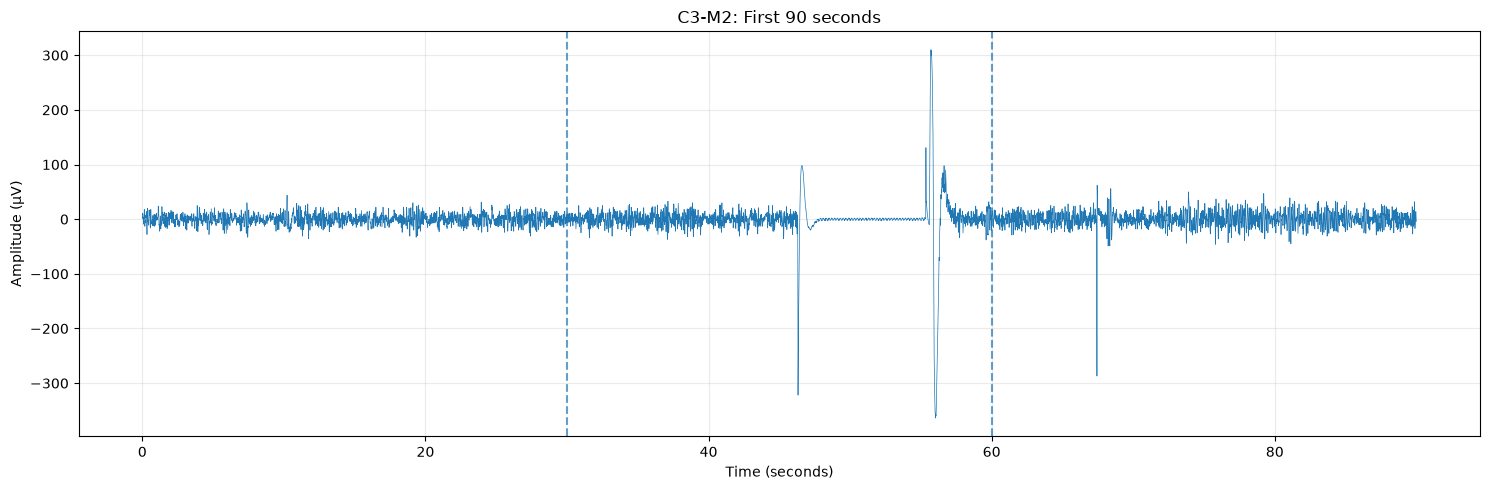

In [57]:
import matplotlib.pyplot as plt

plot_seconds = 90
plot_samples = int(plot_seconds * sfreq)

time_axis = np.arange(plot_samples) / sfreq

plt.figure(figsize=(15, 5))
plt.plot(time_axis, eeg[:plot_samples], linewidth=0.5)

for t in [30, 60]:
    plt.axvline(t, linestyle="--", alpha=0.7)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (µV)")
plt.title(f"{channel_name}: First 90 seconds")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [58]:
# Analyze the first 90 seconds
signal_90 = eeg[:int(90 * sfreq)]

# Amplitude thresholds for screening, not automatic rejection
thresholds = [100, 200, 300]

print("Samples exceeding amplitude thresholds:")
for threshold in thresholds:
    count = np.sum(np.abs(signal_90) > threshold)
    print(
        f"|Amplitude| > {threshold} µV: "
        f"{count} samples ({count / len(signal_90) * 100:.3f}%)"
    )

# Locate the largest absolute amplitudes
largest_idx = np.argsort(np.abs(signal_90))[-10:][::-1]

largest_samples = pd.DataFrame({
    "time_seconds": largest_idx / sfreq,
    "amplitude_uv": signal_90[largest_idx]
}).sort_values("time_seconds")

display(largest_samples.round(3))

Samples exceeding amplitude thresholds:
|Amplitude| > 100 µV: 141 samples (0.783%)
|Amplitude| > 200 µV: 101 samples (0.561%)
|Amplitude| > 300 µV: 44 samples (0.244%)


,time_seconds,amplitude_uv
7,56.025,-358.923
2,56.030,-360.933
0,56.035,-363.888
1,56.040,-362.942
5,56.045,-359.987
9,56.050,-357.978
6,56.055,-358.923
3,56.060,-359.987
4,56.065,-359.987
8,56.070,-358.923


In [59]:
# Compare the first three 30-second epochs
threshold_uv = 100

comparison = []

for i in range(3):
    segment = eeg_epochs[i]
    screened = segment[np.abs(segment) <= threshold_uv]

    comparison.append({
        "epoch": i,
        "start_seconds": i * 30,
        "original_std_uv": np.std(segment),
        "screened_std_uv": np.std(screened) if len(screened) else np.nan,
        "original_peak_to_peak_uv": np.ptp(segment),
        "samples_over_100uv": np.sum(np.abs(segment) > threshold_uv),
        "screened_samples_remaining": len(screened)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))

,epoch,start_seconds,original_std_uv,screened_std_uv,original_peak_to_peak_uv,samples_over_100uv,screened_samples_remaining
0,0,0,9.295,9.295,79.901,0,6000
1,1,30,42.718,15.658,673.838,137,5863
2,2,60,13.762,12.583,348.916,4,5996


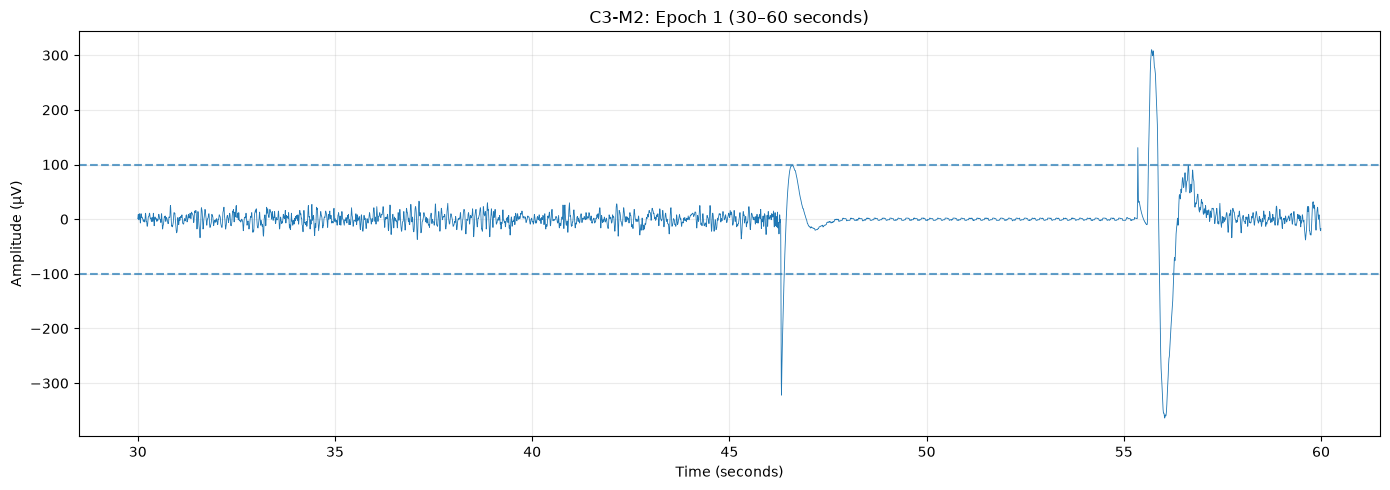

In [60]:
# Epoch 1: seconds 30–60
epoch_index = 1
start = epoch_index * 30
end = start + 30

segment = eeg_epochs[epoch_index]
segment_time = start + np.arange(len(segment)) / sfreq

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(segment_time, segment, linewidth=0.6)
ax.axhline(100, linestyle="--", alpha=0.7)
ax.axhline(-100, linestyle="--", alpha=0.7)

ax.set_title(f"{channel_name}: Epoch {epoch_index} ({start}–{end} seconds)")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude (µV)")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

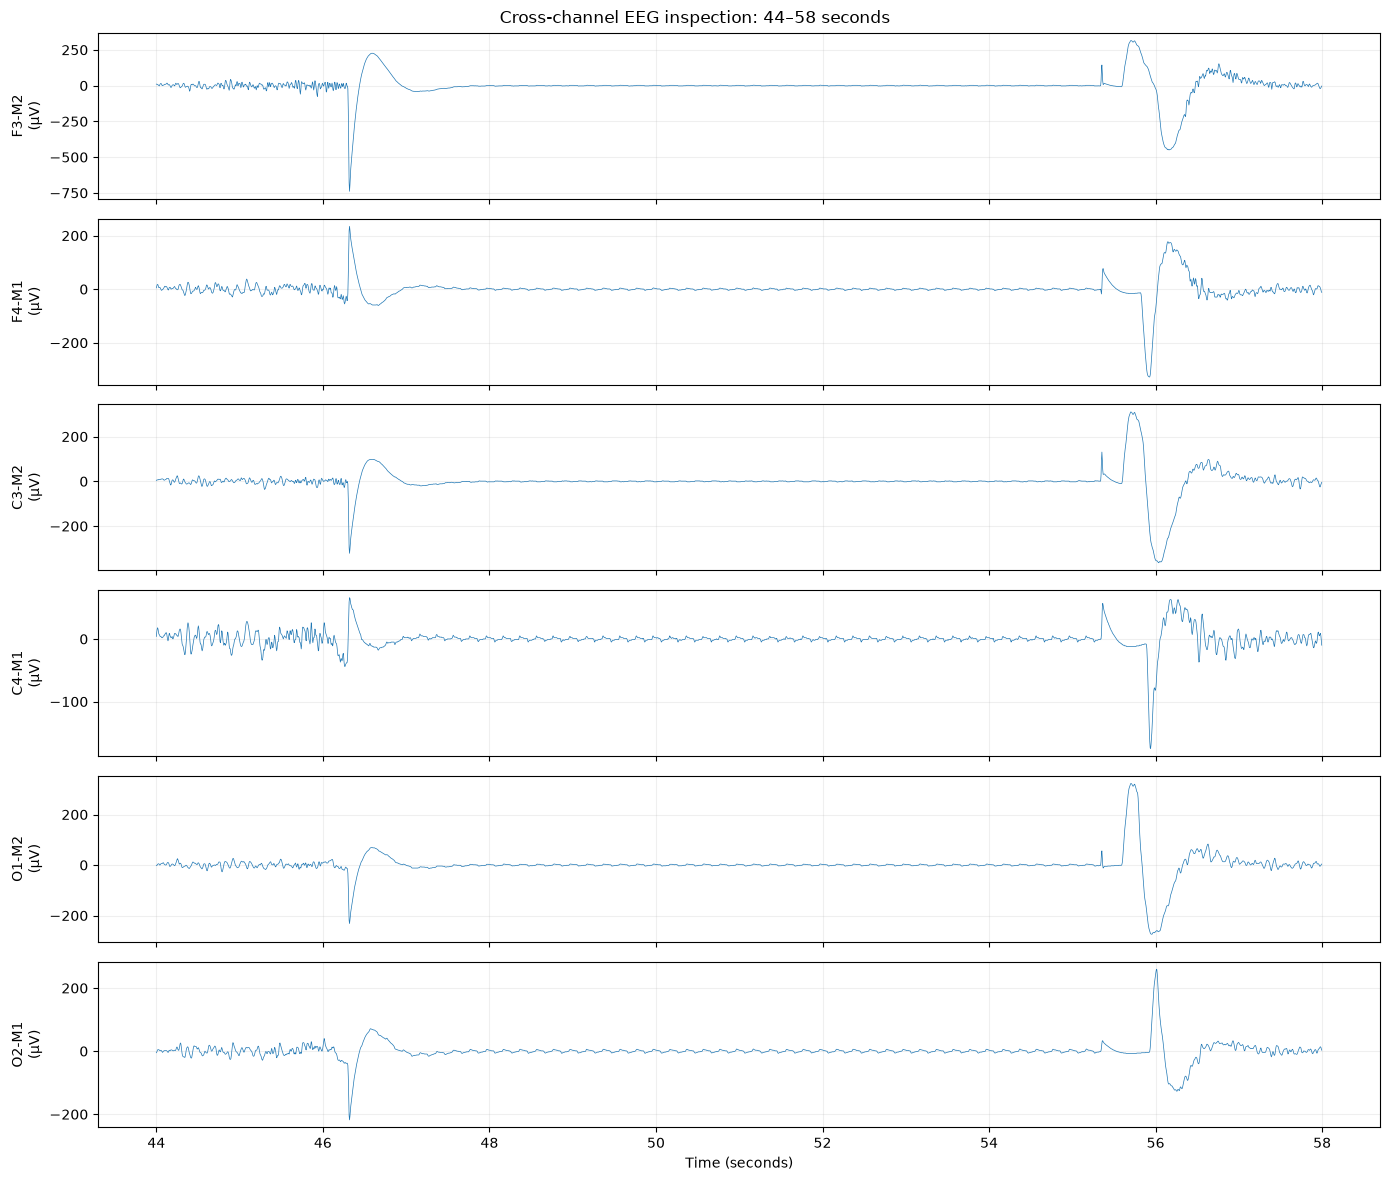

In [61]:
# Inspect all six EEG channels during seconds 44–58
eeg_channels = ["F3-M2", "F4-M1", "C3-M2", "C4-M1", "O1-M2", "O2-M1"]

start_sec = 44
end_sec = 58

start_sample = int(start_sec * sfreq)
end_sample = int(end_sec * sfreq)

fig, axes = plt.subplots(
    len(eeg_channels), 1,
    figsize=(14, 12),
    sharex=True
)

for ax, channel in zip(axes, eeg_channels):
    signal = raw.get_data(
        picks=[channel],
        start=start_sample,
        stop=end_sample,
        units="uV"
    )[0]

    time = start_sec + np.arange(len(signal)) / sfreq

    ax.plot(time, signal, linewidth=0.5)
    ax.set_ylabel(f"{channel}\n(µV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("Cross-channel EEG inspection: 44–58 seconds")
plt.tight_layout()
plt.show()

In [62]:
eeg_channels = ["F3-M2", "F4-M1", "C3-M2", "C4-M1", "O1-M2", "O2-M1"]

start_sec = 44
end_sec = 58

start_sample = int(start_sec * sfreq)
end_sample = int(end_sec * sfreq)

quality_results = []

for channel in eeg_channels:
    signal = raw.get_data(
        picks=[channel],
        start=start_sample,
        stop=end_sample,
        units="uV"
    )[0]

    quality_results.append({
        "channel": channel,
        "std_uv": np.std(signal),
        "peak_to_peak_uv": np.ptp(signal),
        "samples_over_100uv_pct": (
            np.mean(np.abs(signal) > 100) * 100
        ),
        "samples_over_200uv_pct": (
            np.mean(np.abs(signal) > 200) * 100
        )
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df.round(3))

,channel,std_uv,peak_to_peak_uv,samples_over_100uv_pct,samples_over_200uv_pct
0,F3-M2,84.376,1054.040,8.893,5.071
1,F4-M1,37.793,563.088,3.286,0.821
2,C3-M2,61.554,673.838,4.893,3.536
3,C4-M1,15.799,240.897,0.429,0.000
4,O1-M2,50.499,596.995,4.250,2.607
5,O2-M1,28.370,477.994,2.429,0.429


In [63]:
intervals = {
    "quiet_10_24s": (10, 24),
    "suspicious_44_58s": (44, 58)
}

comparison_results = []

for interval_name, (start_sec, end_sec) in intervals.items():
    start_sample = int(start_sec * sfreq)
    end_sample = int(end_sec * sfreq)

    for channel in eeg_channels:
        signal = raw.get_data(
            picks=[channel],
            start=start_sample,
            stop=end_sample,
            units="uV"
        )[0]

        comparison_results.append({
            "interval": interval_name,
            "channel": channel,
            "std_uv": np.std(signal),
            "peak_to_peak_uv": np.ptp(signal),
            "samples_over_100uv_pct": (
                np.mean(np.abs(signal) > 100) * 100
            )
        })

comparison_quality_df = pd.DataFrame(comparison_results)

display(
    comparison_quality_df
    .pivot(index="channel", columns="interval",
           values=["std_uv", "peak_to_peak_uv",
                   "samples_over_100uv_pct"])
    .round(3)
)

std_uv                   peak_to_peak_uv                    \
interval quiet_10_24s suspicious_44_58s    quiet_10_24s suspicious_44_58s   
channel                                                                     
C3-M2           9.654            61.554          79.901           673.838   
C4-M1          10.981            15.799         103.959           240.897   
F3-M2          10.177            84.376          85.949          1054.040   
F4-M1          10.592            37.793          96.047           563.088   
O1-M2           8.356            50.499          63.954           596.995   
O2-M1           9.655            28.370          80.033           477.994   

         samples_over_100uv_pct                    
interval           quiet_10_24s suspicious_44_58s  
channel                                            
C3-M2                       0.0             4.893  
C4-M1                       0.0             0.429  
F3-M2                       0.0             8.893  
F4-M1                       0.0             3.286  
O1-M2                       0.0             4.250  
O2-M1                       0.0             2.429

In [64]:
from scipy.signal import welch

# Frequency bands in Hz
frequency_bands = {
    "delta_power": (0.5, 4),
    "theta_power": (4, 8),
    "alpha_power": (8, 12),
    "sigma_power": (12, 16)
}

amplitude_threshold_uv = 100
band_results = []

for i, segment in enumerate(eeg_epochs):
    flagged = np.any(np.abs(segment) > amplitude_threshold_uv)

    # Preserve all epochs, but don't calculate band features
    # for epochs flagged by this provisional rule.
    if flagged:
        band_results.append({
            "epoch": i,
            "start_seconds": i * 30,
            "quality_flag": True,
            **{band: np.nan for band in frequency_bands}
        })
        continue

    frequencies, psd = welch(
        segment,
        fs=sfreq,
        nperseg=min(1024, len(segment))
    )

    row = {
        "epoch": i,
        "start_seconds": i * 30,
        "quality_flag": False
    }

    for band, (low, high) in frequency_bands.items():
        mask = (frequencies >= low) & (frequencies < high)

        # Integrate PSD over the selected frequency band
        row[band] = np.trapezoid(psd[mask], frequencies[mask])

    band_results.append(row)

band_features = pd.DataFrame(band_results)

print("Total epochs:", len(band_features))
print("Flagged epochs:", int(band_features["quality_flag"].sum()))
print("Unflagged epochs:", int((~band_features["quality_flag"]).sum()))

print("\nExample frequency-band features:")
display(band_features.head(15).round(3))

Total epochs: 946
Flagged epochs: 40
Unflagged epochs: 906

Example frequency-band features:


,epoch,start_seconds,quality_flag,delta_power,theta_power,alpha_power,sigma_power
0,0,0,False,16.994,14.539,26.804,10.268
1,1,30,True,NaN,NaN,NaN,NaN
2,2,60,True,NaN,NaN,NaN,NaN
3,3,90,False,19.578,33.942,119.480,14.340
4,4,120,False,25.691,46.208,89.765,9.287
5,5,150,True,NaN,NaN,NaN,NaN
6,6,180,False,33.681,23.518,51.996,22.008
7,7,210,False,7.635,10.190,67.668,10.752
8,8,240,False,11.770,18.979,113.931,14.977
9,9,270,False,22.582,19.167,53.112,17.070


In [65]:
# Merge by epoch index, not by row order assumptions
epoch_analysis = band_features.merge(
    stage_df[["epoch", "stage_code", "stage_name"]],
    on="epoch",
    how="left",
    validate="one_to_one"
)

epoch_analysis["stage_available"] = (
    epoch_analysis["stage_code"].isin([1, 2, 3, 4, 5])
)

print("Total epochs:", len(epoch_analysis))
print("Missing stage labels:", epoch_analysis["stage_name"].isna().sum())
print("\nStage availability:")
print(epoch_analysis["stage_available"].value_counts())

print("\nQuality flags by sleep stage:")
display(
    epoch_analysis.groupby("stage_name", dropna=False)
    .agg(
        epochs=("epoch", "count"),
        flagged_epochs=("quality_flag", "sum"),
        usable_epochs=("delta_power", "count")
    )
    .sort_values("epochs", ascending=False)
)

print("\nFirst 15 aligned rows:")
display(
    epoch_analysis[
        ["epoch", "start_seconds", "stage_name",
         "quality_flag", "delta_power", "theta_power",
         "alpha_power", "sigma_power"]
    ].head(15).round(3)
)

Total epochs: 946
Missing stage labels: 0

Stage availability:
stage_available
True     928
False     18
Name: count, dtype: int64

Quality flags by sleep stage:


,epochs,flagged_epochs,usable_epochs
stage_name,,,
N2 sleep,421,12,409
Wake,242,16,226
REM sleep,101,4,97
N1 sleep,94,5,89
N3 sleep,70,0,70
Unavailable,18,3,15



First 15 aligned rows:


,epoch,start_seconds,stage_name,quality_flag,delta_power,theta_power,alpha_power,sigma_power
0,0,0,Unavailable,False,16.994,14.539,26.804,10.268
1,1,30,Unavailable,True,NaN,NaN,NaN,NaN
2,2,60,Unavailable,True,NaN,NaN,NaN,NaN
3,3,90,Unavailable,False,19.578,33.942,119.480,14.340
4,4,120,Unavailable,False,25.691,46.208,89.765,9.287
5,5,150,Unavailable,True,NaN,NaN,NaN,NaN
6,6,180,Unavailable,False,33.681,23.518,51.996,22.008
7,7,210,Unavailable,False,7.635,10.190,67.668,10.752
8,8,240,Unavailable,False,11.770,18.979,113.931,14.977
9,9,270,Unavailable,False,22.582,19.167,53.112,17.070


In [66]:
# Keep valid sleep-stage labels and unflagged epochs
stage_features = epoch_analysis[
    epoch_analysis["stage_code"].isin([1, 2, 3, 4, 5])
    & (~epoch_analysis["quality_flag"])
].copy()

power_columns = [
    "delta_power",
    "theta_power",
    "alpha_power",
    "sigma_power"
]

stage_power_summary = (
    stage_features
    .groupby("stage_name")[power_columns]
    .median()
    .round(3)
)

stage_counts = (
    stage_features
    .groupby("stage_name")
    .size()
    .rename("usable_epochs")
)

stage_power_summary = stage_counts.to_frame().join(
    stage_power_summary
)

print("Usable, scored epochs:", len(stage_features))
print("\nMedian band power by sleep stage:")
display(stage_power_summary)

Usable, scored epochs: 891

Median band power by sleep stage:


,usable_epochs,delta_power,theta_power,alpha_power,sigma_power
stage_name,,,,,
N1 sleep,89,31.152,19.707,29.349,6.843
N2 sleep,409,93.373,29.174,35.440,6.861
N3 sleep,70,211.809,37.110,36.869,4.848
REM sleep,97,32.694,15.464,17.559,4.809
Wake,226,10.754,14.199,67.619,8.433


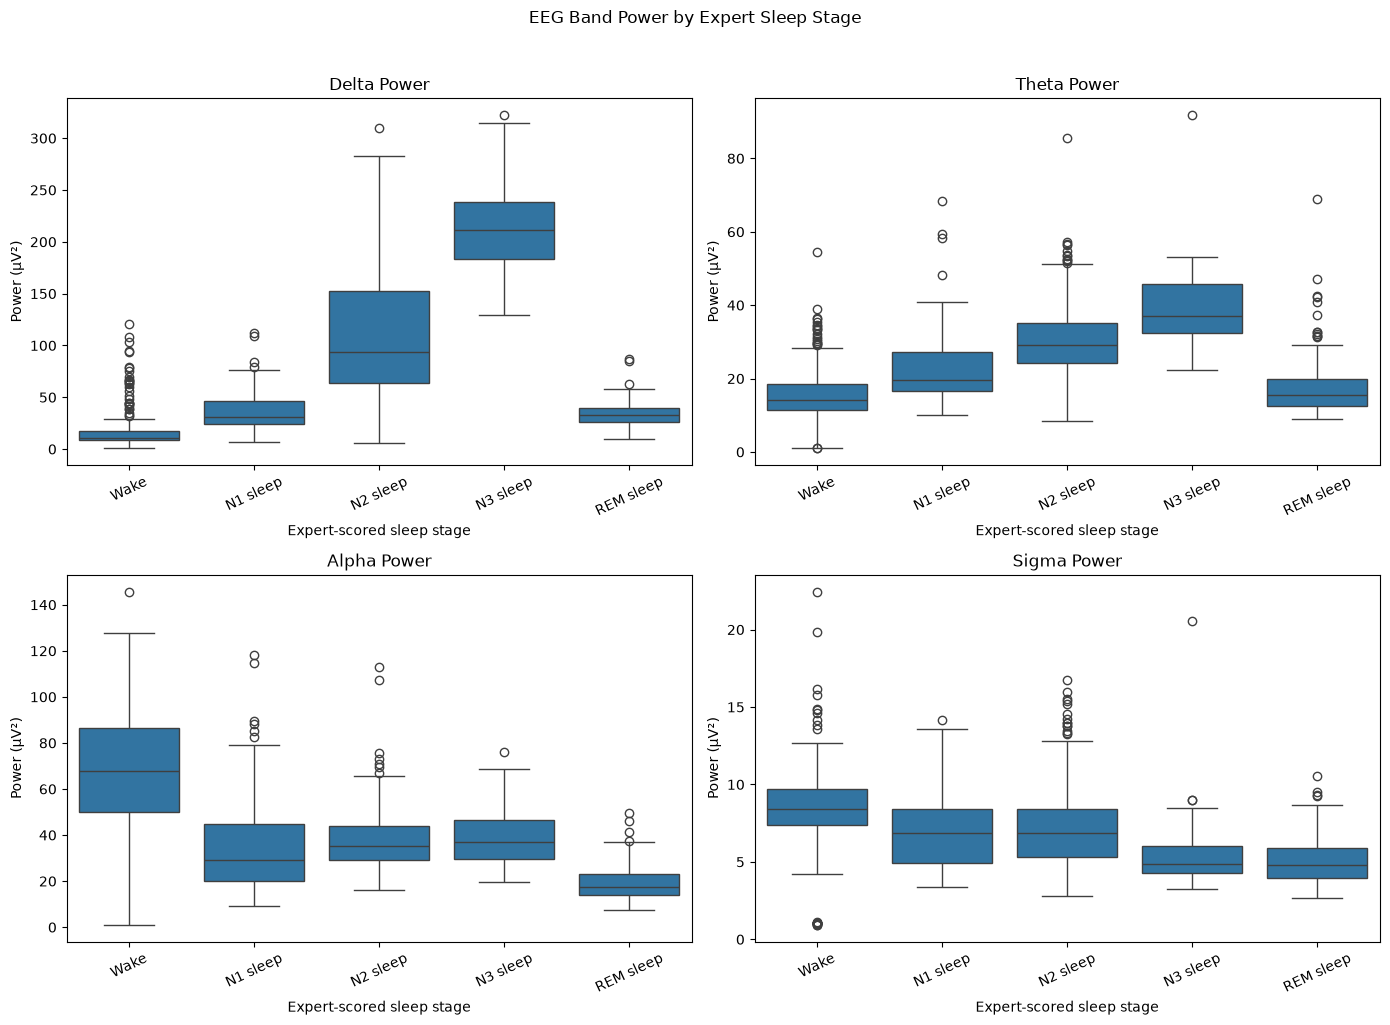

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

power_columns = [
    "delta_power",
    "theta_power",
    "alpha_power",
    "sigma_power"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, band in zip(axes.flat, power_columns):
    sns.boxplot(
        data=stage_features,
        x="stage_name",
        y=band,
        order=["Wake", "N1 sleep", "N2 sleep", "N3 sleep", "REM sleep"],
        ax=ax
    )
    ax.set_title(f"{band.replace('_', ' ').title()}")
    ax.set_xlabel("Expert-scored sleep stage")
    ax.set_ylabel("Power (µV²)")
    ax.tick_params(axis="x", rotation=25)

plt.suptitle("EEG Band Power by Expert Sleep Stage", y=1.02)
plt.tight_layout()
plt.show()

In [68]:
print("matched_df exists:", "matched_df" in globals())
print("df exists:", "df" in globals())
print("inventory exists:", "inventory_df" in globals())
print("stage_df exists:", "stage_df" in globals())
print("EDF_PATH exists:", "EDF_PATH" in globals())

matched_df exists: False
df exists: True
inventory exists: False
stage_df exists: True
EDF_PATH exists: True


In [69]:
import json
from pathlib import Path
import pandas as pd
from kaggle.api.kaggle_api_extended import KaggleApi

PROJECT_DIR = Path(r"D:\Downloads\BEST AI PROJECTS\BDS")
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
INVENTORY_PATH = DATA_DIR / "kaggle_inventory.json"

api = KaggleApi()
api.authenticate()

all_files = []
page_token = None

while True:
    res = api.dataset_list_files(
        "physionet/physionetchallenge2026data",
        page_size=200,
        page_token=page_token
    )
    for f in res.dataset_files:
        all_files.append({
            "name": f.name,
            "size": f.total_bytes,
            "creationDate": f.creation_date.isoformat() if f.creation_date else None
        })

    page_token = res.next_page_token
    if not page_token:
        break

INVENTORY_PATH.write_text(
    json.dumps(all_files, indent=2),
    encoding="utf-8"
)

inventory_df = pd.DataFrame(all_files)
print("Inventory entries:", len(inventory_df))
print("Columns:", inventory_df.columns.tolist())
print("Saved to:", INVENTORY_PATH)
display(inventory_df.head())



Inventory entries: 3292
Columns: ['name', 'size', 'creationDate']
Saved to: D:\Downloads\BEST AI PROJECTS\BDS\data\kaggle_inventory.json


,name,size,creationDate
0,ICD_codes_CI.csv,88731,2026-06-03T17:07:43.485000
1,algorithmic_annotations/I0002/sub-I00021500000...,507864,2026-06-03T17:07:47.165000
2,algorithmic_annotations/I0002/sub-I00021500005...,413400,2026-06-03T17:07:47.147000
3,algorithmic_annotations/I0002/sub-I00021500006...,429636,2026-06-03T17:07:47.174000
4,algorithmic_annotations/I0002/sub-I00021500038...,493104,2026-06-03T17:07:47.169000


In [70]:

# Cell 113A: Inspect the actual Kaggle CLI response

import subprocess
import sys

cmd = [
    sys.executable, "-m", "kaggle",
    "datasets", "files",
    "physionet/physionetchallenge2026data",
    "--page-size", "5"
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace",
    timeout=120
)

print("Return code:", result.returncode)
print("\n===== STDOUT (first 3000 characters) =====")
print(repr(result.stdout[:3000]))

print("\n===== STDERR (first 3000 characters) =====")
print(repr(result.stderr[:3000]))


Return code: 0

===== STDOUT (first 3000 characters) =====
"Warning: Looks like you're using an outdated `kaggle` version (installed: 2.2.4), please consider upgrading to the latest version (2.2.5)\nNext Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7gKbYwItxW3CuktOpRA1IUPNkLLOLWDoW4ZlHV_2O2lLed__y8lJoFMhxQiFKI5nxEO6VuZNkhbsPH4ZPLUEnI7BEhLPCSOJvYfMgODWYCBUu18VjBLBOZ-EXq52vpJwPyTloc-ep1HvfQyE5MWS8aYiZyK5SdAkw7mB7uOSy5v9b4jPkwGZtq_AM24Cgg7AV7cP3m3\nname                                                                            size  creationDate                \n----------------------------------------------------------------------------  ------  --------------------------  \nICD_codes_CI.csv                                                               88731  2026-06-03 17:07:43.485000  \nalgorithmic_annotations/I0002/sub-I0002150000076_ses-1_caisr_annotations.edf  507864  2026-06-03 17:07:47.165000  \nalgorithmic_annotations/I0002/sub-I0002150000540_ses-2_caisr_annotations.edf  413400  2026-06

In [71]:
# Get all file paths from the inventory
available_files = set(inventory_df["name"])

matched_records = []

for _, row in df.iterrows():
    site = row["SiteID"]
    bids = row["BidsFolder"]
    session = row["SessionID"]

    stem = f"{bids}_ses-{session}"

    phys_path = f"physiological_data/{site}/{stem}.edf"
    human_path = (
        f"human_annotations/{site}/{stem}_expert_annotations.edf"
    )
    algo_path = (
        f"algorithmic_annotations/{site}/{stem}_caisr_annotations.edf"
    )

    matched_records.append({
        **row.to_dict(),
        "phys_path": phys_path,
        "human_path": human_path,
        "algo_path": algo_path,
        "has_physiological": phys_path in available_files,
        "has_human_annotation": human_path in available_files,
        "has_algorithmic_annotation": algo_path in available_files
    })

matched_df = pd.DataFrame(matched_records)

complete_mask = (
    matched_df["has_physiological"]
    & matched_df["has_human_annotation"]
    & matched_df["has_algorithmic_annotation"]
)

print("Total patients:", len(matched_df))
print("Complete records:", int(complete_mask.sum()))
print("\nComplete records by target:")
print(
    matched_df.loc[complete_mask, "Cognitive_Impairment"]
    .value_counts(dropna=False)
)

display(matched_df.loc[complete_mask].head())

Total patients: 1103
Complete records: 1085

Complete records by target:
Cognitive_Impairment
False    1001
True       84
Name: count, dtype: int64


,SiteID,BDSPPatientID,CreationTime,BidsFolder,SessionID,Age,Sex,Race,Ethnicity,BMI,Time_to_Event,Cognitive_Impairment,Last_Known_Visit_Date,Time_to_Last_Visit,phys_path,human_path,algo_path,has_physiological,has_human_annotation,has_algorithmic_annotation
0,S0001,120173185,2008-12-04 21:50:00,sub-S0001120173185,1,51,Male,White,Not Hispanic,NaN,NaN,False,2022-10-13 00:00:00,5060,physiological_data/S0001/sub-S0001120173185_se...,human_annotations/S0001/sub-S0001120173185_ses...,algorithmic_annotations/S0001/sub-S00011201731...,True,True,True
1,S0001,112722303,2016-05-14 22:30:01,sub-S0001112722303,1,73,Female,White,Not Hispanic,24.55,NaN,False,2024-01-03 00:00:00,2789,physiological_data/S0001/sub-S0001112722303_se...,human_annotations/S0001/sub-S0001112722303_ses...,algorithmic_annotations/S0001/sub-S00011127223...,True,True,True
2,S0001,116945514,2009-08-13 01:37:44,sub-S0001116945514,1,55,Male,White,Not Hispanic,NaN,NaN,False,2022-11-10 00:00:00,4836,physiological_data/S0001/sub-S0001116945514_se...,human_annotations/S0001/sub-S0001116945514_ses...,algorithmic_annotations/S0001/sub-S00011169455...,True,True,True
3,S0001,113953169,2010-07-27 22:25:00,sub-S0001113953169,1,57,Male,White,Not Hispanic,NaN,NaN,False,2024-06-08 00:00:00,5064,physiological_data/S0001/sub-S0001113953169_se...,human_annotations/S0001/sub-S0001113953169_ses...,algorithmic_annotations/S0001/sub-S00011139531...,True,True,True
4,S0001,111625329,2014-02-28 21:37:52,sub-S0001111625329,1,57,Female,Others,Hispanic,NaN,NaN,False,2024-08-12 00:00:00,3817,physiological_data/S0001/sub-S0001111625329_se...,human_annotations/S0001/sub-S0001111625329_ses...,algorithmic_annotations/S0001/sub-S00011116253...,True,True,True


In [72]:
positive_candidates = matched_df[
    complete_mask
    & matched_df["Cognitive_Impairment"].eq(True)
    & matched_df["BidsFolder"].ne("sub-S0001118606205")
].copy()

print("Other complete positive patients:", len(positive_candidates))

if len(positive_candidates):
    second_patient = positive_candidates.iloc[0]

    print("\nSelected patient:")
    display(
        second_patient[
            [
                "SiteID", "BidsFolder", "SessionID",
                "Cognitive_Impairment",
                "phys_path", "human_path", "algo_path"
            ]
        ].to_frame("value")
    )
else:
    print("No second complete positive patient found.")

Other complete positive patients: 83

Selected patient:


,value
SiteID,S0001
BidsFolder,sub-S0001121888695
SessionID,1
Cognitive_Impairment,True
phys_path,physiological_data/S0001/sub-S0001121888695_se...
human_path,human_annotations/S0001/sub-S0001121888695_ses...
algo_path,algorithmic_annotations/S0001/sub-S00011218886...


In [73]:
import subprocess
import sys
from pathlib import Path

SAMPLE_DIR = DATA_DIR / "sample_edf"
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

files_to_download = [
    second_patient["phys_path"],
    second_patient["human_path"]
]

for remote_path in files_to_download:
    filename = remote_path.split("/")[-1]
    local_path = SAMPLE_DIR / filename

    if local_path.exists() and local_path.stat().st_size > 0:
        print(f"Already downloaded: {filename}")
        continue

    print(f"\nDownloading: {filename}")

    result = subprocess.run(
        [
            sys.executable, "-m", "kaggle", "datasets", "download",
            "-d", "physionet/physionetchallenge2026data",
            "-f", remote_path,
            "-p", str(SAMPLE_DIR)
        ],
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
        timeout=1800
    )

    print(result.stdout[-1000:])

    if result.returncode != 0:
        print(result.stderr[-2000:])
        raise RuntimeError(f"Download failed: {remote_path}")

    # Kaggle may save the individual EDF as a ZIP archive.
    zip_path = SAMPLE_DIR / f"{filename}.zip"

    if zip_path.exists():
        import zipfile
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(SAMPLE_DIR)
        zip_path.unlink()

    if not local_path.exists():
        raise FileNotFoundError(f"Expected file not found: {local_path}")

    print(f"Verified: {local_path}")
    print(f"Size: {local_path.stat().st_size / (1024**2):.2f} MB")

Already downloaded: sub-S0001121888695_ses-1.edf
Already downloaded: sub-S0001121888695_ses-1_expert_annotations.edf


In [74]:
import mne

second_edf_path = SAMPLE_DIR / (
    f"{second_patient['BidsFolder']}_ses-{second_patient['SessionID']}.edf"
)

second_annotation_path = SAMPLE_DIR / (
    f"{second_patient['BidsFolder']}_ses-{second_patient['SessionID']}"
    "_expert_annotations.edf"
)

second_raw = mne.io.read_raw_edf(
    str(second_edf_path),
    preload=False,
    verbose="ERROR"
)

second_annotations = mne.io.read_raw_edf(
    str(second_annotation_path),
    preload=False,
    verbose="ERROR"
)

print("Patient:", second_patient["BidsFolder"])
print("Target:", second_patient["Cognitive_Impairment"])
print("EEG duration (hours):", round(second_raw.times[-1] / 3600, 2))
print("EEG channels:", second_raw.ch_names)
print("Annotation channels:", second_annotations.ch_names)
print("Annotation sampling frequency:", second_annotations.info["sfreq"])

Patient: sub-S0001121888695
Target: True
EEG duration (hours): 7.98
EEG channels: ['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'E1-M2', 'E2-M2', 'CHIN1-CHIN2', 'LAT', 'RAT', 'SaO2', 'AIRFLOW', 'CFLOW', 'CHEST', 'ABD', 'EKG', 'CPRES']
Annotation channels: ['arousal_expert', 'limb_expert', 'resp_expert', 'stage_expert']
Annotation sampling frequency: 2.0


In [75]:
import pyedflib
import numpy as np
import pandas as pd

reader = pyedflib.EdfReader(str(second_annotation_path))

try:
    labels = reader.getSignalLabels()
    stage_index = labels.index("stage_expert")

    second_stage_codes = reader.readSignal(
        stage_index,
        digital=True
    ).astype(int)

finally:
    reader.close()

second_stage_df = pd.DataFrame({
    "epoch": np.arange(len(second_stage_codes)),
    "start_seconds": np.arange(len(second_stage_codes)) * 30,
    "stage_code": second_stage_codes
})

stage_names = {
    1: "N3 sleep",
    2: "N2 sleep",
    3: "N1 sleep",
    4: "REM sleep",
    5: "Wake",
    9: "Unavailable"
}

second_stage_df["stage_name"] = (
    second_stage_df["stage_code"].map(stage_names)
)

print("Total annotated epochs:", len(second_stage_df))
print("\nStage distribution:")
display(
    second_stage_df["stage_name"]
    .value_counts()
    .rename_axis("stage_name")
    .to_frame("epochs")
)

Total annotated epochs: 958

Stage distribution:


,epochs
stage_name,
N1 sleep,331
N2 sleep,270
Wake,187
REM sleep,120
N3 sleep,28
Unavailable,22


In [76]:
eeg_duration = second_raw.n_times / second_raw.info["sfreq"]
annotation_duration = len(second_stage_codes) * 30

print("EEG duration (seconds):", round(eeg_duration, 2))
print("Annotation duration (seconds):", annotation_duration)
print("EEG duration (hours):", round(eeg_duration / 3600, 2))
print("Annotation epochs:", len(second_stage_codes))
print("Complete EEG 30-second epochs:",
      int(second_raw.n_times // (30 * second_raw.info["sfreq"])))
print("Duration difference (seconds):",
      round(eeg_duration - annotation_duration, 2))

EEG duration (seconds): 28745.0
Annotation duration (seconds): 28740
EEG duration (hours): 7.98
Annotation epochs: 958
Complete EEG 30-second epochs: 958
Duration difference (seconds): 5.0


In [77]:
from scipy.signal import welch
import numpy as np
import pandas as pd

channel_name = "C3-M2"
sfreq2 = second_raw.info["sfreq"]

# Extract EEG in microvolts
eeg2 = second_raw.get_data(
    picks=[channel_name],
    units="uV"
)[0]

epoch_seconds = 30
samples_per_epoch2 = int(sfreq2 * epoch_seconds)

# Use exactly the number of epochs with expert annotations
n_epochs2 = len(second_stage_codes)

eeg2 = eeg2[:n_epochs2 * samples_per_epoch2]
eeg2_epochs = eeg2.reshape(n_epochs2, samples_per_epoch2)

frequency_bands = {
    "delta_power": (0.5, 4),
    "theta_power": (4, 8),
    "alpha_power": (8, 12),
    "sigma_power": (12, 16)
}

threshold_uv = 100
results2 = []

for i, segment in enumerate(eeg2_epochs):
    flagged = np.any(np.abs(segment) > threshold_uv)

    row = {
        "epoch": i,
        "start_seconds": i * epoch_seconds,
        "quality_flag": flagged
    }

    if not flagged:
        frequencies, psd = welch(
            segment,
            fs=sfreq2,
            nperseg=1024
        )

        for band, (low, high) in frequency_bands.items():
            mask = (frequencies >= low) & (frequencies < high)
            row[band] = np.trapezoid(
                psd[mask], frequencies[mask]
            )
    else:
        for band in frequency_bands:
            row[band] = np.nan

    results2.append(row)

band_features2 = pd.DataFrame(results2)

print("Patient:", second_patient["BidsFolder"])
print("Total epochs:", len(band_features2))
print("Flagged epochs:", int(band_features2["quality_flag"].sum()))
print("Unflagged epochs:", int((~band_features2["quality_flag"]).sum()))

display(band_features2.head(10).round(3))

Patient: sub-S0001121888695
Total epochs: 958
Flagged epochs: 130
Unflagged epochs: 828


,epoch,start_seconds,quality_flag,delta_power,theta_power,alpha_power,sigma_power
0,0,0,True,NaN,NaN,NaN,NaN
1,1,30,True,NaN,NaN,NaN,NaN
2,2,60,True,NaN,NaN,NaN,NaN
3,3,90,True,NaN,NaN,NaN,NaN
4,4,120,False,87.798,8.382,28.501,8.693
5,5,150,False,19.215,10.645,22.194,8.352
6,6,180,False,14.080,8.536,32.520,8.794
7,7,210,True,NaN,NaN,NaN,NaN
8,8,240,False,33.693,6.604,9.651,8.063
9,9,270,True,NaN,NaN,NaN,NaN


In [78]:
# Build a stage-distribution table for both patients
first_stage_counts = (
    stage_df["stage_name"]
    .value_counts()
    .rename("patient_1_epochs")
)

second_stage_counts = (
    second_stage_df["stage_name"]
    .value_counts()
    .rename("patient_2_epochs")
)

stage_comparison = pd.concat(
    [first_stage_counts, second_stage_counts],
    axis=1
).fillna(0).astype(int)

stage_comparison["patient_1_pct"] = (
    stage_comparison["patient_1_epochs"]
    / len(stage_df) * 100
).round(2)

stage_comparison["patient_2_pct"] = (
    stage_comparison["patient_2_epochs"]
    / len(second_stage_df) * 100
).round(2)

display(stage_comparison)

,patient_1_epochs,patient_2_epochs,patient_1_pct,patient_2_pct
stage_name,,,,
N2 sleep,421,270,44.50,28.18
Wake,242,187,25.58,19.52
REM sleep,101,120,10.68,12.53
N1 sleep,94,331,9.94,34.55
N3 sleep,70,28,7.40,2.92
Unavailable,18,22,1.90,2.30


In [79]:
import numpy as np
import pandas as pd
import mne
from scipy.signal import welch

def extract_eeg_features(edf_path, channel="C3-M2",
                         epoch_seconds=30, threshold_uv=100):
    raw_local = mne.io.read_raw_edf(
        str(edf_path), preload=False, verbose="ERROR"
    )

    if channel not in raw_local.ch_names:
        raise ValueError(f"Channel {channel} not found in {edf_path}")

    fs = raw_local.info["sfreq"]
    samples_per_epoch = int(fs * epoch_seconds)

    signal = raw_local.get_data(
        picks=[channel], units="uV"
    )[0]

    n_epochs = len(signal) // samples_per_epoch
    signal = signal[:n_epochs * samples_per_epoch]
    epochs = signal.reshape(n_epochs, samples_per_epoch)

    bands = {
        "delta_power": (0.5, 4),
        "theta_power": (4, 8),
        "alpha_power": (8, 12),
        "sigma_power": (12, 16)
    }

    rows = []

    for i, segment in enumerate(epochs):
        flagged = bool(np.any(np.abs(segment) > threshold_uv))

        row = {
            "epoch": i,
            "start_seconds": i * epoch_seconds,
            "quality_flag": flagged
        }

        if not flagged:
            frequencies, psd = welch(
                segment, fs=fs,
                nperseg=min(1024, len(segment))
            )

            for band, (low, high) in bands.items():
                mask = (frequencies >= low) & (frequencies < high)
                row[band] = np.trapezoid(
                    psd[mask], frequencies[mask]
                )
        else:
            for band in bands:
                row[band] = np.nan

        rows.append(row)

    return pd.DataFrame(rows)

In [80]:
# Patient 1
features_patient1 = extract_eeg_features(EDF_PATH)

# Patient 2
features_patient2 = extract_eeg_features(second_edf_path)

print("PATIENT 1")
print("Total epochs:", len(features_patient1))
print("Flagged epochs:", features_patient1["quality_flag"].sum())

print("\nPATIENT 2")
print("Total epochs:", len(features_patient2))
print("Flagged epochs:", features_patient2["quality_flag"].sum())

print("\nPatient 1 sample:")
display(features_patient1.head())

print("\nPatient 2 sample:")
display(features_patient2.head())

PATIENT 1
Total epochs: 946
Flagged epochs: 40

PATIENT 2
Total epochs: 958
Flagged epochs: 130

Patient 1 sample:


,epoch,start_seconds,quality_flag,delta_power,theta_power,alpha_power,sigma_power
0,0,0,False,16.993771,14.538605,26.804186,10.267608
1,1,30,True,NaN,NaN,NaN,NaN
2,2,60,True,NaN,NaN,NaN,NaN
3,3,90,False,19.578335,33.942129,119.480487,14.339521
4,4,120,False,25.691130,46.208158,89.764871,9.287065



Patient 2 sample:


,epoch,start_seconds,quality_flag,delta_power,theta_power,alpha_power,sigma_power
0,0,0,True,NaN,NaN,NaN,NaN
1,1,30,True,NaN,NaN,NaN,NaN
2,2,60,True,NaN,NaN,NaN,NaN
3,3,90,True,NaN,NaN,NaN,NaN
4,4,120,False,87.797599,8.382424,28.500942,8.693096


In [81]:
negative_candidates = matched_df[
    matched_df["Cognitive_Impairment"].eq(False)
    & matched_df["has_physiological"]
    & matched_df["has_human_annotation"]
    & matched_df["has_algorithmic_annotation"]
].copy()

print("Complete negative-label patients:", len(negative_candidates))

# Select a different patient from our two positive examples
negative_patient = negative_candidates.iloc[0]

print("\nSelected negative-label patient:")
display(
    negative_patient[
        [
            "SiteID",
            "BidsFolder",
            "SessionID",
            "Cognitive_Impairment",
            "phys_path",
            "human_path",
            "algo_path"
        ]
    ].to_frame("value")
)

Complete negative-label patients: 1001

Selected negative-label patient:


,value
SiteID,S0001
BidsFolder,sub-S0001120173185
SessionID,1
Cognitive_Impairment,False
phys_path,physiological_data/S0001/sub-S0001120173185_se...
human_path,human_annotations/S0001/sub-S0001120173185_ses...
algo_path,algorithmic_annotations/S0001/sub-S00011201731...


In [82]:
import subprocess
import sys
from pathlib import Path
import zipfile

SAMPLE_DIR = DATA_DIR / "sample_edf"
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

negative_edf_path = SAMPLE_DIR / (
    f"{negative_patient['BidsFolder']}_ses-{negative_patient['SessionID']}.edf"
)

negative_annotation_path = SAMPLE_DIR / (
    f"{negative_patient['BidsFolder']}_ses-{negative_patient['SessionID']}"
    "_expert_annotations.edf"
)

for remote_path in [
    negative_patient["phys_path"],
    negative_patient["human_path"]
]:
    filename = remote_path.split("/")[-1]
    local_path = SAMPLE_DIR / filename

    if local_path.exists() and local_path.stat().st_size > 0:
        print(f"Already downloaded: {filename}")
        continue

    print(f"\nDownloading: {filename}")

    result = subprocess.run(
        [
            sys.executable, "-m", "kaggle", "datasets", "download",
            "-d", "physionet/physionetchallenge2026data",
            "-f", remote_path,
            "-p", str(SAMPLE_DIR)
        ],
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
        timeout=1800
    )

    if result.returncode != 0:
        print(result.stderr[-2000:])
        raise RuntimeError(f"Download failed: {remote_path}")

    zip_path = SAMPLE_DIR / f"{filename}.zip"

    if zip_path.exists():
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(SAMPLE_DIR)
        zip_path.unlink()

    if not local_path.exists():
        raise FileNotFoundError(local_path)

    print(f"Verified: {local_path}")
    print(f"Size: {local_path.stat().st_size / (1024**2):.2f} MB")

Already downloaded: sub-S0001120173185_ses-1.edf
Already downloaded: sub-S0001120173185_ses-1_expert_annotations.edf


In [83]:
negative_features = extract_eeg_features(negative_edf_path)

print("Patient:", negative_patient["BidsFolder"])
print("Target:", negative_patient["Cognitive_Impairment"])
print("Total epochs:", len(negative_features))
print("Flagged epochs:", int(negative_features["quality_flag"].sum()))
print(
    "Flag rate (%):",
    round(negative_features["quality_flag"].mean() * 100, 2)
)

display(negative_features.head(10).round(3))

Patient: sub-S0001120173185
Target: False
Total epochs: 980
Flagged epochs: 53
Flag rate (%): 5.41


,epoch,start_seconds,quality_flag,delta_power,theta_power,alpha_power,sigma_power
0,0,0,False,34.537,4.964,7.695,5.838
1,1,30,True,NaN,NaN,NaN,NaN
2,2,60,True,NaN,NaN,NaN,NaN
3,3,90,False,14.809,6.004,7.054,5.986
4,4,120,False,28.167,6.891,11.920,6.182
5,5,150,False,8.679,5.220,5.818,4.657
6,6,180,False,15.285,5.985,7.554,5.833
7,7,210,False,32.343,7.043,6.362,5.676
8,8,240,False,22.812,5.642,6.495,5.488
9,9,270,False,18.559,6.030,7.994,10.221


In [84]:
def summarize_patient(features, patient_row):
    usable = features.loc[~features["quality_flag"]].copy()

    result = {
        "SiteID": patient_row["SiteID"],
        "BDSPPatientID": patient_row["BDSPPatientID"],
        "BidsFolder": patient_row["BidsFolder"],
        "SessionID": patient_row["SessionID"],
        "Cognitive_Impairment": int(
            bool(patient_row["Cognitive_Impairment"])
        ),
        "total_epochs": len(features),
        "flagged_epochs": int(features["quality_flag"].sum()),
        "flag_rate": float(features["quality_flag"].mean())
    }

    for band in [
        "delta_power", "theta_power", "alpha_power", "sigma_power"
    ]:
        result[f"{band}_median"] = usable[band].median()
        result[f"{band}_std"] = usable[band].std()

    return result


summary1 = summarize_patient(features_patient1, matched_df[
    matched_df["BidsFolder"] == "sub-S0001118606205"
].iloc[0])

summary2 = summarize_patient(features_patient2, second_patient)
summary3 = summarize_patient(negative_features, negative_patient)

patient_summary_df = pd.DataFrame([summary1, summary2, summary3])

display(patient_summary_df.round(4))

,SiteID,BDSPPatientID,BidsFolder,SessionID,Cognitive_Impairment,total_epochs,flagged_epochs,flag_rate,delta_power_median,delta_power_std,theta_power_median,theta_power_std,alpha_power_median,alpha_power_std,sigma_power_median,sigma_power_std
0,S0001,118606205,sub-S0001118606205,1,1,946,40,0.0423,53.6687,69.8152,24.2356,11.6936,37.0665,23.7326,6.9946,3.3273
1,S0001,121888695,sub-S0001121888695,1,1,958,130,0.1357,56.6731,62.4835,12.0939,4.7614,10.9430,5.7175,5.3784,2.1688
2,S0001,120173185,sub-S0001120173185,1,0,980,53,0.0541,37.0716,41.6598,11.6656,4.4583,8.1636,2.7326,5.3192,1.8300


In [85]:
bands = [
    "delta_power",
    "theta_power",
    "alpha_power",
    "sigma_power"
]

print("Negative patient feature rows:", len(negative_features))
print("Flagged epochs:", int(negative_features["quality_flag"].sum()))

print("\nNon-missing values in each band:")
print(negative_features[bands].notna().sum())

print("\nFeature summary before aggregation:")
display(negative_features[bands].describe().round(3))

print("\nUnflagged rows with features:")
display(
    negative_features.loc[
        ~negative_features["quality_flag"],
        ["epoch", "quality_flag"] + bands
    ].head(10).round(3)
)

Negative patient feature rows: 980
Flagged epochs: 53

Non-missing values in each band:
delta_power    927
theta_power    927
alpha_power    927
sigma_power    927
dtype: int64

Feature summary before aggregation:


,delta_power,theta_power,alpha_power,sigma_power
count,927.000,927.000,927.000,927.000
mean,50.280,12.203,8.393,5.525
std,41.660,4.458,2.733,1.830
min,0.927,1.066,0.963,0.909
25%,18.541,8.927,6.518,4.156
50%,37.072,11.666,8.164,5.319
75%,68.236,15.006,9.989,6.700
max,244.080,27.768,22.264,12.054



Unflagged rows with features:


,epoch,quality_flag,delta_power,theta_power,alpha_power,sigma_power
0,0,False,34.537,4.964,7.695,5.838
3,3,False,14.809,6.004,7.054,5.986
4,4,False,28.167,6.891,11.920,6.182
5,5,False,8.679,5.220,5.818,4.657
6,6,False,15.285,5.985,7.554,5.833
7,7,False,32.343,7.043,6.362,5.676
8,8,False,22.812,5.642,6.495,5.488
9,9,False,18.559,6.030,7.994,10.221
10,10,False,21.958,7.640,7.399,7.122
11,11,False,10.953,7.623,6.326,5.941


In [86]:
# Rebuild all three summaries
summary1 = summarize_patient(
    features_patient1,
    matched_df.loc[
        matched_df["BidsFolder"].eq("sub-S0001118606205")
    ].iloc[0]
)

summary2 = summarize_patient(
    features_patient2,
    second_patient
)

summary3 = summarize_patient(
    negative_features,
    negative_patient
)

patient_summary_df = pd.DataFrame([
    summary1, summary2, summary3
])

print("Patient summary shape:", patient_summary_df.shape)

display(
    patient_summary_df[
        [
            "BidsFolder",
            "Cognitive_Impairment",
            "total_epochs",
            "flagged_epochs",
            "flag_rate",
            "delta_power_median",
            "theta_power_median",
            "alpha_power_median",
            "sigma_power_median"
        ]
    ].round(4)
)

Patient summary shape: (3, 16)


,BidsFolder,Cognitive_Impairment,total_epochs,flagged_epochs,flag_rate,delta_power_median,theta_power_median,alpha_power_median,sigma_power_median
0,sub-S0001118606205,1,946,40,0.0423,53.6687,24.2356,37.0665,6.9946
1,sub-S0001121888695,1,958,130,0.1357,56.6731,12.0939,10.9430,5.3784
2,sub-S0001120173185,0,980,53,0.0541,37.0716,11.6656,8.1636,5.3192


In [87]:
print("Negative patient summary:")
print(summary3)

print("\nUsable features by band:")
usable_negative = negative_features.loc[
    ~negative_features["quality_flag"]
]

for band in [
    "delta_power", "theta_power", "alpha_power", "sigma_power"
]:
    print(
        band,
        "| non-missing:", usable_negative[band].notna().sum(),
        "| median:", usable_negative[band].median(),
        "| std:", usable_negative[band].std()
    )

Negative patient summary:
{'SiteID': 'S0001', 'BDSPPatientID': np.int64(120173185), 'BidsFolder': 'sub-S0001120173185', 'SessionID': np.int64(1), 'Cognitive_Impairment': 0, 'total_epochs': 980, 'flagged_epochs': 53, 'flag_rate': 0.05408163265306123, 'delta_power_median': np.float64(37.071646773445686), 'delta_power_std': np.float64(41.65984284506858), 'theta_power_median': np.float64(11.665552905407681), 'theta_power_std': np.float64(4.4583499536225375), 'alpha_power_median': np.float64(8.163590503708896), 'alpha_power_std': np.float64(2.732615927142216), 'sigma_power_median': np.float64(5.319175227157976), 'sigma_power_std': np.float64(1.8299974614399739)}

Usable features by band:
delta_power | non-missing: 927 | median: 37.071646773445686 | std: 41.65984284506858
theta_power | non-missing: 927 | median: 11.665552905407681 | std: 4.4583499536225375
alpha_power | non-missing: 927 | median: 8.163590503708896 | std: 2.732615927142216
sigma_power | non-missing: 927 | median: 5.3191752271

In [88]:
# Rebuild the table directly from the verified summary dictionaries
patient_summary_df = pd.DataFrame([
    summary1,
    summary2,
    summary3
])

band_summary_columns = [
    "delta_power_median",
    "theta_power_median",
    "alpha_power_median",
    "sigma_power_median"
]

print("Missing summary values:")
display(patient_summary_df[band_summary_columns].isna().sum())

print("\nVerified patient summary:")
display(
    patient_summary_df[
        [
            "BidsFolder",
            "Cognitive_Impairment",
            "total_epochs",
            "flagged_epochs",
            "flag_rate"
        ] + band_summary_columns
    ].round(4)
)

Missing summary values:


delta_power_median    0
theta_power_median    0
alpha_power_median    0
sigma_power_median    0
dtype: int64


Verified patient summary:


,BidsFolder,Cognitive_Impairment,total_epochs,flagged_epochs,flag_rate,delta_power_median,theta_power_median,alpha_power_median,sigma_power_median
0,sub-S0001118606205,1,946,40,0.0423,53.6687,24.2356,37.0665,6.9946
1,sub-S0001121888695,1,958,130,0.1357,56.6731,12.0939,10.9430,5.3784
2,sub-S0001120173185,0,980,53,0.0541,37.0716,11.6656,8.1636,5.3192


In [89]:
# Select patients with all three matching files
eligible = matched_df[
    matched_df["has_physiological"]
    & matched_df["has_human_annotation"]
    & matched_df["has_algorithmic_annotation"]
].copy()

# Keep only patients with a known binary target
eligible = eligible[
    eligible["Cognitive_Impairment"].isin([True, False])
].copy()

# Stratified pilot sample: up to 5 from each class
pilot_parts = []

for label in [False, True]:
    group = eligible[
        eligible["Cognitive_Impairment"] == label
    ]

    pilot_parts.append(
        group.sample(
            n=min(5, len(group)),
            random_state=42
        )
    )

pilot_df = pd.concat(pilot_parts).reset_index(drop=True)

print("Eligible patients:", len(eligible))
print("Pilot patients:", len(pilot_df))
print("\nTarget distribution:")
print(pilot_df["Cognitive_Impairment"].value_counts())

display(
    pilot_df[
        ["SiteID", "BidsFolder", "SessionID", "Cognitive_Impairment"]
    ]
)

Eligible patients: 1085
Pilot patients: 10

Target distribution:
Cognitive_Impairment
False    5
True     5
Name: count, dtype: int64


,SiteID,BidsFolder,SessionID,Cognitive_Impairment
0,S0001,sub-S0001120531112,1,False
1,S0001,sub-S0001119183838,1,False
2,S0001,sub-S0001111224131,1,False
3,S0001,sub-S0001118406770,1,False
4,S0001,sub-S0001117780148,1,False
5,I0002,sub-I0002150027762,1,True
6,S0001,sub-S0001118606205,1,True
7,I0006,sub-I0006179001236,1,True
8,I0002,sub-I0002150030167,1,True
9,S0001,sub-S0001122301678,1,True


In [90]:
import subprocess
import sys
import traceback
import pandas as pd
from pathlib import Path
import zipfile

SAMPLE_DIR = DATA_DIR / "sample_edf"
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

pilot_summaries = []
pilot_failures = []

for idx, patient in pilot_df.iterrows():
    bids = patient["BidsFolder"]
    session = patient["SessionID"]
    remote_path = patient["phys_path"]

    local_path = SAMPLE_DIR / f"{bids}_ses-{session}.edf"

    print(f"\n[{idx + 1}/{len(pilot_df)}] {bids}")

    try:
        # Download only if not already present
        if not local_path.exists() or local_path.stat().st_size == 0:
            result = subprocess.run(
                [
                    sys.executable, "-m", "kaggle", "datasets", "download",
                    "-d", "physionet/physionetchallenge2026data",
                    "-f", remote_path,
                    "-p", str(SAMPLE_DIR)
                ],
                capture_output=True,
                text=True,
                encoding="utf-8",
                errors="replace",
                timeout=1800
            )

            if result.returncode != 0:
                raise RuntimeError(result.stderr[-1500:])

            zip_path = SAMPLE_DIR / f"{local_path.name}.zip"

            if zip_path.exists():
                with zipfile.ZipFile(zip_path) as zf:
                    zf.extractall(SAMPLE_DIR)
                zip_path.unlink()

        if not local_path.exists():
            raise FileNotFoundError(local_path)

        # Extract epoch-level features
        features = extract_eeg_features(local_path)

        # Summarize at patient level
        summary = summarize_patient(features, patient)
        pilot_summaries.append(summary)

        print(
            f"Success | epochs={len(features)} "
            f"| flagged={int(features['quality_flag'].sum())}"
        )

    except Exception as exc:
        pilot_failures.append({
            "BidsFolder": bids,
            "error": str(exc)
        })
        print("FAILED:", str(exc)[:500])

pilot_summary_df = pd.DataFrame(pilot_summaries)

summary_path = DATA_DIR / "pilot_patient_features.csv"
failures_path = DATA_DIR / "pilot_failures.csv"

pilot_summary_df.to_csv(summary_path, index=False)
pd.DataFrame(pilot_failures).to_csv(failures_path, index=False)

print("\n--- PILOT COMPLETE ---")
print("Successful patients:", len(pilot_summary_df))
print("Failed patients:", len(pilot_failures))
print("Saved summaries to:", summary_path)
print("Saved failures to:", failures_path)

display(
    pilot_summary_df[
        [
            "SiteID", "BidsFolder", "Cognitive_Impairment",
            "total_epochs", "flag_rate",
            "delta_power_median", "theta_power_median",
            "alpha_power_median", "sigma_power_median"
        ]
    ].round(4)
)


[1/10] sub-S0001120531112
Success | epochs=793 | flagged=63

[2/10] sub-S0001119183838
Success | epochs=980 | flagged=129

[3/10] sub-S0001111224131
Success | epochs=963 | flagged=654

[4/10] sub-S0001118406770
Success | epochs=870 | flagged=243

[5/10] sub-S0001117780148
Success | epochs=831 | flagged=556

[6/10] sub-I0002150027762
Success | epochs=890 | flagged=109

[7/10] sub-S0001118606205
Success | epochs=946 | flagged=40

[8/10] sub-I0006179001236
FAILED: Channel C3-M2 not found in D:\Downloads\BEST AI PROJECTS\BDS\data\sample_edf\sub-I0006179001236_ses-1.edf

[9/10] sub-I0002150030167
Success | epochs=913 | flagged=299

[10/10] sub-S0001122301678
Success | epochs=956 | flagged=112

--- PILOT COMPLETE ---
Successful patients: 9
Failed patients: 1
Saved summaries to: D:\Downloads\BEST AI PROJECTS\BDS\data\pilot_patient_features.csv
Saved failures to: D:\Downloads\BEST AI PROJECTS\BDS\data\pilot_failures.csv


,SiteID,BidsFolder,Cognitive_Impairment,total_epochs,flag_rate,delta_power_median,theta_power_median,alpha_power_median,sigma_power_median
0,S0001,sub-S0001120531112,0,793,0.0794,50.1838,15.7363,7.4068,3.5325
1,S0001,sub-S0001119183838,0,980,0.1316,63.7657,13.7794,5.7199,3.0649
2,S0001,sub-S0001111224131,0,963,0.6791,51.0349,9.8102,9.1736,2.9107
3,S0001,sub-S0001118406770,0,870,0.2793,83.0879,31.8845,14.1079,4.5034
4,S0001,sub-S0001117780148,0,831,0.6691,68.2287,30.3371,11.2699,4.3687
5,I0002,sub-I0002150027762,1,890,0.1225,37.9709,32.4155,20.4031,4.3840
6,S0001,sub-S0001118606205,1,946,0.0423,53.6687,24.2356,37.0665,6.9946
7,I0002,sub-I0002150030167,1,913,0.3275,58.9118,14.3739,6.9201,5.6529
8,S0001,sub-S0001122301678,1,956,0.1172,33.1236,8.0780,8.4390,5.2292


In [91]:

# Cell 82: Inspect EEG channels and pilot data quality

import mne
import pandas as pd
from pathlib import Path

SAMPLE_DIR = DATA_DIR / "sample_edf"

print("CHANNEL INSPECTION")
print("=" * 70)

for _, patient in pilot_df.iterrows():
    bids = patient["BidsFolder"]
    session = patient["SessionID"]
    edf_path = SAMPLE_DIR / f"{bids}_ses-{session}.edf"

    if not edf_path.exists():
        print(f"\n{bids}: EDF file not found")
        continue

    try:
        raw = mne.io.read_raw_edf(
            edf_path, preload=False, verbose="ERROR"
        )
        eeg_channels = [
            ch for ch in raw.ch_names
            if any(term in ch.upper() for term in ["EEG", "C3", "C4", "F3", "F4", "O1", "O2"])
        ]

        print(f"\n{bids} | Site: {patient['SiteID']}")
        print("Available channels:", eeg_channels[:20])
        print("C3-M2 available:", "C3-M2" in raw.ch_names)

    except Exception as e:
        print(f"\n{bids}: ERROR - {e}")

print("\n\nPILOT QUALITY SUMMARY")
print("=" * 70)

display(
    pilot_summary_df[
        [
            "SiteID",
            "BidsFolder",
            "Cognitive_Impairment",
            "total_epochs",
            "flagged_epochs",
            "flag_rate",
        ]
    ].sort_values("flag_rate", ascending=False).round(3)
)


CHANNEL INSPECTION

sub-S0001120531112 | Site: S0001
Available channels: ['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'SaO2']
C3-M2 available: True

sub-S0001119183838 | Site: S0001
Available channels: ['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'SaO2']
C3-M2 available: True

sub-S0001111224131 | Site: S0001
Available channels: ['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'SaO2']
C3-M2 available: True

sub-S0001118406770 | Site: S0001
Available channels: ['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'SaO2']
C3-M2 available: True

sub-S0001117780148 | Site: S0001
Available channels: ['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'SaO2']
C3-M2 available: True

sub-I0002150027762 | Site: I0002
Available channels: ['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'SaO2']
C3-M2 available: True

sub-S0001118606205 | Site: S0001
Available channels: ['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'SaO2']
C3-M2 available: True

sub-I00

,SiteID,BidsFolder,Cognitive_Impairment,total_epochs,flagged_epochs,flag_rate
2,S0001,sub-S0001111224131,0,963,654,0.679
4,S0001,sub-S0001117780148,0,831,556,0.669
7,I0002,sub-I0002150030167,1,913,299,0.327
3,S0001,sub-S0001118406770,0,870,243,0.279
1,S0001,sub-S0001119183838,0,980,129,0.132
5,I0002,sub-I0002150027762,1,890,109,0.122
8,S0001,sub-S0001122301678,1,956,112,0.117
0,S0001,sub-S0001120531112,0,793,63,0.079
6,S0001,sub-S0001118606205,1,946,40,0.042


In [92]:

# Cell 83: Diagnose channel mismatch and amplitude flags

import mne
import numpy as np
import pandas as pd

SAMPLE_DIR = DATA_DIR / "sample_edf"

# 1. Inspect the patient that failed
failed_id = "sub-I0006179001236"

failed_patient = pilot_df[
    pilot_df["BidsFolder"].eq(failed_id)
].iloc[0]

failed_path = (
    SAMPLE_DIR /
    f"{failed_id}_ses-{failed_patient['SessionID']}.edf"
)

print("FAILED PATIENT CHANNELS")
print("=" * 60)

raw_failed = mne.io.read_raw_edf(
    failed_path, preload=False, verbose="ERROR"
)

print("Site:", failed_patient["SiteID"])
print("All channels:", raw_failed.ch_names)
print("Sampling frequency:", raw_failed.info["sfreq"])

# 2. Check signal amplitude for the two highest-flag patients
print("\n\nHIGH-FLAG PATIENT AMPLITUDE CHECK")
print("=" * 60)

high_flag_ids = [
    "sub-S0001111224131",
    "sub-S0001117780148"
]

for bids in high_flag_ids:
    path = SAMPLE_DIR / f"{bids}_ses-1.edf"
    raw = mne.io.read_raw_edf(
        path, preload=False, verbose="ERROR"
    )

    if "C3-M2" not in raw.ch_names:
        print(bids, "- C3-M2 missing")
        continue

    signal = raw.get_data(
        picks=["C3-M2"], units="uV"
    )[0]

    abs_signal = np.abs(signal)

    print(f"\n{bids}")
    print("Absolute amplitude percentiles (µV):")
    print(
        pd.Series(abs_signal).quantile(
            [0.50, 0.90, 0.95, 0.99, 0.999]
        ).round(2).to_dict()
    )
    print("Samples above 100 µV:",
          round(100 * np.mean(abs_signal > 100), 2), "%")


FAILED PATIENT CHANNELS
Site: I0006
All channels: ['Right Leg', 'EKG', 'Nasal Pressure', 'Left Leg', 'M1', 'C3', 'M2', 'C4', 'O2', 'E1', 'E2', 'O1', 'ChinA', 'ChinR', 'ChinL', 'F3', 'Thorax', 'Abdomen', 'Thermistor', 'F4', 'CFLOW', 'CPAP Pressure', 'SpO2', 'Flow_DR']
Sampling frequency: 200.0


HIGH-FLAG PATIENT AMPLITUDE CHECK

sub-S0001111224131
Absolute amplitude percentiles (µV):
{0.5: 27.09, 0.9: 88.11, 0.95: 100.86, 0.99: 207.85, 0.999: 990.9}
Samples above 100 µV: 5.25 %

sub-S0001117780148
Absolute amplitude percentiles (µV):
{0.5: 35.45, 0.9: 64.41, 0.95: 87.87, 0.99: 197.36, 0.999: 427.54}
Samples above 100 µV: 3.88 %


In [93]:

# Cell 84 (fixed): Compare thresholds without loading full EDF into RAM

import numpy as np
import pandas as pd
import mne

SAMPLE_DIR = DATA_DIR / "sample_edf"

thresholds = [75, 100, 150, 200]

check_ids = [
    "sub-S0001111224131",
    "sub-S0001117780148",
    "sub-S0001118606205",
]

comparison = []

for bids in check_ids:
    path = SAMPLE_DIR / f"{bids}_ses-1.edf"

    print("Processing:", bids)

    # Do not preload every channel
    raw = mne.io.read_raw_edf(
        path, preload=False, verbose="ERROR"
    )

    if "C3-M2" not in raw.ch_names:
        print("Skipping: C3-M2 not found")
        raw.close()
        continue

    sfreq = raw.info["sfreq"]
    epoch_samples = int(30 * sfreq)
    n_epochs = int(raw.n_times // epoch_samples)

    # Read only C3-M2, one 30-second epoch at a time
    for start_epoch in range(n_epochs):
        start = start_epoch * epoch_samples
        stop = start + epoch_samples

        segment = raw.get_data(
            picks=["C3-M2"],
            start=start,
            stop=stop,
            units="uV",
        )[0]

        max_amplitude = np.max(np.abs(segment))

        for threshold in thresholds:
            comparison.append({
                "BidsFolder": bids,
                "threshold_uV": threshold,
                "epoch": start_epoch,
                "flagged": max_amplitude > threshold,
            })

    raw.close()

comparison_df = pd.DataFrame(comparison)

summary = (
    comparison_df.groupby(["BidsFolder", "threshold_uV"])
    .agg(
        total_epochs=("flagged", "size"),
        flagged_epochs=("flagged", "sum"),
        flag_rate_percent=("flagged", lambda x: 100 * x.mean()),
    )
    .reset_index()
)

display(
    summary.pivot(
        index="BidsFolder",
        columns="threshold_uV",
        values="flag_rate_percent",
    ).round(2)
)

print("Threshold comparison complete.")


Processing: sub-S0001111224131
Processing: sub-S0001117780148
Processing: sub-S0001118606205


threshold_uV,75,100,150,200
BidsFolder,,,,
sub-S0001111224131,87.75,67.91,40.50,19.42
sub-S0001117780148,92.30,66.91,41.52,36.70
sub-S0001118606205,12.26,4.23,2.33,1.48


Threshold comparison complete.


In [105]:
# Recover saved EEG features and check available disk space before continuing.
from pathlib import Path
import pandas as pd
import shutil

data_dir = Path.cwd() / "data"
feature_path = data_dir / "pilot_patient_features.csv"

print("Working directory:", Path.cwd())
print("Disk free (GB):", round(shutil.disk_usage(Path.cwd()).free / (1024**3), 2))
print("Saved feature file exists:", feature_path.exists())

if feature_path.exists():
    saved_features = pd.read_csv(feature_path)
    print("\nSaved feature shape:", saved_features.shape)
    print("Columns:", saved_features.columns.tolist())
    display(saved_features.head(5))
else:
    print("Feature CSV not found at:", feature_path)

Working directory: d:\Downloads\BEST AI PROJECTS\BDS
Disk free (GB): 195.26
Saved feature file exists: True

Saved feature shape: (9, 16)
Columns: ['SiteID', 'BDSPPatientID', 'BidsFolder', 'SessionID', 'Cognitive_Impairment', 'total_epochs', 'flagged_epochs', 'flag_rate', 'delta_power_median', 'delta_power_std', 'theta_power_median', 'theta_power_std', 'alpha_power_median', 'alpha_power_std', 'sigma_power_median', 'sigma_power_std']


,SiteID,BDSPPatientID,BidsFolder,SessionID,Cognitive_Impairment,total_epochs,flagged_epochs,flag_rate,delta_power_median,delta_power_std,theta_power_median,theta_power_std,alpha_power_median,alpha_power_std,sigma_power_median,sigma_power_std
0,S0001,120531112,sub-S0001120531112,1,0,793,63,0.079445,50.183843,90.240572,15.736270,7.771280,7.406821,10.289620,3.532456,1.631560
1,S0001,119183838,sub-S0001119183838,1,0,980,129,0.131633,63.765695,91.177347,13.779374,7.900207,5.719941,6.214384,3.064878,2.651728
2,S0001,111224131,sub-S0001111224131,1,0,963,654,0.679128,51.034911,81.287640,9.810162,5.855743,9.173566,4.517989,2.910748,1.688668
3,S0001,118406770,sub-S0001118406770,1,0,870,243,0.279310,83.087882,113.821871,31.884525,17.338035,14.107859,5.710576,4.503378,1.654400
4,S0001,117780148,sub-S0001117780148,1,0,831,556,0.669073,68.228726,68.821287,30.337082,14.323880,11.269878,10.103966,4.368688,2.590008


In [106]:
# Find available feature variables and previously saved feature files.
# Recover saved EEG features and check available disk space before continuing.
from pathlib import Path
import pandas as pd
import shutil

data_dir = Path.cwd() / "data"
feature_path = data_dir / "pilot_patient_features.csv"

print("Working directory:", Path.cwd())
print("Disk free (GB):", round(shutil.disk_usage(Path.cwd()).free / (1024**3), 2))
print("Saved feature file exists:", feature_path.exists())

if feature_path.exists():
    saved_features = pd.read_csv(feature_path)
    print("\nSaved feature shape:", saved_features.shape)
    print("Columns:", saved_features.columns.tolist())
    display(saved_features.head(5))
else:
    print("Feature CSV not found at:", feature_path)

Working directory: d:\Downloads\BEST AI PROJECTS\BDS
Disk free (GB): 195.26
Saved feature file exists: True

Saved feature shape: (9, 16)
Columns: ['SiteID', 'BDSPPatientID', 'BidsFolder', 'SessionID', 'Cognitive_Impairment', 'total_epochs', 'flagged_epochs', 'flag_rate', 'delta_power_median', 'delta_power_std', 'theta_power_median', 'theta_power_std', 'alpha_power_median', 'alpha_power_std', 'sigma_power_median', 'sigma_power_std']


,SiteID,BDSPPatientID,BidsFolder,SessionID,Cognitive_Impairment,total_epochs,flagged_epochs,flag_rate,delta_power_median,delta_power_std,theta_power_median,theta_power_std,alpha_power_median,alpha_power_std,sigma_power_median,sigma_power_std
0,S0001,120531112,sub-S0001120531112,1,0,793,63,0.079445,50.183843,90.240572,15.736270,7.771280,7.406821,10.289620,3.532456,1.631560
1,S0001,119183838,sub-S0001119183838,1,0,980,129,0.131633,63.765695,91.177347,13.779374,7.900207,5.719941,6.214384,3.064878,2.651728
2,S0001,111224131,sub-S0001111224131,1,0,963,654,0.679128,51.034911,81.287640,9.810162,5.855743,9.173566,4.517989,2.910748,1.688668
3,S0001,118406770,sub-S0001118406770,1,0,870,243,0.279310,83.087882,113.821871,31.884525,17.338035,14.107859,5.710576,4.503378,1.654400
4,S0001,117780148,sub-S0001117780148,1,0,831,556,0.669073,68.228726,68.821287,30.337082,14.323880,11.269878,10.103966,4.368688,2.590008


In [107]:

# Cell 86: Verify threshold counts and feature-summary consistency

check = (
    epoch_features.assign(
        flag_100=epoch_features["max_abs_uV"] > 100,
        flag_150=epoch_features["max_abs_uV"] > 150,
        flag_200=epoch_features["max_abs_uV"] > 200,
    )
    .groupby("BidsFolder")
    .agg(
        total_epochs=("epoch", "count"),
        flagged_100=("flag_100", "sum"),
        flagged_150=("flag_150", "sum"),
        flagged_200=("flag_200", "sum"),
    )
    .reset_index()
)

check["usable_100"] = check["total_epochs"] - check["flagged_100"]
check["usable_150"] = check["total_epochs"] - check["flagged_150"]
check["usable_200"] = check["total_epochs"] - check["flagged_200"]

display(check)

print("\nThreshold monotonicity check:")
for bids, group in check.groupby("BidsFolder"):
    row = group.iloc[0]
    valid = (
        row["usable_100"] <= row["usable_150"]
        <= row["usable_200"]
    )
    print(bids, "PASS" if valid else "CHECK REQUIRED")


NameError: name 'epoch_features' is not defined

In [108]:

# Cell 87: Validate the pilot patient-level feature table

import pandas as pd
import numpy as np

pilot_summary_df = pd.read_csv(
    DATA_DIR / "pilot_patient_features.csv"
)

feature_cols = [
    "delta_power_median",
    "theta_power_median",
    "alpha_power_median",
    "sigma_power_median",
]

print("Rows:", len(pilot_summary_df))
print("Unique patients:", pilot_summary_df["BidsFolder"].nunique())

print("\nLabel distribution:")
print(pilot_summary_df["Cognitive_Impairment"].value_counts(dropna=False))

print("\nMissing values in model features:")
print(pilot_summary_df[feature_cols].isna().sum())

print("\nDuplicate patient IDs:",
      pilot_summary_df["BidsFolder"].duplicated().sum())

print("\nFlag rate range:")
print(pilot_summary_df["flag_rate"].describe().round(3))

print("\nFeature summary:")
display(pilot_summary_df[
    ["BidsFolder", "SiteID", "Cognitive_Impairment"] + feature_cols
].round(3))


Rows: 9
Unique patients: 9

Label distribution:
Cognitive_Impairment
0    5
1    4
Name: count, dtype: int64

Missing values in model features:
delta_power_median    0
theta_power_median    0
alpha_power_median    0
sigma_power_median    0
dtype: int64

Duplicate patient IDs: 0

Flag rate range:
count    9.000
mean     0.272
std      0.246
min      0.042
25%      0.117
50%      0.132
75%      0.327
max      0.679
Name: flag_rate, dtype: float64

Feature summary:


,BidsFolder,SiteID,Cognitive_Impairment,delta_power_median,theta_power_median,alpha_power_median,sigma_power_median
0,sub-S0001120531112,S0001,0,50.184,15.736,7.407,3.532
1,sub-S0001119183838,S0001,0,63.766,13.779,5.720,3.065
2,sub-S0001111224131,S0001,0,51.035,9.810,9.174,2.911
3,sub-S0001118406770,S0001,0,83.088,31.885,14.108,4.503
4,sub-S0001117780148,S0001,0,68.229,30.337,11.270,4.369
5,sub-I0002150027762,I0002,1,37.971,32.415,20.403,4.384
6,sub-S0001118606205,S0001,1,53.669,24.236,37.067,6.995
7,sub-I0002150030167,I0002,1,58.912,14.374,6.920,5.653
8,sub-S0001122301678,S0001,1,33.124,8.078,8.439,5.229


In [109]:

# Cell 88: Verify saved feature values and patient-level consistency

pilot_summary_df = pd.read_csv(
    DATA_DIR / "pilot_patient_features.csv"
)

feature_cols = [
    "delta_power_median",
    "theta_power_median",
    "alpha_power_median",
    "sigma_power_median",
]

print("Actual missing values:")
print(pilot_summary_df[feature_cols].isna().sum())

print("\nNon-numeric or infinite feature values:")
for col in feature_cols:
    values = pd.to_numeric(
        pilot_summary_df[col], errors="coerce"
    )
    print(
        col,
        "| non-numeric/missing:", int(values.isna().sum()),
        "| infinite:", int(np.isinf(values.dropna()).sum())
    )

print("\nLast patient — complete feature values:")
display(
    pilot_summary_df.loc[
        pilot_summary_df["BidsFolder"].eq(
            "sub-S0001122301678"
        ),
        ["BidsFolder", "Cognitive_Impairment"] + feature_cols
    ]
)

print("\nDuplicate patient IDs:",
      int(pilot_summary_df["BidsFolder"].duplicated().sum()))


Actual missing values:
delta_power_median    0
theta_power_median    0
alpha_power_median    0
sigma_power_median    0
dtype: int64

Non-numeric or infinite feature values:
delta_power_median | non-numeric/missing: 0 | infinite: 0
theta_power_median | non-numeric/missing: 0 | infinite: 0
alpha_power_median | non-numeric/missing: 0 | infinite: 0
sigma_power_median | non-numeric/missing: 0 | infinite: 0

Last patient — complete feature values:


,BidsFolder,Cognitive_Impairment,delta_power_median,theta_power_median,alpha_power_median,sigma_power_median
8,sub-S0001122301678,1,33.123573,8.078021,8.439035,5.229169



Duplicate patient IDs: 0


In [110]:

# Cell 89: Inspect separate EEG channels at Site I0006

import mne
import numpy as np

failed_id = "sub-I0006179001236"
failed_patient = pilot_df[
    pilot_df["BidsFolder"].eq(failed_id)
].iloc[0]

failed_path = (
    DATA_DIR / "sample_edf" /
    f"{failed_id}_ses-{failed_patient['SessionID']}.edf"
)

raw = mne.io.read_raw_edf(
    failed_path,
    preload=False,
    verbose="ERROR"
)

print("Site:", failed_patient["SiteID"])
print("Sampling frequency:", raw.info["sfreq"])
print("\nChannel details:")

for ch in ["C3", "M2", "C3-M2"]:
    if ch in raw.ch_names:
        idx = raw.ch_names.index(ch)
        print(
            ch,
            "| unit:", raw._orig_units.get(ch, "unknown"),
            "| channel type:", raw.get_channel_types(picks=[idx])[0]
        )
    else:
        print(ch, "| not present")

# Read only a short interval from C3 and M2
for ch in ["C3", "M2"]:
    if ch in raw.ch_names:
        signal = raw.get_data(
            picks=[ch],
            start=0,
            stop=int(30 * raw.info["sfreq"]),
            units="uV"
        )[0]

        print(
            f"\n{ch}: first 30 seconds",
            "| min µV:", round(float(np.min(signal)), 2),
            "| max µV:", round(float(np.max(signal)), 2),
            "| std µV:", round(float(np.std(signal)), 2)
        )

raw.close()


Site: I0006
Sampling frequency: 200.0

Channel details:
C3 | unit: µV | channel type: eeg
M2 | unit: µV | channel type: eeg
C3-M2 | not present

C3: first 30 seconds | min µV: -3014.65 | max µV: 3014.56 | std µV: 427.9

M2: first 30 seconds | min µV: -3014.65 | max µV: 3014.56 | std µV: 447.01


In [111]:

# Cell 90: Inspect EDF calibration for Site I0006

import pyedflib
import numpy as np

reader = pyedflib.EdfReader(str(failed_path))

try:
    for ch in ["C3", "M2"]:
        idx = reader.getSignalLabels().index(ch)

        print(f"\nChannel: {ch}")
        print("Physical dimension:",
              reader.getPhysicalDimension(idx))
        print("Physical minimum:",
              reader.getPhysicalMinimum(idx))
        print("Physical maximum:",
              reader.getPhysicalMaximum(idx))
        print("Digital minimum:",
              reader.getDigitalMinimum(idx))
        print("Digital maximum:",
              reader.getDigitalMaximum(idx))
        print("Sample frequency:",
              reader.getSampleFrequency(idx))

        # Inspect a short interval in digital and physical units
        digital = reader.readSignal(
            idx, start=0, n=6000, digital=True
        )
        physical = reader.readSignal(
            idx, start=0, n=6000, digital=False
        )

        print("Digital range:",
              int(np.min(digital)), "to", int(np.max(digital)))
        print("Physical range:",
              float(np.min(physical)), "to", float(np.max(physical)))
        print("Physical standard deviation:",
              round(float(np.std(physical)), 3))

finally:
    reader.close()



Channel: C3
Physical dimension: uV
Physical minimum: -3014.65
Physical maximum: 3014.65
Digital minimum: -32767
Digital maximum: 32767
Sample frequency: 200.0
Digital range: -32767 to 32766
Physical range: -3014.65 to 3014.5579973754084
Physical standard deviation: 427.905

Channel: M2
Physical dimension: uV
Physical minimum: -3014.65
Physical maximum: 3014.65
Digital minimum: -32767
Digital maximum: 32767
Sample frequency: 200.0
Digital range: -32767 to 32766
Physical range: -3014.65 to 3014.5579973754084
Physical standard deviation: 447.012


In [112]:

# Cell 91: Inspect digital saturation and signal distribution

import pyedflib
import numpy as np
import pandas as pd

failed_id = "sub-I0006179001236"
failed_patient = pilot_df[
    pilot_df["BidsFolder"].eq(failed_id)
].iloc[0]

failed_path = (
    DATA_DIR / "sample_edf" /
    f"{failed_id}_ses-{failed_patient['SessionID']}.edf"
)

reader = pyedflib.EdfReader(str(failed_path))

try:
    labels = reader.getSignalLabels()
    results = []

    # First 10 minutes at 200 Hz = 120,000 samples
    samples_to_read = min(
        int(600 * reader.getSampleFrequency(labels.index("C3"))),
        reader.getNSamples()[labels.index("C3")]
    )

    for ch in ["C3", "M2"]:
        idx = labels.index(ch)

        digital = reader.readSignal(
            idx,
            start=0,
            n=samples_to_read,
            digital=True
        )

        dmin = reader.getDigitalMinimum(idx)
        dmax = reader.getDigitalMaximum(idx)

        at_min = digital == dmin
        at_max = digital == dmax

        results.append({
            "channel": ch,
            "samples_checked": len(digital),
            "digital_min_observed": int(digital.min()),
            "digital_max_observed": int(digital.max()),
            "percent_at_digital_min": 100 * at_min.mean(),
            "percent_at_digital_max": 100 * at_max.mean(),
            "percent_at_either_limit": 100 * (at_min | at_max).mean(),
            "p01": np.percentile(digital, 1),
            "median": np.percentile(digital, 50),
            "p99": np.percentile(digital, 99),
        })

    display(pd.DataFrame(results).round(3))

finally:
    reader.close()


,channel,samples_checked,digital_min_observed,digital_max_observed,percent_at_digital_min,percent_at_digital_max,percent_at_either_limit,p01,median,p99
0,C3,120000,-32767,32766,0.196,0.0,0.196,-1082.01,0.0,1473.14
1,M2,120000,-32767,32766,0.205,0.0,0.205,-1800.03,0.0,1380.06


In [113]:

# Cell 92: Print complete digital-limit statistics

import pyedflib
import numpy as np
import pandas as pd

reader = pyedflib.EdfReader(str(failed_path))

try:
    labels = reader.getSignalLabels()
    results = []

    for ch in ["C3", "M2"]:
        idx = labels.index(ch)
        n = min(
            120000,
            int(reader.getNSamples()[idx])
        )

        digital = reader.readSignal(
            idx, start=0, n=n, digital=True
        )

        dmin = reader.getDigitalMinimum(idx)
        dmax = reader.getDigitalMaximum(idx)

        at_min = digital == dmin
        at_max = digital == dmax

        results.append({
            "channel": ch,
            "samples_checked": len(digital),
            "digital_min": dmin,
            "digital_max": dmax,
            "observed_min": int(digital.min()),
            "observed_max": int(digital.max()),
            "at_min_percent": 100 * at_min.mean(),
            "at_max_percent": 100 * at_max.mean(),
            "at_either_limit_percent":
                100 * (at_min | at_max).mean(),
            "p01": np.percentile(digital, 1),
            "median": np.percentile(digital, 50),
            "p99": np.percentile(digital, 99),
        })

    display(pd.DataFrame(results).round(4))

finally:
    reader.close()


,channel,samples_checked,digital_min,digital_max,observed_min,observed_max,at_min_percent,at_max_percent,at_either_limit_percent,p01,median,p99
0,C3,120000,-32767,32767,-32767,32766,0.1958,0.0,0.1958,-1082.01,0.0,1473.14
1,M2,120000,-32767,32767,-32767,32766,0.2050,0.0,0.2050,-1800.03,0.0,1380.06


In [114]:

# Cell 93: Print channel saturation statistics clearly

reader = pyedflib.EdfReader(str(failed_path))

try:
    labels = reader.getSignalLabels()

    for ch in ["C3", "M2"]:
        idx = labels.index(ch)
        n = min(120000, int(reader.getNSamples()[idx]))

        digital = reader.readSignal(
            idx, start=0, n=n, digital=True
        )

        dmin = reader.getDigitalMinimum(idx)
        dmax = reader.getDigitalMaximum(idx)

        at_min = int(np.sum(digital == dmin))
        at_max = int(np.sum(digital == dmax))

        print(f"\nChannel: {ch}")
        print(f"Samples checked: {len(digital)}")
        print(f"Digital limits: {dmin}, {dmax}")
        print(f"Observed limits: {digital.min()}, {digital.max()}")
        print(f"At digital minimum: {at_min} ({100*at_min/len(digital):.4f}%)")
        print(f"At digital maximum: {at_max} ({100*at_max/len(digital):.4f}%)")
        print(f"At either limit: {100*(at_min+at_max)/len(digital):.4f}%")
        print(f"Digital percentiles: {np.percentile(digital, [1, 50, 99])}")

finally:
    reader.close()



Channel: C3
Samples checked: 120000
Digital limits: -32767, 32767
Observed limits: -32767, 32766
At digital minimum: 235 (0.1958%)
At digital maximum: 0 (0.0000%)
At either limit: 0.1958%
Digital percentiles: [-1082.01     0.    1473.14]

Channel: M2
Samples checked: 120000
Digital limits: -32767, 32767
Observed limits: -32767, 32766
At digital minimum: 246 (0.2050%)
At digital maximum: 0 (0.0000%)
At either limit: 0.2050%
Digital percentiles: [-1800.03     0.    1380.06]


In [115]:

# Cell 94: Inspect consecutive samples at the digital minimum

import pyedflib
import numpy as np

reader = pyedflib.EdfReader(str(failed_path))

try:
    labels = reader.getSignalLabels()

    for ch in ["C3", "M2"]:
        idx = labels.index(ch)
        fs = reader.getSampleFrequency(idx)
        n = min(120000, int(reader.getNSamples()[idx]))

        digital = reader.readSignal(
            idx, start=0, n=n, digital=True
        )

        dmin = reader.getDigitalMinimum(idx)
        hit_indices = np.flatnonzero(digital == dmin)

        print(f"\nChannel: {ch}")
        print("Minimum-limit hits:", len(hit_indices))

        if len(hit_indices) == 0:
            print("No minimum-limit samples found.")
            continue

        # Group consecutive sample indices into runs
        breaks = np.where(np.diff(hit_indices) > 1)[0]
        starts = np.r_[0, breaks + 1]
        ends = np.r_[breaks, len(hit_indices) - 1]

        runs = [
            (int(hit_indices[s]), int(hit_indices[e]))
            for s, e in zip(starts, ends)
        ]

        longest = max(runs, key=lambda r: r[1] - r[0] + 1)
        run_length = longest[1] - longest[0] + 1

        print("Consecutive runs:", len(runs))
        print("Longest run (samples):", run_length)
        print("Longest run duration (seconds):",
              round(run_length / fs, 4))
        print("Longest run start time (seconds):",
              round(longest[0] / fs, 3))

        # Show a few hit locations and their neighboring values
        print("First hit times (seconds):",
              np.round(hit_indices[:10] / fs, 3))

        first = int(hit_indices[0])
        left = max(0, first - 3)
        right = min(len(digital), first + 4)
        print("Samples around first hit:",
              digital[left:right].tolist())

finally:
    reader.close()



Channel: C3
Minimum-limit hits: 235
Consecutive runs: 16
Longest run (samples): 183
Longest run duration (seconds): 0.915
Longest run start time (seconds): 94.98
First hit times (seconds): [3.645 3.65  3.66  3.665 3.675 3.68  3.685 3.69  3.695 3.7  ]
Samples around first hit: [32766, 1245, -27268, -32767, -32767, -5681, -32767]

Channel: M2
Minimum-limit hits: 246
Consecutive runs: 12
Longest run (samples): 182
Longest run duration (seconds): 0.91
Longest run start time (seconds): 94.98
First hit times (seconds): [3.64  3.645 3.65  3.66  3.665 3.67  3.675 3.68  3.685 3.69 ]
Samples around first hit: [32766, 32766, -19070, -32767, -32767, -32767, -28188]


In [116]:

# Cell 95: Compare digital-limit hits across EEG channels

import pyedflib
import numpy as np
import pandas as pd

reader = pyedflib.EdfReader(str(failed_path))

try:
    labels = reader.getSignalLabels()
    channels = ["C3", "M2", "C4", "O2", "F3", "F4", "O1"]

    results = []

    for ch in channels:
        if ch not in labels:
            print(f"Skipping {ch}: channel not present")
            continue

        idx = labels.index(ch)
        fs = reader.getSampleFrequency(idx)
        n = min(120000, int(reader.getNSamples()[idx]))

        digital = reader.readSignal(
            idx, start=0, n=n, digital=True
        )

        dmin = reader.getDigitalMinimum(idx)
        dmax = reader.getDigitalMaximum(idx)

        # Inspect the 90–100 second interval
        start = int(90 * fs)
        stop = min(int(100 * fs), len(digital))
        window = digital[start:stop]

        min_hits = np.flatnonzero(window == dmin)
        max_hits = np.flatnonzero(window == dmax)

        results.append({
            "channel": ch,
            "first_10min_min_hits": int(np.sum(digital == dmin)),
            "first_10min_max_hits": int(np.sum(digital == dmax)),
            "hits_90_100s_min": len(min_hits),
            "hits_90_100s_max": len(max_hits),
            "physical_unit": reader.getPhysicalDimension(idx),
        })

    display(pd.DataFrame(results).to_string(index=False))

finally:
    reader.close()


'channel  first_10min_min_hits  first_10min_max_hits  hits_90_100s_min  hits_90_100s_max physical_unit\n     C3                   235                     0               183                 0            uV\n     M2                   246                     0               182                 0            uV\n     C4                   195                     0               183                 0            uV\n     O2                   191                     0               182                 0            uV\n     F3                   343                     0               183                 0            uV\n     F4                   228                     0               183                 0            uV\n     O1                   229                     0               182                 0            uV'

In [117]:

# Cell 96: Inspect synchronized event around 95 seconds

import pyedflib
import numpy as np
import pandas as pd

reader = pyedflib.EdfReader(str(failed_path))

try:
    labels = reader.getSignalLabels()
    channels = ["C3", "M2", "C4", "O2", "F3", "F4", "O1"]

    for ch in channels:
        idx = labels.index(ch)
        fs = reader.getSampleFrequency(idx)

        # Inspect 2 seconds before and after 95 seconds
        start = int(93 * fs)
        stop = int(97 * fs)

        digital = reader.readSignal(
            idx, start=start, n=stop-start, digital=True
        )

        dmin = reader.getDigitalMinimum(idx)
        dmax = reader.getDigitalMaximum(idx)

        print(f"\n{ch}")
        print("At digital minimum:",
              round(100 * np.mean(digital == dmin), 2), "%")
        print("At digital maximum:",
              round(100 * np.mean(digital == dmax), 2), "%")
        print("Unique digital values:",
              len(np.unique(digital)))
        print("Sample around 95 sec:",
              digital[int(2*fs)-5:int(2*fs)+6].tolist())

finally:
    reader.close()



C3
At digital minimum: 22.88 %
At digital maximum: 0.0 %
Unique digital values: 86
Sample around 95 sec: [0, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767]

M2
At digital minimum: 22.75 %
At digital maximum: 0.0 %
Unique digital values: 86
Sample around 95 sec: [0, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767]

C4
At digital minimum: 22.88 %
At digital maximum: 0.0 %
Unique digital values: 90
Sample around 95 sec: [0, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767]

O2
At digital minimum: 22.75 %
At digital maximum: 0.0 %
Unique digital values: 90
Sample around 95 sec: [0, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767]

F3
At digital minimum: 22.88 %
At digital maximum: 0.0 %
Unique digital values: 94
Sample around 95 sec: [0, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767, -32767]

F4
At digital minimum: 22.88 %
At digital maximum

In [118]:

# Cell 97: Scan the recording for digital-minimum saturation
# Memory-efficient, chunk-based inspection

import pyedflib
import numpy as np
import pandas as pd

reader = pyedflib.EdfReader(str(failed_path))

try:
    labels = reader.getSignalLabels()
    channels = ["C3", "M2", "C4", "O2", "F3", "F4", "O1"]

    epoch_seconds = 30
    chunk_seconds = 300  # Process 5 minutes at a time

    epoch_results = []

    for ch in channels:
        if ch not in labels:
            continue

        idx = labels.index(ch)
        fs = reader.getSampleFrequency(idx)
        samples_per_epoch = int(epoch_seconds * fs)
        samples_per_chunk = int(chunk_seconds * fs)

        dmin = reader.getDigitalMinimum(idx)
        total_samples = int(reader.getNSamples()[idx])

        for chunk_start in range(0, total_samples, samples_per_chunk):
            chunk_len = min(
                samples_per_chunk,
                total_samples - chunk_start
            )

            digital = reader.readSignal(
                idx,
                start=chunk_start,
                n=chunk_len,
                digital=True
            )

            complete_epochs = len(digital) // samples_per_epoch
            trimmed = digital[:complete_epochs * samples_per_epoch]
            epochs = trimmed.reshape(
                complete_epochs, samples_per_epoch
            )

            min_rates = np.mean(epochs == dmin, axis=1)

            for j, rate in enumerate(min_rates):
                epoch_index = (
                    chunk_start // samples_per_epoch
                ) + j

                epoch_results.append({
                    "channel": ch,
                    "epoch_index": int(epoch_index),
                    "start_seconds": int(
                        epoch_index * epoch_seconds
                    ),
                    "percent_at_digital_min": 100 * rate,
                })

    saturation_df = pd.DataFrame(epoch_results)

    # Summarize the fraction of epochs with any minimum-limit hits
    summary = (
        saturation_df.assign(
            has_min_hits=saturation_df[
                "percent_at_digital_min"
            ] > 0
        )
        .groupby("channel")
        .agg(
            total_epochs=("epoch_index", "nunique"),
            epochs_with_min_hits=("has_min_hits", "sum"),
            maximum_epoch_min_percent=(
                "percent_at_digital_min", "max"
            ),
        )
        .reset_index()
    )

    print("Per-channel summary:")
    display(summary.round(3))

    print("\nEpochs with the highest minimum-limit percentages:")
    display(
        saturation_df.sort_values(
            "percent_at_digital_min",
            ascending=False
        ).head(20).round(3)
    )

finally:
    reader.close()


Per-channel summary:


,channel,total_epochs,epochs_with_min_hits,maximum_epoch_min_percent
0,C3,872,6,15.117
1,C4,872,6,14.900
2,F3,872,5,15.317
3,F4,872,6,15.067
4,M2,872,6,14.500
5,O1,872,6,14.700
6,O2,872,6,14.617



Epochs with the highest minimum-limit percentages:


,channel,epoch_index,start_seconds,percent_at_digital_min
3583,F3,95,2850,15.317
95,C3,95,2850,15.117
4455,F4,95,2850,15.067
3623,F3,135,4050,15.017
3676,F3,188,5640,14.917
1839,C4,95,2850,14.900
135,C3,135,4050,14.800
4495,F4,135,4050,14.750
5327,O1,95,2850,14.700
188,C3,188,5640,14.683


In [119]:

# Cell 98: Quantify the extent of digital-minimum saturation

print("Overall recording duration (minutes):",
      round(saturation_df["start_seconds"].max() / 60, 2))

summary = (
    saturation_df.groupby("channel")
    .agg(
        total_epochs=("epoch_index", "nunique"),
        epochs_with_any_hits=(
            "percent_at_digital_min",
            lambda x: int((x > 0).sum())
        ),
        epochs_over_1_percent=(
            "percent_at_digital_min",
            lambda x: int((x > 1).sum())
        ),
        epochs_over_5_percent=(
            "percent_at_digital_min",
            lambda x: int((x > 5).sum())
        ),
        max_minimum_percent=(
            "percent_at_digital_min", "max"
        ),
    )
    .reset_index()
)

summary["percent_epochs_over_1"] = (
    100 * summary["epochs_over_1_percent"]
    / summary["total_epochs"]
)

summary["percent_epochs_over_5"] = (
    100 * summary["epochs_over_5_percent"]
    / summary["total_epochs"]
)

display(summary.round(2))


Overall recording duration (minutes): 435.5


,channel,total_epochs,epochs_with_any_hits,epochs_over_1_percent,epochs_over_5_percent,max_minimum_percent,percent_epochs_over_1,percent_epochs_over_5
0,C3,872,6,4,3,15.12,0.46,0.34
1,C4,872,6,4,3,14.90,0.46,0.34
2,F3,872,5,5,3,15.32,0.57,0.34
3,F4,872,6,4,3,15.07,0.46,0.34
4,M2,872,6,5,3,14.50,0.57,0.34
5,O1,872,6,4,3,14.70,0.46,0.34
6,O2,872,6,4,3,14.62,0.46,0.34


In [120]:

# Cell 99: Find epochs affected across multiple EEG channels

# saturation_df comes from Cell 97
# Each row represents one channel and one 30-second epoch.

wide = saturation_df.pivot(
    index="epoch_index",
    columns="channel",
    values="percent_at_digital_min"
).fillna(0)

channel_count = wide.gt(1).sum(axis=1)

epoch_audit = pd.DataFrame({
    "epoch_index": wide.index,
    "start_seconds": wide.index * 30,
    "channels_over_1pct": channel_count.values,
    "channels_over_5pct": wide.gt(5).sum(axis=1).values,
    "max_channel_min_percent": wide.max(axis=1).values,
})

print("Epochs with at least 2 channels over 1%:")
display(
    epoch_audit[
        epoch_audit["channels_over_1pct"] >= 2
    ].sort_values(
        "channels_over_1pct", ascending=False
    ).head(20).round(3)
)

print("\nNumber of epochs by affected channel count:")
display(
    epoch_audit["channels_over_1pct"]
    .value_counts()
    .sort_index()
    .rename_axis("channels_over_1pct")
    .to_frame("number_of_epochs")
)


Epochs with at least 2 channels over 1%:


,epoch_index,start_seconds,channels_over_1pct,channels_over_5pct,max_channel_min_percent
3,3,90,7,0,3.050
135,135,4050,7,7,15.017
95,95,2850,7,7,15.317
188,188,5640,7,7,14.917
0,0,0,2,0,2.667



Number of epochs by affected channel count:


,number_of_epochs
channels_over_1pct,
0,867
2,1
7,4


In [121]:

# Cell 100: Save the cross-channel quality audit

from pathlib import Path
import pandas as pd

audit_path = DATA_DIR / "site_I0006_epoch_quality_audit.csv"

epoch_audit = epoch_audit.copy()

epoch_audit["qc_flag"] = (
    (epoch_audit["channels_over_1pct"] >= 2)
    & (epoch_audit["channels_over_5pct"] >= 2)
)

epoch_audit["end_seconds"] = (
    epoch_audit["start_seconds"] + 30
)

epoch_audit.to_csv(audit_path, index=False)

print("Total epochs:", len(epoch_audit))
print("QC-flagged epochs:", int(epoch_audit["qc_flag"].sum()))
print("Saved audit:", audit_path)

print("\nFlagged epochs:")
display(
    epoch_audit.loc[
        epoch_audit["qc_flag"],
        [
            "epoch_index",
            "start_seconds",
            "end_seconds",
            "channels_over_1pct",
            "channels_over_5pct",
            "max_channel_min_percent",
        ],
    ].round(3)
)


Total epochs: 872
QC-flagged epochs: 3
Saved audit: D:\Downloads\BEST AI PROJECTS\BDS\data\site_I0006_epoch_quality_audit.csv

Flagged epochs:


,epoch_index,start_seconds,end_seconds,channels_over_1pct,channels_over_5pct,max_channel_min_percent
95,95,2850,2880,7,7,15.317
135,135,4050,4080,7,7,15.017
188,188,5640,5670,7,7,14.917


In [122]:
# Cell 101: Summarize and save the I0006 quality audit

from pathlib import Path
import pandas as pd

audit_path = DATA_DIR / "site_I0006_epoch_quality_audit.csv"
summary_path = DATA_DIR / "site_I0006_quality_summary.csv"

# Load the saved epoch-level audit
audit_df = pd.read_csv(audit_path)

flagged_df = audit_df[audit_df["qc_flag"]].copy()

summary = pd.DataFrame([{
    "total_epochs": len(audit_df),
    "qc_flagged_epochs": int(audit_df["qc_flag"].sum()),
    "flagged_epoch_percentage": (
        100 * audit_df["qc_flag"].sum() / len(audit_df)
    ),
    "affected_channels_per_flagged_epoch": (
        int(flagged_df["channels_over_1pct"].min())
        if not flagged_df.empty else 0
    ),
    "max_saturation_percentage": (
        flagged_df["max_channel_min_percent"].max()
        if not flagged_df.empty else 0
    ),
    "qc_rule": (
        "At least 2 channels >1% saturated samples "
        "and at least 2 channels >5% saturated samples"
    )
}])

summary.to_csv(summary_path, index=False)

display(summary.round(3))

print("Saved quality summary:", summary_path)


,total_epochs,qc_flagged_epochs,flagged_epoch_percentage,affected_channels_per_flagged_epoch,max_saturation_percentage,qc_rule
0,872,3,0.344,7,15.317,At least 2 channels >1% saturated samples and ...


Saved quality summary: D:\Downloads\BEST AI PROJECTS\BDS\data\site_I0006_quality_summary.csv


In [123]:

# Cell 102: Check readiness for full-cohort feature extraction

from pathlib import Path
import pandas as pd

print("===== DATASET READINESS CHECK =====")

# 1. Check required variables
for name in ["DATA_DIR", "matched_df", "pilot_df"]:
    print(f"{name} available:", name in globals())

# 2. Check matched cohort
if "matched_df" in globals():
    print("\nMatched cohort shape:", matched_df.shape)
    print("Columns:", matched_df.columns.tolist())

    if "Cognitive_Impairment" in matched_df.columns:
        print("\nLabel distribution:")
        display(matched_df["Cognitive_Impairment"].value_counts(dropna=False))

    if "phys_path" in matched_df.columns:
        print("\nPhysiological file paths present:",
              matched_df["phys_path"].notna().sum())

# 3. Check pilot output files
for filename in [
    "pilot_patient_features.csv",
    "pilot_failures.csv",
    "site_I0006_epoch_quality_audit.csv",
    "site_I0006_quality_summary.csv"
]:
    path = DATA_DIR / filename
    print(f"{filename}: {'EXISTS' if path.exists() else 'NOT FOUND'}")

print("\nReadiness check complete.")


===== DATASET READINESS CHECK =====
DATA_DIR available: True
matched_df available: True
pilot_df available: True

Matched cohort shape: (1103, 20)
Columns: ['SiteID', 'BDSPPatientID', 'CreationTime', 'BidsFolder', 'SessionID', 'Age', 'Sex', 'Race', 'Ethnicity', 'BMI', 'Time_to_Event', 'Cognitive_Impairment', 'Last_Known_Visit_Date', 'Time_to_Last_Visit', 'phys_path', 'human_path', 'algo_path', 'has_physiological', 'has_human_annotation', 'has_algorithmic_annotation']

Label distribution:


Cognitive_Impairment
False    1019
True       84
Name: count, dtype: int64


Physiological file paths present: 1103
pilot_patient_features.csv: EXISTS
pilot_failures.csv: EXISTS
site_I0006_epoch_quality_audit.csv: EXISTS
site_I0006_quality_summary.csv: EXISTS

Readiness check complete.


In [124]:

# Cell 103: Check local EDF availability for the matched cohort

from pathlib import Path
import pandas as pd

sample_dir = DATA_DIR / "sample_edf"

required_cols = [
    "SiteID",
    "BidsFolder",
    "SessionID",
    "Cognitive_Impairment",
    "phys_path",
]

missing_cols = [c for c in required_cols if c not in matched_df.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

local_rows = []

for _, row in matched_df.iterrows():
    filename = (
        f"{row['BidsFolder']}_ses-{row['SessionID']}.edf"
    )
    local_path = sample_dir / filename

    local_rows.append({
        "SiteID": row["SiteID"],
        "BidsFolder": row["BidsFolder"],
        "SessionID": row["SessionID"],
        "Cognitive_Impairment": bool(row["Cognitive_Impairment"]),
        "local_edf_exists": local_path.is_file(),
        "local_size_mb": (
            round(local_path.stat().st_size / (1024 ** 2), 2)
            if local_path.is_file() else None
        ),
    })

local_inventory_df = pd.DataFrame(local_rows)

print("Matched cohort:", len(local_inventory_df))
print("Local EDF files:", int(local_inventory_df["local_edf_exists"].sum()))
print("Missing local EDF files:", int((~local_inventory_df["local_edf_exists"]).sum()))

print("\nLocal availability by label:")
display(
    local_inventory_df.groupby("Cognitive_Impairment")[
        "local_edf_exists"
    ].agg(["count", "sum"])
)

print("\nLocal availability by site:")
display(
    local_inventory_df.groupby("SiteID")["local_edf_exists"]
    .agg(["count", "sum"])
)

inventory_path = DATA_DIR / "local_edf_inventory.csv"
local_inventory_df.to_csv(inventory_path, index=False)

print("\nSaved inventory:", inventory_path)


Matched cohort: 1103
Local EDF files: 12
Missing local EDF files: 1091

Local availability by label:


,count,sum
Cognitive_Impairment,,
False,1019,6
True,84,6



Local availability by site:


,count,sum
SiteID,,
I0002,54,2
I0006,192,1
S0001,857,9



Saved inventory: D:\Downloads\BEST AI PROJECTS\BDS\data\local_edf_inventory.csv


In [125]:

# Cell 104: Check storage and local EDF sizes

import shutil
import pandas as pd

# Check free space on the drive containing DATA_DIR
disk = shutil.disk_usage(DATA_DIR)

print("===== DISK SPACE =====")
print(f"Total:     {disk.total / (1024**3):.2f} GB")
print(f"Used:      {disk.used / (1024**3):.2f} GB")
print(f"Free:      {disk.free / (1024**3):.2f} GB")

# Inspect the EDFs currently available locally
available = local_inventory_df[
    local_inventory_df["local_edf_exists"]
].copy()

print("\n===== LOCAL EDF FILES =====")
print("Files:", len(available))

if len(available):
    print(
        "Total local EDF size:",
        f"{available['local_size_mb'].sum() / 1024:.2f} GB"
    )
    print(
        "Median EDF size:",
        f"{available['local_size_mb'].median():.2f} MB"
    )
    print(
        "Largest EDF size:",
        f"{available['local_size_mb'].max():.2f} MB"
    )

# A rough planning estimate only; assumes missing files have
# the same average size as currently available files.
if len(available) and available["local_size_mb"].notna().all():
    mean_size_mb = available["local_size_mb"].mean()
    missing_count = int((~local_inventory_df["local_edf_exists"]).sum())

    print("\n===== ROUGH STORAGE ESTIMATE =====")
    print(f"Mean local EDF size: {mean_size_mb:.2f} MB")
    print(
        f"Estimated missing EDF storage: "
        f"{missing_count * mean_size_mb / 1024:.2f} GB"
    )
    print("Note: this is an estimate, not a verified dataset size.")


===== DISK SPACE =====
Total:     341.80 GB
Used:      146.54 GB
Free:      195.26 GB

===== LOCAL EDF FILES =====
Files: 12
Total local EDF size: 2.59 GB
Median EDF size: 194.80 MB
Largest EDF size: 387.46 MB

===== ROUGH STORAGE ESTIMATE =====
Mean local EDF size: 220.98 MB
Estimated missing EDF storage: 235.43 GB
Note: this is an estimate, not a verified dataset size.


In [126]:
# Cell 105: Inspect dataset inventory structure and file types

import json
from pathlib import Path
import pandas as pd

inventory_path = DATA_DIR / "kaggle_inventory.json"

with open(inventory_path, "r", encoding="utf-8") as f:
    inventory = json.load(f)

print("Inventory Python type:", type(inventory).__name__)

if isinstance(inventory, dict):
    print("Top-level keys:", list(inventory.keys())[:30])

    # Identify the list that contains file records
    for key, value in inventory.items():
        if isinstance(value, list):
            print(f"\nList key: {key}")
            print("Number of entries:", len(value))
            if value:
                print("First entry:")
                print(value[0])
            break

elif isinstance(inventory, list):
    print("Number of entries:", len(inventory))
    if inventory:
        print("\nFirst entry:")
        print(inventory[0])

print("\nInventory file size:",
      f"{inventory_path.stat().st_size / (1024**2):.2f} MB")

Inventory Python type: list
Number of entries: 3292

First entry:
{'name': 'ICD_codes_CI.csv', 'size': 88731, 'creationDate': '2026-06-03T17:07:43.485000'}

Inventory file size: 0.52 MB


In [127]:
# Cell 106: Analyze dataset inventory by file type and size

import pandas as pd
from pathlib import Path

inventory_df = pd.DataFrame(inventory)

print("===== INVENTORY STRUCTURE =====")
print("Rows:", len(inventory_df))
print("Columns:", inventory_df.columns.tolist())

# Convert file sizes to numeric
inventory_df["size"] = pd.to_numeric(
    inventory_df["size"], errors="coerce"
)

# Extract file extensions
inventory_df["extension"] = (
    inventory_df["name"]
    .astype(str)
    .str.lower()
    .str.extract(r"(\.[^.\\/]+)$", expand=False)
    .fillna("[no extension]")
)

print("\n===== FILE TYPES =====")
file_summary = (
    inventory_df.groupby("extension")
    .agg(
        file_count=("name", "count"),
        total_size_mb=("size", lambda x: x.sum() / (1024**2)),
        median_size_mb=("size", lambda x: x.median() / (1024**2))
    )
    .sort_values("total_size_mb", ascending=False)
)

display(file_summary.head(25).round(2))

print("\n===== LARGEST FILES =====")
largest_files = inventory_df.nlargest(15, "size")[
    ["name", "size", "creationDate", "extension"]
].copy()

largest_files["size_mb"] = largest_files["size"] / (1024**2)
display(largest_files.drop(columns="size").round(2))

print("\n===== PHYSIOLOGICAL DATA FILES =====")
phys_mask = inventory_df["name"].str.contains(
    "physiological_data", case=False, na=False
)

print("Matching entries:", int(phys_mask.sum()))
print(
    "Total listed size:",
    f"{inventory_df.loc[phys_mask, 'size'].sum() / (1024**3):.2f} GB"
)

===== INVENTORY STRUCTURE =====
Rows: 3292
Columns: ['name', 'size', 'creationDate']

===== FILE TYPES =====


,file_count,total_size_mb,median_size_mb
extension,,,
.edf,3290,219368.26,0.43
.csv,2,0.21,0.11



===== LARGEST FILES =====


,name,creationDate,extension,size_mb
3220,physiological_data/S0001/sub-S0001121349317_se...,2026-06-03T18:19:55.163000,.edf,862.47
2813,physiological_data/S0001/sub-S0001116237381_se...,2026-06-03T18:04:42.655000,.edf,849.76
3144,physiological_data/S0001/sub-S0001120440759_se...,2026-06-03T18:16:49.384000,.edf,822.43
3167,physiological_data/S0001/sub-S0001120688704_se...,2026-06-03T18:17:38.023000,.edf,778.50
3171,physiological_data/S0001/sub-S0001120754677_se...,2026-06-03T18:17:53.216000,.edf,778.19
3266,physiological_data/S0001/sub-S0001122002202_se...,2026-06-03T18:21:39.336000,.edf,758.60
3073,physiological_data/S0001/sub-S0001119629080_se...,2026-06-03T18:14:06.385000,.edf,757.46
3098,physiological_data/S0001/sub-S0001119902469_se...,2026-06-03T18:15:03.017000,.edf,736.22
2603,physiological_data/S0001/sub-S0001113371508_se...,2026-06-03T17:56:47.819000,.edf,721.04
2543,physiological_data/S0001/sub-S0001112628809_se...,2026-06-03T17:54:29.889000,.edf,661.09



===== PHYSIOLOGICAL DATA FILES =====
Matching entries: 1103
Total listed size: 213.55 GB


In [128]:
# Cell 107: Inspect physiological EDF size distribution

import pandas as pd
import numpy as np

phys_df = inventory_df[
    inventory_df["name"].str.startswith(
        "physiological_data/", na=False
    )
].copy()

phys_df["size_mb"] = phys_df["size"] / (1024 ** 2)

print("===== PHYSIOLOGICAL EDF SIZE DISTRIBUTION =====")
print("Number of files:", len(phys_df))
print(f"Total size: {phys_df['size'].sum() / (1024**3):.2f} GB")

print("\nSize statistics in MB:")
display(
    phys_df["size_mb"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
    .to_frame("size_mb")
    .round(2)
)

print("\n===== SIZE BY SITE =====")
phys_df["SiteID"] = phys_df["name"].str.split("/").str[1]

site_sizes = (
    phys_df.groupby("SiteID")
    .agg(
        recordings=("name", "count"),
        total_gb=("size", lambda x: x.sum() / (1024**3)),
        median_mb=("size_mb", "median"),
        mean_mb=("size_mb", "mean"),
        min_mb=("size_mb", "min"),
        max_mb=("size_mb", "max")
    )
    .round(2)
)

display(site_sizes)

print("\n===== SIZE DISTRIBUTION CHECK =====")
print("Files under 1 MB:", int((phys_df["size_mb"] < 1).sum()))
print("Files under 10 MB:", int((phys_df["size_mb"] < 10).sum()))
print("Files over 100 MB:", int((phys_df["size_mb"] > 100).sum()))
print("Files over 500 MB:", int((phys_df["size_mb"] > 500).sum()))

===== PHYSIOLOGICAL EDF SIZE DISTRIBUTION =====
Number of files: 1103
Total size: 213.55 GB

Size statistics in MB:


,size_mb
count,1103.00
mean,198.26
std,72.85
min,0.20
10%,162.86
25%,175.99
50%,189.65
75%,205.14
90%,219.37
95%,231.97



===== SIZE BY SITE =====


,recordings,total_gb,median_mb,mean_mb,min_mb,max_mb
SiteID,,,,,,
I0002,54,15.30,333.14,290.12,0.92,595.76
I0006,192,34.75,184.42,185.36,117.60,284.52
S0001,857,163.50,190.66,195.36,0.20,862.47



===== SIZE DISTRIBUTION CHECK =====
Files under 1 MB: 4
Files under 10 MB: 6
Files over 100 MB: 1084
Files over 500 MB: 13


In [129]:
# Cell 108: Estimate storage for candidate cohort sizes

import numpy as np
import pandas as pd

sizes_mb = phys_df["size_mb"].dropna().to_numpy()

print("===== RANDOM COHORT STORAGE ESTIMATES =====")

rng = np.random.default_rng(42)
cohort_sizes = [50, 100, 150, 200, 300, 400]

results = []

for n in cohort_sizes:
    if n > len(sizes_mb):
        continue

    # Simulate random cohorts using actual listed file sizes
    simulated_gb = [
        rng.choice(sizes_mb, size=n, replace=False).sum() / 1024
        for _ in range(500)
    ]

    results.append({
        "patients": n,
        "median_GB": np.median(simulated_gb),
        "90th_percentile_GB": np.percentile(simulated_gb, 90),
        "maximum_simulated_GB": max(simulated_gb)
    })

storage_estimates_df = pd.DataFrame(results)
display(storage_estimates_df.round(2))

print("\nFree disk space:", f"{disk.free / (1024**3):.2f} GB")
print(
    "Reminder: estimates cover EDFs only, not annotations, "
    "temporary files, or model outputs."
)

===== RANDOM COHORT STORAGE ESTIMATES =====


,patients,median_GB,90th_percentile_GB,maximum_simulated_GB
0,50,9.66,10.43,11.83
1,100,19.30,20.25,21.70
2,150,29.06,30.14,32.87
3,200,38.70,39.90,41.09
4,300,58.05,59.43,61.66
5,400,77.44,78.91,81.01



Free disk space: 195.26 GB
Reminder: estimates cover EDFs only, not annotations, temporary files, or model outputs.


In [130]:
# Cell 109: Check eligible patients by hospital and label

import pandas as pd

required_cols = [
    "SiteID",
    "BidsFolder",
    "SessionID",
    "Cognitive_Impairment",
    "phys_path",
    "human_path",
    "algo_path",
]

missing_cols = [
    col for col in required_cols
    if col not in matched_df.columns
]

if missing_cols:
    raise ValueError(f"Missing columns in matched_df: {missing_cols}")

df = matched_df.copy()

# Verify that each required path is present in the matched metadata.
# This does not yet verify that every file is downloaded locally.
for col in ["phys_path", "human_path", "algo_path"]:
    df[f"{col}_present"] = (
        df[col].notna()
        & df[col].astype(str).str.strip().ne("")
    )

df["all_paths_present"] = df[
    ["phys_path_present", "human_path_present", "algo_path_present"]
].all(axis=1)

print("===== COHORT ELIGIBILITY =====")
print("Matched patients:", len(df))
print("All three paths present:", int(df["all_paths_present"].sum()))

print("\n===== LABEL DISTRIBUTION BY SITE =====")
site_label_counts = pd.crosstab(
    df["SiteID"],
    df["Cognitive_Impairment"],
    margins=True
)
display(site_label_counts)

print("\n===== PATIENTS WITH ALL THREE PATHS BY SITE AND LABEL =====")
eligible_counts = pd.crosstab(
    [
        df.loc[df["all_paths_present"], "SiteID"],
        df.loc[df["all_paths_present"], "Cognitive_Impairment"],
    ],
    columns="eligible_count"
)
display(eligible_counts)

print("\n===== DUPLICATE PATIENT-SESSION KEYS =====")
key_cols = ["SiteID", "BidsFolder", "SessionID"]
print("Duplicate keys:", int(df.duplicated(key_cols).sum()))

===== COHORT ELIGIBILITY =====
Matched patients: 1103
All three paths present: 1103

===== LABEL DISTRIBUTION BY SITE =====


Cognitive_Impairment,False,True,All
SiteID,,,
I0002,46,8,54
I0006,172,20,192
S0001,801,56,857
All,1019,84,1103



===== PATIENTS WITH ALL THREE PATHS BY SITE AND LABEL =====


col_0                        eligible_count
SiteID Cognitive_Impairment                
I0002  False                             46
       True                               8
I0006  False                            172
       True                              20
S0001  False                            801
       True                              56


===== DUPLICATE PATIENT-SESSION KEYS =====
Duplicate keys: 0


In [131]:
# Cell 110: Create a stratified candidate cohort

import pandas as pd
import numpy as np
from pathlib import Path

TARGET_N = 200
RANDOM_STATE = 42

df = matched_df.copy()

# Normalize the outcome to a consistent boolean representation.
df["Cognitive_Impairment"] = df["Cognitive_Impairment"].astype(bool)

# Stratify by site and label.
strata = (
    df.groupby(["SiteID", "Cognitive_Impairment"], observed=True)
    .size()
    .rename("available_count")
    .reset_index()
)

# Allocate approximately 200 places proportionally across strata
strata["exact_allocation"] = (
    strata["available_count"] / len(df) * TARGET_N
)
strata["sample_count"] = np.floor(
    strata["exact_allocation"]
).astype(int)

# Distribute remaining places using the largest-remainder method.
remaining = TARGET_N - int(strata["sample_count"].sum())
strata["remainder"] = (
    strata["exact_allocation"] - strata["sample_count"]
)

strata = strata.sort_values(
    ["remainder", "available_count"],
    ascending=[False, False]
).reset_index(drop=True)

for i in range(remaining):
    strata.loc[i, "sample_count"] += 1

allocation = {
    (row["SiteID"], bool(row["Cognitive_Impairment"])):
        int(row["sample_count"])
    for _, row in strata.iterrows()
}

# Sample within each stratum using a deterministic random seed.
sampled_parts = []

for (site, label), group in df.groupby(
    ["SiteID", "Cognitive_Impairment"], observed=True
):
    n = allocation[(site, bool(label))]
    sampled_parts.append(
        group.sample(n=n, random_state=RANDOM_STATE)
    )

cohort_df = (
    pd.concat(sampled_parts, ignore_index=True)
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

# Save the candidate cohort manifest.
manifest_path = DATA_DIR / "candidate_cohort_200.csv"
cohort_df.to_csv(manifest_path, index=False)

print("===== SAMPLING MANIFEST =====")
print("Selected patients:", len(cohort_df))
print("Unique patient-session keys:",
      cohort_df[["SiteID", "BidsFolder", "SessionID"]]
      .drop_duplicates().shape[0])
print("Saved to:", manifest_path)

print("\n===== ALLOCATION BY SITE AND LABEL =====")
display(
    pd.crosstab(
        cohort_df["SiteID"],
        cohort_df["Cognitive_Impairment"],
        margins=True
    )
)

print("\n===== OVERALL LABEL DISTRIBUTION =====")
display(
    cohort_df["Cognitive_Impairment"]
    .value_counts()
    .rename(index={False: "Non-impaired", True: "Impaired"})
    .to_frame("count")
)

print("\n===== ALLOCATION DETAILS =====")
display(strata)

===== SAMPLING MANIFEST =====
Selected patients: 200
Unique patient-session keys: 200
Saved to: D:\Downloads\BEST AI PROJECTS\BDS\data\candidate_cohort_200.csv

===== ALLOCATION BY SITE AND LABEL =====


Cognitive_Impairment,False,True,All
SiteID,,,
I0002,8,2,10
I0006,31,4,35
S0001,145,10,155
All,184,16,200



===== OVERALL LABEL DISTRIBUTION =====


,count
Cognitive_Impairment,
Non-impaired,184
Impaired,16



===== ALLOCATION DETAILS =====


,SiteID,Cognitive_Impairment,available_count,exact_allocation,sample_count,remainder
0,I0006,True,20,3.626473,4,0.626473
1,I0002,True,8,1.450589,2,0.450589
2,I0002,False,46,8.340888,8,0.340888
3,S0001,False,801,145.240254,145,0.240254
4,I0006,False,172,31.187670,31,0.187670
5,S0001,True,56,10.154125,10,0.154125


In [132]:
# Cell 111: Check local availability for the selected cohort

import pandas as pd
from pathlib import Path

cohort_df = pd.read_csv(DATA_DIR / "candidate_cohort_200.csv")

# Resolve the physiological EDF paths from the existing matched metadata.
key_cols = ["SiteID", "BidsFolder", "SessionID"]

path_lookup = matched_df[
    key_cols + ["phys_path", "human_path", "algo_path"]
].drop_duplicates(subset=key_cols)

cohort_df = cohort_df.drop(
    columns=["phys_path", "human_path", "algo_path"],
    errors="ignore"
).merge(
    path_lookup,
    on=key_cols,
    how="left",
    validate="one_to_one"
)

def local_file_status(value):
    if pd.isna(value) or not str(value).strip():
        return False, None

    p = Path(str(value))
    exists = p.is_file()

    if exists:
        return True, p.stat().st_size / (1024 ** 2)

    return False, None

status = cohort_df["phys_path"].apply(local_file_status)
cohort_df["local_edf_exists"] = status.apply(lambda x: x[0])
cohort_df["local_size_mb"] = status.apply(lambda x: x[1])

print("===== SELECTED COHORT: LOCAL FILE STATUS =====")
print("Selected patients:", len(cohort_df))
print("EDF files present:", int(cohort_df["local_edf_exists"].sum()))
print("EDF files missing:", int((~cohort_df["local_edf_exists"]).sum()))

print("\n===== STATUS BY SITE AND LABEL =====")
display(
    cohort_df.groupby(
        ["SiteID", "Cognitive_Impairment"],
        dropna=False
    )["local_edf_exists"]
    .agg(total="count", present="sum")
    .reset_index()
)

print("\n===== DOWNLOAD STORAGE ESTIMATE =====")
missing = cohort_df.loc[~cohort_df["local_edf_exists"]]

if len(missing):
    # Use the inventory's listed sizes for the missing EDFs.
    inventory_size_lookup = inventory_df.set_index("name")["size"]

    missing["listed_size_bytes"] = missing["phys_path"].map(
        inventory_size_lookup
    )

    unknown = int(missing["listed_size_bytes"].isna().sum())
    known_bytes = missing["listed_size_bytes"].sum()

    print(f"Missing EDFs with known sizes: {len(missing) - unknown}")
    print(f"Missing EDFs with unknown sizes: {unknown}")
    print(f"Known missing EDF size: {known_bytes / (1024**3):.2f} GB")
else:
    print("All selected EDF files are already present locally.")

print("\nNote: this checks EDF availability only; annotations are not checked yet.")

===== SELECTED COHORT: LOCAL FILE STATUS =====
Selected patients: 200
EDF files present: 0
EDF files missing: 200

===== STATUS BY SITE AND LABEL =====


,SiteID,Cognitive_Impairment,total,present
0,I0002,False,8,0
1,I0002,True,2,0
2,I0006,False,31,0
3,I0006,True,4,0
4,S0001,False,145,0
5,S0001,True,10,0



===== DOWNLOAD STORAGE ESTIMATE =====
Missing EDFs with known sizes: 200
Missing EDFs with unknown sizes: 0
Known missing EDF size: 39.04 GB

Note: this checks EDF availability only; annotations are not checked yet.


In [133]:
# Cell 112: Check annotation availability and download sizes

import pandas as pd
from pathlib import Path

cohort_df = pd.read_csv(DATA_DIR / "candidate_cohort_200.csv")

key_cols = ["SiteID", "BidsFolder", "SessionID"]

path_lookup = matched_df[
    key_cols + ["phys_path", "human_path", "algo_path"]
].drop_duplicates(subset=key_cols)

cohort_df = cohort_df.drop(
    columns=["phys_path", "human_path", "algo_path"],
    errors="ignore"
).merge(
    path_lookup,
    on=key_cols,
    how="left",
    validate="one_to_one"
)

inventory_size_lookup = inventory_df.set_index("name")["size"]

def inspect_path(path_value):
    if pd.isna(path_value) or not str(path_value).strip():
        return pd.Series({
            "exists": False,
            "size_mb": None,
            "listed_size_mb": None
        })

    path_value = str(path_value)
    local_path = Path(path_value)

    exists = local_path.is_file()
    local_size = (
        local_path.stat().st_size / (1024 ** 2)
        if exists else None
    )

    listed_bytes = inventory_size_lookup.get(path_value, None)
    listed_size = (
        float(listed_bytes) / (1024 ** 2)
        if listed_bytes is not None else None
    )

    return pd.Series({
        "exists": exists,
        "size_mb": local_size,
        "listed_size_mb": listed_size
    })

for col, prefix in [
    ("human_path", "human"),
    ("algo_path", "algo")
]:
    status = cohort_df[col].apply(inspect_path)

    cohort_df[f"{prefix}_exists"] = status["exists"].astype(bool)
    cohort_df[f"{prefix}_size_mb"] = status["size_mb"]
    cohort_df[f"{prefix}_listed_size_mb"] = status["listed_size_mb"]

print("===== ANNOTATION AVAILABILITY =====")
for prefix in ["human", "algo"]:
    present = int(cohort_df[f"{prefix}_exists"].sum())
    missing = len(cohort_df) - present
    print(f"{prefix.title()} annotations present: {present}")
    print(f"{prefix.title()} annotations missing: {missing}")

print("\n===== ANNOTATION STORAGE ESTIMATE =====")
for prefix in ["human", "algo"]:
    size_col = f"{prefix}_listed_size_mb"
    known = cohort_df[size_col].dropna()
    unknown = int(cohort_df[size_col].isna().sum())

    print(
        f"{prefix.title()}: "
        f"{known.sum() / 1024:.3f} GB listed, "
        f"{unknown} sizes unknown"
    )

print("\n===== RECORDS WITH BOTH ANNOTATIONS LISTED =====")
print(
    int(
        (
            cohort_df["human_listed_size_mb"].notna()
            & cohort_df["algo_listed_size_mb"].notna()
        ).sum()
    )
    if "human_listed_size_mb" in cohort_df.columns
    else "Check annotation size columns above"
)

print("\nNote: inventory size estimates are not proof that files are downloadable.")

===== ANNOTATION AVAILABILITY =====
Human annotations present: 0
Human annotations missing: 200
Algo annotations present: 0
Algo annotations missing: 200

===== ANNOTATION STORAGE ESTIMATE =====
Human: 0.041 GB listed, 0 sizes unknown
Algo: 0.084 GB listed, 2 sizes unknown

===== RECORDS WITH BOTH ANNOTATIONS LISTED =====
198

Note: inventory size estimates are not proof that files are downloadable.


In [134]:

# Cell 113: Validate cohort paths before downloading

import pandas as pd

cohort_df = pd.read_csv(DATA_DIR / "candidate_cohort_200.csv")

key_cols = ["SiteID", "BidsFolder", "SessionID"]

path_lookup = (
    matched_df[key_cols + ["phys_path", "human_path", "algo_path"]]
    .drop_duplicates(subset=key_cols)
)

cohort_df = cohort_df.drop(
    columns=["phys_path", "human_path", "algo_path"],
    errors="ignore"
).merge(
    path_lookup,
    on=key_cols,
    how="left",
    validate="one_to_one"
)

inventory_names = set(inventory_df["name"].astype(str))

path_columns = ["phys_path", "human_path", "algo_path"]

for col in path_columns:
    cohort_df[f"{col}_in_inventory"] = (
        cohort_df[col].notna()
        & cohort_df[col].astype(str).isin(inventory_names)
    )

print("===== PATH VALIDATION =====")

for col in path_columns:
    valid = int(cohort_df[f"{col}_in_inventory"].sum())
    missing = len(cohort_df) - valid
    print(f"{col}: {valid}/200 found; {missing} missing")

print("\n===== EXAMPLE FILE PATHS =====")
for col in path_columns:
    print(f"\n{col}:")
    print(cohort_df[col].head(3).to_list())

print("\n===== INVENTORY DIRECTORY COUNTS =====")
for prefix in [
    "physiological_data/",
    "human_annotations/",
    "algorithmic_annotations/"
]:
    count = sum(
        name.startswith(prefix) for name in inventory_names
    )
    print(f"{prefix}: {count} entries")

# Save the validated manifest
manifest_path = DATA_DIR / "candidate_cohort_200_validated.csv"
cohort_df.to_csv(manifest_path, index=False)

print("\nValidated manifest saved to:")
print(manifest_path)


===== PATH VALIDATION =====
phys_path: 200/200 found; 0 missing
human_path: 200/200 found; 0 missing
algo_path: 198/200 found; 2 missing

===== EXAMPLE FILE PATHS =====

phys_path:
['physiological_data/S0001/sub-S0001119424350_ses-1.edf', 'physiological_data/I0006/sub-I0006179012477_ses-1.edf', 'physiological_data/I0006/sub-I0006179003898_ses-1.edf']

human_path:
['human_annotations/S0001/sub-S0001119424350_ses-1_expert_annotations.edf', 'human_annotations/I0006/sub-I0006179012477_ses-1_expert_annotations.edf', 'human_annotations/I0006/sub-I0006179003898_ses-1_expert_annotations.edf']

algo_path:
['algorithmic_annotations/S0001/sub-S0001119424350_ses-1_caisr_annotations.edf', 'algorithmic_annotations/I0006/sub-I0006179012477_ses-1_caisr_annotations.edf', 'algorithmic_annotations/I0006/sub-I0006179003898_ses-1_caisr_annotations.edf']

===== INVENTORY DIRECTORY COUNTS =====
physiological_data/: 1103 entries
human_annotations/: 1097 entries
algorithmic_annotations/: 1090 entries

Validate

In [135]:

# Cell 114: Identify missing algorithmic annotation files

import pandas as pd

manifest_path = DATA_DIR / "candidate_cohort_200_validated.csv"
cohort_df = pd.read_csv(manifest_path)

inventory_names = set(inventory_df["name"].astype(str))

cohort_df["algo_path_in_inventory"] = (
    cohort_df["algo_path"].notna()
    & cohort_df["algo_path"].astype(str).isin(inventory_names)
)

missing_algo = cohort_df.loc[
    ~cohort_df["algo_path_in_inventory"],
    [
        "SiteID",
        "BidsFolder",
        "SessionID",
        "Cognitive_Impairment",
        "algo_path",
        "phys_path",
        "human_path"
    ]
]

print("Missing algorithmic annotations:", len(missing_algo))
display(missing_algo)

print("\n===== COHORT COUNTS =====")
print("Physiological paths in inventory:",
      cohort_df["phys_path"].astype(str).isin(inventory_names).sum())
print("Human annotation paths in inventory:",
      cohort_df["human_path"].astype(str).isin(inventory_names).sum())
print("Algorithmic annotation paths in inventory:",
      cohort_df["algo_path"].astype(str).isin(inventory_names).sum())


Missing algorithmic annotations: 2


,SiteID,BidsFolder,SessionID,Cognitive_Impairment,algo_path,phys_path,human_path
80,I0002,sub-I0002150027361,4,False,algorithmic_annotations/I0002/sub-I00021500273...,physiological_data/I0002/sub-I0002150027361_se...,human_annotations/I0002/sub-I0002150027361_ses...
104,S0001,sub-S0001116358144,1,False,algorithmic_annotations/S0001/sub-S00011163581...,physiological_data/S0001/sub-S0001116358144_se...,human_annotations/S0001/sub-S0001116358144_ses...



===== COHORT COUNTS =====
Physiological paths in inventory: 200
Human annotation paths in inventory: 200
Algorithmic annotation paths in inventory: 198


In [136]:

# Cell 115: Check Kaggle CLI and dataset access

import subprocess
import sys

DATASET_ID = "physionetchallenge2026data"

commands = [
    [sys.executable, "-m", "kaggle", "--version"],
    [
        sys.executable, "-m", "kaggle",
        "datasets", "files",
        "-d", f"physionet/{DATASET_ID}"
    ],
]

for i, command in enumerate(commands, start=1):
    print(f"\n===== CHECK {i} =====")
    print("Command:", " ".join(command))

    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=120
    )

    print("Return code:", result.returncode)
    print("STDOUT (first 2500 characters):")
    print(result.stdout[:2500])
    print("STDERR (first 1500 characters):")
    print(result.stderr[:1500])



===== CHECK 1 =====
Command: d:\Downloads\BEST AI PROJECTS\BDS\.venv\Scripts\python.exe -m kaggle --version


Return code: 0
STDOUT (first 2500 characters):
Kaggle CLI 2.2.4

STDERR (first 1500 characters):


===== CHECK 2 =====
Command: d:\Downloads\BEST AI PROJECTS\BDS\.venv\Scripts\python.exe -m kaggle datasets files -d physionet/physionetchallenge2026data
Return code: 0
STDOUT (first 2500 characters):
Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7ibvnTLW9qbAMQNWIkqi8psdkI_mbvKBZnuz0TdvvM0VBYjhCxufqRKmv0yHMd3sDUf-TRnEdSPbwiJm-CU_Icl1Vr_OAG9BwUTdlUDWliz3Apt28ZFilvxOhpP-59oEHw3ePVMuZ5Rb_U5F32KZeIq-5zmbxe-c7tmwfQQjzWh3svsrgST9M6GIbCDu36FD00pZNJA
name                                                                            size  creationDate                
----------------------------------------------------------------------------  ------  --------------------------  
ICD_codes_CI.csv                                                               88731  2026-06-03 17:07:43.485000  
algorithmic_annotations/I0002/sub-I0002150000076_ses-1_caisr_annotations.edf  507864  2026-06-03 17:07:47.165000 

In [137]:

# Cell 116: Select and validate one test EDF

import json
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"

manifest_path = DATA_DIR / "candidate_cohort_200_validated.csv"
inventory_path = DATA_DIR / "kaggle_inventory.json"

cohort_df = pd.read_csv(manifest_path)

with open(inventory_path, "r", encoding="utf-8") as f:
    inventory = json.load(f)

inventory_df = pd.DataFrame(inventory)

# Select the first cohort recording
test_path = str(cohort_df.iloc[0]["phys_path"])

match = inventory_df.loc[
    inventory_df["name"].astype(str) == test_path
]

print("Test EDF path:", test_path)
print("Matching inventory entries:", len(match))

if len(match) != 1:
    raise ValueError(
        "Expected exactly one inventory entry for the test EDF."
    )

expected_size = int(match.iloc[0]["size"])

print(f"Expected file size: {expected_size:,} bytes")
print(f"Expected file size: {expected_size / (1024**2):.2f} MiB")

print("\nOutput folder will be:")
print(DATA_DIR / "download_test")


Test EDF path: physiological_data/S0001/sub-S0001119424350_ses-1.edf
Matching inventory entries: 1
Expected file size: 217,019,808 bytes
Expected file size: 206.97 MiB

Output folder will be:
d:\Downloads\BEST AI PROJECTS\BDS\data\download_test


In [138]:

# Cell 117: Download one EDF using Kaggle's Python API

import importlib.util
import shutil
from pathlib import Path

test_dir = DATA_DIR / "download_test"
test_dir.mkdir(parents=True, exist_ok=True)

if importlib.util.find_spec("kaggle") is None:
    raise ImportError(
        "Kaggle package not found in this notebook's Python environment."
    )

from kaggle.api.kaggle_api_extended import KaggleApi

# Check available disk space before downloading
free_gb = shutil.disk_usage(DATA_DIR).free / (1024**3)
print(f"Free disk space: {free_gb:.2f} GB")

if free_gb < 2:
    raise RuntimeError("Insufficient free disk space for the test download.")

# Preserve the dataset's relative directory structure
destination = test_dir / test_path
destination.parent.mkdir(parents=True, exist_ok=True)

if destination.exists():
    actual_size = destination.stat().st_size
    print("File already exists:", destination)
    print(f"Existing size: {actual_size:,} bytes")
else:
    api = KaggleApi()
    api.authenticate()

    print("Downloading:", test_path)

    api.dataset_download_file(
        dataset="physionet/physionetchallenge2026data",
        file_name=test_path,
        path=str(destination.parent),
        force=False,
        quiet=False
    )

    # Kaggle may return a ZIP archive; inspect the output folder.
    print("\nFiles created in destination folder:")
    for item in destination.parent.iterdir():
        print(f"{item.name} | {item.stat().st_size:,} bytes")

print("\nExpected EDF path:", destination)
print("Expected EDF size:", f"{expected_size:,} bytes")


Free disk space: 195.26 GB
File already exists: d:\Downloads\BEST AI PROJECTS\BDS\data\download_test\physiological_data\S0001\sub-S0001119424350_ses-1.edf
Existing size: 217,019,808 bytes

Expected EDF path: d:\Downloads\BEST AI PROJECTS\BDS\data\download_test\physiological_data\S0001\sub-S0001119424350_ses-1.edf
Expected EDF size: 217,019,808 bytes


In [139]:

# Cell 118: Verify EDF integrity and inspect recording metadata

from pathlib import Path
import mne

edf_path = (
    DATA_DIR
    / "download_test"
    / "physiological_data"
    / "S0001"
    / "sub-S0001119424350_ses-1.edf"
)

assert edf_path.exists(), f"EDF file not found: {edf_path}"
assert edf_path.stat().st_size == expected_size, (
    "Downloaded file size does not match the inventory."
)

print("File size verified:", f"{edf_path.stat().st_size:,} bytes")

# Read only the EDF header first; do not load the entire recording into RAM.
raw = mne.io.read_raw_edf(
    str(edf_path),
    preload=False,
    verbose="ERROR"
)

print("\n===== EDF METADATA =====")
print("Number of channels:", len(raw.ch_names))
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Recording duration:", round(raw.times[-1] + 1 / raw.info["sfreq"], 2), "seconds")
print("Number of samples:", raw.n_times)
print("\nFirst 20 channel names:")
print(raw.ch_names[:20])

raw.close()
print("\nEDF header read successfully.")


File size verified: 217,019,808 bytes

===== EDF METADATA =====
Number of channels: 17
Sampling frequency: 200.0 Hz
Recording duration: 31914.0 seconds
Number of samples: 6382800

First 20 channel names:
['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'E1-M2', 'E2-M2', 'CHIN1-CHIN2', 'LAT', 'RAT', 'AIRFLOW', 'PTAF', 'SaO2', 'CHEST', 'ABD', 'EKG']

EDF header read successfully.


In [140]:

# Cell 120: Create a stratified 50-patient pilot cohort

import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

DATA_DIR = Path.cwd() / "data"

manifest_path = DATA_DIR / "candidate_cohort_200_validated.csv"
output_path = DATA_DIR / "pilot_cohort_50.csv"

cohort_df = pd.read_csv(manifest_path)

# Ensure the required columns exist
required = ["SiteID", "Cognitive_Impairment", "phys_path", "human_path"]
missing = [c for c in required if c not in cohort_df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Stratify by site + outcome so the pilot retains the cohort's structure
cohort_df["stratum"] = (
    cohort_df["SiteID"].astype(str)
    + "_"
    + cohort_df["Cognitive_Impairment"].astype(str)
)

if cohort_df["stratum"].value_counts().min() < 2:
    raise ValueError(
        "At least one site/outcome stratum has fewer than 2 records. "
        "We need to adjust the sampling strategy."
    )

pilot_df, _ = train_test_split(
    cohort_df,
    train_size=50,
    random_state=42,
    stratify=cohort_df["stratum"]
)

pilot_df = pilot_df.drop(columns=["stratum"])
pilot_df = pilot_df.sort_values(["SiteID", "Cognitive_Impairment", "BidsFolder"])

pilot_df.to_csv(output_path, index=False)

print("Pilot cohort saved:", output_path)
print("Total patients:", len(pilot_df))

print("\nOutcome distribution:")
print(pilot_df["Cognitive_Impairment"].value_counts(dropna=False))

print("\nSite and outcome distribution:")
display(
    pd.crosstab(
        pilot_df["SiteID"],
        pilot_df["Cognitive_Impairment"],
        margins=True
    )
)

print("\nFirst 5 selected patients:")
display(
    pilot_df[
        ["SiteID", "BidsFolder", "Cognitive_Impairment", "phys_path", "human_path"]
    ].head()
)


Pilot cohort saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_cohort_50.csv
Total patients: 50

Outcome distribution:
Cognitive_Impairment
False    46
True      4
Name: count, dtype: int64

Site and outcome distribution:


Cognitive_Impairment,False,True,All
SiteID,,,
I0002,2,0,2
I0006,8,1,9
S0001,36,3,39
All,46,4,50



First 5 selected patients:


,SiteID,BidsFolder,Cognitive_Impairment,phys_path,human_path
80,I0002,sub-I0002150027361,False,physiological_data/I0002/sub-I0002150027361_se...,human_annotations/I0002/sub-I0002150027361_ses...
180,I0002,sub-I0002150028560,False,physiological_data/I0002/sub-I0002150028560_se...,human_annotations/I0002/sub-I0002150028560_ses...
87,I0006,sub-I0006179001495,False,physiological_data/I0006/sub-I0006179001495_se...,human_annotations/I0006/sub-I0006179001495_ses...
46,I0006,sub-I0006179003398,False,physiological_data/I0006/sub-I0006179003398_se...,human_annotations/I0006/sub-I0006179003398_ses...
196,I0006,sub-I0006179003402,False,physiological_data/I0006/sub-I0006179003402_se...,human_annotations/I0006/sub-I0006179003402_ses...


In [141]:

# Cell 121: Check local availability for the 50-patient pilot

import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd() / "data"
pilot_path = DATA_DIR / "pilot_cohort_50.csv"
download_root = DATA_DIR / "downloaded_cohort"
test_root = DATA_DIR / "download_test"

pilot_df = pd.read_csv(pilot_path)

def find_local_file(relative_path):
    if pd.isna(relative_path):
        return None

    # Check the cohort download folder first, then the earlier test folder.
    for root in [download_root, test_root]:
        candidate = root / str(relative_path)
        if candidate.is_file():
            return candidate

    return None

availability_rows = []

for _, row in pilot_df.iterrows():
    phys_file = find_local_file(row["phys_path"])
    human_file = find_local_file(row["human_path"])

    availability_rows.append({
        "SiteID": row["SiteID"],
        "BidsFolder": row["BidsFolder"],
        "Cognitive_Impairment": row["Cognitive_Impairment"],
        "phys_path": row["phys_path"],
        "human_path": row["human_path"],
        "phys_exists": phys_file is not None,
        "human_exists": human_file is not None,
        "phys_local_path": str(phys_file) if phys_file else None,
        "human_local_path": str(human_file) if human_file else None
    })

availability_df = pd.DataFrame(availability_rows)

print("Pilot patients:", len(availability_df))
print("EEG files already present:", int(availability_df["phys_exists"].sum()))
print("Human annotations already present:", int(availability_df["human_exists"].sum()))

print("\nAvailability by outcome:")
display(
    availability_df.groupby("Cognitive_Impairment")[
        ["phys_exists", "human_exists"]
    ].sum()
)

availability_path = DATA_DIR / "pilot_local_availability.csv"
availability_df.to_csv(availability_path, index=False)

print("\nAvailability report saved:", availability_path)


Pilot patients: 50
EEG files already present: 0
Human annotations already present: 0

Availability by outcome:


,phys_exists,human_exists
Cognitive_Impairment,,
False,0,0
True,0,0



Availability report saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_local_availability.csv


In [142]:

# Cell 122: Prepare a download plan for the 50-patient pilot only

import json
import pandas as pd
import shutil
from pathlib import Path

DATA_DIR = Path.cwd() / "data"
pilot_df = pd.read_csv(DATA_DIR / "pilot_cohort_50.csv")
availability_df = pd.read_csv(DATA_DIR / "pilot_local_availability.csv")

with open(DATA_DIR / "kaggle_inventory.json", "r", encoding="utf-8") as f:
    inventory = json.load(f)

inventory_df = pd.DataFrame(inventory)
inventory_lookup = (
    inventory_df.drop_duplicates("name")
    .set_index("name")["size"]
    .to_dict()
)

download_plan = []

for _, row in availability_df.iterrows():
    for file_type, path_col, exists_col in [
        ("physiological", "phys_path", "phys_exists"),
        ("human_annotation", "human_path", "human_exists"),
    ]:
        relative_path = row[path_col]

        if pd.isna(relative_path) or bool(row[exists_col]):
            continue

        relative_path = str(relative_path)

        if relative_path not in inventory_lookup:
            print("WARNING: Path missing from inventory:", relative_path)
            continue

        download_plan.append({
            "SiteID": row["SiteID"],
            "BidsFolder": row["BidsFolder"],
            "Cognitive_Impairment": row["Cognitive_Impairment"],
            "file_type": file_type,
            "relative_path": relative_path,
            "expected_size": int(inventory_lookup[relative_path])
        })

plan_df = pd.DataFrame(download_plan)
plan_path = DATA_DIR / "pilot_download_plan.csv"
plan_df.to_csv(plan_path, index=False)

required_bytes = (
    int(plan_df["expected_size"].sum()) if not plan_df.empty else 0
)
free_bytes = shutil.disk_usage(DATA_DIR).free

print("Pilot patients:", len(pilot_df))
print("Files planned for download:", len(plan_df))
print("Physiological files:", int((plan_df["file_type"] == "physiological").sum()))
print("Human annotation files:", int((plan_df["file_type"] == "human_annotation").sum()))
print(f"Estimated download size: {required_bytes / (1024**3):.2f} GiB")
print(f"Current free disk space: {free_bytes / (1024**3):.2f} GiB")
print("Plan saved:", plan_path)

if required_bytes > free_bytes:
    print("WARNING: Required size exceeds currently available disk space.")
else:
    print("Storage check passed.")


Pilot patients: 50
Files planned for download: 100
Physiological files: 50
Human annotation files: 50
Estimated download size: 10.12 GiB
Current free disk space: 195.26 GiB
Plan saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_download_plan.csv
Storage check passed.


In [143]:

# Cell 124: Diagnose Kaggle API access

import subprocess
import sys

DATASET = "physionet/physionetchallenge2026data"

checks = [
    ("CLI version", [
        sys.executable, "-m", "kaggle", "--version"
    ]),
    ("Dataset metadata access", [
        sys.executable, "-m", "kaggle",
        "datasets", "metadata", DATASET,
        "-p", str(DATA_DIR / "kaggle_diagnostic")
    ]),
    ("Single-file download access", [
        sys.executable, "-m", "kaggle",
        "datasets", "download",
        "-d", DATASET,
        "-f", str(cohort_df.iloc[0]["phys_path"]),
        "-p", str(DATA_DIR / "kaggle_diagnostic")
    ])
]

for label, command in checks:
    print(f"\n===== {label} =====")
    try:
        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
            encoding="utf-8",
            errors="replace",
            timeout=120
        )
        print("Return code:", result.returncode)
        print("STDOUT:", result.stdout[-1200:])
        print("STDERR:", result.stderr[-1200:])
    except subprocess.TimeoutExpired:
        print("Timed out after 120 seconds.")




===== CLI version =====
Return code: 0
STDOUT: Kaggle CLI 2.2.4

STDERR: 

===== Dataset metadata access =====
Return code: 0
STDOUT: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.2.4), please consider upgrading to the latest version (2.2.5)
Downloaded metadata to d:\Downloads\BEST AI PROJECTS\BDS\data\kaggle_diagnostic\dataset-metadata.json

STDERR: 

===== Single-file download access =====
Return code: 0
STDOUT: Warning: Looks like you're using an outdated `kaggle` version (installed: 2.2.4), please consider upgrading to the latest version (2.2.5)
Dataset URL: https://www.kaggle.com/datasets/physionet/physionetchallenge2026data
License(s): other
sub-S0001119424350_ses-1.edf: Skipping, found more recently modified local copy (use --force to force download)

STDERR: 


In [144]:
# Cell 125: Verify the diagnostic EDF download

from pathlib import Path
import mne

diagnostic_dir = DATA_DIR / "kaggle_diagnostic"
edf_path = diagnostic_dir / "sub-S0001119424350_ses-1.edf"

if not edf_path.exists():
    # Kaggle may have saved the file inside a ZIP archive.
    candidates = list(diagnostic_dir.rglob("*.edf"))
    print("EDF files found:", len(candidates))
    for path in candidates[:10]:
        print(path, f"{path.stat().st_size / (1024**2):.2f} MiB")
else:
    actual_size = edf_path.stat().st_size
    expected_size = 217_019_808

    print("File:", edf_path)
    print(f"Actual size:   {actual_size:,} bytes")
    print(f"Expected size: {expected_size:,} bytes")
    print("Size matches:", actual_size == expected_size)

    raw = mne.io.read_raw_edf(edf_path, preload=False, verbose="ERROR")
    print("Channels:", len(raw.ch_names))
    print("Sampling frequency:", raw.info["sfreq"], "Hz")
    print("Duration:", round(raw.n_times / raw.info["sfreq"] / 3600, 2), "hours")
    print("C3-M2 available:", "C3-M2" in raw.ch_names)
    raw.close()

File: d:\Downloads\BEST AI PROJECTS\BDS\data\kaggle_diagnostic\sub-S0001119424350_ses-1.edf
Actual size:   217,019,808 bytes
Expected size: 217,019,808 bytes
Size matches: True
Channels: 17
Sampling frequency: 200.0 Hz
Duration: 8.86 hours
C3-M2 available: True


In [145]:
# Cell 126: Inspect pilot download progress before resuming

from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd() / "data"

plan_path = DATA_DIR / "pilot_download_plan.csv"
log_path = DATA_DIR / "pilot_download_log.csv"

print("Plan exists:", plan_path.exists())
print("Download log exists:", log_path.exists())

if plan_path.exists():
    plan_df = pd.read_csv(plan_path)
    print("\nPlanned files:", len(plan_df))
    print("Plan columns:", plan_df.columns.tolist())
    display(plan_df.head(3))

if log_path.exists():
    log_df = pd.read_csv(log_path)
    print("\nLogged download attempts:", len(log_df))
    print("Log columns:", log_df.columns.tolist())

    if "status" in log_df.columns:
        print("\nStatus counts:")
        display(log_df["status"].value_counts(dropna=False).to_frame("count"))

    display(log_df.tail(10))
else:
    print("\nNo existing log found; we will preserve the plan and create a log if needed.")

Plan exists: True
Download log exists: True

Planned files: 100
Plan columns: ['SiteID', 'BidsFolder', 'Cognitive_Impairment', 'file_type', 'relative_path', 'expected_size']


,SiteID,BidsFolder,Cognitive_Impairment,file_type,relative_path,expected_size
0,I0002,sub-I0002150027361,False,physiological,physiological_data/I0002/sub-I0002150027361_se...,967970
1,I0002,sub-I0002150027361,False,human_annotation,human_annotations/I0002/sub-I0002150027361_ses...,2248
2,I0002,sub-I0002150028560,False,physiological,physiological_data/I0002/sub-I0002150028560_se...,426513908



Logged download attempts: 100
Log columns: ['relative_path', 'expected_size', 'actual_size', 'status', 'attempts', 'message']

Status counts:


,count
status,
verified,100


,relative_path,expected_size,actual_size,status,attempts,message
90,physiological_data/S0001/sub-S0001121795362_se...,183309664,183309664,verified,1,Download and size verified
91,human_annotations/S0001/sub-S0001121795362_ses...,206496,206496,verified,1,Download and size verified
92,physiological_data/S0001/sub-S0001122125768_se...,210417664,210417664,verified,1,Download and size verified
93,human_annotations/S0001/sub-S0001122125768_ses...,236988,236988,verified,1,Download and size verified
94,physiological_data/S0001/sub-S0001111407087_se...,222077120,222077120,verified,1,Download and size verified
95,human_annotations/S0001/sub-S0001111407087_ses...,236988,236988,verified,1,Download and size verified
96,physiological_data/S0001/sub-S0001115876257_se...,185749120,185749120,verified,1,Download and size verified
97,human_annotations/S0001/sub-S0001115876257_ses...,198268,198268,verified,1,Download and size verified
98,physiological_data/S0001/sub-S0001120440759_se...,862379520,862379520,verified,1,Download and size verified
99,human_annotations/S0001/sub-S0001120440759_ses...,235536,235536,verified,1,Download and size verified


In [146]:
# Cell 127: Resumable pilot downloader

from pathlib import Path
import pandas as pd
import subprocess
import sys
import time
import zipfile

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"
PLAN_PATH = DATA_DIR / "pilot_download_plan.csv"
LOG_PATH = DATA_DIR / "pilot_download_log.csv"

DATASET = "physionet/physionetchallenge2026data"

plan_df = pd.read_csv(PLAN_PATH)
inventory_df = pd.read_json(DATA_DIR / "kaggle_inventory.json")

# Map each inventory path to its expected size.
inventory_size = dict(zip(inventory_df["name"], inventory_df["size"]))

if LOG_PATH.exists():
    log_df = pd.read_csv(LOG_PATH)
else:
    log_df = pd.DataFrame(
        columns=[
            "relative_path", "expected_size", "actual_size",
            "status", "attempts", "message"
        ]
    )

def save_log():
    log_df.to_csv(LOG_PATH, index=False)

def file_matches(path, expected_size):
    return path.exists() and path.stat().st_size == int(expected_size)

def download_one(relative_path, expected_size):
    relative_path = str(relative_path).replace("\\", "/")
    target = DOWNLOAD_ROOT / relative_path

    # Preserve the expected nested directory structure.
    target.parent.mkdir(parents=True, exist_ok=True)

    # Already downloaded and verified? Skip it.
    if file_matches(target, expected_size):
        return "verified", target.stat().st_size, 0, "Already verified"

    # If the target is a ZIP archive, extract its contents first.
    for archive in target.parent.glob("*.zip"):
        try:
            with zipfile.ZipFile(archive) as zf:
                expected_name = Path(relative_path).name
                matching = [
                    name for name in zf.namelist()
                    if Path(name).name == expected_name
                ]
                if matching:
                    zf.extract(matching[0], target.parent)
                    extracted = target.parent / matching[0]
                    if extracted != target and extracted.exists():
                        target.parent.mkdir(parents=True, exist_ok=True)
                        extracted.replace(target)
                    if file_matches(target, expected_size):
                        return "verified", target.stat().st_size, 0, "Recovered from existing ZIP"
        except (zipfile.BadZipFile, OSError):
            pass

    last_message = ""

    for attempt in range(1, 4):
        try:
            result = subprocess.run(
                [
                    sys.executable, "-m", "kaggle",
                    "datasets", "download",
                    "-d", DATASET,
                    "-f", relative_path,
                    "-p", str(target.parent),
                    "--unzip"
                ],
                capture_output=True,
                text=True,
                encoding="utf-8",
                errors="replace",
                timeout=3600
            )

            # Kaggle may download the archive using the source filename.
            # Check the expected destination after extraction.
            if result.returncode == 0 and file_matches(target, expected_size):
                return "verified", target.stat().st_size, attempt, "Download and size verified"

            # Search for an extracted copy in this destination folder.
            if result.returncode == 0 and not target.exists():
                candidates = list(target.parent.rglob(target.name))
                for candidate in candidates:
                    if candidate.is_file() and file_matches(candidate, expected_size):
                        if candidate != target:
                            target.parent.mkdir(parents=True, exist_ok=True)
                            candidate.replace(target)
                        return "verified", target.stat().st_size, attempt, "Extracted file verified"

            last_message = (
                (result.stderr or "") + "\n" + (result.stdout or "")
            )[-1500:]

            if result.returncode != 0:
                print(f"Attempt {attempt} failed: {relative_path}")
                print(last_message[-500:])
            else:
                print(f"Download returned, but expected file/size not verified: {relative_path}")

        except subprocess.TimeoutExpired:
            last_message = "Download timed out after 60 minutes"
        except Exception as exc:
            last_message = repr(exc)

        if attempt < 3:
            time.sleep(3 * attempt)

    actual_size = target.stat().st_size if target.exists() else 0
    return "failed", actual_size, 3, last_message or "File verification failed"


# Process only files not already verified.
total = len(plan_df)
verified_count = 0
failed_count = 0

for i, row in plan_df.iterrows():
    relative_path = str(row["relative_path"])
    expected_size = int(row["expected_size"])
    target = DOWNLOAD_ROOT / relative_path

    if file_matches(target, expected_size):
        status, actual_size, attempts, message = (
            "verified", target.stat().st_size, 0, "Already verified"
        )
    else:
        print(f"\n[{i + 1}/{total}] Downloading: {relative_path}")
        status, actual_size, attempts, message = download_one(
            relative_path, expected_size
        )

    new_record = {
        "relative_path": relative_path,
        "expected_size": expected_size,
        "actual_size": actual_size,
        "status": status,
        "attempts": attempts,
        "message": message
    }

    # Update this path's record rather than duplicating old failed entries.
    log_df = log_df[log_df["relative_path"] != relative_path]
    log_df = pd.concat([log_df, pd.DataFrame([new_record])], ignore_index=True)
    save_log()

    if status == "verified":
        verified_count += 1
        print(f"Verified: {relative_path} ({actual_size:,} bytes)")
    else:
        failed_count += 1
        print(f"FAILED: {relative_path}")

print("\n===== PILOT DOWNLOAD SUMMARY =====")
print("Files in plan:", total)
print("Verified during this run:", verified_count)
print("Failed during this run:", failed_count)
print("Log saved to:", LOG_PATH)

Verified: physiological_data/I0002/sub-I0002150027361_ses-4.edf (967,970 bytes)
Verified: human_annotations/I0002/sub-I0002150027361_ses-4_expert_annotations.edf (2,248 bytes)
Verified: physiological_data/I0002/sub-I0002150028560_ses-1.edf (426,513,908 bytes)
Verified: human_annotations/I0002/sub-I0002150028560_ses-1_expert_annotations.edf (244,248 bytes)
Verified: physiological_data/I0006/sub-I0006179001495_ses-1.edf (197,049,400 bytes)
Verified: human_annotations/I0006/sub-I0006179001495_ses-1_expert_annotations.edf (207,706 bytes)
Verified: physiological_data/I0006/sub-I0006179003398_ses-1.edf (192,313,900 bytes)
Verified: human_annotations/I0006/sub-I0006179003398_ses-1_expert_annotations.edf (202,624 bytes)
Verified: physiological_data/I0006/sub-I0006179003402_ses-1.edf (192,506,400 bytes)
Verified: human_annotations/I0006/sub-I0006179003402_ses-1_expert_annotations.edf (202,866 bytes)
Verified: physiological_data/I0006/sub-I0006179008848_ses-1.edf (200,706,900 bytes)
Verified: hu

In [147]:
from pathlib import Path
import pandas as pd

log_path = Path.cwd() / "data" / "pilot_download_log.csv"
log_df = pd.read_csv(log_path)

print("Total logged files:", len(log_df))
print("\nStatus counts:")
print(log_df["status"].value_counts(dropna=False))

print("\nFailed files:")
print(
    log_df.loc[
        log_df["status"] != "verified",
        ["relative_path", "expected_size", "actual_size", "message"]
    ].to_string(index=False)
)

Total logged files: 100

Status counts:
status
verified    100
Name: count, dtype: int64

Failed files:
Empty DataFrame
Columns: [relative_path, expected_size, actual_size, message]
Index: []


In [148]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"
PLAN_PATH = DATA_DIR / "pilot_download_plan.csv"

plan_df = pd.read_csv(PLAN_PATH)

checks = []

for _, row in plan_df.iterrows():
    relative_path = str(row["relative_path"]).replace("\\", "/")
    expected_size = int(row["expected_size"])
    path = DOWNLOAD_ROOT / relative_path

    exists = path.is_file()
    actual_size = path.stat().st_size if exists else 0

    checks.append({
        "relative_path": relative_path,
        "exists": exists,
        "expected_size": expected_size,
        "actual_size": actual_size,
        "size_matches": exists and actual_size == expected_size
    })

check_df = pd.DataFrame(checks)

print("Files checked:", len(check_df))
print("Files present:", check_df["exists"].sum())
print("Files with matching sizes:", check_df["size_matches"].sum())
print("Files requiring attention:", (~check_df["size_matches"]).sum())

print("\nProblem files:")
print(
    check_df.loc[~check_df["size_matches"]].to_string(index=False)
)

check_df.to_csv(DATA_DIR / "pilot_file_validation.csv", index=False)
print("\nValidation saved to data/pilot_file_validation.csv")

Files checked: 100
Files present: 100
Files with matching sizes: 100
Files requiring attention: 0

Problem files:
Empty DataFrame
Columns: [relative_path, exists, expected_size, actual_size, size_matches]
Index: []

Validation saved to data/pilot_file_validation.csv


In [149]:
from pathlib import Path
import pandas as pd
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")

eeg_df = plan_df[
    plan_df["relative_path"].str.startswith("physiological_data/")
].copy()

print("EEG recordings in plan:", len(eeg_df))

for _, row in eeg_df.head(5).iterrows():
    path = DOWNLOAD_ROOT / row["relative_path"]

    print(f"\n{'=' * 60}")
    print("File:", path.name)

    try:
        raw = mne.io.read_raw_edf(
            path,
            preload=False,
            verbose="ERROR"
        )

        print("Channels:", len(raw.ch_names))
        print("Sampling rate:", raw.info["sfreq"], "Hz")
        print("Duration:", round(raw.n_times / raw.info["sfreq"] / 3600, 2), "hours")
        print("Channel names:", raw.ch_names)

        del raw

    except Exception as exc:
        print("READ ERROR:", repr(exc))

EEG recordings in plan: 50

File: sub-I0002150027361_ses-4.edf
Channels: 19
Sampling rate: 200.0 Hz
Duration: 0.04 hours
Channel names: ['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'E1', 'E2', 'CHIN', 'NPT', 'THERM', 'CHEST', 'ABDOMINAL', 'LAT', 'RAT', 'EKG', 'SaO2', 'C-FLOW', 'C PRESS']

File: sub-I0002150028560_ses-1.edf
Channels: 17
Sampling rate: 500.0 Hz
Duration: 8.37 hours
Channel names: ['F3-M2', 'C3-M2', 'O1-M2', 'E1', 'E2', 'CHIN', 'EKG', 'NPT', 'THERM', 'CHEST', 'ABDOMINAL', 'SaO2', 'LAT', 'RAT', 'F4-M1', 'C-FLOW', 'C PRESS']

File: sub-I0006179001495_ses-1.edf
Channels: 24
Sampling rate: 200.0 Hz
Duration: 7.11 hours
Channel names: ['Right Leg', 'EKG', 'Nasal Pressure', 'Left Leg', 'M1', 'C3', 'M2', 'C4', 'O2', 'E1', 'E2', 'O1', 'ChinA', 'ChinR', 'ChinL', 'F3', 'Thorax', 'Abdomen', 'Thermistor', 'F4', 'CFLOW', 'CPAP Pressure', 'SpO2', 'Flow_DR']

File: sub-I0006179003398_ses-1.edf
Channels: 24
Sampling rate: 200.0 Hz
Duration: 6.94 hours
Channel names: ['Right Leg

In [150]:
from pathlib import Path
import pandas as pd
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
eeg_df = plan_df[
    plan_df["relative_path"].str.startswith("physiological_data/")
].copy()

audit_rows = []

for _, row in eeg_df.iterrows():
    relative_path = str(row["relative_path"])
    path = DOWNLOAD_ROOT / relative_path

    result = {
        "relative_path": relative_path,
        "patient_id": path.stem,
        "read_ok": False,
        "n_channels": None,
        "sfreq_hz": None,
        "duration_hours": None,
        "has_C3_M2": False,
        "has_C3": False,
        "has_M2": False,
        "has_F3_M2": False,
        "error": None,
    }

    try:
        raw = mne.io.read_raw_edf(
            path, preload=False, verbose="ERROR"
        )

        channels = set(raw.ch_names)
        sfreq = float(raw.info["sfreq"])

        result.update({
            "read_ok": True,
            "n_channels": len(raw.ch_names),
            "sfreq_hz": sfreq,
            "duration_hours": raw.n_times / sfreq / 3600,
            "has_C3_M2": "C3-M2" in channels,
            "has_C3": "C3" in channels,
            "has_M2": "M2" in channels,
            "has_F3_M2": "F3-M2" in channels,
        })

        raw.close()

    except Exception as exc:
        result["error"] = repr(exc)

    audit_rows.append(result)

audit_df = pd.DataFrame(audit_rows)
audit_path = DATA_DIR / "pilot_eeg_header_audit.csv"
audit_df.to_csv(audit_path, index=False)

print("Recordings audited:", len(audit_df))
print("Readable:", audit_df["read_ok"].sum())
print("Unreadable:", (~audit_df["read_ok"]).sum())

print("\nSampling rates:")
print(audit_df["sfreq_hz"].value_counts(dropna=False))

print("\nChannel availability:")
print(audit_df[
    ["has_C3_M2", "has_C3", "has_M2", "has_F3_M2"]
].sum())

print("\nShortest recordings:")
print(
    audit_df.sort_values("duration_hours")[
        ["patient_id", "duration_hours", "sfreq_hz", "read_ok"]
    ].head(10).to_string(index=False)
)

print("\nSaved:", audit_path)

Recordings audited: 50
Readable: 50
Unreadable: 0

Sampling rates:
sfreq_hz
200.0    48
500.0     1
512.0     1
Name: count, dtype: int64

Channel availability:
has_C3_M2    41
has_C3        9
has_M2       10
has_F3_M2    41
dtype: int64

Shortest recordings:
              patient_id  duration_hours  sfreq_hz  read_ok
sub-I0002150027361_ses-4        0.040833     200.0     True
sub-S0001114299827_ses-1        2.431667     200.0     True
sub-I0006179014181_ses-1        6.134444     200.0     True
sub-I0006179007787_ses-1        6.233333     200.0     True
sub-S0001119200505_ses-1        6.466667     200.0     True
sub-S0001115876257_ses-1        6.788889     200.0     True
sub-S0001111607694_ses-1        6.823333     200.0     True
sub-I0006179003398_ses-1        6.937500     200.0     True
sub-I0006179003402_ses-1        6.944444     200.0     True
sub-S0001121795362_ses-1        7.071944     200.0     True

Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_eeg_header_audit.csv


In [151]:
from pathlib import Path
import pandas as pd
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

audit_df = pd.read_csv(DATA_DIR / "pilot_eeg_header_audit.csv")

# Inspect the five shortest recordings.
print("=== Five shortest recordings ===")
print(
    audit_df.nsmallest(5, "duration_hours")[
        ["relative_path", "duration_hours", "sfreq_hz"]
    ].to_string(index=False)
)

# Inspect the unusually short recording in detail.
short_row = audit_df.loc[audit_df["duration_hours"].idxmin()]
short_path = DOWNLOAD_ROOT / short_row["relative_path"]

print("\n=== Short recording details ===")
print("File:", short_path.name)

raw = mne.io.read_raw_edf(
    short_path,
    preload=False,
    verbose="ERROR"
)

print("Duration (minutes):", round(raw.n_times / raw.info["sfreq"] / 60, 2))
print("Channels:", raw.ch_names)
print("Annotations:", len(raw.annotations))
print("Annotation descriptions:", list(raw.annotations.description))

raw.close()

# Count available EEG channel names.
channel_columns = [
    "has_C3_M2", "has_C3", "has_M2", "has_F3_M2"
]

print("\n=== Channel availability counts ===")
print(audit_df[channel_columns].sum())

print("\nDetailed audit saved at:")
print(DATA_DIR / "pilot_eeg_header_audit.csv")

=== Five shortest recordings ===
                                        relative_path  duration_hours  sfreq_hz
physiological_data/I0002/sub-I0002150027361_ses-4.edf        0.040833     200.0
physiological_data/S0001/sub-S0001114299827_ses-1.edf        2.431667     200.0
physiological_data/I0006/sub-I0006179014181_ses-1.edf        6.134444     200.0
physiological_data/I0006/sub-I0006179007787_ses-1.edf        6.233333     200.0
physiological_data/S0001/sub-S0001119200505_ses-1.edf        6.466667     200.0

=== Short recording details ===
File: sub-I0002150027361_ses-4.edf
Duration (minutes): 2.45
Channels: ['F3-M2', 'F4-M1', 'C3-M2', 'C4-M1', 'O1-M2', 'O2-M1', 'E1', 'E2', 'CHIN', 'NPT', 'THERM', 'CHEST', 'ABDOMINAL', 'LAT', 'RAT', 'EKG', 'SaO2', 'C-FLOW', 'C PRESS']
Annotations: 0
Annotation descriptions: []

=== Channel availability counts ===
has_C3_M2    41
has_C3        9
has_M2       10
has_F3_M2    41
dtype: int64

Detailed audit saved at:
d:\Downloads\BEST AI PROJECTS\BDS\data

In [152]:
from pathlib import Path
import pandas as pd
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

patient_id = "sub-I0002150027361_ses-4"

# Find the matching physiological and annotation files.
plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")

matches = plan_df[
    plan_df["relative_path"].str.contains(patient_id, regex=False)
]

print("=== Matching files ===")
print(matches[["relative_path", "expected_size"]].to_string(index=False))

# Inspect the human annotation EDF, if present.
annotation_rows = matches[
    matches["relative_path"].str.startswith("human_annotations/")
]

for _, row in annotation_rows.iterrows():
    annotation_path = DOWNLOAD_ROOT / row["relative_path"]

    print("\n=== Human annotation file ===")
    print("Path:", annotation_path)
    print("Exists:", annotation_path.exists())

    if annotation_path.exists():
        raw_ann = mne.io.read_raw_edf(
            annotation_path,
            preload=False,
            verbose="ERROR"
        )

        print("Duration (minutes):",
              round(raw_ann.n_times / raw_ann.info["sfreq"] / 60, 2))
        print("Sampling rate:", raw_ann.info["sfreq"], "Hz")
        print("Channels:", raw_ann.ch_names)
        print("Annotations:", len(raw_ann.annotations))
        print("Annotation descriptions:",
              list(raw_ann.annotations.description))

        raw_ann.close()

=== Matching files ===
                                                          relative_path  expected_size
                  physiological_data/I0002/sub-I0002150027361_ses-4.edf         967970
human_annotations/I0002/sub-I0002150027361_ses-4_expert_annotations.edf           2248

=== Human annotation file ===
Path: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_downloads\human_annotations\I0002\sub-I0002150027361_ses-4_expert_annotations.edf
Exists: True
Duration (minutes): 2.0
Sampling rate: 2.0 Hz
Channels: ['arousal_expert', 'limb_expert', 'resp_expert', 'stage_expert']
Annotations: 0
Annotation descriptions: []


In [153]:
from pathlib import Path
import numpy as np
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

annotation_path = (
    DOWNLOAD_ROOT
    / "human_annotations"
    / "I0002"
    / "sub-I0002150027361_ses-4_expert_annotations.edf"
)

raw_ann = mne.io.read_raw_edf(
    annotation_path,
    preload=True,
    verbose="ERROR"
)

print("Sampling rate:", raw_ann.info["sfreq"], "Hz")
print("Duration:", round(raw_ann.n_times / raw_ann.info["sfreq"], 2), "seconds")

for channel in raw_ann.ch_names:
    values = raw_ann.get_data(picks=[channel])[0]
    unique_values = np.unique(values)

    print(f"\nChannel: {channel}")
    print("Samples:", len(values))
    print("Unique values:", unique_values[:20])
    print("Number of unique values:", len(unique_values))
    print("Missing/non-finite samples:", np.sum(~np.isfinite(values)))

raw_ann.close()

Sampling rate: 2.0 Hz
Duration: 120.0 seconds

Channel: arousal_expert
Samples: 240
Unique values: [0.]
Number of unique values: 1
Missing/non-finite samples: 0

Channel: limb_expert
Samples: 240
Unique values: [0.]
Number of unique values: 1
Missing/non-finite samples: 0

Channel: resp_expert
Samples: 240
Unique values: [0.]
Number of unique values: 1
Missing/non-finite samples: 0

Channel: stage_expert
Samples: 240
Unique values: [0.]
Number of unique values: 1
Missing/non-finite samples: 0


In [154]:
from pathlib import Path
import numpy as np
import pandas as pd
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
ann_df = plan_df[
    plan_df["relative_path"].str.startswith("human_annotations/")
].copy()

rows = []

for _, row in ann_df.iterrows():
    path = DOWNLOAD_ROOT / row["relative_path"]

    try:
        raw = mne.io.read_raw_edf(
            path, preload=True, verbose="ERROR"
        )

        for channel in raw.ch_names:
            values = raw.get_data(picks=[channel])[0]
            finite = values[np.isfinite(values)]
            unique = np.unique(finite)

            rows.append({
                "file": path.name,
                "channel": channel,
                "duration_seconds": raw.n_times / raw.info["sfreq"],
                "samples": len(values),
                "unique_values": len(unique),
                "all_zero": len(finite) > 0 and np.all(finite == 0),
                "non_finite_samples": int(np.sum(~np.isfinite(values))),
                "read_ok": True,
            })

        raw.close()

    except Exception as exc:
        rows.append({
            "file": path.name,
            "channel": None,
            "duration_seconds": None,
            "samples": None,
            "unique_values": None,
            "all_zero": None,
            "non_finite_samples": None,
            "read_ok": False,
            "error": repr(exc),
        })

quality_df = pd.DataFrame(rows)
quality_df.to_csv(
    DATA_DIR / "pilot_annotation_quality_audit.csv",
    index=False
)

print("Annotation files in plan:", len(ann_df))
print("Files read successfully:",
      quality_df.loc[quality_df["read_ok"], "file"].nunique())
print("Files with read errors:",
      quality_df.loc[~quality_df["read_ok"], "file"].nunique())

print("\nChannel summary:")
print(
    quality_df[quality_df["read_ok"]]
    .groupby("channel")
    .agg(
        files=("file", "nunique"),
        all_zero_files=("all_zero", "sum"),
        median_unique_values=("unique_values", "median"),
        median_duration_seconds=("duration_seconds", "median"),
    )
    .to_string()
)

print("\nSaved: data/pilot_annotation_quality_audit.csv")

Annotation files in plan: 50
Files read successfully: 50
Files with read errors: 0

Channel summary:
                files  all_zero_files  median_unique_values  median_duration_seconds
channel                                                                             
arousal_expert     50               3                   2.0                  28395.0
limb_expert        50               6               53430.5                  28395.0
resp_expert        50               4               41466.0                  28395.0
stage_expert       50               2               55402.5                  28395.0

Saved: data/pilot_annotation_quality_audit.csv


In [155]:
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
ann_df = plan_df[
    plan_df["relative_path"].str.startswith("human_annotations/")
]

# Inspect the first three annotation files.
for _, row in ann_df.head(3).iterrows():
    path = DOWNLOAD_ROOT / row["relative_path"]

    raw = mne.io.read_raw_edf(
        path, preload=True, verbose="ERROR"
    )

    print("\n" + "=" * 70)
    print("File:", path.name)
    print("Duration (minutes):",
          round(raw.n_times / raw.info["sfreq"] / 60, 2))

    for channel in raw.ch_names:
        values = raw.get_data(picks=[channel])[0]
        values = values[np.isfinite(values)]
        counts = Counter(values.tolist())

        print(f"\n{channel}")
        print("Unique values:", len(counts))
        print("Most common values:", counts.most_common(10))

    raw.close()


File: sub-I0002150027361_ses-4_expert_annotations.edf
Duration (minutes): 2.0

arousal_expert
Unique values: 1
Most common values: [(0.0, 240)]

limb_expert
Unique values: 1
Most common values: [(0.0, 240)]

resp_expert
Unique values: 1
Most common values: [(0.0, 240)]

stage_expert
Unique values: 1
Most common values: [(0.0, 240)]

File: sub-I0002150028560_ses-1_expert_annotations.edf
Duration (minutes): 502.0

arousal_expert
Unique values: 2
Most common values: [(0.0, 59010), (1.0, 1230)]

limb_expert
Unique values: 59766
Most common values: [(0.0, 41), (-1.207828289207076e-16, 38), (1.9999999999999991, 29), (-6.03914144603538e-17, 23), (2.415656578414152e-16, 22), (1.207828289207076e-16, 21), (1.999999999999999, 20), (-2.415656578414152e-16, 16), (6.03914144603538e-17, 15), (1.9999999999999996, 15)]

resp_expert
Unique values: 51113
Most common values: [(0.0, 551), (4.831313156828304e-16, 430), (2.415656578414152e-16, 401), (-2.415656578414152e-16, 401), (3.999999999999999, 380), (

In [156]:
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
ann_df = plan_df[
    plan_df["relative_path"].str.startswith("human_annotations/")
]

for _, row in ann_df.head(3).iterrows():
    path = DOWNLOAD_ROOT / row["relative_path"]

    raw = mne.io.read_raw_edf(
        path, preload=True, verbose="ERROR"
    )

    print("\n" + "=" * 65)
    print("File:", path.name)

    for channel in raw.ch_names:
        values = raw.get_data(picks=[channel])[0]
        values = values[np.isfinite(values)]

        rounded = np.round(values, 3)
        counts = Counter(rounded.tolist())

        print(f"\n{channel}")
        print("Rounded unique values:", len(counts))
        print("Most common:", counts.most_common(15))

    raw.close()


File: sub-I0002150027361_ses-4_expert_annotations.edf

arousal_expert
Rounded unique values: 1
Most common: [(0.0, 240)]

limb_expert
Rounded unique values: 1
Most common: [(0.0, 240)]

resp_expert
Rounded unique values: 1
Most common: [(0.0, 240)]

stage_expert
Rounded unique values: 1
Most common: [(0.0, 240)]

File: sub-I0002150028560_ses-1_expert_annotations.edf

arousal_expert
Rounded unique values: 2
Most common: [(0.0, 59010), (1.0, 1230)]

limb_expert
Rounded unique values: 96
Most common: [(0.0, 58050), (-0.001, 166), (0.001, 162), (0.002, 94), (-0.002, 90), (2.0, 86), (-0.004, 81), (0.003, 79), (-0.003, 73), (0.004, 67), (0.005, 61), (-0.005, 51), (0.006, 43), (0.849, 43), (-0.006, 42)]

resp_expert
Rounded unique values: 1365
Most common: [(-0.0, 35766), (-0.001, 3401), (0.001, 3393), (4.0, 1478), (-0.002, 1225), (0.002, 1223), (0.003, 745), (-0.003, 729), (-0.004, 458), (0.004, 448), (0.005, 439), (-0.005, 438), (2.0, 330), (0.006, 306), (-0.006, 299)]

stage_expert
Rounde

In [157]:
from pathlib import Path
import numpy as np
import pandas as pd
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
ann_df = plan_df[
    plan_df["relative_path"].str.startswith("human_annotations/")
]

# Inspect the two longer annotation files
for _, row in ann_df.iloc[1:3].iterrows():
    ann_path = DOWNLOAD_ROOT / row["relative_path"]

    # Find the matching physiological recording
    eeg_relative = (
        row["relative_path"]
        .replace("human_annotations/", "physiological_data/")
        .replace("_expert_annotations.edf", ".edf")
    )
    eeg_path = DOWNLOAD_ROOT / eeg_relative

    print("\n" + "=" * 70)
    print("Annotation:", ann_path.name)

    ann = mne.io.read_raw_edf(
        ann_path, preload=True, verbose="ERROR"
    )

    print("Annotation duration (sec):", round(ann.times[-1], 2))
    print("Annotation sampling rate:", ann.info["sfreq"])

    for channel in ann.ch_names:
        values = ann.get_data(picks=[channel])[0]
        values = values[np.isfinite(values)]

        # Inspect whether values are close to integer codes
        nearest_integer = np.round(values)
        near_integer_fraction = np.mean(
            np.isclose(values, nearest_integer, atol=0.02)
        )

        print(f"\n{channel}")
        print("Min / max:", round(values.min(), 4),
              "/", round(values.max(), 4))
        print("Fraction within 0.02 of an integer:",
              round(float(near_integer_fraction), 4))
        print("Quantiles:",
              np.round(np.quantile(values, [0, .25, .5, .75, 1]), 4))

    if eeg_path.exists():
        eeg = mne.io.read_raw_edf(
            eeg_path, preload=False, verbose="ERROR"
        )
        print("\nMatching EEG duration (sec):",
              round(eeg.times[-1], 2))
        eeg.close()
    else:
        print("\nMatching EEG file not found at expected path.")

    ann.close()


Annotation: sub-I0002150028560_ses-1_expert_annotations.edf
Annotation duration (sec): 30119.5
Annotation sampling rate: 2.0

arousal_expert
Min / max: 0.0 / 1.0
Fraction within 0.02 of an integer: 1.0
Quantiles: [0. 0. 0. 0. 1.]

limb_expert
Min / max: -0.1712 / 2.5492
Fraction within 0.02 of an integer: 0.9902
Quantiles: [-0.1712 -0.      0.      0.      2.5492]

resp_expert
Min / max: -0.6053 / 4.6625
Fraction within 0.02 of an integer: 0.8967
Quantiles: [-6.0530e-01 -0.0000e+00  0.0000e+00  4.0000e-04  4.6625e+00]

stage_expert
Min / max: 0.3649 / 9.541
Fraction within 0.02 of an integer: 0.4672
Quantiles: [0.3649 1.9887 3.9882 4.9671 9.541 ]

Matching EEG duration (sec): 30142.0

Annotation: sub-I0006179001495_ses-1_expert_annotations.edf
Annotation duration (sec): 25589.5
Annotation sampling rate: 2.0

arousal_expert
Min / max: 0.0 / 1.0
Fraction within 0.02 of an integer: 1.0
Quantiles: [0. 0. 0. 0. 1.]

limb_expert
Min / max: -0.1968 / 2.225
Fraction within 0.02 of an integer:

In [158]:
from pathlib import Path
import pandas as pd
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
ann_df = plan_df[
    plan_df["relative_path"].str.startswith("human_annotations/")
]

row = ann_df.iloc[1]
ann_path = DOWNLOAD_ROOT / row["relative_path"]

print("File:", ann_path.name)

raw = mne.io.read_raw_edf(
    ann_path,
    preload=False,
    verbose="ERROR"
)

print("\nMNE channel information:")
for channel in raw.ch_names:
    idx = raw.ch_names.index(channel)
    print(
        channel,
        "| sampling rate:", raw.info["sfreq"],
        "| physical range:", raw._orig_units.get(channel, "unknown")
    )

print("\nRaw EDF header fields:")
print(raw)

raw.close()

File: sub-I0002150028560_ses-1_expert_annotations.edf

MNE channel information:
arousal_expert | sampling rate: 2.0 | physical range: n/a
limb_expert | sampling rate: 2.0 | physical range: n/a
resp_expert | sampling rate: 2.0 | physical range: n/a
stage_expert | sampling rate: 2.0 | physical range: n/a

Raw EDF header fields:
<RawEDF | sub-I0002150028560_ses-1_expert_annotations.edf, 4 x 60240 (30120.0 s), ~8 KiB, data not loaded>


In [159]:
from pathlib import Path
import pandas as pd
import pyedflib

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
ann_df = plan_df[
    plan_df["relative_path"].str.startswith("human_annotations/")
]

row = ann_df.iloc[1]
ann_path = DOWNLOAD_ROOT / row["relative_path"]

print("File:", ann_path.name)

with pyedflib.EdfReader(str(ann_path)) as f:
    print("\nFile duration:", f.getFileDuration(), "seconds")

    for i, label in enumerate(f.getSignalLabels()):
        header = f.getSignalHeader(i)

        print(f"\nChannel: {label}")
        for key in [
            "dimension",
            "sample_frequency",
            "physical_min",
            "physical_max",
            "digital_min",
            "digital_max",
        ]:
            print(f"  {key}: {header.get(key)}")

        digital = f.readSignal(i, digital=True)
        physical = f.readSignal(i, digital=False)

        print("  First 10 digital samples:", digital[:10])
        print("  First 10 physical samples:", physical[:10])

File: sub-I0002150028560_ses-1_expert_annotations.edf

File duration: 30120.0 seconds

Channel: arousal_expert
  dimension: idx
  sample_frequency: 2.0
  physical_min: 0.0
  physical_max: 1.0
  digital_min: 0
  digital_max: 1
  First 10 digital samples: [0 0 0 0 0 0 0 0 0 0]
  First 10 physical samples: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Channel: limb_expert
  dimension: idx
  sample_frequency: 1.0
  physical_min: 0.0
  physical_max: 2.0
  digital_min: 0
  digital_max: 2
  First 10 digital samples: [0 0 0 0 0 0 0 0 0 0]
  First 10 physical samples: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Channel: resp_expert
  dimension: idx
  sample_frequency: 1.0
  physical_min: 0.0
  physical_max: 4.0
  digital_min: 0
  digital_max: 4
  First 10 digital samples: [0 0 0 0 0 0 0 0 0 0]
  First 10 physical samples: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Channel: stage_expert
  dimension: stage
  sample_frequency: 0.03333333333333333
  physical_min: 1.0
  physical_max: 9.0
  digital_min: 1
  digital_max: 9
  First 10 

In [160]:
from pathlib import Path
from collections import Counter
import pandas as pd
import pyedflib

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
ann_df = plan_df[
    plan_df["relative_path"].str.startswith("human_annotations/")
]

row = ann_df.iloc[1]
ann_path = DOWNLOAD_ROOT / row["relative_path"]

with pyedflib.EdfReader(str(ann_path)) as f:
    print("File:", ann_path.name)

    for i, channel in enumerate(f.getSignalLabels()):
        digital = f.readSignal(i, digital=True)
        counts = Counter(digital.tolist())

        print(f"\n{channel}")
        print("Unique raw codes:", sorted(counts.keys()))
        print("Counts:", dict(sorted(counts.items())))

File: sub-I0002150028560_ses-1_expert_annotations.edf

arousal_expert
Unique raw codes: [0, 1]
Counts: {0: 59010, 1: 1230}

limb_expert
Unique raw codes: [0, 1, 2]
Counts: {0: 30004, 1: 30, 2: 86}

resp_expert
Unique raw codes: [0, 1, 2, 3, 4]
Counts: {0: 28169, 1: 39, 2: 330, 3: 105, 4: 1477}

stage_expert
Unique raw codes: [1, 2, 3, 4, 5, 9]
Counts: {1: 177, 2: 212, 3: 70, 4: 195, 5: 331, 9: 19}


In [161]:
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import pyedflib

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
ann_df = plan_df[
    plan_df["relative_path"].str.startswith("human_annotations/")
]

rows = []

for _, item in ann_df.iterrows():
    path = DOWNLOAD_ROOT / item["relative_path"]

    if not path.exists():
        rows.append({
            "file": path.name,
            "channel": None,
            "status": "missing",
        })
        continue

    try:
        with pyedflib.EdfReader(str(path)) as f:
            duration = f.getFileDuration()

            for i, channel in enumerate(f.getSignalLabels()):
                values = f.readSignal(i, digital=True)
                counts = Counter(values.tolist())

                rows.append({
                    "file": path.name,
                    "channel": channel,
                    "status": "readable",
                    "duration_sec": duration,
                    "sample_rate_hz": f.getSampleFrequency(i),
                    "sample_count": len(values),
                    "unique_codes": sorted(counts.keys()),
                    "code_counts": dict(sorted(counts.items())),
                    "zero_only": len(counts) == 1 and 0 in counts,
                    "non_integer_count": int(
                        np.count_nonzero(values != np.round(values))
                    ),
                })

    except Exception as exc:
        rows.append({
            "file": path.name,
            "channel": None,
            "status": f"error: {exc}",
        })

audit_df = pd.DataFrame(rows)
out_path = DATA_DIR / "pilot_annotation_raw_code_audit.csv"
audit_df.to_csv(out_path, index=False)

print("Annotation files in plan:", len(ann_df))
print("Files with missing/error records:",
      audit_df.loc[audit_df["status"] != "readable", "file"].nunique())

valid = audit_df[audit_df["status"] == "readable"]
print("Readable channel records:", len(valid))
print("Channels with non-integer raw samples:",
      int((valid["non_integer_count"] > 0).sum()))

print("\nZero-only channel counts:")
print(valid.groupby("channel")["zero_only"].sum())

print("\nSample of audit:")
print(valid[["file", "channel", "sample_rate_hz",
             "unique_codes", "zero_only"]].head(12).to_string(index=False))

print("\nSaved:", out_path)

Annotation files in plan: 50
Files with missing/error records: 0
Readable channel records: 200
Channels with non-integer raw samples: 0

Zero-only channel counts:
channel
arousal_expert    3
limb_expert       6
resp_expert       4
stage_expert      2
Name: zero_only, dtype: int64

Sample of audit:
                                           file        channel  sample_rate_hz       unique_codes  zero_only
sub-I0002150027361_ses-4_expert_annotations.edf arousal_expert        2.000000                [0]       True
sub-I0002150027361_ses-4_expert_annotations.edf    limb_expert        1.000000                [0]       True
sub-I0002150027361_ses-4_expert_annotations.edf    resp_expert        1.000000                [0]       True
sub-I0002150027361_ses-4_expert_annotations.edf   stage_expert        0.033333                [0]       True
sub-I0002150028560_ses-1_expert_annotations.edf arousal_expert        2.000000             [0, 1]      False
sub-I0002150028560_ses-1_expert_annotations.edf

In [162]:
from pathlib import Path
import pandas as pd
import numpy as np
import mne

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_ROOT = DATA_DIR / "pilot_downloads"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
eeg_df = plan_df[
    plan_df["relative_path"].str.startswith("physiological_data/")
]

results = []

for _, row in eeg_df.iterrows():
    path = DOWNLOAD_ROOT / row["relative_path"]

    record = {
        "file": path.name,
        "relative_path": row["relative_path"],
        "exists": path.exists(),
    }

    if not path.exists():
        record["status"] = "missing"
        results.append(record)
        continue

    try:
        raw = mne.io.read_raw_edf(
            path, preload=False, verbose="ERROR"
        )

        channels = set(raw.ch_names)

        record.update({
            "status": "readable",
            "duration_hours": raw.times[-1] / 3600,
            "sampling_rate_hz": raw.info["sfreq"],
            "channel_count": len(raw.ch_names),
            "has_C3_M2": "C3-M2" in channels,
            "has_C4_M1": "C4-M1" in channels,
            "has_F3_M2": "F3-M2" in channels,
            "has_F4_M1": "F4-M1" in channels,
            "has_O1_M2": "O1-M2" in channels,
            "has_O2_M1": "O2-M1" in channels,
        })

        raw.close()

    except Exception as exc:
        record["status"] = f"error: {exc}"

    results.append(record)

qc_df = pd.DataFrame(results)
out_path = DATA_DIR / "pilot_eeg_qc_summary.csv"
qc_df.to_csv(out_path, index=False)

print("EEG files in plan:", len(eeg_df))
print("\nStatus counts:")
print(qc_df["status"].value_counts(dropna=False))

print("\nSampling-rate counts:")
print(qc_df.loc[qc_df["status"] == "readable",
                "sampling_rate_hz"].value_counts())

print("\nDuration summary (hours):")
print(qc_df.loc[qc_df["status"] == "readable",
                "duration_hours"].describe())

print("\nChannel availability:")
channel_cols = [
    "has_C3_M2", "has_C4_M1", "has_F3_M2",
    "has_F4_M1", "has_O1_M2", "has_O2_M1"
]
print(qc_df[channel_cols].sum().sort_values(ascending=False))

print("\nShortest recordings:")
print(
    qc_df.loc[qc_df["status"] == "readable",
              ["file", "duration_hours", "sampling_rate_hz"]]
    .nsmallest(10, "duration_hours")
    .to_string(index=False)
)

print("\nSaved:", out_path)

EEG files in plan: 50

Status counts:
status
readable    50
Name: count, dtype: int64

Sampling-rate counts:
sampling_rate_hz
200.0    48
500.0     1
512.0     1
Name: count, dtype: int64

Duration summary (hours):
count    50.000000
mean      7.479171
std       1.472864
min       0.040832
25%       7.148540
50%       7.892499
75%       8.167360
max       8.991665
Name: duration_hours, dtype: float64

Channel availability:
has_C3_M2    41
has_F3_M2    41
has_O1_M2    41
has_F4_M1    41
has_C4_M1    40
has_O2_M1    40
dtype: int64

Shortest recordings:
                        file  duration_hours  sampling_rate_hz
sub-I0002150027361_ses-4.edf        0.040832             200.0
sub-S0001114299827_ses-1.edf        2.431665             200.0
sub-I0006179014181_ses-1.edf        6.134443             200.0
sub-I0006179007787_ses-1.edf        6.233332             200.0
sub-S0001119200505_ses-1.edf        6.466665             200.0
sub-S0001115876257_ses-1.edf        6.788887             200.0
s

In [163]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd() / "data"

qc_df = pd.read_csv(DATA_DIR / "pilot_eeg_qc_summary.csv")
plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")

# Bring patient labels and site information into the EEG audit.
matched_df = pd.read_csv(DATA_DIR / "matched_df.csv") if (
    DATA_DIR / "matched_df.csv"
).exists() else None

if matched_df is None:
    print("matched_df.csv not found. Available columns in the download plan:")
    print(plan_df.columns.tolist())
    print("\nQC columns:")
    print(qc_df.columns.tolist())
else:
    print("Matched dataset columns:")
    print(matched_df.columns.tolist())

matched_df.csv not found. Available columns in the download plan:
['SiteID', 'BidsFolder', 'Cognitive_Impairment', 'file_type', 'relative_path', 'expected_size']

QC columns:
['file', 'relative_path', 'exists', 'status', 'duration_hours', 'sampling_rate_hz', 'channel_count', 'has_C3_M2', 'has_C4_M1', 'has_F3_M2', 'has_F4_M1', 'has_O1_M2', 'has_O2_M1']


In [164]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd() / "data"

qc_df = pd.read_csv(DATA_DIR / "pilot_eeg_qc_summary.csv")
plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")

# Keep only physiological EEG files
eeg_plan = plan_df[
    plan_df["file_type"].eq("physiological_data")
].copy()

# Extract filename from each relative path
eeg_plan["file"] = eeg_plan["relative_path"].apply(
    lambda p: Path(p).name
)

# Join patient/site/label metadata with EEG QC results
patient_qc = eeg_plan.merge(
    qc_df,
    on="relative_path",
    how="left",
    suffixes=("_plan", "_qc"),
    validate="one_to_one"
)

print("EEG records:", len(patient_qc))
print("Missing QC status:", patient_qc["status"].isna().sum())

print("\nClass distribution:")
print(patient_qc["Cognitive_Impairment"].value_counts(dropna=False))

print("\nSite and label distribution:")
print(pd.crosstab(
    patient_qc["SiteID"],
    patient_qc["Cognitive_Impairment"]
))

print("\nChannel availability by label:")
channels = [
    "has_C3_M2", "has_C4_M1",
    "has_F3_M2", "has_F4_M1",
    "has_O1_M2", "has_O2_M1"
]

print(
    patient_qc.groupby("Cognitive_Impairment")[channels]
    .sum()
    .T
)

print("\nShort recordings (< 6 hours):")
print(
    patient_qc.loc[
        patient_qc["duration_hours"] < 6,
        ["SiteID", "BidsFolder", "Cognitive_Impairment",
         "duration_hours", "sampling_rate_hz"]
    ].to_string(index=False)
)

out_path = DATA_DIR / "pilot_patient_qc_joined.csv"
patient_qc.to_csv(out_path, index=False)
print("\nSaved:", out_path)

EEG records: 0
Missing QC status: 0

Class distribution:
Series([], Name: count, dtype: int64)

Site and label distribution:
Empty DataFrame
Columns: []
Index: []

Channel availability by label:
Empty DataFrame
Columns: []
Index: [has_C3_M2, has_C4_M1, has_F3_M2, has_F4_M1, has_O1_M2, has_O2_M1]

Short recordings (< 6 hours):
Empty DataFrame
Columns: [SiteID, BidsFolder, Cognitive_Impairment, duration_hours, sampling_rate_hz]
Index: []

Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_patient_qc_joined.csv


In [165]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd() / "data"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
qc_df = pd.read_csv(DATA_DIR / "pilot_eeg_qc_summary.csv")

print("Download plan shape:", plan_df.shape)
print("\nfile_type values:")
print(plan_df["file_type"].value_counts(dropna=False).to_string())

print("\nSample download-plan paths:")
print(plan_df["relative_path"].head(8).to_list())

print("\nQC shape:", qc_df.shape)
print("\nSample QC paths:")
print(qc_df["relative_path"].head(5).to_list())

# Robust filter: identify EEG rows from the path itself
eeg_plan = plan_df[
    plan_df["relative_path"].astype(str).str.startswith(
        "physiological_data/"
    )
].copy()

print("\nRows whose paths start with physiological_data/:", len(eeg_plan))
print("Distinct patient IDs:", eeg_plan["BidsFolder"].nunique())

Download plan shape: (100, 6)

file_type values:
file_type
physiological       50
human_annotation    50

Sample download-plan paths:
['physiological_data/I0002/sub-I0002150027361_ses-4.edf', 'human_annotations/I0002/sub-I0002150027361_ses-4_expert_annotations.edf', 'physiological_data/I0002/sub-I0002150028560_ses-1.edf', 'human_annotations/I0002/sub-I0002150028560_ses-1_expert_annotations.edf', 'physiological_data/I0006/sub-I0006179001495_ses-1.edf', 'human_annotations/I0006/sub-I0006179001495_ses-1_expert_annotations.edf', 'physiological_data/I0006/sub-I0006179003398_ses-1.edf', 'human_annotations/I0006/sub-I0006179003398_ses-1_expert_annotations.edf']

QC shape: (50, 13)

Sample QC paths:
['physiological_data/I0002/sub-I0002150027361_ses-4.edf', 'physiological_data/I0002/sub-I0002150028560_ses-1.edf', 'physiological_data/I0006/sub-I0006179001495_ses-1.edf', 'physiological_data/I0006/sub-I0006179003398_ses-1.edf', 'physiological_data/I0006/sub-I0006179003402_ses-1.edf']

Rows whose p

In [166]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd() / "data"

plan_df = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
qc_df = pd.read_csv(DATA_DIR / "pilot_eeg_qc_summary.csv")

# Keep only physiological EEG files
eeg_plan = plan_df[
    plan_df["file_type"].eq("physiological")
].copy()

# Merge target labels and site information with EEG quality data
audit_df = eeg_plan.merge(
    qc_df,
    on="relative_path",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("=== MERGE VALIDATION ===")
print("EEG records:", len(eeg_plan))
print("Merged records:", len(audit_df))
print("Matched QC records:", (audit_df["_merge"] == "both").sum())
print("Missing QC records:", (audit_df["_merge"] != "both").sum())
print("Unique patients:", audit_df["BidsFolder"].nunique())

# Save merged audit table
audit_df.drop(columns="_merge").to_csv(
    DATA_DIR / "pilot_eeg_merged_qc_audit.csv",
    index=False
)

print("\n=== TARGET DISTRIBUTION ===")
print(
    audit_df.groupby("Cognitive_Impairment", dropna=False)
    .size()
    .rename("recordings")
    .to_string()
)

print("\n=== SITE × TARGET DISTRIBUTION ===")
print(
    pd.crosstab(
        audit_df["SiteID"],
        audit_df["Cognitive_Impairment"],
        margins=True
    ).to_string()
)

print("\n=== CHANNEL AVAILABILITY BY TARGET ===")
channel_cols = [
    "has_C3_M2",
    "has_C4_M1",
    "has_F3_M2",
    "has_F4_M1",
    "has_O1_M2",
    "has_O2_M1",
]

print(
    audit_df.groupby("Cognitive_Impairment")[channel_cols]
    .sum()
    .to_string()
)

print("\n=== RECORDING DURATION BY TARGET (HOURS) ===")
print(
    audit_df.groupby("Cognitive_Impairment")["duration_hours"]
    .agg(["count", "median", "mean", "min", "max"])
    .round(3)
    .to_string()
)

print("\n=== SHORT RECORDINGS (< 6 HOURS) ===")
short_df = audit_df[
    audit_df["duration_hours"].lt(6)
][["SiteID", "BidsFolder", "Cognitive_Impairment", "duration_hours"]]

print(short_df.to_string(index=False))
print("\nShort recording count:", len(short_df))

=== MERGE VALIDATION ===
EEG records: 50
Merged records: 50
Matched QC records: 50
Missing QC records: 0
Unique patients: 50

=== TARGET DISTRIBUTION ===
Cognitive_Impairment
False    46
True      4

=== SITE × TARGET DISTRIBUTION ===
Cognitive_Impairment  False  True  All
SiteID                                
I0002                     2     0    2
I0006                     8     1    9
S0001                    36     3   39
All                      46     4   50

=== CHANNEL AVAILABILITY BY TARGET ===
                      has_C3_M2  has_C4_M1  has_F3_M2  has_F4_M1  has_O1_M2  has_O2_M1
Cognitive_Impairment                                                                  
False                        38         37         38         38         38         37
True                          3          3          3          3          3          3

=== RECORDING DURATION BY TARGET (HOURS) ===
                      count  median   mean    min    max
Cognitive_Impairment                    

In [167]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd() / "data"

audit_df = pd.read_csv(DATA_DIR / "pilot_eeg_merged_qc_audit.csv")

# Define the common channels used for the initial feature pipeline
channel_cols = [
    "has_C3_M2",
    "has_C4_M1",
    "has_F3_M2",
    "has_F4_M1",
    "has_O1_M2",
    "has_O2_M1",
]

# Quality flags
audit_df["short_recording"] = audit_df["duration_hours"] < 6

audit_df["missing_standard_channel"] = (
    ~audit_df[channel_cols].fillna(False).astype(bool).all(axis=1)
)

audit_df["unreadable_or_missing"] = (
    ~audit_df["exists"].fillna(False).astype(bool)
    | audit_df["status"].astype(str).str.lower().ne("ok")
)

# Do not exclude records silently; assign transparent review categories
audit_df["qc_review_status"] = "review_required"
audit_df.loc[
    ~audit_df["unreadable_or_missing"]
    & ~audit_df["short_recording"]
    & ~audit_df["missing_standard_channel"],
    "qc_review_status"
] = "passes_initial_screen"

print("=== QC REVIEW SUMMARY ===")
print(audit_df["qc_review_status"].value_counts(dropna=False).to_string())

print("\n=== FLAGS BY TARGET ===")
print(
    audit_df.groupby("Cognitive_Impairment")[
        [
            "short_recording",
            "missing_standard_channel",
            "unreadable_or_missing",
        ]
    ].sum().to_string()
)

print("\n=== RECORDINGS REQUIRING REVIEW ===")
review_cols = [
    "SiteID",
    "BidsFolder",
    "Cognitive_Impairment",
    "duration_hours",
    "short_recording",
    "missing_standard_channel",
    "unreadable_or_missing",
]

print(
    audit_df.loc[
        audit_df["qc_review_status"] == "review_required",
        review_cols,
    ].to_string(index=False)
)

audit_df.to_csv(
    DATA_DIR / "pilot_eeg_eligibility_audit.csv",
    index=False,
)

print("\nSaved: data/pilot_eeg_eligibility_audit.csv")

=== QC REVIEW SUMMARY ===
qc_review_status
review_required    50

=== FLAGS BY TARGET ===
                      short_recording  missing_standard_channel  unreadable_or_missing
Cognitive_Impairment                                                                  
False                               2                         9                     46
True                                0                         1                      4

=== RECORDINGS REQUIRING REVIEW ===
SiteID         BidsFolder  Cognitive_Impairment  duration_hours  short_recording  missing_standard_channel  unreadable_or_missing
 I0002 sub-I0002150027361                 False        0.040832             True                     False                   True
 I0002 sub-I0002150028560                 False        8.372777            False                      True                   True
 I0006 sub-I0006179001495                 False        7.108332            False                      True                   True
 I000

In [168]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd() / "data"

qc_df = pd.read_csv(DATA_DIR / "pilot_eeg_qc_summary.csv")
audit_df = pd.read_csv(DATA_DIR / "pilot_eeg_merged_qc_audit.csv")

print("=== ORIGINAL QC STATUS VALUES ===")
print(qc_df["status"].value_counts(dropna=False).to_string())

print("\n=== FILE EXISTENCE VALUES ===")
print(qc_df["exists"].value_counts(dropna=False).to_string())

print("\n=== DURATION AND SAMPLING-RATE MISSINGNESS ===")
print(
    qc_df[["duration_hours", "sampling_rate_hz"]]
    .isna()
    .sum()
    .to_string()
)

print("\n=== EXAMPLE QC RECORDS ===")
print(
    qc_df[
        [
            "file",
            "exists",
            "status",
            "duration_hours",
            "sampling_rate_hz",
        ]
    ].head(10).to_string(index=False)
)

print("\n=== CHANNEL FLAGS: RAW VALUES ===")
channel_cols = [
    "has_C3_M2",
    "has_C4_M1",
    "has_F3_M2",
    "has_F4_M1",
    "has_O1_M2",
    "has_O2_M1",
]

for col in channel_cols:
    print(f"\n{col}:")
    print(qc_df[col].value_counts(dropna=False).to_dict())

=== ORIGINAL QC STATUS VALUES ===
status
readable    50

=== FILE EXISTENCE VALUES ===
exists
True    50

=== DURATION AND SAMPLING-RATE MISSINGNESS ===
duration_hours      0
sampling_rate_hz    0

=== EXAMPLE QC RECORDS ===
                        file  exists   status  duration_hours  sampling_rate_hz
sub-I0002150027361_ses-4.edf    True readable        0.040832             200.0
sub-I0002150028560_ses-1.edf    True readable        8.372777             500.0
sub-I0006179001495_ses-1.edf    True readable        7.108332             200.0
sub-I0006179003398_ses-1.edf    True readable        6.937499             200.0
sub-I0006179003402_ses-1.edf    True readable        6.944443             200.0
sub-I0006179008848_ses-1.edf    True readable        7.240276             200.0
sub-I0006179013670_ses-1.edf    True readable        7.448610             200.0
sub-I0006179014181_ses-1.edf    True readable        6.134443             200.0
sub-I0006179014605_ses-1.edf    True readable        7.

In [169]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd() / "data"

audit_df = pd.read_csv(
    DATA_DIR / "pilot_eeg_merged_qc_audit.csv"
)

channel_cols = [
    "has_C3_M2",
    "has_C4_M1",
    "has_F3_M2",
    "has_F4_M1",
    "has_O1_M2",
    "has_O2_M1",
]

# Correct interpretation of file readability
audit_df["unreadable_or_missing"] = (
    ~audit_df["exists"].fillna(False).astype(bool)
    | audit_df["status"].astype(str).str.lower().ne("readable")
)

# Initial review flags; do not automatically exclude patients
audit_df["short_recording"] = audit_df["duration_hours"] < 6

audit_df["missing_standard_channel"] = (
    ~audit_df[channel_cols].fillna(False).astype(bool).all(axis=1)
)

audit_df["qc_review_status"] = "review_required"

audit_df.loc[
    ~audit_df["unreadable_or_missing"]
    & ~audit_df["short_recording"]
    & ~audit_df["missing_standard_channel"],
    "qc_review_status"
] = "passes_initial_screen"

print("=== CORRECTED QC SUMMARY ===")
print(audit_df["qc_review_status"].value_counts().to_string())

print("\n=== VALIDATION ===")
print("Total recordings:", len(audit_df))
print("Readable recordings:", (~audit_df["unreadable_or_missing"]).sum())
print("Short recordings (<6h):", audit_df["short_recording"].sum())
print("Missing at least one standard channel:",
      audit_df["missing_standard_channel"].sum())

print("\n=== REVIEW FLAGS BY TARGET ===")
print(
    audit_df.groupby("Cognitive_Impairment")[
        [
            "short_recording",
            "missing_standard_channel",
            "unreadable_or_missing",
        ]
    ].sum().to_string()
)

audit_df.to_csv(
    DATA_DIR / "pilot_eeg_eligibility_audit.csv",
    index=False,
)

print("\nSaved corrected audit to data/pilot_eeg_eligibility_audit.csv")

=== CORRECTED QC SUMMARY ===
qc_review_status
passes_initial_screen    38
review_required          12

=== VALIDATION ===
Total recordings: 50
Readable recordings: 50
Short recordings (<6h): 2
Missing at least one standard channel: 10

=== REVIEW FLAGS BY TARGET ===
                      short_recording  missing_standard_channel  unreadable_or_missing
Cognitive_Impairment                                                                  
False                               2                         9                      0
True                                0                         1                      0

Saved corrected audit to data/pilot_eeg_eligibility_audit.csv


In [170]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd() / "data"

df = pd.read_csv(
    DATA_DIR / "pilot_eeg_eligibility_audit.csv"
)

channel_cols = [
    "has_C3_M2",
    "has_C4_M1",
    "has_F3_M2",
    "has_F4_M1",
    "has_O1_M2",
    "has_O2_M1",
]

# Count missing standard channels for each recording
df["missing_channel_count"] = (
    ~df[channel_cols].fillna(False).astype(bool)
).sum(axis=1)

# List the exact missing channels
df["missing_channels"] = df[channel_cols].apply(
    lambda row: ", ".join(
        col.replace("has_", "")
        for col in channel_cols
        if pd.isna(row[col]) or not bool(row[col])
    ),
    axis=1,
)

print("=== MISSING CHANNEL COUNTS ===")
print(
    df["missing_channel_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\n=== RECORDINGS WITH MISSING CHANNELS ===")
cols = [
    "SiteID",
    "BidsFolder",
    "Cognitive_Impairment",
    "duration_hours",
    "missing_channels",
]

print(
    df.loc[df["missing_channel_count"] > 0, cols]
    .sort_values(["SiteID", "Cognitive_Impairment", "BidsFolder"])
    .to_string(index=False)
)

print("\n=== MISSINGNESS BY TARGET ===")
for target, group in df.groupby("Cognitive_Impairment"):
    print(
        f"Target={target}: {len(group)} patients; "
        f"all-six-channel availability="
        f"{(group['missing_channel_count'] == 0).sum()}/{len(group)}"
    )

=== MISSING CHANNEL COUNTS ===
missing_channel_count
0    40
2     1
6     9

=== RECORDINGS WITH MISSING CHANNELS ===
SiteID         BidsFolder  Cognitive_Impairment  duration_hours                         missing_channels
 I0002 sub-I0002150028560                 False        8.372777                             C4_M1, O2_M1
 I0006 sub-I0006179001495                 False        7.108332 C3_M2, C4_M1, F3_M2, F4_M1, O1_M2, O2_M1
 I0006 sub-I0006179003398                 False        6.937499 C3_M2, C4_M1, F3_M2, F4_M1, O1_M2, O2_M1
 I0006 sub-I0006179003402                 False        6.944443 C3_M2, C4_M1, F3_M2, F4_M1, O1_M2, O2_M1
 I0006 sub-I0006179008848                 False        7.240276 C3_M2, C4_M1, F3_M2, F4_M1, O1_M2, O2_M1
 I0006 sub-I0006179013670                 False        7.448610 C3_M2, C4_M1, F3_M2, F4_M1, O1_M2, O2_M1
 I0006 sub-I0006179014181                 False        6.134443 C3_M2, C4_M1, F3_M2, F4_M1, O1_M2, O2_M1
 I0006 sub-I0006179014605                

In [171]:
import pandas as pd
import mne
from pathlib import Path

DATA_DIR = Path.cwd() / "data"

eligibility = pd.read_csv(
    DATA_DIR / "pilot_eeg_eligibility_audit.csv"
)

channel_cols = [
    "has_C3_M2",
    "has_C4_M1",
    "has_F3_M2",
    "has_F4_M1",
    "has_O1_M2",
    "has_O2_M1",
]

# Recalculate missing-channel count
eligibility["missing_channel_count"] = (
    ~eligibility[channel_cols].fillna(False).astype(bool)
).sum(axis=1)

# Select recordings missing all six standard channels
affected = eligibility[
    eligibility["missing_channel_count"] == 6
]

plan = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
phys = plan[plan["file_type"] == "physiological"]

print("Affected recordings:", len(affected))
print("\n=== ACTUAL CHANNEL NAMES ===")

for _, row in affected.head(3).iterrows():
    match = phys[
        phys["relative_path"].str.contains(
            row["BidsFolder"], regex=False, na=False
        )
    ]

    if match.empty:
        print(f"\nFile not found: {row['BidsFolder']}")
        continue

    edf_path = (
        DATA_DIR / "pilot_downloads" / match.iloc[0]["relative_path"]
    )

    print(f"\nPatient: {row['BidsFolder']}")
    print(f"Site: {row['SiteID']}")
    print(f"Target: {row['Cognitive_Impairment']}")

    raw = mne.io.read_raw_edf(
        edf_path,
        preload=False,
        verbose="ERROR"
    )

    print("Channels:", raw.ch_names)
    print("Sampling rate:", raw.info["sfreq"], "Hz")
    print("Duration:", round(raw.times[-1] / 3600, 2), "hours")

Affected recordings: 9

=== ACTUAL CHANNEL NAMES ===

Patient: sub-I0006179001495
Site: I0006
Target: False
Channels: ['Right Leg', 'EKG', 'Nasal Pressure', 'Left Leg', 'M1', 'C3', 'M2', 'C4', 'O2', 'E1', 'E2', 'O1', 'ChinA', 'ChinR', 'ChinL', 'F3', 'Thorax', 'Abdomen', 'Thermistor', 'F4', 'CFLOW', 'CPAP Pressure', 'SpO2', 'Flow_DR']
Sampling rate: 200.0 Hz
Duration: 7.11 hours

Patient: sub-I0006179003398
Site: I0006
Target: False
Channels: ['Right Leg', 'EKG', 'Nasal Pressure', 'Left Leg', 'M1', 'C3', 'M2', 'C4', 'O2', 'E1', 'E2', 'O1', 'ChinA', 'ChinR', 'ChinL', 'F3', 'Thorax', 'Abdomen', 'Thermistor', 'F4', 'CFLOW', 'CPAP Pressure', 'SpO2', 'Flow_DR']
Sampling rate: 200.0 Hz
Duration: 6.94 hours

Patient: sub-I0006179003402
Site: I0006
Target: False
Channels: ['Right Leg', 'EKG', 'Nasal Pressure', 'Left Leg', 'M1', 'C3', 'M2', 'C4', 'O2', 'E1', 'E2', 'O1', 'ChinA', 'ChinR', 'ChinL', 'F3', 'Thorax', 'Abdomen', 'Thermistor', 'F4', 'CFLOW', 'CPAP Pressure', 'SpO2', 'Flow_DR']
Sampling

In [172]:
from pathlib import Path
import pandas as pd
import pyedflib

DATA_DIR = Path.cwd() / "data"

plan = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
phys = plan[plan["file_type"] == "physiological"]

patient_id = "sub-I0006179001495"

match = phys[
    phys["relative_path"].str.contains(
        patient_id, regex=False, na=False
    )
]

if match.empty:
    raise FileNotFoundError(f"No EDF found for {patient_id}")

edf_path = DATA_DIR / "pilot_downloads" / match.iloc[0]["relative_path"]

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = reader.getSignalLabels()
    frequencies = reader.getSampleFrequencies()
    durations = reader.getFileDuration()

    metadata = pd.DataFrame({
        "channel": labels,
        "sampling_rate_hz": frequencies,
        "samples": [reader.getNSamples()[i] for i in range(len(labels))]
    })

    print("EDF duration (seconds):", durations)
    print("\n=== EEG AND REFERENCE CHANNEL METADATA ===")

    relevant = metadata[
        metadata["channel"].str.contains(
            r"^(C3|C4|F3|F4|O1|O2|M1|M2)$",
            case=False,
            regex=True
        )
    ]

    print(relevant.to_string(index=False))

finally:
    reader.close()

EDF duration (seconds): 25590.0

=== EEG AND REFERENCE CHANNEL METADATA ===
channel  sampling_rate_hz  samples
     M1             200.0  5118000
     C3             200.0  5118000
     M2             200.0  5118000
     C4             200.0  5118000
     O2             200.0  5118000
     O1             200.0  5118000
     F3             200.0  5118000
     F4             200.0  5118000


C:\Users\Jay\AppData\Local\Temp\ipykernel_30904\3383123728.py:40: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  metadata["channel"].str.contains(


In [173]:
from pathlib import Path
import pandas as pd
import pyedflib

DATA_DIR = Path.cwd() / "data"

plan = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
phys = plan[plan["file_type"] == "physiological"]

patient_id = "sub-I0006179001495"

match = phys[
    phys["relative_path"].str.contains(
        patient_id, regex=False, na=False
    )
]

edf_path = DATA_DIR / "pilot_downloads" / match.iloc[0]["relative_path"]

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = reader.getSignalLabels()
    relevant_names = {"C3", "C4", "F3", "F4", "O1", "O2", "M1", "M2"}

    rows = []

    for i, label in enumerate(labels):
        if label.strip() in relevant_names:
            rows.append({
                "channel": label,
                "physical_dimension": reader.getPhysicalDimension(i),
                "physical_min": reader.getPhysicalMinimum(i),
                "physical_max": reader.getPhysicalMaximum(i),
                "digital_min": reader.getDigitalMinimum(i),
                "digital_max": reader.getDigitalMaximum(i),
                "prefilter": reader.getPrefilter(i),
            })

    print(pd.DataFrame(rows).to_string(index=False))

finally:
    reader.close()

channel physical_dimension  physical_min  physical_max  digital_min  digital_max prefilter
     M1                 uV      -3014.65       3014.65       -32767        32767          
     C3                 uV      -3014.65       3014.65       -32767        32767          
     M2                 uV      -3014.65       3014.65       -32767        32767          
     C4                 uV      -3014.65       3014.65       -32767        32767          
     O2                 uV      -3014.65       3014.65       -32767        32767          
     O1                 uV      -3014.65       3014.65       -32767        32767          
     F3                 uV      -3014.65       3014.65       -32767        32767          
     F4                 uV      -3014.65       3014.65       -32767        32767          


In [174]:
from pathlib import Path

DATA_DIR = Path.cwd() / "data"

terms = [
    "reference",
    "montage",
    "electrode",
    "EEG",
    "channel",
    "preprocessing",
]

extensions = {".txt", ".md", ".json", ".tsv", ".csv", ".yml", ".yaml"}

print("=== POSSIBLE DOCUMENTATION FILES ===")

found = 0

for path in DATA_DIR.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in extensions:
        continue

    # Skip large data tables and downloaded physiological data
    if path.stat().st_size > 5_000_000:
        continue

    name = path.name.lower()

    if any(term.lower() in name for term in terms):
        print(path.relative_to(DATA_DIR))
        found += 1

print(f"\nTotal candidate documentation files: {found}")

=== POSSIBLE DOCUMENTATION FILES ===
pilot_eeg_channel_mapping_audit.csv
pilot_eeg_eligibility_audit.csv
pilot_eeg_header_audit.csv
pilot_eeg_merged_qc_audit.csv
pilot_eeg_qc_summary.csv

Total candidate documentation files: 5


In [175]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd() / "data"

# Use the channel_table.csv you uploaded.
# If it is in your project root instead, change this path accordingly.
table_path = Path.cwd().parent / "channel_table.csv"

if not table_path.exists():
    table_path = Path.cwd() / "channel_table.csv"

channel_table = pd.read_csv(table_path)

print("=== EEG MAPPING ROWS ===")
eeg_rows = channel_table[
    channel_table["Category"].str.lower() == "eeg"
]

for _, row in eeg_rows.iterrows():
    print(f"\nAliases: {row['Channel_Names']}")

print("\nTotal EEG mapping rows:", len(eeg_rows))


=== EEG MAPPING ROWS ===

Aliases: f3-m2;f3m2;f3-m2+m1;eeg f3-a2;f3-a2;f3:m2;m2:f3;f3:a2;f3/m2;f3/a2;a2:f3;f3-avg

Aliases: f4-m1;f4m1;f4-m1+m2;eeg f4-a1;f4-a1;f4:m1;m1:f4;f4:a1;f4/m1;f4/a1;a1:f4;f4-avg

Aliases: c3-m2;c3m2;c3-m2+m1;eeg c3-a2;c3-a2;c3:m2;m2:c3;c3:a2;c3/m2;c3/a2;a2:c3;c3-avg

Aliases: c4-m1;c4m1;c4-m1+m2;eeg c4-a1;c4-a1;c4:m1;m1:c4;c4:a1;c4/m1;c4/a1;a1:c4;c4-avg

Aliases: o1-m2;o1m2;o1-m2+m1;eeg o1-a2;o1-a2;o1:m2;m2:o1;o1:a2;o1/m2;o1/a2;a2:o1;o1-avg

Aliases: o2-m1;o2m1;o2-m1+m2;eeg o2-a1;o2-a1;o2:m1;m1:o2;o2:a1;o2/m1;o2/a1;a1:o2;o2-avg

Aliases: m1;a1

Aliases: m2;a2

Aliases: f3

Aliases: f4

Aliases: c3

Aliases: c4

Aliases: o1

Aliases: o2

Total EEG mapping rows: 14


In [176]:
import numpy as np
import mne
from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd() / "data"

plan = pd.read_csv(DATA_DIR / "pilot_download_plan.csv")
phys = plan[plan["file_type"] == "physiological"]

patient_id = "sub-I0006179001495"

match = phys[
    phys["relative_path"].str.contains(
        patient_id, regex=False, na=False
    )
]

assert not match.empty, f"EDF not found for {patient_id}"

edf_path = DATA_DIR / "pilot_downloads" / match.iloc[0]["relative_path"]

raw = mne.io.read_raw_edf(
    edf_path,
    preload=False,
    verbose="ERROR"
)

# Read only the first 30 seconds of the required electrodes.
required = ["C3", "M2", "C4", "M1"]
available = {ch.upper(): ch for ch in raw.ch_names}

missing = [ch for ch in required if ch not in available]
if missing:
    raise ValueError(f"Required electrodes unavailable: {missing}")

sfreq = raw.info["sfreq"]
n_samples = int(30 * sfreq)

signals = {}
for ch in required:
    signals[ch] = raw.get_data(
        picks=[available[ch]],
        start=0,
        stop=n_samples,
        units="uV"
    )[0]

# Demonstration of the official example's bipolar derivation.
c3_m2 = signals["C3"] - signals["M2"]
c4_m1 = signals["C4"] - signals["M1"]

print("Patient:", patient_id)
print("Sampling rate:", sfreq, "Hz")
print("Test window: 30 seconds")
print("\nDerived-channel checks:")

for name, signal in {
    "C3-M2": c3_m2,
    "C4-M1": c4_m1,
}.items():
    print(
        f"{name}: samples={len(signal)}, "
        f"mean={np.mean(signal):.4f} uV, "
        f"std={np.std(signal):.4f} uV, "
        f"finite={np.isfinite(signal).all()}"
    )

Patient: sub-I0006179001495
Sampling rate: 200.0 Hz
Test window: 30 seconds

Derived-channel checks:
C3-M2: samples=6000, mean=15.7410 uV, std=243.4031 uV, finite=True
C4-M1: samples=6000, mean=-11.3201 uV, std=1250.5710 uV, finite=True


In [177]:
import numpy as np
import pandas as pd

signals_to_check = {
    "C3": signals["C3"],
    "M2": signals["M2"],
    "C3-M2": c3_m2,
    "C4": signals["C4"],
    "M1": signals["M1"],
    "C4-M1": c4_m1,
}

rows = []

for name, x in signals_to_check.items():
    rows.append({
        "channel": name,
        "min_uV": np.min(x),
        "max_uV": np.max(x),
        "mean_uV": np.mean(x),
        "std_uV": np.std(x),
        "abs_gt_100_uV_pct": 100 * np.mean(np.abs(x) > 100),
        "abs_gt_500_uV_pct": 100 * np.mean(np.abs(x) > 500),
        "abs_gt_1000_uV_pct": 100 * np.mean(np.abs(x) > 1000),
        "finite": np.isfinite(x).all(),
    })

print(pd.DataFrame(rows).round(3).to_string(index=False))

channel    min_uV   max_uV  mean_uV   std_uV  abs_gt_100_uV_pct  abs_gt_500_uV_pct  abs_gt_1000_uV_pct  finite
     C3 -3014.650 3014.558   25.658  702.908             33.917             14.650              10.117    True
     M2 -3014.650 3014.558    9.917  873.780             36.150             19.050              13.033    True
  C3-M2 -1241.207 1518.135   15.741  243.403             28.133              8.067               0.750    True
     C4 -3014.650 3014.558   -2.158  427.545             24.583              9.400               4.367    True
     M1 -3014.650 3014.558    9.162  882.513             36.333             19.600              13.183    True
  C4-M1 -4680.910 6029.208  -11.320 1250.571             36.850             24.033              15.667    True


In [178]:
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = reader.getSignalLabels()
    channel_names = ["C3", "M2", "C4", "M1"]
    n_samples = int(30 * 200)

    rows = []

    for name in channel_names:
        idx = labels.index(name)

        digital = reader.readSignal(
            idx, start=0, n=n_samples, digital=True
        )

        dmin = reader.getDigitalMinimum(idx)
        dmax = reader.getDigitalMaximum(idx)

        rows.append({
            "channel": name,
            "digital_min": dmin,
            "digital_max": dmax,
            "samples": len(digital),
            "at_digital_min_pct": 100 * np.mean(digital == dmin),
            "at_digital_max_pct": 100 * np.mean(digital == dmax),
            "within_1_count_of_rail_pct": 100 * np.mean(
                (digital <= dmin + 1) | (digital >= dmax - 1)
            ),
        })

    print(pd.DataFrame(rows).round(4).to_string(index=False))

finally:
    reader.close()

channel  digital_min  digital_max  samples  at_digital_min_pct  at_digital_max_pct  within_1_count_of_rail_pct
     C3       -32767        32767     6000              0.9167                 0.0                      2.6333
     M2       -32767        32767     6000              1.1333                 0.0                      4.6000
     C4       -32767        32767     6000              0.1333                 0.0                      0.7500
     M1       -32767        32767     6000              1.1333                 0.0                      4.6500


In [179]:
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = reader.getSignalLabels()
    channel_names = ["C3", "M2", "C4", "M1"]
    sampling_rate = 200
    window_seconds = 5
    samples_per_window = sampling_rate * window_seconds
    total_samples = 30 * sampling_rate

    rows = []

    for name in channel_names:
        idx = labels.index(name)

        digital = reader.readSignal(
            idx,
            start=0,
            n=total_samples,
            digital=True
        )

        dmin = reader.getDigitalMinimum(idx)
        dmax = reader.getDigitalMaximum(idx)

        for start in range(0, len(digital), samples_per_window):
            segment = digital[start:start + samples_per_window]

            at_rail = (
                (segment == dmin) |
                (segment == dmax)
            )

            rows.append({
                "channel": name,
                "window_start_sec": start / sampling_rate,
                "window_end_sec": (start + len(segment)) / sampling_rate,
                "exact_rail_samples": int(at_rail.sum()),
                "exact_rail_pct": 100 * at_rail.mean(),
                "minimum_sample": int(segment.min()),
                "maximum_sample": int(segment.max())
            })

    result = pd.DataFrame(rows)

    print("=== EXACT DIGITAL-RAIL HITS IN EACH 5-SECOND WINDOW ===")
    print(result.round(4).to_string(index=False))

finally:
    reader.close()

=== EXACT DIGITAL-RAIL HITS IN EACH 5-SECOND WINDOW ===
channel  window_start_sec  window_end_sec  exact_rail_samples  exact_rail_pct  minimum_sample  maximum_sample
     C3               0.0             5.0                  31             3.1          -32767           32766
     C3               5.0            10.0                  24             2.4          -32767           32766
     C3              10.0            15.0                   0             0.0            -723            3402
     C3              15.0            20.0                   0             0.0            -533             538
     C3              20.0            25.0                   0             0.0            -552             374
     C3              25.0            30.0                   0             0.0            -385             549
     M2               0.0             5.0                  31             3.1          -32767           32766
     M2               5.0            10.0                  37   

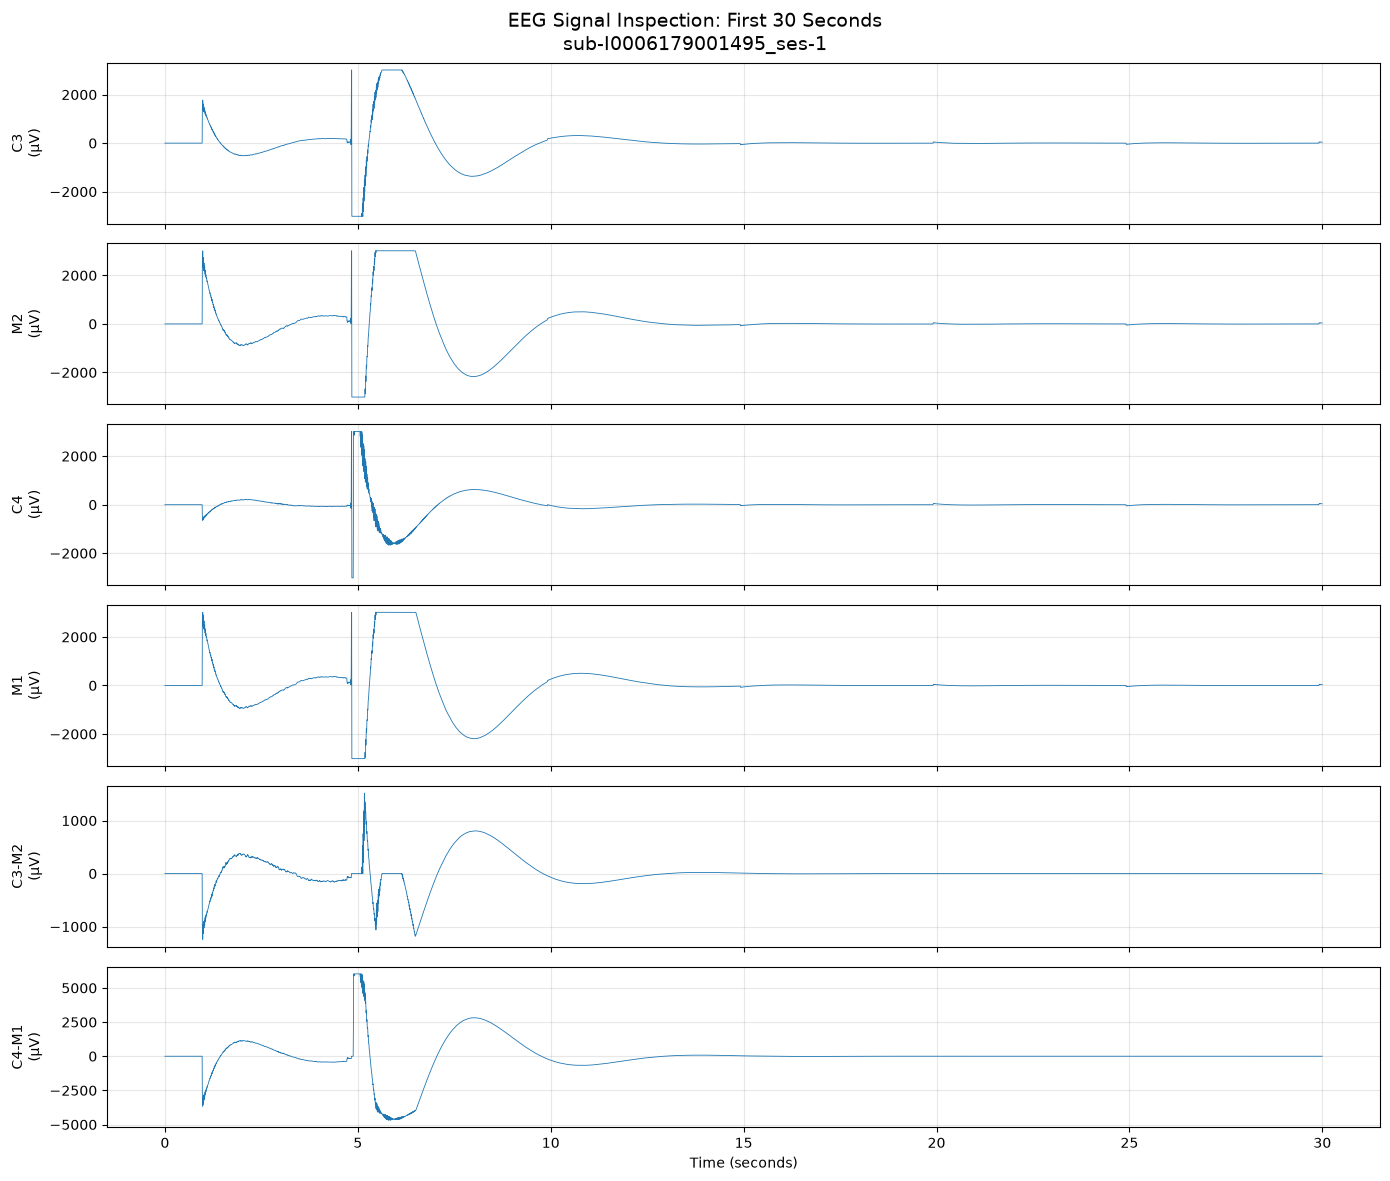

In [180]:
import numpy as np
import matplotlib.pyplot as plt
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = reader.getSignalLabels()
    fs = 200
    n_samples = 30 * fs

    signals = {}

    for name in ["C3", "M2", "C4", "M1"]:
        idx = labels.index(name)

        digital = reader.readSignal(
            idx,
            start=0,
            n=n_samples,
            digital=True
        )

        # Convert digital counts to physical microvolts
        dmin = reader.getDigitalMinimum(idx)
        dmax = reader.getDigitalMaximum(idx)
        pmin = reader.getPhysicalMinimum(idx)
        pmax = reader.getPhysicalMaximum(idx)

        signals[name] = (
            (digital - dmin) / (dmax - dmin) * (pmax - pmin)
            + pmin
        )

finally:
    reader.close()

signals["C3-M2"] = signals["C3"] - signals["M2"]
signals["C4-M1"] = signals["C4"] - signals["M1"]

time = np.arange(n_samples) / fs

fig, axes = plt.subplots(6, 1, figsize=(14, 12), sharex=True)

for ax, name in zip(
    axes,
    ["C3", "M2", "C4", "M1", "C3-M2", "C4-M1"]
):
    ax.plot(time, signals[name], linewidth=0.6)
    ax.set_ylabel(f"{name}\n(µV)")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle(
    "EEG Signal Inspection: First 30 Seconds\n"
    "sub-I0006179001495_ses-1",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [181]:
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = reader.getSignalLabels()
    fs = 200
    window_seconds = 5
    samples_per_window = fs * window_seconds
    total_samples = 30 * fs

    rows = []

    for name in ["C3", "M2", "C4", "M1"]:
        idx = labels.index(name)

        digital = reader.readSignal(
            idx,
            start=0,
            n=total_samples,
            digital=True
        )

        dmin = reader.getDigitalMinimum(idx)
        dmax = reader.getDigitalMaximum(idx)
        pmin = reader.getPhysicalMinimum(idx)
        pmax = reader.getPhysicalMaximum(idx)

        # Convert raw digital counts to microvolts
        signal_uv = (
            (digital - dmin) / (dmax - dmin) * (pmax - pmin)
            + pmin
        )

        for start in range(0, len(signal_uv), samples_per_window):
            segment = signal_uv[start:start + samples_per_window]
            raw_segment = digital[start:start + samples_per_window]

            rows.append({
                "channel": name,
                "window_start_sec": start / fs,
                "std_uV": np.std(segment),
                "peak_to_peak_uV": np.ptp(segment),
                "exact_rail_pct": 100 * np.mean(
                    (raw_segment == dmin) |
                    (raw_segment == dmax)
                ),
                "unique_values": np.unique(raw_segment).size
            })

    audit = pd.DataFrame(rows)

    print(audit.round(3).to_string(index=False))

finally:
    reader.close()

channel  window_start_sec   std_uV  peak_to_peak_uV  exact_rail_pct  unique_values
     C3               0.0  639.734         6029.208             3.1            709
     C3               5.0 1581.589         6029.208             2.4            860
     C3              10.0  134.352          379.511             0.0            767
     C3              15.0   12.366           98.535             0.0            315
     C3              20.0    9.677           85.194             0.0            268
     C3              25.0    9.641           85.930             0.0            279
     M2               0.0  794.001         6029.208             3.1            744
     M2               5.0 1967.172         6029.208             3.7            753
     M2              10.0  212.892          576.580             0.0            823
     M2              15.0   14.386          105.803             0.0            344
     M2              20.0    9.637           84.090             0.0            275
    

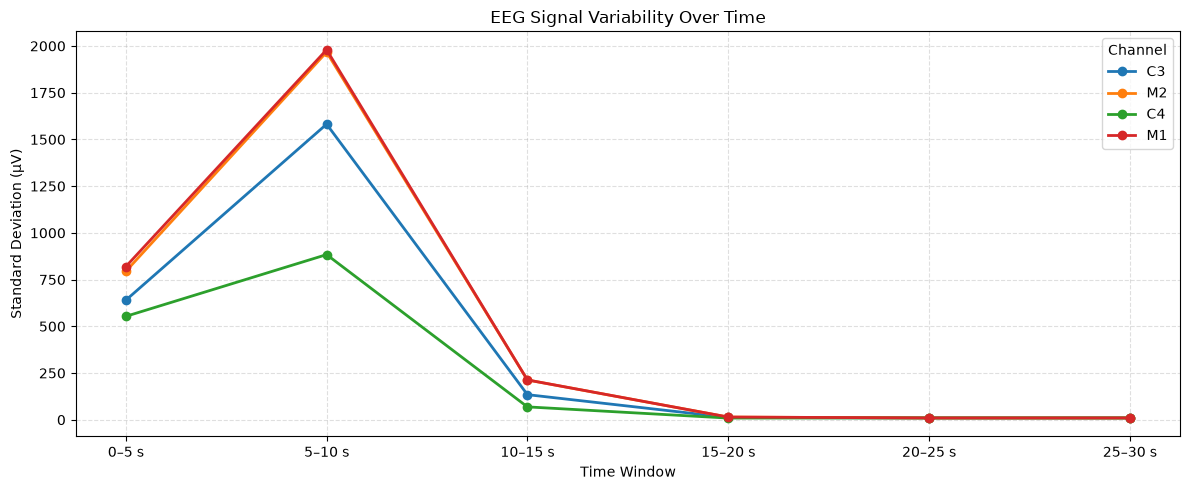

In [182]:
import matplotlib.pyplot as plt

audit_plot = audit.copy()

# Create readable time-window labels
audit_plot["time_window"] = audit_plot["window_start_sec"].apply(
    lambda x: f"{int(x)}–{int(x + 5)} s"
)

window_order = [
    "0–5 s", "5–10 s", "10–15 s",
    "15–20 s", "20–25 s", "25–30 s"
]

plt.figure(figsize=(12, 5))

for channel in ["C3", "M2", "C4", "M1"]:
    subset = (
        audit_plot[audit_plot["channel"] == channel]
        .set_index("time_window")
        .reindex(window_order)
    )

    plt.plot(
        window_order,
        subset["std_uV"],
        marker="o",
        linewidth=2,
        markersize=6,
        label=channel
    )

plt.title("EEG Signal Variability Over Time")
plt.xlabel("Time Window")
plt.ylabel("Standard Deviation (µV)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Channel")
plt.tight_layout()
plt.show()

In [183]:
import numpy as np
import pandas as pd
import pyedflib
from pathlib import Path

# Reuse the three I0006 paths you inspected earlier.
# Set these to the actual EDF paths in your project.
edf_paths = [
    edf_path,
    # Add the other two I0006 EDF paths here
]

channel_names = ["C3", "M2", "C4", "M1"]
fs = 200
window_seconds = 5
samples_per_window = fs * window_seconds
rows = []

for path in edf_paths:
    reader = pyedflib.EdfReader(str(path))

    try:
        labels = reader.getSignalLabels()
        actual_fs = reader.getSampleFrequency(labels.index("C3"))

        if actual_fs != fs:
            print(f"Skipping {Path(path).name}: C3 sampling rate={actual_fs} Hz")
            continue

        n_samples = min(
            int(60 * fs),
            reader.getNSamples()[labels.index("C3")]
        )

        for name in channel_names:
            if name not in labels:
                continue

            idx = labels.index(name)
            digital = reader.readSignal(
                idx, start=0, n=n_samples, digital=True
            )

            dmin = reader.getDigitalMinimum(idx)
            dmax = reader.getDigitalMaximum(idx)
            pmin = reader.getPhysicalMinimum(idx)
            pmax = reader.getPhysicalMaximum(idx)

            signal_uv = (
                (digital - dmin) / (dmax - dmin) * (pmax - pmin)
                + pmin
            )

            for start in range(0, len(signal_uv), samples_per_window):
                segment = signal_uv[start:start + samples_per_window]
                raw_segment = digital[start:start + samples_per_window]

                rows.append({
                    "file": Path(path).name,
                    "channel": name,
                    "start_sec": start / fs,
                    "std_uV": np.std(segment),
                    "peak_to_peak_uV": np.ptp(segment),
                    "exact_rail_pct": 100 * np.mean(
                        (raw_segment == dmin) |
                        (raw_segment == dmax)
                    )
                })

    finally:
        reader.close()

audit = pd.DataFrame(rows)
print(audit.round(3).to_string(index=False))

                        file channel  start_sec   std_uV  peak_to_peak_uV  exact_rail_pct
sub-I0006179001495_ses-1.edf      C3        0.0  639.734         6029.208             3.1
sub-I0006179001495_ses-1.edf      C3        5.0 1581.589         6029.208             2.4
sub-I0006179001495_ses-1.edf      C3       10.0  134.352          379.511             0.0
sub-I0006179001495_ses-1.edf      C3       15.0   12.366           98.535             0.0
sub-I0006179001495_ses-1.edf      C3       20.0    9.677           85.194             0.0
sub-I0006179001495_ses-1.edf      C3       25.0    9.641           85.930             0.0
sub-I0006179001495_ses-1.edf      C3       30.0    7.897           49.773             0.0
sub-I0006179001495_ses-1.edf      C3       35.0    0.000            0.000             0.0
sub-I0006179001495_ses-1.edf      C3       40.0  127.063         3883.707             0.1
sub-I0006179001495_ses-1.edf      C3       45.0   27.229          171.309             0.0
sub-I00061

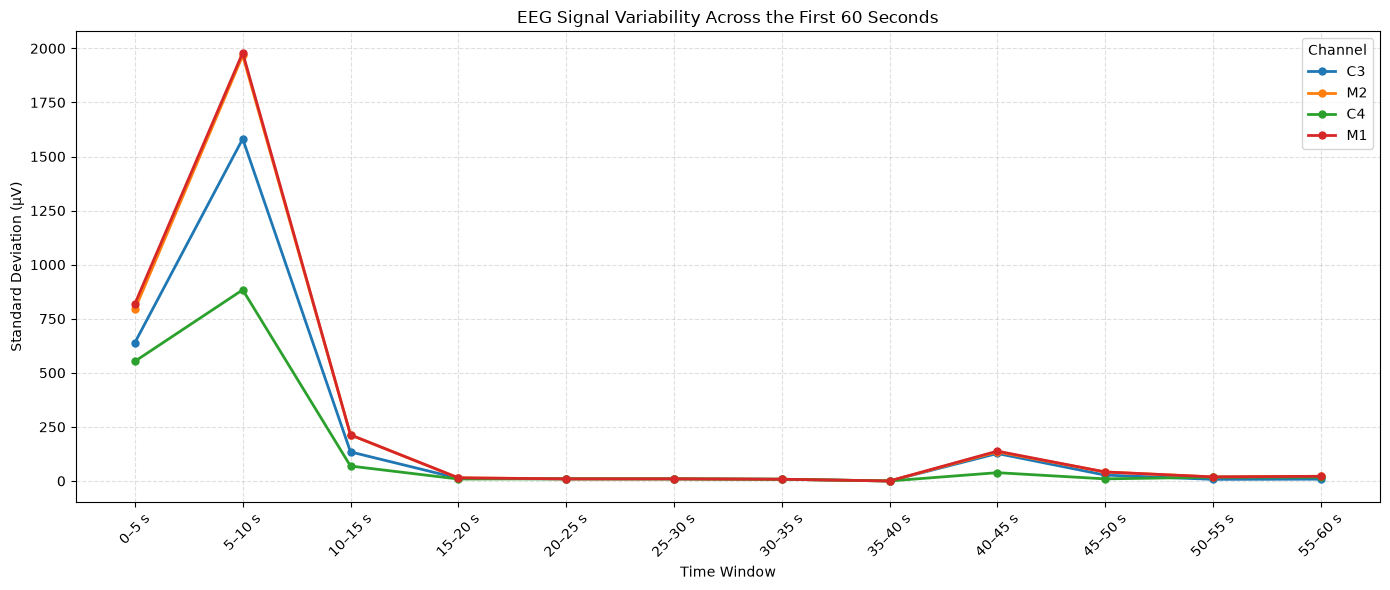

In [184]:
import matplotlib.pyplot as plt
import pandas as pd

# Use the existing audit DataFrame
audit_plot = audit.copy()
audit_plot.columns = audit_plot.columns.str.strip()

# Build readable 5-second window labels
audit_plot["time_window"] = audit_plot["start_sec"].apply(
    lambda x: f"{int(x)}–{int(x + 5)} s"
)

window_order = [
    f"{i}–{i+5} s" for i in range(0, 60, 5)
]

fig, ax = plt.subplots(figsize=(14, 6))

for channel in ["C3", "M2", "C4", "M1"]:
    subset = (
        audit_plot[audit_plot["channel"] == channel]
        .set_index("time_window")
        .reindex(window_order)
    )

    ax.plot(
        window_order,
        subset["std_uV"],
        marker="o",
        linewidth=2,
        markersize=5,
        label=channel
    )

ax.set_title(
    "EEG Signal Variability Across the First 60 Seconds"
)
ax.set_xlabel("Time Window")
ax.set_ylabel("Standard Deviation (µV)")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(title="Channel")
fig.tight_layout()
plt.show()

In [185]:
zero_check = (
    audit_plot.pivot(
        index="time_window",
        columns="channel",
        values="std_uV"
    )
)

channels = ["C3", "M2", "C4", "M1"]

print("Windows with zero variability in all four channels:")
print(zero_check[(zero_check[channels] == 0).all(axis=1)])

Windows with zero variability in all four channels:
channel       C3   C4   M1   M2
time_window                    
35–40 s      0.0  0.0  0.0  0.0


In [186]:
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = reader.getSignalLabels()
    fs = 200

    rows = []

    for name in ["C3", "M2", "C4", "M1"]:
        idx = labels.index(name)

        # Read the 5-second interval from the original EDF
        digital = reader.readSignal(
            idx,
            start=35 * fs,
            n=5 * fs,
            digital=True
        )

        rows.append({
            "channel": name,
            "sample_count": len(digital),
            "unique_digital_values": np.unique(digital).size,
            "first_10_samples": digital[:10].tolist(),
            "min_digital": int(digital.min()),
            "max_digital": int(digital.max()),
            "std_digital": float(np.std(digital))
        })

    print(pd.DataFrame(rows).to_string(index=False))

finally:
    reader.close()

channel  sample_count  unique_digital_values               first_10_samples  min_digital  max_digital  std_digital
     C3          1000                      1 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]            0            0          0.0
     M2          1000                      1 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]            0            0          0.0
     C4          1000                      1 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]            0            0          0.0
     M1          1000                      1 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]            0            0          0.0


In [187]:
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = reader.getSignalLabels()
    fs = 200
    rows = []

    for name in ["C3", "M2", "C4", "M1"]:
        idx = labels.index(name)

        # Inspect 30–45 seconds, including the zero-filled interval
        digital = reader.readSignal(
            idx,
            start=30 * fs,
            n=15 * fs,
            digital=True
        )

        for start_sec in [30, 35, 40]:
            offset = (start_sec - 30) * fs
            segment = digital[offset:offset + 5 * fs]

            rows.append({
                "channel": name,
                "window": f"{start_sec}–{start_sec + 5} s",
                "unique_values": np.unique(segment).size,
                "zero_pct": 100 * np.mean(segment == 0),
                "min": int(segment.min()),
                "max": int(segment.max()),
                "std": float(np.std(segment))
            })

    print(pd.DataFrame(rows).round(3).to_string(index=False))

finally:
    reader.close()

channel  window  unique_values  zero_pct    min   max      std
     C3 30–35 s            256       5.8   -155   386   85.831
     C3 35–40 s              1     100.0      0     0    0.000
     C3 40–45 s             83      91.8 -32767  9446 1381.082
     M2 30–35 s            253       5.5   -158   385   86.270
     M2 35–40 s              1     100.0      0     0    0.000
     M2 40–45 s             82      91.8  -6949 32766 1461.596
     C4 30–35 s            259       5.3   -157   390   86.790
     C4 35–40 s              1     100.0      0     0    0.000
     C4 40–45 s             81      91.8 -11635  1720  416.917
     M1 30–35 s            254       5.4   -157   389   87.705
     M1 35–40 s              1     100.0      0     0    0.000
     M1 40–45 s             82      91.8  -7245 32766 1500.021


In [188]:
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = reader.getSignalLabels()
    fs = 200
    rows = []

    for name in ["C3", "M2", "C4", "M1"]:
        idx = labels.index(name)

        digital = reader.readSignal(
            idx,
            start=30 * fs,
            n=15 * fs,
            digital=True
        )

        # Find consecutive runs of zeros
        is_zero = digital == 0
        changes = np.diff(np.r_[False, is_zero, False].astype(int))
        starts = np.where(changes == 1)[0]
        ends = np.where(changes == -1)[0]

        for start, end in zip(starts, ends):
            duration = (end - start) / fs

            if duration >= 0.1:
                rows.append({
                    "channel": name,
                    "start_sec": 30 + start / fs,
                    "end_sec": 30 + end / fs,
                    "duration_sec": duration,
                    "sample_count": end - start
                })

    zero_runs = pd.DataFrame(rows)

    if zero_runs.empty:
        print("No zero runs of at least 0.1 seconds found.")
    else:
        print(
            zero_runs.sort_values(
                ["start_sec", "channel"]
            ).round(3).to_string(index=False)
        )

finally:
    reader.close()

channel  start_sec  end_sec  duration_sec  sample_count
     C3      34.77    44.59          9.82          1964
     C4      34.77    44.59          9.82          1964
     M1      34.77    44.59          9.82          1964
     M2      34.77    44.59          9.82          1964


In [189]:
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = reader.getSignalLabels()
    fs = 200
    rows = []

    for name in ["C3", "M2", "C4", "M1"]:
        idx = labels.index(name)

        digital = reader.readSignal(
            idx,
            start=30 * fs,
            n=15 * fs,
            digital=True
        )

        # Find consecutive runs of zeros
        is_zero = digital == 0
        changes = np.diff(np.r_[False, is_zero, False].astype(int))
        starts = np.where(changes == 1)[0]
        ends = np.where(changes == -1)[0]

        for start, end in zip(starts, ends):
            duration = (end - start) / fs

            if duration >= 0.1:
                rows.append({
                    "channel": name,
                    "start_sec": 30 + start / fs,
                    "end_sec": 30 + end / fs,
                    "duration_sec": duration,
                    "sample_count": end - start
                })

    zero_runs = pd.DataFrame(rows)

    if zero_runs.empty:
        print("No zero runs of at least 0.1 seconds found.")
    else:
        print(
            zero_runs.sort_values(
                ["start_sec", "channel"]
            ).round(3).to_string(index=False)
        )

finally:
    reader.close()

channel  start_sec  end_sec  duration_sec  sample_count
     C3      34.77    44.59          9.82          1964
     C4      34.77    44.59          9.82          1964
     M1      34.77    44.59          9.82          1964
     M2      34.77    44.59          9.82          1964


In [190]:
# Find all physiological EDF files in the pilot downloads folder.
from pathlib import Path

DATA_DIR = Path.cwd() / "data"
DOWNLOAD_DIR = DATA_DIR / "pilot_downloads"

edf_files = sorted(
    p for p in DOWNLOAD_DIR.rglob("*.edf")
    if "_expert_annotations" not in p.name.lower()
    and "annotation" not in p.name.lower()
)

print("EDF files found:", len(edf_files))
for p in edf_files[:5]:
    print(p)

EDF files found: 50
d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_downloads\physiological_data\I0002\sub-I0002150027361_ses-4.edf
d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_downloads\physiological_data\I0002\sub-I0002150028560_ses-1.edf
d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_downloads\physiological_data\I0006\sub-I0006179001495_ses-1.edf
d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_downloads\physiological_data\I0006\sub-I0006179003398_ses-1.edf
d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_downloads\physiological_data\I0006\sub-I0006179003402_ses-1.edf


In [191]:
# Scan all 50 pilot EEG files for consecutive zero-valued runs of at least 1 second.
import numpy as np
import pandas as pd
import pyedflib

zero_run_rows = []
channels_to_check = ["C3", "C4", "M1", "M2"]

for file_path in edf_files:
    reader = pyedflib.EdfReader(str(file_path))

    try:
        labels = reader.getSignalLabels()

        for channel in channels_to_check:
            if channel not in labels:
                continue

            idx = labels.index(channel)
            fs = int(round(reader.getSampleFrequency(idx)))
            digital = reader.readSignal(idx, digital=True)

            is_zero = digital == 0
            changes = np.diff(np.r_[False, is_zero, False].astype(int))
            starts = np.where(changes == 1)[0]
            ends = np.where(changes == -1)[0]

            for start, end in zip(starts, ends):
                duration = (end - start) / fs

                if duration >= 1.0:
                    zero_run_rows.append({
                        "file": file_path.name,
                        "site": file_path.parent.name,
                        "channel": channel,
                        "start_sec": start / fs,
                        "end_sec": end / fs,
                        "duration_sec": duration,
                        "sample_count": end - start
                    })
    except Exception as exc:
        print(f"ERROR: {file_path.name}: {exc}")
    finally:
        reader.close()

zero_run_df = pd.DataFrame(zero_run_rows)
output_path = DATA_DIR / "pilot_consecutive_zero_runs.csv"
zero_run_df.to_csv(output_path, index=False)

print("Files scanned:", len(edf_files))
print("Zero runs >= 1 second:", len(zero_run_df))
print("Files affected:", zero_run_df["file"].nunique() if not zero_run_df.empty else 0)
print("Saved to:", output_path)

if not zero_run_df.empty:
    print(
        zero_run_df.sort_values(
            ["duration_sec", "file", "channel"],
            ascending=[False, True, True]
        ).head(30).round(3).to_string(index=False)
    )

Files scanned: 50
Zero runs >= 1 second: 150
Files affected: 10
Saved to: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_consecutive_zero_runs.csv
                        file  site channel  start_sec   end_sec  duration_sec  sample_count
sub-I0006179007787_ses-1.edf I0006      C3  18307.050 18621.530       314.480         62896
sub-I0006179007787_ses-1.edf I0006      C4  18307.050 18621.530       314.480         62896
sub-I0006179007787_ses-1.edf I0006      M1  18307.050 18621.530       314.480         62896
sub-I0006179007787_ses-1.edf I0006      M2  18307.050 18621.530       314.480         62896
sub-S0001120440759_ses-3.edf S0001      M1   7682.053  7968.117       286.064        146465
sub-S0001120440759_ses-3.edf S0001      M2   7682.053  7968.117       286.064        146465
sub-I0006179003398_ses-1.edf I0006      C3  13566.910 13850.210       283.300         56660
sub-I0006179003398_ses-1.edf I0006      C4  13566.910 13850.210       283.300         56660
sub-I0006179003398_ses-1.ed

In [192]:
# Group overlapping zero runs into distinct events within each recording.
import pandas as pd

runs = pd.read_csv(DATA_DIR / "pilot_consecutive_zero_runs.csv")
event_rows = []

for file_name, group in runs.groupby("file"):
    group = group.sort_values("start_sec")
    current = None

    for _, row in group.iterrows():
        if current is None or row["start_sec"] > current["end_sec"] + 0.05:
            if current is not None:
                event_rows.append(current)

            current = {
                "file": file_name,
                "site": row["site"],
                "start_sec": row["start_sec"],
                "end_sec": row["end_sec"],
                "channels": {row["channel"]}
            }
        else:
            current["end_sec"] = max(current["end_sec"], row["end_sec"])
            current["channels"].add(row["channel"])

    if current is not None:
        event_rows.append(current)

events = pd.DataFrame(event_rows)
events["duration_sec"] = events["end_sec"] - events["start_sec"]
events["channels"] = events["channels"].apply(lambda x: ", ".join(sorted(x)))
events = events.sort_values("duration_sec", ascending=False)

events.to_csv(DATA_DIR / "pilot_zero_events_grouped.csv", index=False)

print("Distinct grouped events:", len(events))
print("Affected recordings:", events["file"].nunique())
print("\nLongest events:")
print(events.head(20).round(3).to_string(index=False))
print("\nEvents by channel count:")
print(events["channels"].value_counts().to_string())

Distinct grouped events: 40
Affected recordings: 10

Longest events:
                        file  site  start_sec   end_sec       channels  duration_sec
sub-I0006179007787_ses-1.edf I0006  18307.050 18621.530 C3, C4, M1, M2       314.480
sub-S0001120440759_ses-3.edf S0001   7682.053  7968.117         M1, M2       286.064
sub-I0006179003398_ses-1.edf I0006  13566.910 13850.210 C3, C4, M1, M2       283.300
sub-I0006179001495_ses-1.edf I0006   9894.890 10148.510 C3, C4, M1, M2       253.620
sub-I0006179013670_ses-1.edf I0006   3377.380  3581.610 C3, C4, M1, M2       204.230
sub-I0006179013670_ses-1.edf I0006  15134.460 15336.780 C3, C4, M1, M2       202.320
sub-I0006179003402_ses-1.edf I0006  13369.020 13569.180 C3, C4, M1, M2       200.160
sub-S0001120440759_ses-3.edf S0001  19074.617 19246.096         M1, M2       171.479
sub-I0006179008848_ses-1.edf I0006  17317.050 17479.620 C3, C4, M1, M2       162.570
sub-I0006179008848_ses-1.edf I0006  11460.870 11617.900 C3, C4, M1, M2       157.

In [193]:
# Quantify zero-event duration and affected channels for each pilot recording.
import pandas as pd

events = pd.read_csv(DATA_DIR / "pilot_zero_events_grouped.csv")
qc = pd.read_csv(DATA_DIR / "pilot_eeg_qc_summary.csv")

recording_summary = (
    events.groupby(["file", "site"], as_index=False)
    .agg(
        event_count=("duration_sec", "size"),
        total_event_seconds=("duration_sec", "sum"),
        longest_event_seconds=("duration_sec", "max")
    )
)

recording_summary = recording_summary.merge(
    qc[["file", "duration_hours", "sampling_rate_hz"]],
    on="file",
    how="left",
    validate="one_to_one"
)

recording_summary["recording_seconds"] = (
    recording_summary["duration_hours"] * 3600
)
recording_summary["event_seconds_pct"] = (
    100 * recording_summary["total_event_seconds"]
    / recording_summary["recording_seconds"]
)

recording_summary = recording_summary.sort_values(
    "event_seconds_pct", ascending=False
)

recording_summary.to_csv(
    DATA_DIR / "pilot_zero_event_recording_summary.csv",
    index=False
)

print(recording_summary.round(3).to_string(index=False))
print("\nSaved:", DATA_DIR / "pilot_zero_event_recording_summary.csv")

                        file  site  event_count  total_event_seconds  longest_event_seconds  duration_hours  sampling_rate_hz  recording_seconds  event_seconds_pct
sub-I0006179008848_ses-1.edf I0006            5              535.620                162.570           7.240             200.0          26064.995              2.055
sub-I0006179007787_ses-1.edf I0006            5              448.430                314.480           6.233             200.0          22439.995              1.998
sub-S0001120440759_ses-3.edf S0001            5              479.553                286.064           8.067             512.0          29039.998              1.651
sub-I0006179013670_ses-1.edf I0006            4              428.550                204.230           7.449             200.0          26814.995              1.598
sub-I0006179003398_ses-1.edf I0006            2              286.090                283.300           6.937             200.0          24974.995              1.146
sub-I00061790014

In [194]:
# Compare zero-event burden across site and cognitive-impairment label.
import pandas as pd

events = pd.read_csv(DATA_DIR / "pilot_zero_events_grouped.csv")
summary = pd.read_csv(DATA_DIR / "pilot_zero_event_recording_summary.csv")
cohort = pd.read_csv(DATA_DIR / "pilot_eeg_merged_qc_audit.csv")

label_cols = ["file", "SiteID", "Cognitive_Impairment"]
labels = cohort[label_cols].drop_duplicates(subset="file")

comparison = summary.merge(
    labels,
    on="file",
    how="left",
    validate="one_to_one"
)

print("Recording-level comparison:")
print(
    comparison.groupby(
        ["SiteID", "Cognitive_Impairment"],
        dropna=False
    ).agg(
        recordings=("file", "nunique"),
        mean_event_pct=("event_seconds_pct", "mean"),
        median_event_pct=("event_seconds_pct", "median"),
        max_event_pct=("event_seconds_pct", "max")
    ).round(3).to_string()
)

print("\nRecordings with zero events, including target labels:")
print(
    comparison[
        ["file", "SiteID", "Cognitive_Impairment",
         "event_count", "event_seconds_pct"]
    ].sort_values(
        ["SiteID", "Cognitive_Impairment", "event_seconds_pct"],
        ascending=[True, True, False]
    ).to_string(index=False)
)

Recording-level comparison:
                             recordings  mean_event_pct  median_event_pct  max_event_pct
SiteID Cognitive_Impairment                                                             
I0006  False                          8           0.936             0.935          2.055
       True                           1           1.998             1.998          1.998
S0001  True                           1           1.651             1.651          1.651

Recordings with zero events, including target labels:
                        file SiteID  Cognitive_Impairment  event_count  event_seconds_pct
sub-I0006179008848_ses-1.edf  I0006                 False            5           2.054940
sub-I0006179013670_ses-1.edf  I0006                 False            4           1.598173
sub-I0006179003398_ses-1.edf  I0006                 False            2           1.145506
sub-I0006179001495_ses-1.edf  I0006                 False            4           1.050137
sub-I0006179003402_ses

In [195]:
# Include all pilot recordings and assign zero event burden to recordings without detected events.
import pandas as pd

cohort = pd.read_csv(DATA_DIR / "pilot_eeg_merged_qc_audit.csv")
summary = pd.read_csv(DATA_DIR / "pilot_zero_event_recording_summary.csv")

cohort["file"] = cohort["relative_path"].apply(
    lambda p: str(p).replace("\\", "/").split("/")[-1]
)

analysis_df = cohort.merge(
    summary[["file", "event_count", "total_event_seconds", "event_seconds_pct"]],
    on="file",
    how="left",
    validate="one_to_one"
)

for col in ["event_count", "total_event_seconds", "event_seconds_pct"]:
    analysis_df[col] = analysis_df[col].fillna(0)

print("All pilot recordings:", analysis_df["file"].nunique())
print("\nBy site and label:")
print(
    analysis_df.groupby(["SiteID", "Cognitive_Impairment"])
    .agg(
        recordings=("file", "nunique"),
        recordings_with_events=("event_count", lambda x: (x > 0).sum()),
        mean_event_pct=("event_seconds_pct", "mean"),
        median_event_pct=("event_seconds_pct", "median")
    )
    .round(3)
    .to_string()
)

analysis_df.to_csv(DATA_DIR / "pilot_all_recordings_zero_event_analysis.csv", index=False)
print("\nSaved:", DATA_DIR / "pilot_all_recordings_zero_event_analysis.csv")

All pilot recordings: 50

By site and label:
                             recordings  recordings_with_events  mean_event_pct  median_event_pct
SiteID Cognitive_Impairment                                                                      
I0002  False                          2                       0           0.000             0.000
I0006  False                          8                       8           0.936             0.935
       True                           1                       1           1.998             1.998
S0001  False                         36                       0           0.000             0.000
       True                           3                       1           0.550             0.000

Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_all_recordings_zero_event_analysis.csv


In [196]:
# Compare the original digital zero-run intervals across C3, C4, M1, and M2.
import pandas as pd

runs = pd.read_csv(DATA_DIR / "pilot_consecutive_zero_runs.csv")

target_file = "sub-I0006179001495_ses-1.edf"

print(
    runs.loc[
        runs["file"].eq(target_file),
        ["file", "channel", "start_sec", "end_sec",
         "duration_sec", "sample_count"]
    ]
    .sort_values(["start_sec", "channel"])
    .round(3)
    .to_string(index=False)
)

                        file channel  start_sec  end_sec  duration_sec  sample_count
sub-I0006179001495_ses-1.edf      C3      34.77    44.59          9.82          1964
sub-I0006179001495_ses-1.edf      C4      34.77    44.59          9.82          1964
sub-I0006179001495_ses-1.edf      M1      34.77    44.59          9.82          1964
sub-I0006179001495_ses-1.edf      M2      34.77    44.59          9.82          1964
sub-I0006179001495_ses-1.edf      C3     456.59   459.79          3.20           640
sub-I0006179001495_ses-1.edf      C4     456.59   459.79          3.20           640
sub-I0006179001495_ses-1.edf      M1     456.59   459.79          3.20           640
sub-I0006179001495_ses-1.edf      M2     456.59   459.79          3.20           640
sub-I0006179001495_ses-1.edf      C3    9894.89 10148.51        253.62         50724
sub-I0006179001495_ses-1.edf      C4    9894.89 10148.51        253.62         50724
sub-I0006179001495_ses-1.edf      M1    9894.89 10148.51        2

In [197]:
# Calculate intervals where all four original digital EEG channels are simultaneously zero.
import numpy as np
import pandas as pd
import pyedflib

target_file = next(
    p for p in edf_files
    if p.name == "sub-I0006179001495_ses-1.edf"
)

reader = pyedflib.EdfReader(str(target_file))

try:
    labels = reader.getSignalLabels()
    channels = ["C3", "C4", "M1", "M2"]
    fs_values = {
        ch: reader.getSampleFrequency(labels.index(ch))
        for ch in channels
    }

    print("Sampling rates:", fs_values)

    if len(set(fs_values.values())) != 1:
        print("Sampling rates differ; align channels before comparing.")
    else:
        fs = int(round(next(iter(fs_values.values()))))
        digital_channels = np.vstack([
            reader.readSignal(labels.index(ch), digital=True)
            for ch in channels
        ])

        all_zero = np.all(digital_channels == 0, axis=0)
        changes = np.diff(np.r_[False, all_zero, False].astype(int))
        starts = np.where(changes == 1)[0]
        ends = np.where(changes == -1)[0]

        rows = [
            {
                "start_sec": start / fs,
                "end_sec": end / fs,
                "duration_sec": (end - start) / fs
            }
            for start, end in zip(starts, ends)
            if (end - start) / fs >= 1
        ]

        simultaneous_zero_runs = pd.DataFrame(rows)
        print(simultaneous_zero_runs.round(3).to_string(index=False))
        print(
            "\nTotal simultaneous-zero seconds:",
            round(simultaneous_zero_runs["duration_sec"].sum(), 3)
        )
finally:
    reader.close()

Sampling rates: {'C3': 200.0, 'C4': 200.0, 'M1': 200.0, 'M2': 200.0}
 start_sec  end_sec  duration_sec
     34.77    44.59          9.82
    456.59   459.79          3.20
   9894.89 10148.51        253.62
  25587.91 25590.00          2.09

Total simultaneous-zero seconds: 268.73


In [198]:
# Measure simultaneous digital-zero intervals across C3, C4, M1, and M2 in all pilot recordings.
import numpy as np
import pandas as pd
import pyedflib

simultaneous_rows = []
simultaneous_errors = []

for file_path in edf_files:
    reader = pyedflib.EdfReader(str(file_path))

    try:
        labels = reader.getSignalLabels()
        missing = [ch for ch in ["C3", "C4", "M1", "M2"] if ch not in labels]

        if missing:
            simultaneous_errors.append({
                "file": file_path.name,
                "issue": "Missing channels: " + ", ".join(missing)
            })
            continue

        indices = {ch: labels.index(ch) for ch in ["C3", "C4", "M1", "M2"]}
        rates = {
            ch: reader.getSampleFrequency(idx)
            for ch, idx in indices.items()
        }

        if len(set(rates.values())) != 1:
            simultaneous_errors.append({
                "file": file_path.name,
                "issue": f"Unequal sampling rates: {rates}"
            })
            continue

        fs = float(next(iter(rates.values())))
        lengths = {ch: reader.getNSamples()[idx] for ch, idx in indices.items()}
        common_length = min(lengths.values())

        digital = np.vstack([
            reader.readSignal(indices[ch], start=0, n=common_length, digital=True)
            for ch in indices
        ])

        all_zero = np.all(digital == 0, axis=0)
        changes = np.diff(np.r_[False, all_zero, False].astype(int))
        starts = np.where(changes == 1)[0]
        ends = np.where(changes == -1)[0]

        runs = [
            (start, end)
            for start, end in zip(starts, ends)
            if (end - start) / fs >= 1.0
        ]

        total_seconds = sum((end - start) / fs for start, end in runs)
        duration_seconds = common_length / fs

        simultaneous_rows.append({
            "file": file_path.name,
            "site": file_path.parent.name,
            "sampling_rate_hz": fs,
            "duration_seconds": duration_seconds,
            "simultaneous_zero_run_count": len(runs),
            "simultaneous_zero_seconds": total_seconds,
            "simultaneous_zero_pct": 100 * total_seconds / duration_seconds
        })

    except Exception as exc:
        simultaneous_errors.append({
            "file": file_path.name,
            "issue": repr(exc)
        })
    finally:
        reader.close()

simultaneous_df = pd.DataFrame(simultaneous_rows)
errors_df = pd.DataFrame(simultaneous_errors)

simultaneous_df.to_csv(DATA_DIR / "pilot_simultaneous_zero_audit.csv", index=False)
errors_df.to_csv(DATA_DIR / "pilot_simultaneous_zero_audit_errors.csv", index=False)

print("Recordings evaluated:", len(simultaneous_df))
print("Recordings requiring review:", len(errors_df))
print("Recordings with simultaneous zero runs >= 1 second:",
      int((simultaneous_df["simultaneous_zero_run_count"] > 0).sum()))
print("\nLargest simultaneous-zero percentages:")
print(
    simultaneous_df.sort_values("simultaneous_zero_pct", ascending=False)
    .head(15).round(3).to_string(index=False)
)
print("\nSaved audit:", DATA_DIR / "pilot_simultaneous_zero_audit.csv")
print("Saved review list:", DATA_DIR / "pilot_simultaneous_zero_audit_errors.csv")

Recordings evaluated: 9
Recordings requiring review: 41
Recordings with simultaneous zero runs >= 1 second: 9

Largest simultaneous-zero percentages:
                        file  site  sampling_rate_hz  duration_seconds  simultaneous_zero_run_count  simultaneous_zero_seconds  simultaneous_zero_pct
sub-I0006179008848_ses-1.edf I0006             200.0           26065.0                            5                     535.62                  2.055
sub-I0006179007787_ses-1.edf I0006             200.0           22440.0                            5                     448.43                  1.998
sub-I0006179013670_ses-1.edf I0006             200.0           26815.0                            4                     428.55                  1.598
sub-I0006179003398_ses-1.edf I0006             200.0           24975.0                            2                     286.09                  1.146
sub-I0006179001495_ses-1.edf I0006             200.0           25590.0                            4 

In [199]:
# Summarize why recordings were not evaluated in the simultaneous-zero audit.
import pandas as pd

errors = pd.read_csv(DATA_DIR / "pilot_simultaneous_zero_audit_errors.csv")

print("Review records:", len(errors))
print("\nIssue categories:")
print(errors["issue"].value_counts(dropna=False).to_string())

print("\nSample review records:")
print(errors.head(15).to_string(index=False))

Review records: 41

Issue categories:
issue
Missing channels: C3, C4, M1, M2    40
Missing channels: C3, C4             1

Sample review records:
                        file                            issue
sub-I0002150027361_ses-4.edf Missing channels: C3, C4, M1, M2
sub-I0002150028560_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001111407087_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001111607694_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001112004382_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001112257942_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001112863983_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001113075475_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001113174062_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001113251921_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001113773108_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001114299827_ses-1.edf Missing channels: C3, C4, M1, M2
sub-S0001114315183_ses-1.edf Missing channels: C

In [200]:
# Inspect the original channel labels in representative I0002 and S0001 recordings.
import pyedflib

for site in ["I0002", "S0001"]:
    candidates = [
        p for p in edf_files
        if p.parent.name == site
    ]

    if not candidates:
        print(f"\nNo pilot EDF found for {site}")
        continue

    file_path = candidates[0]
    reader = pyedflib.EdfReader(str(file_path))

    try:
        print(f"\nSite: {site}")
        print("File:", file_path.name)
        print("Sampling rates:", sorted(set(reader.getSampleFrequencies())))
        print("Channel labels:")
        for label in reader.getSignalLabels():
            print(" ", repr(label))
    finally:
        reader.close()


Site: I0002
File: sub-I0002150027361_ses-4.edf
Sampling rates: [np.float64(25.0), np.float64(200.0)]
Channel labels:
  'F3-M2'
  'F4-M1'
  'C3-M2'
  'C4-M1'
  'O1-M2'
  'O2-M1'
  'E1'
  'E2'
  'CHIN'
  'NPT'
  'THERM'
  'CHEST'
  'ABDOMINAL'
  'LAT'
  'RAT'
  'EKG'
  'SaO2'
  'C-FLOW'
  'C PRESS'

Site: S0001
File: sub-S0001111407087_ses-1.edf
Sampling rates: [np.float64(200.0)]
Channel labels:
  'F3-M2'
  'F4-M1'
  'C3-M2'
  'C4-M1'
  'O1-M2'
  'O2-M1'
  'E1-M2'
  'E2-M1'
  'CHIN1-CHIN2'
  'LAT'
  'RAT'
  'CPRES'
  'CFLOW'
  'AIRFLOW'
  'PTAF'
  'CHEST'
  'ABD'
  'SaO2'
  'EKG'


In [201]:
# Inspect simultaneous zero runs using the actual bipolar EEG channel labels.
import numpy as np
import pandas as pd
import pyedflib

bipolar_channels = ["F3-M2", "F4-M1", "C3-M2", "C4-M1"]
bipolar_rows = []
bipolar_errors = []

for file_path in edf_files:
    reader = pyedflib.EdfReader(str(file_path))

    try:
        labels = [label.strip() for label in reader.getSignalLabels()]
        missing = [ch for ch in bipolar_channels if ch not in labels]

        if missing:
            bipolar_errors.append({
                "file": file_path.name,
                "issue": "Missing bipolar channels: " + ", ".join(missing)
            })
            continue

        indices = {ch: labels.index(ch) for ch in bipolar_channels}
        rates = {
            ch: reader.getSampleFrequency(idx)
            for ch, idx in indices.items()
        }

        if len(set(rates.values())) != 1:
            bipolar_errors.append({
                "file": file_path.name,
                "issue": f"Unequal sampling rates: {rates}"
            })
            continue

        fs = float(next(iter(rates.values())))
        sample_counts = reader.getNSamples()
        common_length = min(sample_counts[idx] for idx in indices.values())

        digital = np.vstack([
            reader.readSignal(indices[ch], start=0, n=common_length, digital=True)
            for ch in bipolar_channels
        ])

        all_zero = np.all(digital == 0, axis=0)
        changes = np.diff(np.r_[False, all_zero, False].astype(int))
        starts = np.where(changes == 1)[0]
        ends = np.where(changes == -1)[0]

        runs = [
            (start, end)
            for start, end in zip(starts, ends)
            if (end - start) / fs >= 1.0
        ]

        duration_seconds = common_length / fs
        zero_seconds = sum((end - start) / fs for start, end in runs)

        bipolar_rows.append({
            "file": file_path.name,
            "site": file_path.parent.name,
            "duration_seconds": duration_seconds,
            "simultaneous_zero_run_count": len(runs),
            "simultaneous_zero_seconds": zero_seconds,
            "simultaneous_zero_pct": 100 * zero_seconds / duration_seconds
        })

    except Exception as exc:
        bipolar_errors.append({
            "file": file_path.name,
            "issue": repr(exc)
        })
    finally:
        reader.close()

bipolar_audit = pd.DataFrame(bipolar_rows)
bipolar_review = pd.DataFrame(bipolar_errors)

bipolar_audit.to_csv(DATA_DIR / "pilot_bipolar_zero_audit.csv", index=False)
bipolar_review.to_csv(DATA_DIR / "pilot_bipolar_zero_audit_review.csv", index=False)

print("Recordings evaluated:", len(bipolar_audit))
print("Recordings requiring review:", len(bipolar_review))
print("Recordings with simultaneous zero runs:",
      int((bipolar_audit["simultaneous_zero_run_count"] > 0).sum()))

if not bipolar_audit.empty:
    print("\nLargest zero-event percentages:")
    print(
        bipolar_audit.sort_values("simultaneous_zero_pct", ascending=False)
        .head(15).round(3).to_string(index=False)
    )

if not bipolar_review.empty:
    print("\nReview reasons:")
    print(bipolar_review["issue"].value_counts().to_string())

Recordings evaluated: 40
Recordings requiring review: 10
Recordings with simultaneous zero runs: 0

Largest zero-event percentages:
                        file  site  duration_seconds  simultaneous_zero_run_count  simultaneous_zero_seconds  simultaneous_zero_pct
sub-I0002150027361_ses-4.edf I0002             147.0                            0                          0                    0.0
sub-S0001111407087_ses-1.edf S0001           29220.0                            0                          0                    0.0
sub-S0001111607694_ses-1.edf S0001           24564.0                            0                          0                    0.0
sub-S0001112004382_ses-1.edf S0001           25590.0                            0                          0                    0.0
sub-S0001112257942_ses-1.edf S0001           28760.0                            0                          0                    0.0
sub-S0001112863983_ses-1.edf S0001           30714.0                        

In [202]:
# Compare stored bipolar signals with original electrode channels around the confirmed zero interval.
import numpy as np
import pyedflib

target_file = next(
    p for p in edf_files
    if p.name == "sub-I0006179001495_ses-1.edf"
)

reader = pyedflib.EdfReader(str(target_file))

try:
    labels = [label.strip() for label in reader.getSignalLabels()]
    print("Channels available:")
    print(labels)

    fs = 200
    start_sec, end_sec = 30, 50
    start, n = start_sec * fs, (end_sec - start_sec) * fs

    for channel in ["C3", "M2", "C3-M2", "C4", "M1", "C4-M1"]:
        if channel not in labels:
            print(f"\n{channel}: not present")
            continue

        idx = labels.index(channel)
        digital = reader.readSignal(idx, start=start, n=n, digital=True)
        physical = reader.readSignal(idx, start=start, n=n)

        print(
            f"\n{channel}:",
            f"unique_digital={len(np.unique(digital))}",
            f"zero_pct={100 * np.mean(digital == 0):.2f}%",
            f"physical_std={np.std(physical):.3f}",
            f"physical_min={np.min(physical):.3f}",
            f"physical_max={np.max(physical):.3f}"
        )
finally:
    reader.close()

Channels available:
['Right Leg', 'EKG', 'Nasal Pressure', 'Left Leg', 'M1', 'C3', 'M2', 'C4', 'O2', 'E1', 'E2', 'O1', 'ChinA', 'ChinR', 'ChinL', 'F3', 'Thorax', 'Abdomen', 'Thermistor', 'F4', 'CFLOW', 'CPAP Pressure', 'SpO2', 'Flow_DR']

C3: unique_digital=756 zero_pct=49.40% physical_std=65.247 physical_min=-3014.650 physical_max=869.057

M2: unique_digital=944 zero_pct=49.33% physical_std=70.869 physical_min=-639.326 physical_max=3014.558

C3-M2: not present

C4: unique_digital=474 zero_pct=49.33% physical_std=20.183 physical_min=-1070.451 physical_max=158.245

M1: unique_digital=954 zero_pct=49.30% physical_std=72.539 physical_min=-666.559 physical_max=3014.558

C4-M1: not present


In [203]:
# Reconstruct bipolar derivations from physical electrode signals and check zero runs.
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(target_file))

try:
    labels = [label.strip() for label in reader.getSignalLabels()]
    fs = 200
    start_sec, end_sec = 30, 50
    start, n = start_sec * fs, (end_sec - start_sec) * fs

    reconstructed = {}

    for bipolar, positive, negative in [
        ("C3-M2", "C3", "M2"),
        ("C4-M1", "C4", "M1")
    ]:
        pos_idx = labels.index(positive)
        neg_idx = labels.index(negative)

        pos = reader.readSignal(pos_idx, start=start, n=n)
        neg = reader.readSignal(neg_idx, start=start, n=n)
        bipolar_signal = pos - neg
        reconstructed[bipolar] = bipolar_signal

        is_zero = np.isclose(bipolar_signal, 0.0, atol=1e-9)
        changes = np.diff(np.r_[False, is_zero, False].astype(int))
        starts = np.where(changes == 1)[0]
        ends = np.where(changes == -1)[0]

        print(f"\n{bipolar}")
        print("Reconstructed signal standard deviation:", round(np.std(bipolar_signal), 3))
        print("Exact/near-zero percentage:", round(100 * np.mean(is_zero), 3))

        for run_start, run_end in zip(starts, ends):
            duration = (run_end - run_start) / fs
            if duration >= 0.1:
                print({
                    "start_sec": round(start_sec + run_start / fs, 3),
                    "end_sec": round(start_sec + run_end / fs, 3),
                    "duration_sec": round(duration, 3)
                })
finally:
    reader.close()


C3-M2
Reconstructed signal standard deviation: 128.132
Exact/near-zero percentage: 52.05
{'start_sec': np.float64(34.77), 'end_sec': np.float64(44.59), 'duration_sec': np.float64(9.82)}

C4-M1
Reconstructed signal standard deviation: 88.951
Exact/near-zero percentage: 52.0
{'start_sec': np.float64(34.765), 'end_sec': np.float64(44.59), 'duration_sec': np.float64(9.825)}


In [204]:
# Compare stored bipolar signals with original electrode channels around the confirmed zero interval.
import numpy as np
import pyedflib

target_file = next(
    p for p in edf_files
    if p.name == "sub-I0006179001495_ses-1.edf"
)

reader = pyedflib.EdfReader(str(target_file))

try:
    labels = [label.strip() for label in reader.getSignalLabels()]
    print("Channels available:")
    print(labels)

    fs = 200
    start_sec, end_sec = 30, 50
    start, n = start_sec * fs, (end_sec - start_sec) * fs

    for channel in ["C3", "M2", "C3-M2", "C4", "M1", "C4-M1"]:
        if channel not in labels:
            print(f"\n{channel}: not present")
            continue

        idx = labels.index(channel)
        digital = reader.readSignal(idx, start=start, n=n, digital=True)
        physical = reader.readSignal(idx, start=start, n=n)

        print(
            f"\n{channel}:",
            f"unique_digital={len(np.unique(digital))}",
            f"zero_pct={100 * np.mean(digital == 0):.2f}%",
            f"physical_std={np.std(physical):.3f}",
            f"physical_min={np.min(physical):.3f}",
            f"physical_max={np.max(physical):.3f}"
        )
finally:
    reader.close()

Channels available:
['Right Leg', 'EKG', 'Nasal Pressure', 'Left Leg', 'M1', 'C3', 'M2', 'C4', 'O2', 'E1', 'E2', 'O1', 'ChinA', 'ChinR', 'ChinL', 'F3', 'Thorax', 'Abdomen', 'Thermistor', 'F4', 'CFLOW', 'CPAP Pressure', 'SpO2', 'Flow_DR']

C3: unique_digital=756 zero_pct=49.40% physical_std=65.247 physical_min=-3014.650 physical_max=869.057

M2: unique_digital=944 zero_pct=49.33% physical_std=70.869 physical_min=-639.326 physical_max=3014.558

C3-M2: not present

C4: unique_digital=474 zero_pct=49.33% physical_std=20.183 physical_min=-1070.451 physical_max=158.245

M1: unique_digital=954 zero_pct=49.30% physical_std=72.539 physical_min=-666.559 physical_max=3014.558

C4-M1: not present


In [205]:
# Reconstruct C3-M2 and C4-M1 from the physical electrode signals.
import numpy as np
import pyedflib

reader = pyedflib.EdfReader(str(target_file))

try:
    labels = [label.strip() for label in reader.getSignalLabels()]
    fs = 200
    start_sec, end_sec = 30, 50
    start, n = start_sec * fs, (end_sec - start_sec) * fs

    for bipolar, positive, negative in [
        ("C3-M2", "C3", "M2"),
        ("C4-M1", "C4", "M1")
    ]:
        pos = reader.readSignal(
            labels.index(positive), start=start, n=n
        )
        neg = reader.readSignal(
            labels.index(negative), start=start, n=n
        )

        reconstructed = pos - neg
        zero_mask = np.isclose(reconstructed, 0, atol=1e-9)

        print(f"\n{bipolar}")
        print(f"Standard deviation: {np.std(reconstructed):.3f}")
        print(f"Near-zero samples: {100 * np.mean(zero_mask):.2f}%")

        # Check the previously observed interval: 34.77–44.59 seconds.
        a = int((34.77 - start_sec) * fs)
        b = int((44.59 - start_sec) * fs)
        interval = reconstructed[a:b]

        print(
            f"Near-zero percentage during confirmed interval: "
            f"{100 * np.mean(np.isclose(interval, 0, atol=1e-9)):.2f}%"
        )
finally:
    reader.close()


C3-M2
Standard deviation: 128.132
Near-zero samples: 52.05%
Near-zero percentage during confirmed interval: 100.00%

C4-M1
Standard deviation: 88.951
Near-zero samples: 52.00%
Near-zero percentage during confirmed interval: 100.00%


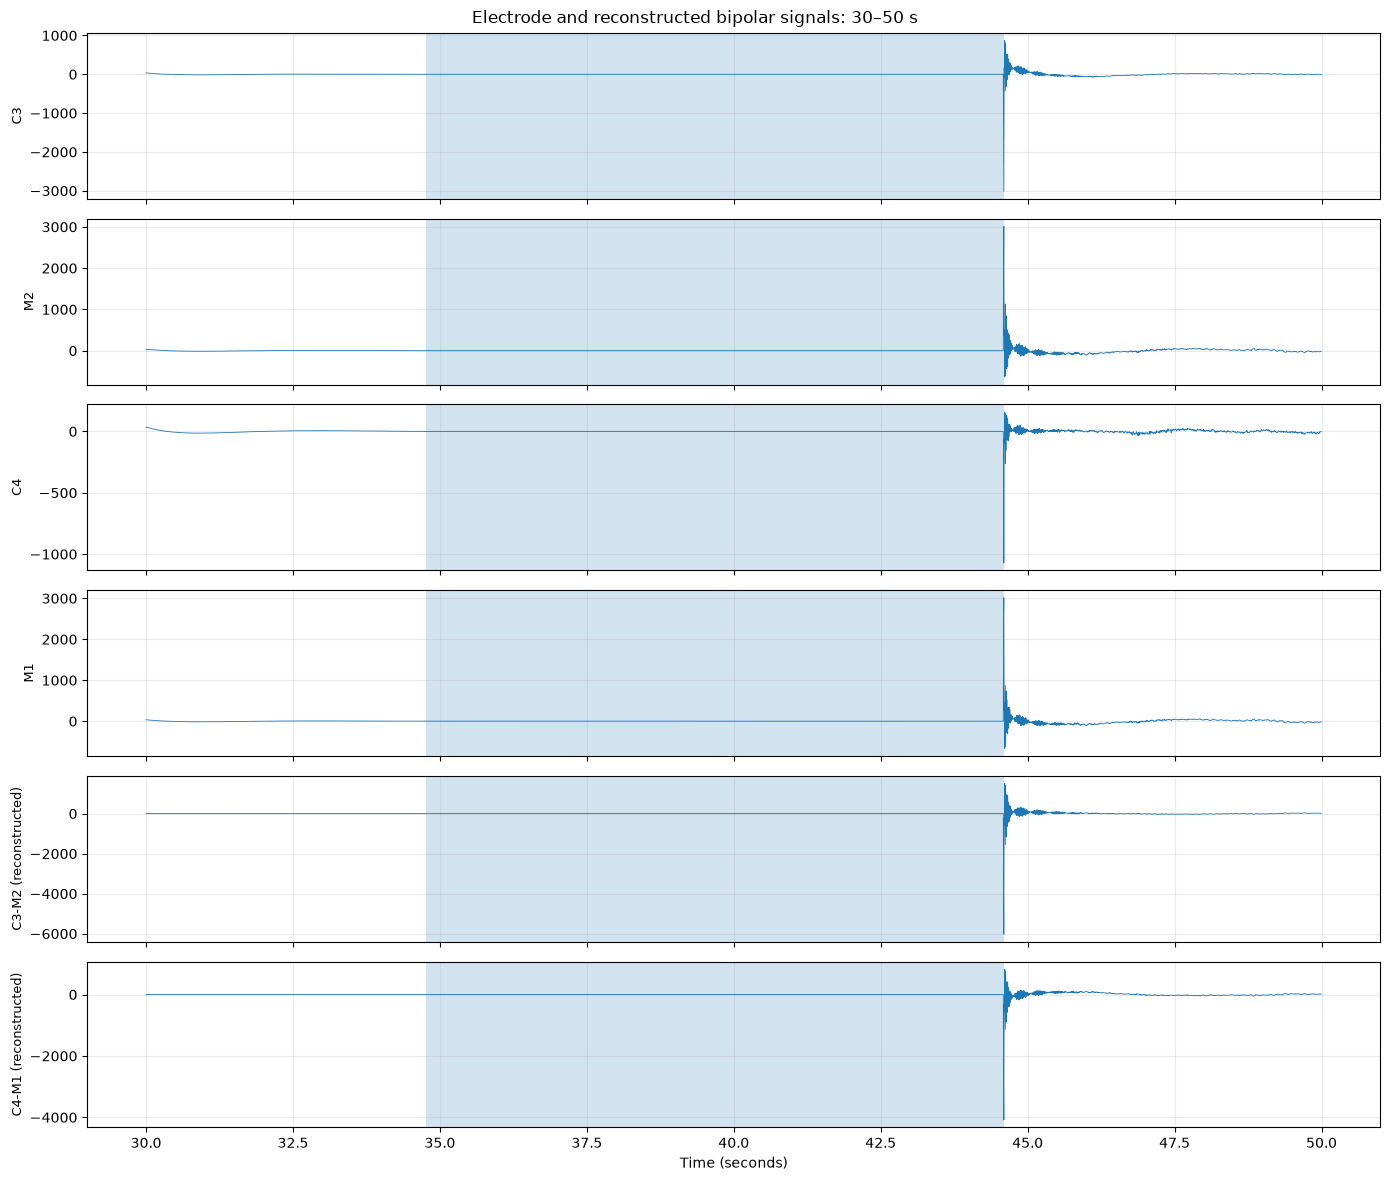

In [206]:
# Plot original electrodes and reconstructed bipolar signals around the zero interval.
import matplotlib.pyplot as plt
import numpy as np
import pyedflib

reader = pyedflib.EdfReader(str(target_file))

try:
    labels = [label.strip() for label in reader.getSignalLabels()]
    fs = 200
    start_sec, end_sec = 30, 50
    start, n = start_sec * fs, (end_sec - start_sec) * fs
    time = start_sec + np.arange(n) / fs

    signals = {}
    for channel in ["C3", "M2", "C4", "M1"]:
        signals[channel] = reader.readSignal(
            labels.index(channel), start=start, n=n
        )

    signals["C3-M2 (reconstructed)"] = signals["C3"] - signals["M2"]
    signals["C4-M1 (reconstructed)"] = signals["C4"] - signals["M1"]

    fig, axes = plt.subplots(6, 1, figsize=(14, 12), sharex=True)

    for ax, (name, signal) in zip(axes, signals.items()):
        ax.plot(time, signal, linewidth=0.6)
        ax.axvspan(34.77, 44.59, alpha=0.2)
        ax.set_ylabel(name, fontsize=9)
        ax.grid(True, alpha=0.25)

    axes[-1].set_xlabel("Time (seconds)")
    fig.suptitle("Electrode and reconstructed bipolar signals: 30–50 s")
    plt.tight_layout()
    plt.show()
finally:
    reader.close()

In [207]:
# Summarize the existing zero-event audit across all 50 pilot recordings.
from pathlib import Path
import pandas as pd

data_dir = Path.cwd() / "data"

files_to_check = [
    "pilot_all_recordings_zero_event_analysis.csv",
    "pilot_zero_event_recording_summary.csv",
    "pilot_zero_events_grouped.csv",
    "pilot_bipolar_zero_audit.csv",
    "pilot_bipolar_zero_audit_review.csv"
]

for filename in files_to_check:
    path = data_dir / filename
    print(f"\n{'=' * 70}\n{filename}")

    if not path.exists():
        print("File not found")
        continue

    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))


pilot_all_recordings_zero_event_analysis.csv
Shape: (50, 21)
Columns: ['SiteID', 'BidsFolder', 'Cognitive_Impairment', 'file_type', 'relative_path', 'expected_size', 'file', 'exists', 'status', 'duration_hours', 'sampling_rate_hz', 'channel_count', 'has_C3_M2', 'has_C4_M1', 'has_F3_M2', 'has_F4_M1', 'has_O1_M2', 'has_O2_M1', 'event_count', 'total_event_seconds', 'event_seconds_pct']
SiteID         BidsFolder  Cognitive_Impairment     file_type                                         relative_path  expected_size                         file  exists   status  duration_hours  sampling_rate_hz  channel_count  has_C3_M2  has_C4_M1  has_F3_M2  has_F4_M1  has_O1_M2  has_O2_M1  event_count  total_event_seconds  event_seconds_pct
 I0002 sub-I0002150027361                 False physiological physiological_data/I0002/sub-I0002150027361_ses-4.edf         967970 sub-I0002150027361_ses-4.edf    True readable        0.040832             200.0             19       True       True       True       Tru

In [208]:
# Summarize zero-event burden by site and cognitive-impairment label.
import pandas as pd
from pathlib import Path

data_dir = Path.cwd() / "data"

df = pd.read_csv(data_dir / "pilot_all_recordings_zero_event_analysis.csv")
review = pd.read_csv(data_dir / "pilot_bipolar_zero_audit_review.csv")

df["Cognitive_Impairment"] = df["Cognitive_Impairment"].astype(str).str.lower().map(
    {"true": True, "false": False}
)

summary = (
    df.groupby(["SiteID", "Cognitive_Impairment"], dropna=False)
    .agg(
        recordings=("BidsFolder", "nunique"),
        recordings_with_events=("event_count", lambda s: (s.fillna(0) > 0).sum()),
        mean_event_seconds_pct=("event_seconds_pct", "mean"),
        median_event_seconds_pct=("event_seconds_pct", "median"),
        max_event_seconds_pct=("event_seconds_pct", "max"),
    )
    .reset_index()
)

print("ZERO-EVENT SUMMARY BY SITE AND LABEL")
display(summary.round(4))

print("\nBIPOLAR AUDIT REVIEW ISSUES")
display(review["issue"].value_counts().rename_axis("issue").reset_index(name="recordings"))

print("\nRECORDINGS WITH STORED BIPOLAR CHANNELS MISSING")
display(review)

ZERO-EVENT SUMMARY BY SITE AND LABEL


,SiteID,Cognitive_Impairment,recordings,recordings_with_events,mean_event_seconds_pct,median_event_seconds_pct,max_event_seconds_pct
0,I0002,False,2,0,0.0000,0.0000,0.0000
1,I0006,False,8,8,0.9357,0.9347,2.0549
2,I0006,True,1,1,1.9984,1.9984,1.9984
3,S0001,False,36,0,0.0000,0.0000,0.0000
4,S0001,True,3,1,0.5505,0.0000,1.6514



BIPOLAR AUDIT REVIEW ISSUES


,issue,recordings
0,"Missing bipolar channels: F3-M2, F4-M1, C3-M2,...",9
1,Missing bipolar channels: C4-M1,1



RECORDINGS WITH STORED BIPOLAR CHANNELS MISSING


,file,issue
0,sub-I0002150028560_ses-1.edf,Missing bipolar channels: C4-M1
1,sub-I0006179001495_ses-1.edf,"Missing bipolar channels: F3-M2, F4-M1, C3-M2,..."
2,sub-I0006179003398_ses-1.edf,"Missing bipolar channels: F3-M2, F4-M1, C3-M2,..."
3,sub-I0006179003402_ses-1.edf,"Missing bipolar channels: F3-M2, F4-M1, C3-M2,..."
4,sub-I0006179007787_ses-1.edf,"Missing bipolar channels: F3-M2, F4-M1, C3-M2,..."
5,sub-I0006179008848_ses-1.edf,"Missing bipolar channels: F3-M2, F4-M1, C3-M2,..."
6,sub-I0006179013670_ses-1.edf,"Missing bipolar channels: F3-M2, F4-M1, C3-M2,..."
7,sub-I0006179014181_ses-1.edf,"Missing bipolar channels: F3-M2, F4-M1, C3-M2,..."
8,sub-I0006179014605_ses-1.edf,"Missing bipolar channels: F3-M2, F4-M1, C3-M2,..."
9,sub-I0006179015691_ses-1.edf,"Missing bipolar channels: F3-M2, F4-M1, C3-M2,..."


In [209]:
# Inspect channel labels and sampling rates for the three pilot sites.
from pathlib import Path
import pandas as pd
import pyedflib

data_dir = Path.cwd() / "data"
audit = pd.read_csv(data_dir / "pilot_all_recordings_zero_event_analysis.csv")

for site in ["I0002", "I0006", "S0001"]:
    row = audit[audit["SiteID"] == site].iloc[0]
    path = data_dir / "pilot_downloads" / row["relative_path"]

    print(f"\n--- Site: {site} | File: {path.name} ---")

    reader = pyedflib.EdfReader(str(path))
    try:
        for i, label in enumerate(reader.getSignalLabels()):
            label = label.strip()
            if any(token in label.upper() for token in
                   ["C3", "C4", "M1", "M2", "F3", "F4", "O1", "O2"]):
                print({
                    "channel": label,
                    "sample_rate_hz": reader.getSampleFrequency(i),
                    "physical_dimension": reader.getPhysicalDimension(i)
                })
    finally:
        reader.close()


--- Site: I0002 | File: sub-I0002150027361_ses-4.edf ---
{'channel': 'F3-M2', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'F4-M1', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'C3-M2', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'C4-M1', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'O1-M2', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'O2-M1', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'SaO2', 'sample_rate_hz': 25.0, 'physical_dimension': '%'}

--- Site: I0006 | File: sub-I0006179001495_ses-1.edf ---
{'channel': 'M1', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'C3', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'M2', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'C4', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'O2', 'sample_rate_hz': 200.0, 'physical_dimension': 'uV'}
{'channel': 'O

In [210]:
# Validate availability of six standard EEG derivations across the pilot cohort.
from pathlib import Path
import pandas as pd
import pyedflib

data_dir = Path.cwd() / "data"
audit = pd.read_csv(data_dir / "pilot_all_recordings_zero_event_analysis.csv")

derivations = {
    "F3-M2": ("F3", "M2"),
    "F4-M1": ("F4", "M1"),
    "C3-M2": ("C3", "M2"),
    "C4-M1": ("C4", "M1"),
    "O1-M2": ("O1", "M2"),
    "O2-M1": ("O2", "M1"),
}

rows = []

for _, row in audit.iterrows():
    path = data_dir / "pilot_downloads" / row["relative_path"]

    if not path.exists():
        # Fall back to the already discovered EDF file list.
        matches = [p for p in edf_files if p.name == row["file"]]
        if not matches:
            rows.append({
                "file": row["file"],
                "site": row["SiteID"],
                "status": "FILE_NOT_FOUND"
            })
            continue
        path = matches[0]

    reader = pyedflib.EdfReader(str(path))
    try:
        labels = [label.strip() for label in reader.getSignalLabels()]
        label_set = set(labels)

        result = {
            "file": path.name,
            "site": row["SiteID"],
            "status": "OK"
        }

        for derivation, (positive, negative) in derivations.items():
            if derivation in label_set:
                idx = labels.index(derivation)
                fs = reader.getSampleFrequency(idx)
                unit = reader.getPhysicalDimension(idx).strip()
                result[derivation] = (
                    "stored" if fs == 200 and unit.lower() == "uv"
                    else f"stored_check_metadata({fs}Hz,{unit})"
                )
            elif positive in label_set and negative in label_set:
                result[derivation] = "reconstruct_from_electrodes"
            else:
                result[derivation] = "unavailable"

        rows.append(result)
    finally:
        reader.close()

mapping_audit = pd.DataFrame(rows)
out_path = data_dir / "pilot_eeg_channel_mapping_audit.csv"
mapping_audit.to_csv(out_path, index=False)

print("Saved:", out_path)
print("\nMapping status counts:")
for derivation in derivations:
    print(f"\n{derivation}")
    print(mapping_audit[derivation].value_counts(dropna=False).to_string())

print("\nFirst five rows:")
display(mapping_audit.head())

Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_eeg_channel_mapping_audit.csv

Mapping status counts:

F3-M2
F3-M2
stored                               39
reconstruct_from_electrodes           9
stored_check_metadata(500.0Hz,uV)     1
stored_check_metadata(512.0Hz,uV)     1

F4-M1
F4-M1
stored                               39
reconstruct_from_electrodes           9
stored_check_metadata(500.0Hz,uV)     1
stored_check_metadata(512.0Hz,uV)     1

C3-M2
C3-M2
stored                               39
reconstruct_from_electrodes           9
stored_check_metadata(500.0Hz,uV)     1
stored_check_metadata(512.0Hz,uV)     1

C4-M1
C4-M1
stored                               39
reconstruct_from_electrodes           9
unavailable                           1
stored_check_metadata(512.0Hz,uV)     1

O1-M2
O1-M2
stored                               39
reconstruct_from_electrodes           9
stored_check_metadata(500.0Hz,uV)     1
stored_check_metadata(512.0Hz,uV)     1

O2-M1
O2-M1
stored          

,file,site,status,F3-M2,F4-M1,C3-M2,C4-M1,O1-M2,O2-M1
0,sub-I0002150027361_ses-4.edf,I0002,OK,stored,stored,stored,stored,stored,stored
1,sub-I0002150028560_ses-1.edf,I0002,OK,"stored_check_metadata(500.0Hz,uV)","stored_check_metadata(500.0Hz,uV)","stored_check_metadata(500.0Hz,uV)",unavailable,"stored_check_metadata(500.0Hz,uV)",unavailable
2,sub-I0006179001495_ses-1.edf,I0006,OK,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes
3,sub-I0006179003398_ses-1.edf,I0006,OK,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes
4,sub-I0006179003402_ses-1.edf,I0006,OK,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes,reconstruct_from_electrodes


In [211]:
# Summarize EEG channel availability and identify recordings needing special handling.
import pandas as pd
from pathlib import Path

data_dir = Path.cwd() / "data"
mapping = pd.read_csv(data_dir / "pilot_eeg_channel_mapping_audit.csv")

derivations = ["F3-M2", "F4-M1", "C3-M2", "C4-M1", "O1-M2", "O2-M1"]

def classify_recording(row):
    statuses = [str(row[col]) for col in derivations]

    if any(s == "unavailable" for s in statuses):
        return "review_missing_derivation"
    if any(s.startswith("stored_check_metadata") for s in statuses):
        return "review_sampling_rate"
    if any(s == "reconstruct_from_electrodes" for s in statuses):
        return "reconstruct_bipolar"
    return "stored_bipolar_ready"

mapping["mapping_class"] = mapping.apply(classify_recording, axis=1)

print("Recording counts by mapping class:")
display(
    mapping.groupby(["site", "mapping_class"])
    .size()
    .reset_index(name="recordings")
)

print("\nRecordings requiring review:")
display(
    mapping.loc[
        mapping["mapping_class"].isin(
            ["review_missing_derivation", "review_sampling_rate"]
        ),
        ["file", "site", "mapping_class"] + derivations
    ]
)

print("\nSaved audit:", data_dir / "pilot_eeg_channel_mapping_audit.csv")

Recording counts by mapping class:


,site,mapping_class,recordings
0,I0002,review_missing_derivation,1
1,I0002,stored_bipolar_ready,1
2,I0006,reconstruct_bipolar,9
3,S0001,review_sampling_rate,1
4,S0001,stored_bipolar_ready,38



Recordings requiring review:


,file,site,mapping_class,F3-M2,F4-M1,C3-M2,C4-M1,O1-M2,O2-M1
1,sub-I0002150028560_ses-1.edf,I0002,review_missing_derivation,"stored_check_metadata(500.0Hz,uV)","stored_check_metadata(500.0Hz,uV)","stored_check_metadata(500.0Hz,uV)",unavailable,"stored_check_metadata(500.0Hz,uV)",unavailable
49,sub-S0001120440759_ses-3.edf,S0001,review_sampling_rate,"stored_check_metadata(512.0Hz,uV)","stored_check_metadata(512.0Hz,uV)","stored_check_metadata(512.0Hz,uV)","stored_check_metadata(512.0Hz,uV)","stored_check_metadata(512.0Hz,uV)","stored_check_metadata(512.0Hz,uV)"



Saved audit: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_eeg_channel_mapping_audit.csv



# Progress Report: Sleep-Based AI Dementia Shortcut Audit

## 1. Research Objective

**Title:** Do Sleep-Based AI Models Really Predict Dementia? Auditing Shortcut Effects in a Multi-Hospital Sleep Study Dataset

The objective is to investigate whether models predicting the dataset's `Cognitive_Impairment` label learn meaningful physiological sleep signals or exploit shortcuts such as missingness, acquisition site, recording metadata, and signal-quality artifacts.

The target label is `Cognitive_Impairment`; it should not automatically be interpreted as a confirmed dementia diagnosis.

## 2. Dataset Inspection and Initial Baselines

The demographics dataset contains 1,103 records and 14 columns.

- Negative labels: 1,019
- Positive labels: 84
- Positive-label prevalence: approximately 7.62%
- BMI has substantial missingness, with only 266 non-null values.

Initial exploratory models using demographic features produced:

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.7029 | 0.1325 | 0.5238 | 0.2115 | 0.7044 |
| Random Forest | 0.7862 | 0.1833 | 0.5238 | 0.2716 | 0.7346 |

These are exploratory results. The test set contained only 21 positive cases, so estimates are uncertain.

### Initial shortcut-related observations

- `Time_to_Event` missingness perfectly matched the target in this dataset and must not be used as a predictor.
- Creation year alone achieved a ROC-AUC of approximately 0.6725.
- Site-only performance was weak in the initial baseline, with ROC-AUC approximately 0.5195.
- Follow-up time and data-collection timing differ between label groups and require careful interpretation.

These findings motivate further shortcut auditing; they do not establish that a model is using any particular shortcut.

## 3. Pilot EDF Cohort

A pilot cohort of 50 physiological EDF recordings was downloaded and checked for readability. Corresponding human-annotation EDF files were also downloaded.

The pilot label distribution is:

- Negative: 46 recordings
- Positive: 4 recordings

The cohort includes three sites: I0002, I0006, and S0001. Label counts differ substantially by site, making site-related confounding an important consideration.

The pilot is intended for pipeline development and preliminary analysis, not definitive clinical conclusions.

## 4. Recording Duration and Channel Availability

The initial EDF audit found:

- All 50 physiological recordings were readable.
- Two recordings were shorter than six hours.
- Ten recordings lacked at least one of the six expected stored bipolar channel labels.
- Nine I0006 recordings contained standalone electrodes from which bipolar channels may be reconstructed.
- One I0002 recording lacked two expected derivations and requires special handling.

A missing stored bipolar channel does not necessarily mean the underlying electrode data are absent. Recordings should not be silently excluded solely because channel naming or representation differs.

The six target derivations are:

- F3-M2
- F4-M1
- C3-M2
- C4-M1
- O1-M2
- O2-M1

## 5. Signal-Quality and Zero-Run Investigation

A raw digital-sample audit searched for consecutive zero-valued runs lasting at least one second in standalone C3, C4, M1, and M2 channels.

The audit identified:

- 150 channel-level zero runs.
- 40 grouped temporal events across 10 recordings.
- 35 grouped events affecting C3, C4, M1, and M2.
- Five grouped events affecting M1 and M2.

The longest grouped event lasted approximately 314.48 seconds.

Zero-event burden was concentrated in the pilot's I0006 recordings:

| Site | Label | Recordings | Recordings with events | Mean event duration (% of recording) |
|---|---|---:|---:|---:|
| I0002 | Negative | 2 | 0 | 0.0000% |
| I0006 | Negative | 8 | 8 | 0.9357% |
| I0006 | Positive | 1 | 1 | 1.9984% |
| S0001 | Negative | 36 | 0 | 0.0000% |
| S0001 | Positive | 3 | 1 | 0.5505% |

This pattern suggests a possible site-associated difference in the observed signal-quality events. However, the pilot is small and imbalanced, and the result does not establish a causal mechanism or demonstrate that the artifacts predict cognitive impairment.

### Reconstruction check

For `sub-I0006179001495_ses-1.edf`, the stored channels were standalone electrodes rather than precomputed bipolar derivations.

The signals C3-M2 and C4-M1 were reconstructed by subtracting the corresponding physical electrode signals. In the previously identified interval from approximately 34.77 to 44.59 seconds, both reconstructed derivations were zero throughout the interval.

A plot of the four original electrodes and two reconstructed derivations confirmed the synchronized zero interval and a transient near its end. This supports the presence of a signal-quality event, but its underlying cause remains unconfirmed.

## 6. Channel-Mapping Audit

The mapping audit was saved as:

`data/pilot_eeg_channel_mapping_audit.csv`

The 50 recordings were classified as follows:

| Mapping class | Site | Recordings |
|---|---|---:|
| Stored bipolar ready | I0002 | 1 |
| Review missing derivation | I0002 | 1 |
| Reconstruct bipolar | I0006 | 9 |
| Stored bipolar ready | S0001 | 38 |
| Review sampling rate | S0001 | 1 |

In total:

- 39 recordings have the six expected bipolar channels stored.
- Nine recordings can potentially reconstruct these derivations from standalone electrodes.
- One recording requires review because C4-M1 and O2-M1 are unavailable in the inspected channel representation.
- One recording uses 512 Hz rather than the more common 200 Hz sampling rate.

The audit also encountered a 500 Hz recording. Its derivation availability differs, so it requires explicit handling rather than automatic exclusion.

The mapping classification is a preliminary technical audit, not a final clinical-quality eligibility decision.

## 7. Current Research Status

Completed so far:

1. Demographic dataset inspection and exploratory baseline modelling.
2. Identification of target-associated missingness leakage.
3. Selection and download of a 50-recording pilot cohort.
4. EDF readability, duration, and channel-availability checks.
5. Initial zero-run detection and event grouping.
6. Visual inspection of a confirmed synchronized zero interval.
7. Preliminary site-wise comparison of zero-event burden.
8. Channel-mapping audit for stored and reconstructable bipolar EEG derivations.

## 8. Next Steps

1. Finalize a consistent channel-loading and reconstruction procedure.
2. Verify channel units, sample rates, and signal conventions before resampling.
3. Inspect the annotation format and validate sleep-stage label interpretation.
4. Extract EEG features and signal-quality metrics using documented processing rules.
5. Build a patient-level feature table while retaining missingness and quality indicators.
6. Compare demographic-only, metadata-only, site-only, quality-only, and EEG-based models.
7. Use patient-level evaluation splits and suitable metrics for class imbalance.
8. Conduct sensitivity analyses to assess whether conclusions depend on site, channel availability, or quality filtering.
9. Report uncertainty and limitations, then prepare the term paper with reproducible results.

## 9. Important Limitations

- Only 50 recordings have been used for the current pilot audit.
- There are only four positive-label recordings in the pilot.
- Site and label distributions are imbalanced.
- A zero-valued signal interval is evidence of an unusual signal pattern, but not proof of a specific hardware failure.
- Reconstructed bipolar derivations must be checked for consistent channel conventions and units.
- The initial baseline metrics are exploratory and must not be presented as definitive clinical performance.
- No claim that sleep EEG predicts dementia should be made until the planned experiments have been completed and independently evaluated.

**Current milestone:** Pilot data inspection and preliminary signal-quality auditing are substantially complete. The next major stage is validated feature extraction followed by systematic shortcut experiments.


In [212]:
# Load the existing pilot files and verify the columns needed for EEG feature extraction.
from pathlib import Path
import pandas as pd

data_dir = Path.cwd() / "data"

files_to_check = [
    "pilot_cohort_50.csv",
    "pilot_eeg_channel_mapping_audit.csv",
    "pilot_eeg_merged_qc_audit.csv",
]

for filename in files_to_check:
    path = data_dir / filename
    print(f"\n{'=' * 70}\n{filename}")
    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(2).to_string(index=False))
    else:
        print("FILE NOT FOUND:", path)


pilot_cohort_50.csv
Shape: (50, 23)
Columns: ['SiteID', 'BDSPPatientID', 'CreationTime', 'BidsFolder', 'SessionID', 'Age', 'Sex', 'Race', 'Ethnicity', 'BMI', 'Time_to_Event', 'Cognitive_Impairment', 'Last_Known_Visit_Date', 'Time_to_Last_Visit', 'has_physiological', 'has_human_annotation', 'has_algorithmic_annotation', 'phys_path', 'human_path', 'algo_path', 'phys_path_in_inventory', 'human_path_in_inventory', 'algo_path_in_inventory']
SiteID  BDSPPatientID        CreationTime         BidsFolder  SessionID  Age    Sex  Race    Ethnicity   BMI  Time_to_Event  Cognitive_Impairment Last_Known_Visit_Date  Time_to_Last_Visit  has_physiological  has_human_annotation  has_algorithmic_annotation                                             phys_path                                                              human_path                                                                    algo_path  phys_path_in_inventory  human_path_in_inventory  algo_path_in_inventory
 I0002      150027361 2017

In [213]:
# Inspect one verified 200 Hz EDF recording before building the feature extractor.
from pathlib import Path
import pandas as pd
import pyedflib

data_dir = Path.cwd() / "data"
qc = pd.read_csv(data_dir / "pilot_eeg_merged_qc_audit.csv")

candidate = qc[
    (qc["file_type"] == "physiological") &
    (qc["exists"] == True) &
    (qc["sampling_rate_hz"] == 200)
].iloc[0]

edf_path = next(
    (data_dir / "pilot_downloads").rglob(candidate["file"]),
    None
)

print("Selected recording:", candidate["file"])
print("Site:", candidate["SiteID"])
print("Target:", candidate["Cognitive_Impairment"])
print("Resolved path:", edf_path)

if edf_path is None:
    print("Recording not found under pilot_downloads.")
else:
    reader = pyedflib.EdfReader(str(edf_path))
    try:
        print(f"\nDuration: {reader.getFileDuration() / 3600:.2f} hours")
        print("Number of channels:", reader.signals_in_file)
        print("\nChannel metadata:")

        for i in range(reader.signals_in_file):
            print({
                "label": reader.getLabel(i),
                "sample_rate": reader.getSampleFrequency(i),
                "unit": reader.getPhysicalDimension(i),
                "samples": reader.getNSamples()[i],
            })
    finally:
        reader.close()

Selected recording: sub-I0002150027361_ses-4.edf
Site: I0002
Target: False
Resolved path: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_downloads\physiological_data\I0002\sub-I0002150027361_ses-4.edf

Duration: 0.04 hours
Number of channels: 19

Channel metadata:
{'label': 'F3-M2', 'sample_rate': 200.0, 'unit': 'uV', 'samples': np.int64(29400)}
{'label': 'F4-M1', 'sample_rate': 200.0, 'unit': 'uV', 'samples': np.int64(29400)}
{'label': 'C3-M2', 'sample_rate': 200.0, 'unit': 'uV', 'samples': np.int64(29400)}
{'label': 'C4-M1', 'sample_rate': 200.0, 'unit': 'uV', 'samples': np.int64(29400)}
{'label': 'O1-M2', 'sample_rate': 200.0, 'unit': 'uV', 'samples': np.int64(29400)}
{'label': 'O2-M1', 'sample_rate': 200.0, 'unit': 'uV', 'samples': np.int64(29400)}
{'label': 'E1', 'sample_rate': 200.0, 'unit': 'uV', 'samples': np.int64(29400)}
{'label': 'E2', 'sample_rate': 200.0, 'unit': 'uV', 'samples': np.int64(29400)}
{'label': 'CHIN', 'sample_rate': 200.0, 'unit': 'uV', 'samples': np.int64(29400

In [214]:
# Test EEG signal quality and frequency-band features on the inspected recording.
import numpy as np
import pandas as pd
import pyedflib
from scipy.signal import welch

eeg_channels = ["F3-M2", "F4-M1", "C3-M2", "C4-M1", "O1-M2", "O2-M1"]
bands = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 12),
    "sigma": (12, 16),
    "beta":  (16, 30),
}

rows = []
reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]

    for channel in eeg_channels:
        if channel not in labels:
            print(f"Skipping unavailable channel: {channel}")
            continue

        idx = labels.index(channel)
        fs = float(reader.getSampleFrequency(idx))
        unit = reader.getPhysicalDimension(idx).strip()
        signal_uv = np.asarray(reader.readSignal(idx), dtype=float)

        # PSD requires the signal in microvolts for consistent feature units.
        if unit.lower() in {"uv", "µv", "μv"}:
            signal_uv = signal_uv
        else:
            print(f"Skipping {channel}: unexpected physical unit {unit!r}")
            continue

        signal_uv = signal_uv[np.isfinite(signal_uv)]
        if len(signal_uv) < int(fs * 10):
            print(f"Skipping {channel}: insufficient valid samples")
            continue

        freqs, psd = welch(
            signal_uv,
            fs=fs,
            nperseg=min(len(signal_uv), int(fs * 30))
        )

        row = {
            "channel": channel,
            "sampling_rate_hz": fs,
            "duration_seconds": len(signal_uv) / fs,
            "mean_uv": np.mean(signal_uv),
            "std_uv": np.std(signal_uv),
            "peak_abs_uv": np.max(np.abs(signal_uv)),
            "zero_fraction": np.mean(signal_uv == 0),
        }

        for band_name, (low, high) in bands.items():
            mask = (freqs >= low) & (freqs < high)
            row[f"{band_name}_power_uv2"] = (
                np.trapezoid(psd[mask], freqs[mask])
                if mask.sum() >= 2 else np.nan
            )

        rows.append(row)
finally:
    reader.close()

feature_test = pd.DataFrame(rows)
display(feature_test.round(4))

print("Channels processed:", len(feature_test))
print("Recording duration (seconds):", feature_test["duration_seconds"].max()
      if not feature_test.empty else "No channels processed")

,channel,sampling_rate_hz,duration_seconds,mean_uv,std_uv,peak_abs_uv,zero_fraction,delta_power_uv2,theta_power_uv2,alpha_power_uv2,sigma_power_uv2,beta_power_uv2
0,F3-M2,200.0,147.0,0.0105,2.0866,14.0,0.3763,2.1684,0.4662,0.2402,0.1572,0.4985
1,F4-M1,200.0,147.0,-0.0095,2.5085,14.0,0.3166,2.8806,0.6196,0.3045,0.1906,1.1862
2,C3-M2,200.0,147.0,0.0052,1.7196,8.0,0.4634,1.4167,0.2886,0.1350,0.0994,0.3063
3,C4-M1,200.0,147.0,-0.0008,2.3296,14.0,0.3396,2.6986,0.6036,0.2605,0.1805,0.7431
4,O1-M2,200.0,147.0,0.0003,2.0889,8.0,0.3790,2.1751,0.5213,0.2221,0.1421,0.4668
5,O2-M1,200.0,147.0,-0.0031,2.2112,14.0,0.3655,2.4847,0.4847,0.2442,0.1479,0.6738


Channels processed: 6
Recording duration (seconds): 147.0


In [215]:
# Extract EEG frequency-band features separately from each 30-second epoch.
import numpy as np
import pandas as pd
import pyedflib
from scipy.signal import welch

epoch_seconds = 30
epoch_rows = []

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]

    for channel in eeg_channels:
        if channel not in labels:
            continue

        idx = labels.index(channel)
        fs = float(reader.getSampleFrequency(idx))
        unit = reader.getPhysicalDimension(idx).strip()

        if unit.lower() not in {"uv", "µv", "μv"}:
            print(f"Skipping {channel}: unexpected unit {unit!r}")
            continue

        signal_uv = np.asarray(reader.readSignal(idx), dtype=float)
        samples_per_epoch = int(fs * epoch_seconds)
        n_epochs = len(signal_uv) // samples_per_epoch

        for epoch_idx in range(n_epochs):
            segment = signal_uv[
                epoch_idx * samples_per_epoch:
                (epoch_idx + 1) * samples_per_epoch
            ]

            if not np.isfinite(segment).all():
                continue

            freqs, psd = welch(
                segment,
                fs=fs,
                nperseg=min(len(segment), int(fs * 10))
            )

            row = {
                "channel": channel,
                "epoch": epoch_idx,
                "start_seconds": epoch_idx * epoch_seconds,
                "std_uv": np.std(segment),
                "peak_abs_uv": np.max(np.abs(segment)),
                "zero_fraction": np.mean(segment == 0),
            }

            for band_name, (low, high) in bands.items():
                mask = (freqs >= low) & (freqs < high)
                row[f"{band_name}_power_uv2"] = (
                    np.trapezoid(psd[mask], freqs[mask])
                    if mask.sum() >= 2 else np.nan
                )

            epoch_rows.append(row)
finally:
    reader.close()

epoch_features_test = pd.DataFrame(epoch_rows)

print("Epoch-feature table shape:", epoch_features_test.shape)
print("Unique epochs:", epoch_features_test["epoch"].nunique())
print("Channels:", epoch_features_test["channel"].nunique())
display(epoch_features_test.head(10).round(4))

Epoch-feature table shape: (24, 11)
Unique epochs: 4
Channels: 6


,channel,epoch,start_seconds,std_uv,peak_abs_uv,zero_fraction,delta_power_uv2,theta_power_uv2,alpha_power_uv2,sigma_power_uv2,beta_power_uv2
0,F3-M2,0,0,2.1902,14.0,0.3563,2.1255,0.6005,0.2346,0.1430,0.4539
1,F3-M2,1,30,2.0602,6.0,0.3803,2.0635,0.4263,0.2514,0.1357,0.4885
2,F3-M2,2,60,2.0717,8.0,0.3755,2.2014,0.4758,0.2301,0.1655,0.4611
3,F3-M2,3,90,2.0874,8.0,0.3778,2.0489,0.3584,0.2261,0.1645,0.5418
4,F4-M1,0,0,2.5080,14.0,0.3265,3.0445,0.6575,0.2859,0.1581,1.0759
5,F4-M1,1,30,2.4775,8.0,0.3130,2.6500,0.6084,0.3044,0.1908,1.1443
6,F4-M1,2,60,2.5988,10.0,0.3008,3.0365,0.5649,0.3148,0.1802,1.2040
7,F4-M1,3,90,2.4504,8.0,0.3305,2.5761,0.6097,0.2941,0.1783,1.1952
8,C3-M2,0,0,1.6749,8.0,0.4605,1.1744,0.2730,0.1394,0.0971,0.2845
9,C3-M2,1,30,1.7211,6.0,0.4770,1.5048,0.2804,0.1352,0.1156,0.2945


In [216]:
# Verify epoch feature columns, data types, missing values, and numeric ranges.
print("Columns:", epoch_features_test.columns.tolist())
print("\nData types:")
print(epoch_features_test.dtypes)

print("\nMissing values:")
print(epoch_features_test.isna().sum())

numeric_cols = epoch_features_test.select_dtypes(include="number").columns
print("\nNumeric summary:")
display(epoch_features_test[numeric_cols].describe().round(4))

print("\nExpected row count:", 6 * 4)
print("Actual row count:", len(epoch_features_test))
print("Unique channel-epoch pairs:",
      epoch_features_test[["channel", "epoch"]].drop_duplicates().shape[0])

Columns: ['channel', 'epoch', 'start_seconds', 'std_uv', 'peak_abs_uv', 'zero_fraction', 'delta_power_uv2', 'theta_power_uv2', 'alpha_power_uv2', 'sigma_power_uv2', 'beta_power_uv2']

Data types:
channel                str
epoch                int64
start_seconds        int64
std_uv             float64
peak_abs_uv        float64
zero_fraction      float64
delta_power_uv2    float64
theta_power_uv2    float64
alpha_power_uv2    float64
sigma_power_uv2    float64
beta_power_uv2     float64
dtype: object

Missing values:
channel            0
epoch              0
start_seconds      0
std_uv             0
peak_abs_uv        0
zero_fraction      0
delta_power_uv2    0
theta_power_uv2    0
alpha_power_uv2    0
sigma_power_uv2    0
beta_power_uv2     0
dtype: int64

Numeric summary:


,epoch,start_seconds,std_uv,peak_abs_uv,zero_fraction,delta_power_uv2,theta_power_uv2,alpha_power_uv2,sigma_power_uv2,beta_power_uv2
count,24.0000,24.0000,24.0000,24.0000,24.0000,24.0000,24.0000,24.0000,24.0000,24.0000
mean,1.5000,45.0000,2.1656,8.8333,0.3711,2.2619,0.4887,0.2365,0.1505,0.6301
std,1.1421,34.2624,0.2551,2.6320,0.0464,0.5452,0.1223,0.0573,0.0300,0.2824
min,0.0000,0.0000,1.6749,6.0000,0.3008,1.1744,0.2654,0.1318,0.0904,0.2827
25%,0.7500,22.5000,2.0688,8.0000,0.3409,2.0461,0.4311,0.2056,0.1359,0.4398
50%,1.5000,45.0000,2.1751,8.0000,0.3667,2.1878,0.5152,0.2388,0.1574,0.5877
75%,2.2500,67.5000,2.3391,10.0000,0.3785,2.6632,0.5828,0.2794,0.1680,0.7415
max,3.0000,90.0000,2.5988,14.0000,0.4770,3.1005,0.6575,0.3148,0.1993,1.2040



Expected row count: 24
Actual row count: 24
Unique channel-epoch pairs: 24


In [217]:
# Check actual epoch feature values and validate the zero fraction range.
cols_to_check = [
    "channel", "epoch", "std_uv", "peak_abs_uv", "zero_fraction",
    "delta_power_uv2", "theta_power_uv2", "alpha_power_uv2",
    "sigma_power_uv2", "beta_power_uv2"
]

display(epoch_features_test[cols_to_check].head(12).to_string(index=False))

print("zero_fraction minimum:", epoch_features_test["zero_fraction"].min())
print("zero_fraction maximum:", epoch_features_test["zero_fraction"].max())
print(
    "All zero fractions in [0, 1]:",
    epoch_features_test["zero_fraction"].between(0, 1).all()
)

'channel  epoch   std_uv  peak_abs_uv  zero_fraction  delta_power_uv2  theta_power_uv2  alpha_power_uv2  sigma_power_uv2  beta_power_uv2\n  F3-M2      0 2.190237         14.0       0.356333         2.125469         0.600491         0.234578         0.142989        0.453866\n  F3-M2      1 2.060172          6.0       0.380333         2.063475         0.426260         0.251352         0.135714        0.488537\n  F3-M2      2 2.071713          8.0       0.375500         2.201355         0.475797         0.230113         0.165497        0.461077\n  F3-M2      3 2.087443          8.0       0.377833         2.048859         0.358432         0.226095         0.164468        0.541762\n  F4-M1      0 2.507973         14.0       0.326500         3.044506         0.657549         0.285934         0.158095        1.075851\n  F4-M1      1 2.477482          8.0       0.313000         2.649959         0.608449         0.304355         0.190820        1.144283\n  F4-M1      2 2.598844         10.0    

zero_fraction minimum: 0.30083333333333334
zero_fraction maximum: 0.477
All zero fractions in [0, 1]: True


In [218]:
# Verify the exact-zero proportion directly from the raw EEG signal.
import numpy as np
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))
try:
    labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]
    for channel in ["F3-M2", "F4-M1", "C3-M2"]:
        if channel in labels:
            signal = np.asarray(reader.readSignal(labels.index(channel)))
            print(
                channel,
                "| samples:", len(signal),
                "| exact zeros:", np.count_nonzero(signal == 0),
                "| zero fraction:", round(np.mean(signal == 0), 6)
            )
finally:
    reader.close()

F3-M2 | samples: 29400 | exact zeros: 11062 | zero fraction: 0.376259
F4-M1 | samples: 29400 | exact zeros: 9309 | zero fraction: 0.316633
C3-M2 | samples: 29400 | exact zeros: 13623 | zero fraction: 0.463367


In [219]:
# Locate consecutive zero runs to distinguish long signal dropouts from scattered zero samples.
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))
zero_run_rows = []

try:
    labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]

    for channel in ["F3-M2", "F4-M1", "C3-M2"]:
        if channel not in labels:
            continue

        idx = labels.index(channel)
        fs = float(reader.getSampleFrequency(idx))
        signal = np.asarray(reader.readSignal(idx), dtype=float)
        zero_mask = (signal == 0)

        edges = np.diff(np.r_[False, zero_mask, False].astype(int))
        starts = np.where(edges == 1)[0]
        ends = np.where(edges == -1)[0]

        runs = [
            (int(start), int(end), (end - start) / fs)
            for start, end in zip(starts, ends)
        ]
        long_runs = [run for run in runs if run[2] >= 1.0]

        zero_run_rows.append({
            "channel": channel,
            "zero_fraction": zero_mask.mean(),
            "number_of_zero_runs": len(runs),
            "runs_at_least_1s": len(long_runs),
            "longest_zero_run_seconds": max((r[2] for r in runs), default=0),
            "first_zero_run_seconds": (
                (runs[0][0] / fs, runs[0][1] / fs, runs[0][2])
                if runs else None
            ),
        })
finally:
    reader.close()

display(pd.DataFrame(zero_run_rows).round(4))

,channel,zero_fraction,number_of_zero_runs,runs_at_least_1s,longest_zero_run_seconds,first_zero_run_seconds
0,F3-M2,0.3763,2734,0,0.11,"(0.015, 0.02, 0.005)"
1,F4-M1,0.3166,3787,0,0.09,"(0.0, 0.005, 0.005)"
2,C3-M2,0.4634,2671,0,0.17,"(0.015, 0.02, 0.005)"


In [220]:
# Inspect raw EEG sample values to investigate the unusually high exact-zero fraction.
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]

    for channel in ["F3-M2", "F4-M1", "C3-M2"]:
        if channel not in labels:
            continue

        idx = labels.index(channel)
        signal = np.asarray(reader.readSignal(idx), dtype=float)
        first_samples = signal[:40]

        print(f"\n{channel}")
        print("First 40 samples:", first_samples.tolist())
        print("Unique values in first 30 seconds:",
              np.unique(signal[:int(reader.getSampleFrequency(idx) * 30)]).size)
        print("Minimum:", signal.min(), "| Maximum:", signal.max())
        print("Exact zeros:", np.count_nonzero(signal == 0))
finally:
    reader.close()


F3-M2
First 40 samples: [-4.0, -14.0, -14.0, 0.0, 6.0, 0.0, 0.0, 2.0, 4.0, 2.0, 0.0, 0.0, 2.0, -2.0, 0.0, 2.0, 0.0, -2.0, 2.0, 0.0, -2.0, -2.0, 0.0, -2.0, -2.0, 0.0, 2.0, 2.0, 2.0, 2.0, 0.0, 2.0, 2.0, 0.0, 0.0, 0.0, 0.0, 2.0, 4.0, 4.0]
Unique values in first 30 seconds: 8
Minimum: -14.0 | Maximum: 8.0
Exact zeros: 11062

F4-M1
First 40 samples: [0.0, 6.0, 14.0, 2.0, -8.0, -2.0, 0.0, -4.0, -8.0, -8.0, -4.0, -4.0, -4.0, -2.0, -2.0, -4.0, -2.0, 0.0, -2.0, -6.0, -2.0, 0.0, -2.0, 0.0, 0.0, -2.0, -2.0, 0.0, -2.0, -4.0, -2.0, 0.0, 2.0, 2.0, 0.0, 2.0, 0.0, 0.0, 0.0, -2.0]
Unique values in first 30 seconds: 11
Minimum: -10.0 | Maximum: 14.0
Exact zeros: 9309

C3-M2
First 40 samples: [-2.0, -6.0, -8.0, 0.0, 4.0, 0.0, 0.0, 2.0, 4.0, 2.0, 2.0, 4.0, 4.0, 2.0, 2.0, 4.0, 4.0, 2.0, 4.0, 4.0, 2.0, 2.0, 4.0, 2.0, 2.0, 4.0, 4.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 4.0, 4.0]
Unique values in first 30 seconds: 7
Minimum: -8.0 | Maximum: 8.0
Exact zeros: 13623


In [221]:
# Check the signal's value distribution and whether samples follow a 2 µV grid.
for channel in ["F3-M2", "F4-M1", "C3-M2"]:
    if channel not in labels:
        continue

    idx = labels.index(channel)
    signal = np.asarray(reader.readSignal(idx), dtype=float)

    values, counts = np.unique(signal, return_counts=True)
    top_indices = np.argsort(counts)[-12:][::-1]

    print(f"\n{channel}")
    print("Most frequent values (µV):")
    for i in top_indices:
        print(f"  {values[i]:8.2f} µV : {counts[i]:6d} samples")

    nonzero = signal[signal != 0]
    if len(nonzero):
        print("Non-zero samples divisible by 2 µV:",
              np.mean(np.isclose(nonzero / 2, np.round(nonzero / 2))))

read -1, less than 29400 requested!!!

F3-M2
Most frequent values (µV):
      0.00 µV :  29400 samples
read -1, less than 29400 requested!!!

F4-M1
Most frequent values (µV):
      0.00 µV :  29400 samples
read -1, less than 29400 requested!!!

C3-M2
Most frequent values (µV):
      0.00 µV :  29400 samples


In [222]:
# Reopen the EDF safely and verify that the EEG signal can be read.
import numpy as np
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]
    idx = labels.index("F3-M2")
    signal = np.asarray(reader.readSignal(idx), dtype=float)

    print("Channel:", labels[idx])
    print("Samples:", len(signal))
    print("Sample rate:", reader.getSampleFrequency(idx))
    print("Unique values:", np.unique(signal).size)
    print("Zero fraction:", np.mean(signal == 0))
    print("First 20 samples:", signal[:20].tolist())
finally:
    reader.close()

Channel: F3-M2
Samples: 29400
Sample rate: 200.0
Unique values: 10
Zero fraction: 0.3762585034013605
First 20 samples: [-4.0, -14.0, -14.0, 0.0, 6.0, 0.0, 0.0, 2.0, 4.0, 2.0, 0.0, 0.0, 2.0, -2.0, 0.0, 2.0, 0.0, -2.0, 2.0, 0.0]


In [223]:
# Inspect EDF calibration metadata for the selected EEG channel.
reader = pyedflib.EdfReader(str(edf_path))

try:
    idx = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)].index("F3-M2")

    print("Channel:", reader.getLabel(idx))
    print("Physical dimension:", reader.getPhysicalDimension(idx))
    print("Physical minimum:", reader.getPhysicalMinimum(idx))
    print("Physical maximum:", reader.getPhysicalMaximum(idx))
    print("Digital minimum:", reader.getDigitalMinimum(idx))
    print("Digital maximum:", reader.getDigitalMaximum(idx))
    print("Sample frequency:", reader.getSampleFrequency(idx))
finally:
    reader.close()

Channel: F3-M2
Physical dimension: uV
Physical minimum: -65536.0
Physical maximum: 65534.0
Digital minimum: -32768
Digital maximum: 32767
Sample frequency: 200.0


In [224]:
# Measure zero-sample proportions across consecutive 10-second windows.
import numpy as np
import pandas as pd
import pyedflib

reader = pyedflib.EdfReader(str(edf_path))

try:
    labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]
    idx = labels.index("F3-M2")
    signal = np.asarray(reader.readSignal(idx), dtype=float)
    fs = int(reader.getSampleFrequency(idx))

    window_samples = 10 * fs
    results = []

    for start in range(0, len(signal), window_samples):
        segment = signal[start:start + window_samples]
        if len(segment) == 0:
            continue
        results.append({
            "start_seconds": start / fs,
            "end_seconds": (start + len(segment)) / fs,
            "zero_percent": 100 * np.mean(segment == 0),
            "std_uV": np.std(segment)
        })

    display(pd.DataFrame(results).round(2))
finally:
    reader.close()

,start_seconds,end_seconds,zero_percent,std_uV
0,0.0,10.0,33.95,2.23
1,10.0,20.0,37.50,2.11
2,20.0,30.0,35.45,2.23
3,30.0,40.0,38.85,2.03
4,40.0,50.0,36.75,2.13
5,50.0,60.0,38.50,2.02
6,60.0,70.0,35.20,2.08
7,70.0,80.0,40.70,2.01
8,80.0,90.0,36.75,2.12
9,90.0,100.0,35.65,2.21


In [225]:
# Summarize the pilot recordings that pass the initial EEG eligibility screen.
import pandas as pd
from pathlib import Path

data_dir = Path.cwd() / "data"

candidates = list(data_dir.glob("*eligibility*audit*.csv"))
print("Candidate audit files:")
for path in candidates:
    print(path.name)

Candidate audit files:
pilot_eeg_eligibility_audit.csv


In [226]:
# Inspect the existing EEG eligibility audit and summarize its columns.
import pandas as pd

audit_path = data_dir / "pilot_eeg_eligibility_audit.csv"
eligibility = pd.read_csv(audit_path)

print("Shape:", eligibility.shape)
print("\nColumns:", eligibility.columns.tolist())
display(eligibility.head())

Shape: (50, 22)

Columns: ['SiteID', 'BidsFolder', 'Cognitive_Impairment', 'file_type', 'relative_path', 'expected_size', 'file', 'exists', 'status', 'duration_hours', 'sampling_rate_hz', 'channel_count', 'has_C3_M2', 'has_C4_M1', 'has_F3_M2', 'has_F4_M1', 'has_O1_M2', 'has_O2_M1', 'unreadable_or_missing', 'short_recording', 'missing_standard_channel', 'qc_review_status']


,SiteID,BidsFolder,Cognitive_Impairment,file_type,relative_path,expected_size,file,exists,status,duration_hours,...,has_C3_M2,has_C4_M1,has_F3_M2,has_F4_M1,has_O1_M2,has_O2_M1,unreadable_or_missing,short_recording,missing_standard_channel,qc_review_status
0,I0002,sub-I0002150027361,False,physiological,physiological_data/I0002/sub-I0002150027361_se...,967970,sub-I0002150027361_ses-4.edf,True,readable,0.040832,...,True,True,True,True,True,True,False,True,False,review_required
1,I0002,sub-I0002150028560,False,physiological,physiological_data/I0002/sub-I0002150028560_se...,426513908,sub-I0002150028560_ses-1.edf,True,readable,8.372777,...,True,False,True,True,True,False,False,False,True,review_required
2,I0006,sub-I0006179001495,False,physiological,physiological_data/I0006/sub-I0006179001495_se...,197049400,sub-I0006179001495_ses-1.edf,True,readable,7.108332,...,False,False,False,False,False,False,False,False,True,review_required
3,I0006,sub-I0006179003398,False,physiological,physiological_data/I0006/sub-I0006179003398_se...,192313900,sub-I0006179003398_ses-1.edf,True,readable,6.937499,...,False,False,False,False,False,False,False,False,True,review_required
4,I0006,sub-I0006179003402,False,physiological,physiological_data/I0006/sub-I0006179003402_se...,192506400,sub-I0006179003402_ses-1.edf,True,readable,6.944443,...,False,False,False,False,False,False,False,False,True,review_required


In [227]:
# Summarize recording eligibility, duration, channel availability, and review reasons.
print("QC review status:")
display(eligibility["qc_review_status"].value_counts(dropna=False).to_frame("recordings"))

print("\nRecording status:")
display(eligibility["status"].value_counts(dropna=False).to_frame("recordings"))

print("\nDuration summary (hours):")
display(eligibility["duration_hours"].describe().to_frame().round(2))

print("\nReview status by site:")
display(pd.crosstab(eligibility["SiteID"], eligibility["qc_review_status"]))

channel_cols = [
    "has_F3_M2", "has_F4_M1", "has_C3_M2",
    "has_C4_M1", "has_O1_M2", "has_O2_M1"
]
print("\nStandard channel availability:")
display(eligibility[channel_cols].sum().to_frame("recordings_with_channel"))

print("\nShort or missing-channel recordings:")
display(
    eligibility.loc[
        eligibility["short_recording"].fillna(False)
        | eligibility["missing_standard_channel"].fillna(False),
        ["SiteID", "BidsFolder", "Cognitive_Impairment",
         "duration_hours", "sampling_rate_hz",
         "missing_standard_channel", "qc_review_status"]
    ].head(15)
)

QC review status:


,recordings
qc_review_status,
passes_initial_screen,38
review_required,12



Recording status:


,recordings
status,
readable,50



Duration summary (hours):


...

qc_review_status,passes_initial_screen,review_required
SiteID,,
I0002,0,2
I0006,0,9
S0001,38,1



Standard channel availability:


,recordings_with_channel
has_F3_M2,41
has_F4_M1,41
has_C3_M2,41
has_C4_M1,40
has_O1_M2,41
has_O2_M1,40



Short or missing-channel recordings:


,SiteID,BidsFolder,Cognitive_Impairment,duration_hours,sampling_rate_hz,missing_standard_channel,qc_review_status
0,I0002,sub-I0002150027361,False,0.040832,200.0,False,review_required
1,I0002,sub-I0002150028560,False,8.372777,500.0,True,review_required
2,I0006,sub-I0006179001495,False,7.108332,200.0,True,review_required
3,I0006,sub-I0006179003398,False,6.937499,200.0,True,review_required
4,I0006,sub-I0006179003402,False,6.944443,200.0,True,review_required
5,I0006,sub-I0006179008848,False,7.240276,200.0,True,review_required
6,I0006,sub-I0006179013670,False,7.448610,200.0,True,review_required
7,I0006,sub-I0006179014181,False,6.134443,200.0,True,review_required
8,I0006,sub-I0006179014605,False,7.273610,200.0,True,review_required
9,I0006,sub-I0006179015691,False,7.204165,200.0,True,review_required


In [228]:
# Verify the files and labels for recordings that passed the initial screen.
eligible = eligibility.loc[
    eligibility["qc_review_status"].eq("passes_initial_screen")
].copy()

print("Eligible recordings:", len(eligible))
print("\nClass distribution:")
display(eligible["Cognitive_Impairment"].value_counts(dropna=False).to_frame("count"))

print("\nBy site:")
display(pd.crosstab(eligible["SiteID"], eligible["Cognitive_Impairment"]))

print("\nEligible recording details:")
display(
    eligible[
        ["SiteID", "BidsFolder", "Cognitive_Impairment",
         "duration_hours", "sampling_rate_hz", "channel_count", "relative_path"]
    ].head(10)
)

Eligible recordings: 38

Class distribution:


,count
Cognitive_Impairment,
False,35
True,3



By site:


Cognitive_Impairment,False,True
SiteID,,
S0001,35,3



Eligible recording details:


,SiteID,BidsFolder,Cognitive_Impairment,duration_hours,sampling_rate_hz,channel_count,relative_path
11,S0001,sub-S0001111607694,False,6.823332,200.0,19,physiological_data/S0001/sub-S0001111607694_se...
12,S0001,sub-S0001112004382,False,7.108332,200.0,17,physiological_data/S0001/sub-S0001112004382_se...
13,S0001,sub-S0001112257942,False,7.988887,200.0,18,physiological_data/S0001/sub-S0001112257942_se...
14,S0001,sub-S0001112863983,False,8.531665,200.0,17,physiological_data/S0001/sub-S0001112863983_se...
15,S0001,sub-S0001113075475,False,7.244443,200.0,19,physiological_data/S0001/sub-S0001113075475_se...
16,S0001,sub-S0001113174062,False,8.945832,200.0,19,physiological_data/S0001/sub-S0001113174062_se...
17,S0001,sub-S0001113251921,False,7.129999,200.0,17,physiological_data/S0001/sub-S0001113251921_se...
18,S0001,sub-S0001113773108,False,8.554443,200.0,18,physiological_data/S0001/sub-S0001113773108_se...
20,S0001,sub-S0001114315183,False,7.458332,200.0,19,physiological_data/S0001/sub-S0001114315183_se...
21,S0001,sub-S0001115509440,False,8.055554,200.0,19,physiological_data/S0001/sub-S0001115509440_se...


In [229]:
# Select three eligible recordings to validate the EEG feature-extraction pipeline.
test_recordings = eligible.head(3).copy()

for _, row in test_recordings.iterrows():
    print(
        row["BidsFolder"],
        "| label:", row["Cognitive_Impairment"],
        "| duration:", round(row["duration_hours"], 2), "hours",
        "| path exists:", (data_dir / row["relative_path"]).exists()
    )

sub-S0001111607694 | label: False | duration: 6.82 hours | path exists: False
sub-S0001112004382 | label: False | duration: 7.11 hours | path exists: False
sub-S0001112257942 | label: False | duration: 7.99 hours | path exists: False


In [230]:
# Locate the pilot EDF files using the existing download folder and filenames.
from pathlib import Path

download_root = data_dir / "pilot_downloads"

for _, row in test_recordings.iterrows():
    filename = str(row["file"])
    matches = list(download_root.rglob(filename)) if download_root.exists() else []

    print(f"\n{filename}")
    print("Matches found:", len(matches))
    for match in matches[:3]:
        print(" ", match)


sub-S0001111607694_ses-1.edf
Matches found: 1
  d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_downloads\physiological_data\S0001\sub-S0001111607694_ses-1.edf

sub-S0001112004382_ses-1.edf
Matches found: 1
  d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_downloads\physiological_data\S0001\sub-S0001112004382_ses-1.edf

sub-S0001112257942_ses-1.edf
Matches found: 1
  d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_downloads\physiological_data\S0001\sub-S0001112257942_ses-1.edf


In [231]:
# Verify EEG channels and sampling rates in the three located recordings.
import pyedflib
import pandas as pd

edf_check_rows = []

for _, row in test_recordings.iterrows():
    edf_file = next(download_root.rglob(str(row["file"])))

    reader = pyedflib.EdfReader(str(edf_file))
    try:
        labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]
        fs_values = sorted(set(reader.getSampleFrequency(i) for i in range(reader.signals_in_file)))

        target_channels = ["F3-M2", "F4-M1", "C3-M2", "C4-M1", "O1-M2", "O2-M1"]

        edf_check_rows.append({
            "BidsFolder": row["BidsFolder"],
            "Cognitive_Impairment": row["Cognitive_Impairment"],
            "duration_hours": round(reader.getFileDuration() / 3600, 2),
            "sampling_rates": str(fs_values),
            "channel_count": len(labels),
            "available_target_channels": ", ".join(ch for ch in target_channels if ch in labels),
            "missing_target_channels": ", ".join(ch for ch in target_channels if ch not in labels),
            "file_path": str(edf_file)
        })
    finally:
        reader.close()

display(pd.DataFrame(edf_check_rows))

,BidsFolder,Cognitive_Impairment,duration_hours,sampling_rates,channel_count,available_target_channels,missing_target_channels,file_path
0,sub-S0001111607694,False,6.82,[200.0],19,"F3-M2, F4-M1, C3-M2, C4-M1, O1-M2, O2-M1",,d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_d...
1,sub-S0001112004382,False,7.11,[200.0],17,"F3-M2, F4-M1, C3-M2, C4-M1, O1-M2, O2-M1",,d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_d...
2,sub-S0001112257942,False,7.99,[200.0],18,"F3-M2, F4-M1, C3-M2, C4-M1, O1-M2, O2-M1",,d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_d...


In [232]:
# Inspect the raw channel labels in one verified EDF recording.
edf_file = next(download_root.rglob(str(test_recordings.iloc[0]["file"])))

reader = pyedflib.EdfReader(str(edf_file))
try:
    for i in range(reader.signals_in_file):
        print(
            f"{i:02d} | {reader.getLabel(i).strip():15s} | "
            f"{reader.getSampleFrequency(i):6.1f} Hz | "
            f"{reader.getPhysicalDimension(i)}"
        )
finally:
    reader.close()

00 | F3-M2           |  200.0 Hz | uV
01 | F4-M1           |  200.0 Hz | uV
02 | C3-M2           |  200.0 Hz | uV
03 | C4-M1           |  200.0 Hz | uV
04 | O1-M2           |  200.0 Hz | uV
05 | O2-M1           |  200.0 Hz | uV
06 | E1-M2           |  200.0 Hz | uV
07 | E2-M2           |  200.0 Hz | uV
08 | Chin1-Chin2     |  200.0 Hz | uV
09 | LAT             |  200.0 Hz | uV
10 | RAT             |  200.0 Hz | uV
11 | CFLOW           |  200.0 Hz | uV
12 | AIRFLOW         |  200.0 Hz | uV
13 | PTAF            |  200.0 Hz | uV
14 | CPRES           |  200.0 Hz | uV
15 | CHEST           |  200.0 Hz | uV
16 | ABD             |  200.0 Hz | uV
17 | SaO2            |  200.0 Hz | uV
18 | EKG             |  200.0 Hz | uV


In [233]:
# Extract basic EEG band-power features from one verified 30-second epoch.
import numpy as np
import pandas as pd
import pyedflib
from scipy.signal import welch

edf_file = next(download_root.rglob(str(test_recordings.iloc[0]["file"])))
target_channels = ["F3-M2", "F4-M1", "C3-M2", "C4-M1", "O1-M2", "O2-M1"]
bands = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 12),
    "sigma": (12, 16),
    "beta": (16, 30)
}

feature_rows = []
reader = pyedflib.EdfReader(str(edf_file))

try:
    labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]

    for channel in target_channels:
        idx = labels.index(channel)
        fs = reader.getSampleFrequency(idx)
        signal = np.asarray(reader.readSignal(idx), dtype=float)

        epoch_samples = int(30 * fs)
        epoch = signal[:epoch_samples]

        if len(epoch) != epoch_samples:
            continue

        frequencies, psd = welch(epoch, fs=fs, nperseg=min(len(epoch), int(4 * fs)))

        row = {
            "channel": channel,
            "epoch_seconds": 30,
            "std_uV": float(np.std(epoch)),
            "zero_fraction": float(np.mean(epoch == 0)),
            "peak_abs_uV": float(np.max(np.abs(epoch)))
        }

        for band, (low, high) in bands.items():
            mask = (frequencies >= low) & (frequencies < high)
            row[f"{band}_power"] = float(np.trapezoid(psd[mask], frequencies[mask])) if mask.sum() >= 2 else np.nan

        feature_rows.append(row)
finally:
    reader.close()

feature_test = pd.DataFrame(feature_rows)
display(feature_test.round(4))

,channel,epoch_seconds,std_uV,zero_fraction,peak_abs_uV,delta_power,theta_power,alpha_power,sigma_power,beta_power
0,F3-M2,30,22.5301,0.0,153.0739,227.7819,14.1869,7.5677,8.5624,32.3786
1,F4-M1,30,20.3354,0.0,119.9169,251.2522,16.6391,10.0593,13.0737,41.3483
2,C3-M2,30,18.1898,0.0,148.9531,141.9875,10.1437,5.5164,6.8178,28.6167
3,C4-M1,30,15.8512,0.0,86.9891,155.4066,9.1389,7.1986,9.1216,28.1038
4,O1-M2,30,15.2763,0.0,130.9020,105.5115,8.0177,4.6651,5.7847,22.9412
5,O2-M1,30,11.9739,0.0,79.8753,67.3532,5.7808,5.8592,7.9974,19.1928


In [234]:
# Verify feature column names and check for invalid or missing values.
print("Shape:", feature_test.shape)
print("\nColumns:")
print(feature_test.columns.tolist())

print("\nMissing values:")
display(feature_test.isna().sum().to_frame("missing_count"))

print("\nNumeric feature ranges:")
display(feature_test.select_dtypes(include="number").describe().T.round(4))

Shape: (6, 10)

Columns:
['channel', 'epoch_seconds', 'std_uV', 'zero_fraction', 'peak_abs_uV', 'delta_power', 'theta_power', 'alpha_power', 'sigma_power', 'beta_power']

Missing values:


,missing_count
channel,0
epoch_seconds,0
std_uV,0
zero_fraction,0
peak_abs_uV,0
delta_power,0
theta_power,0
alpha_power,0
sigma_power,0
beta_power,0



Numeric feature ranges:


,count,mean,std,min,25%,50%,75%,max
epoch_seconds,6.0,30.0000,0.0000,30.0000,30.0000,30.0000,30.0000,30.0000
std_uV,6.0,17.3595,3.7921,11.9739,15.4200,17.0205,19.7990,22.5301
zero_fraction,6.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
peak_abs_uV,6.0,119.9517,30.8244,79.8753,95.2211,125.4095,144.4403,153.0739
delta_power,6.0,158.2155,70.4276,67.3532,114.6305,148.6970,209.6881,251.2522
theta_power,6.0,10.6512,4.0387,5.7808,8.2980,9.6413,13.1761,16.6391
alpha_power,6.0,6.8110,1.9215,4.6651,5.6021,6.5289,7.4754,10.0593
sigma_power,6.0,8.5596,2.5196,5.7847,7.1127,8.2799,8.9818,13.0737
beta_power,6.0,28.7636,7.7123,19.1928,24.2319,28.3603,31.4381,41.3483


In [235]:
# Extract 30-second EEG features across the complete test recording and save the results.
import numpy as np
import pandas as pd
import pyedflib
from scipy.signal import welch

edf_file = next(download_root.rglob(str(test_recordings.iloc[0]["file"])))
target_channels = ["F3-M2", "F4-M1", "C3-M2", "C4-M1", "O1-M2", "O2-M1"]
epoch_seconds = 30
bands = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 12),
    "sigma": (12, 16),
    "beta": (16, 30)
}

all_epoch_rows = []
reader = pyedflib.EdfReader(str(edf_file))

try:
    labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]

    for channel in target_channels:
        idx = labels.index(channel)
        fs = reader.getSampleFrequency(idx)
        signal = np.asarray(reader.readSignal(idx), dtype=float)
        samples_per_epoch = int(epoch_seconds * fs)
        n_epochs = len(signal) // samples_per_epoch

        for epoch_idx in range(n_epochs):
            start = epoch_idx * samples_per_epoch
            segment = signal[start:start + samples_per_epoch]

            frequencies, psd = welch(
                segment, fs=fs, nperseg=min(len(segment), int(4 * fs))
            )

            row = {
                "BidsFolder": test_recordings.iloc[0]["BidsFolder"],
                "Cognitive_Impairment": test_recordings.iloc[0]["Cognitive_Impairment"],
                "channel": channel,
                "epoch": epoch_idx,
                "start_seconds": start / fs,
                "std_uV": float(np.std(segment)),
                "peak_abs_uV": float(np.max(np.abs(segment))),
                "zero_fraction": float(np.mean(segment == 0))
            }

            for band, (low, high) in bands.items():
                mask = (frequencies >= low) & (frequencies < high)
                row[f"{band}_power"] = (
                    float(np.trapezoid(psd[mask], frequencies[mask]))
                    if mask.sum() >= 2 else np.nan
                )

            all_epoch_rows.append(row)
finally:
    reader.close()

epoch_features_test = pd.DataFrame(all_epoch_rows)
output_path = data_dir / "single_recording_epoch_features.csv"
epoch_features_test.to_csv(output_path, index=False)

print("Recording:", test_recordings.iloc[0]["BidsFolder"])
print("Epoch-feature rows:", len(epoch_features_test))
print("Expected approximately 6 channels × complete 30-second epochs")
print("Saved to:", output_path)
print("\nPer-channel summary:")
display(
    epoch_features_test.groupby("channel").agg(
        epochs=("epoch", "count"),
        median_std_uV=("std_uV", "median"),
        median_zero_fraction=("zero_fraction", "median"),
        median_delta_power=("delta_power", "median"),
        median_theta_power=("theta_power", "median")
    ).round(4)
)

Recording: sub-S0001111607694
Epoch-feature rows: 4908
Expected approximately 6 channels × complete 30-second epochs
Saved to: d:\Downloads\BEST AI PROJECTS\BDS\data\single_recording_epoch_features.csv

Per-channel summary:


,epochs,median_std_uV,median_zero_fraction,median_delta_power,median_theta_power
channel,,,,,
C3-M2,818,11.0057,0.0,58.1971,10.5409
C4-M1,818,12.6317,0.0,65.7090,13.8486
F3-M2,818,11.3874,0.0,62.9591,10.2985
F4-M1,818,11.7893,0.0,63.3184,11.8081
O1-M2,818,9.9187,0.0,43.4229,9.3256
O2-M1,818,9.9491,0.0,42.4985,9.4672


In [236]:
# Audit the extracted epochs for missing features and potential signal-quality issues.
feature_cols = [
    "delta_power", "theta_power", "alpha_power",
    "sigma_power", "beta_power"
]

print("Rows:", len(epoch_features_test))
print("Unique channels:", epoch_features_test["channel"].nunique())
print("Unique epochs:", epoch_features_test["epoch"].nunique())
print("\nMissing feature values:")
display(epoch_features_test[feature_cols].isna().sum().to_frame("missing_count"))

print("\nQuality summary:")
display(
    epoch_features_test.groupby("channel").agg(
        total_epochs=("epoch", "count"),
        high_amplitude_epochs=("peak_abs_uV", lambda x: int((x > 100).sum())),
        zero_heavy_epochs=("zero_fraction", lambda x: int((x > 0.10).sum())),
        median_peak_abs_uV=("peak_abs_uV", "median"),
        max_peak_abs_uV=("peak_abs_uV", "max"),
        median_zero_fraction=("zero_fraction", "median")
    ).round(4)
)

print("\nOverall:")
print("Epoch-channel rows with peak > 100 µV:",
      int((epoch_features_test["peak_abs_uV"] > 100).sum()))
print("Epoch-channel rows with >10% exact zeros:",
      int((epoch_features_test["zero_fraction"] > 0.10).sum()))

Rows: 4908
Unique channels: 6
Unique epochs: 818

Missing feature values:


,missing_count
delta_power,0
theta_power,0
alpha_power,0
sigma_power,0
beta_power,0



Quality summary:


,total_epochs,high_amplitude_epochs,zero_heavy_epochs,median_peak_abs_uV,max_peak_abs_uV,median_zero_fraction
channel,,,,,,
C3-M2,818,117,0,49.1437,4855.8545,0.0
C4-M1,818,160,0,57.9417,4757.0000,0.0
F3-M2,818,129,0,51.0786,5590.8391,0.0
F4-M1,818,149,0,52.9226,4761.0000,0.0
O1-M2,818,120,0,42.9430,4841.0000,0.0
O2-M1,818,131,0,42.8824,4501.0000,0.0



Overall:
Epoch-channel rows with peak > 100 µV: 806
Epoch-channel rows with >10% exact zeros: 0


In [237]:
# Identify the largest-amplitude epochs for targeted signal-quality inspection.
worst_epochs = (
    epoch_features_test
    .sort_values("peak_abs_uV", ascending=False)
    [["BidsFolder", "channel", "epoch", "start_seconds",
      "peak_abs_uV", "std_uV", "zero_fraction"]]
    .head(20)
    .reset_index(drop=True)
)

display(worst_epochs.round(3))

,BidsFolder,channel,epoch,start_seconds,peak_abs_uV,std_uV,zero_fraction
0,sub-S0001111607694,F3-M2,443,13290.0,5590.839,1130.660,0.0
1,sub-S0001111607694,F3-M2,444,13320.0,4952.000,915.994,0.0
2,sub-S0001111607694,F3-M2,452,13560.0,4932.857,1439.792,0.0
3,sub-S0001111607694,C3-M2,443,13290.0,4855.855,1029.344,0.0
4,sub-S0001111607694,O1-M2,452,13560.0,4841.000,1277.279,0.0
5,sub-S0001111607694,F4-M1,443,13290.0,4761.000,970.360,0.0
6,sub-S0001111607694,C4-M1,452,13560.0,4757.000,1281.968,0.0
7,sub-S0001111607694,C3-M2,444,13320.0,4679.000,816.045,0.0
8,sub-S0001111607694,C4-M1,443,13290.0,4647.000,1041.119,0.0
9,sub-S0001111607694,F4-M1,452,13560.0,4634.924,1198.653,0.0


In [238]:
# Verify raw amplitudes and feature columns for one extreme EEG epoch.
edf_file = next(download_root.rglob(str(test_recordings.iloc[0]["file"])))
channel = "F3-M2"
epoch_idx = 443

reader = pyedflib.EdfReader(str(edf_file))
try:
    labels = [reader.getLabel(i).strip() for i in range(reader.signals_in_file)]
    idx = labels.index(channel)
    fs = reader.getSampleFrequency(idx)
    signal = np.asarray(reader.readSignal(idx), dtype=float)

    samples_per_epoch = int(30 * fs)
    segment = signal[epoch_idx * samples_per_epoch:(epoch_idx + 1) * samples_per_epoch]

    print("Raw signal samples:", len(segment))
    print("Minimum (µV):", segment.min())
    print("Maximum (µV):", segment.max())
    print("Peak absolute amplitude (µV):", np.max(np.abs(segment)))
    print("Standard deviation (µV):", np.std(segment))
    print("Zero fraction:", np.mean(segment == 0))
    print("First 20 samples:", segment[:20].tolist())
finally:
    reader.close()

print("\nSaved feature row:")
display(
    epoch_features_test.loc[
        (epoch_features_test["channel"] == channel)
        & (epoch_features_test["epoch"] == epoch_idx)
    ].T
)

Raw signal samples: 6000
Minimum (µV): -5590.839124132143
Maximum (µV): 4630.8917677576865
Peak absolute amplitude (µV): 5590.839124132143
Standard deviation (µV): 1130.6598745302063
Zero fraction: 0.0
First 20 samples: [-0.0809643701840685, -0.0809643701840685, 0.8842908369571538, 1.8495460440983762, 3.940932326237691, 6.997573815518228, 8.928084229800673, 6.997573815518228, 3.940932326237691, 2.975677119096469, -0.0809643701840685, -4.102861066605828, -5.068116273747051, -5.068116273747051, -4.102861066605828, -2.0114747844665133, 2.975677119096469, 6.997573815518228, 7.9628290226594505, 4.906187533378914]

Saved feature row:


,443
BidsFolder,sub-S0001111607694
Cognitive_Impairment,False
channel,F3-M2
epoch,443
start_seconds,13290.0
std_uV,1130.659875
peak_abs_uV,5590.839124
zero_fraction,0.0
delta_power,658703.802535
theta_power,235690.805431


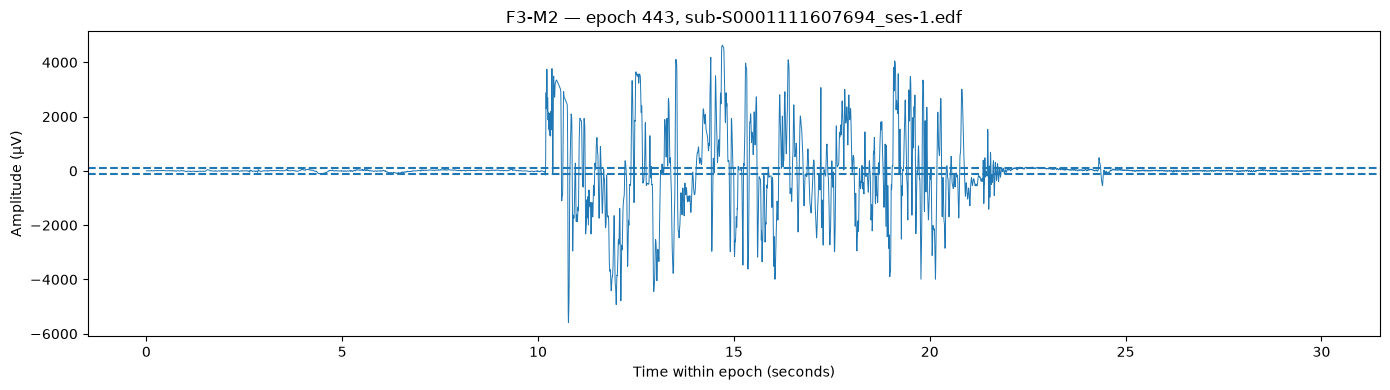

In [239]:
# Plot the raw EEG waveform around the extreme-amplitude epoch.
import matplotlib.pyplot as plt

time_axis = np.arange(len(segment)) / fs

plt.figure(figsize=(14, 4))
plt.plot(time_axis, segment, linewidth=0.7)
plt.axhline(100, linestyle="--")
plt.axhline(-100, linestyle="--")
plt.xlabel("Time within epoch (seconds)")
plt.ylabel("Amplitude (µV)")
plt.title(f"{channel} — epoch {epoch_idx}, {edf_file.name}")
plt.tight_layout()
plt.show()

Epoch 443 mein around 10–22 seconds ke beech very large-amplitude activity dikh rahi hai. Multiple channels mein same time par similar events milne ke kaaran is segment ko potential recording artefact ke roop mein investigate karna chahiye. Abhi ise automatically remove nahi karenge.

In [240]:
# Audit EEG epoch quality across all six channels without removing data.
quality_audit = (
    epoch_features_test
    .assign(
        high_amplitude=lambda df: df["peak_abs_uV"] > 100,
        extreme_amplitude=lambda df: df["peak_abs_uV"] > 500,
        high_variability=lambda df: df["std_uV"] > 100
    )
    .groupby(["BidsFolder", "epoch"], as_index=False)
    .agg(
        start_seconds=("start_seconds", "first"),
        channels_present=("channel", "nunique"),
        max_peak_uV=("peak_abs_uV", "max"),
        max_std_uV=("std_uV", "max"),
        median_zero_fraction=("zero_fraction", "median"),
        high_amplitude_channels=("high_amplitude", "sum"),
        extreme_amplitude_channels=("extreme_amplitude", "sum"),
        high_variability_channels=("high_variability", "sum")
    )
)

quality_audit["review_flag"] = (
    (quality_audit["extreme_amplitude_channels"] > 0)
    | (quality_audit["high_variability_channels"] > 0)
)

quality_audit.to_csv(data_dir / "pilot_epoch_quality_audit.csv", index=False)

print("Total epochs:", len(quality_audit))
print("Epochs flagged for review:", quality_audit["review_flag"].sum())
print("Epochs with extreme amplitude:", (quality_audit["extreme_amplitude_channels"] > 0).sum())
print("Saved:", data_dir / "pilot_epoch_quality_audit.csv")

display(
    quality_audit.sort_values("max_peak_uV", ascending=False)
    .head(15)
    .round(3)
)

Total epochs: 818
Epochs flagged for review: 69
Epochs with extreme amplitude: 68
Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_epoch_quality_audit.csv


,BidsFolder,epoch,start_seconds,channels_present,max_peak_uV,max_std_uV,median_zero_fraction,high_amplitude_channels,extreme_amplitude_channels,high_variability_channels,review_flag
443,sub-S0001111607694,443,13290.0,6,5590.839,1130.660,0.0,6,6,6,True
444,sub-S0001111607694,444,13320.0,6,4952.000,915.994,0.0,6,6,6,True
452,sub-S0001111607694,452,13560.0,6,4932.857,1439.792,0.0,6,6,6,True
453,sub-S0001111607694,453,13590.0,6,4587.880,585.567,0.0,6,6,6,True
307,sub-S0001111607694,307,9210.0,6,4207.903,1367.679,0.0,5,1,1,True
1,sub-S0001111607694,1,30.0,6,4082.908,552.784,0.0,6,6,6,True
817,sub-S0001111607694,817,24510.0,6,4048.940,729.353,0.0,6,6,5,True
451,sub-S0001111607694,451,13530.0,6,4023.983,337.274,0.0,6,6,6,True
517,sub-S0001111607694,517,15510.0,6,3847.907,689.078,0.0,6,3,3,True
308,sub-S0001111607694,308,9240.0,6,3790.986,436.707,0.0,1,1,1,True


In [241]:
# Group consecutive flagged epochs into candidate disturbance intervals.
qa = quality_audit.sort_values("epoch").copy()
qa["flag_group"] = (
    qa["review_flag"].ne(qa["review_flag"].shift())
    | qa["epoch"].diff().ne(1)
).cumsum()

disturbance_intervals = (
    qa.loc[qa["review_flag"]]
    .groupby("flag_group", as_index=False)
    .agg(
        first_epoch=("epoch", "min"),
        last_epoch=("epoch", "max"),
        start_seconds=("start_seconds", "min"),
        end_seconds=("start_seconds", "max"),
        flagged_epochs=("epoch", "count"),
        max_peak_uV=("max_peak_uV", "max"),
        max_std_uV=("max_std_uV", "max")
    )
)

disturbance_intervals["duration_seconds"] = (
    disturbance_intervals["flagged_epochs"] * 30
)

disturbance_intervals.to_csv(
    data_dir / "pilot_disturbance_intervals.csv", index=False
)

print("Candidate disturbance intervals:", len(disturbance_intervals))
print("Flagged epochs:", disturbance_intervals["flagged_epochs"].sum())
display(disturbance_intervals.round(2))

Candidate disturbance intervals: 44
Flagged epochs: 69


,flag_group,first_epoch,last_epoch,start_seconds,end_seconds,flagged_epochs,max_peak_uV,max_std_uV,duration_seconds
0,2,1,1,30.0,30.0,1,4082.91,552.78,30
1,4,4,4,120.0,120.0,1,671.96,114.20,30
2,6,6,7,180.0,210.0,2,1192.91,279.94,60
3,8,10,12,300.0,360.0,3,2184.90,346.86,90
4,10,39,39,1170.0,1170.0,1,616.92,95.43,30
5,12,123,124,3690.0,3720.0,2,1906.89,285.52,60
6,14,129,129,3870.0,3870.0,1,895.93,125.54,30
7,16,142,142,4260.0,4260.0,1,558.97,94.67,30
8,18,168,169,5040.0,5070.0,2,858.96,137.47,60
9,20,224,224,6720.0,6720.0,1,1028.94,145.79,30


In [242]:
# Check the eligible cohort and existing extraction outputs before batch processing.
print("Eligible recordings:", len(eligible))
print("Class distribution:")
print(eligible["Cognitive_Impairment"].value_counts(dropna=False))

print("\nExisting single-recording feature file:",
      (data_dir / "single_recording_epoch_features.csv").exists())
print("Existing eligibility audit:",
      (data_dir / "pilot_eeg_eligibility_audit.csv").exists())

display(
    eligible[["BidsFolder", "Cognitive_Impairment", "file"]]
    .head(10)
    .reset_index(drop=True)
)

Eligible recordings: 38
Class distribution:
Cognitive_Impairment
False    35
True      3
Name: count, dtype: int64

Existing single-recording feature file: True
Existing eligibility audit: True


,BidsFolder,Cognitive_Impairment,file
0,sub-S0001111607694,False,sub-S0001111607694_ses-1.edf
1,sub-S0001112004382,False,sub-S0001112004382_ses-1.edf
2,sub-S0001112257942,False,sub-S0001112257942_ses-1.edf
3,sub-S0001112863983,False,sub-S0001112863983_ses-1.edf
4,sub-S0001113075475,False,sub-S0001113075475_ses-1.edf
5,sub-S0001113174062,False,sub-S0001113174062_ses-1.edf
6,sub-S0001113251921,False,sub-S0001113251921_ses-1.edf
7,sub-S0001113773108,False,sub-S0001113773108_ses-1.edf
8,sub-S0001114315183,False,sub-S0001114315183_ses-1.edf
9,sub-S0001115509440,False,sub-S0001115509440_ses-1.edf


In [243]:
# Locate the existing epoch feature extraction function and its dependencies.
import inspect

for name, obj in list(globals().items()):
    if callable(obj) and not name.startswith("_"):
        try:
            source = inspect.getsource(obj)
            if "welch" in source and "epoch" in source.lower():
                print(f"\n--- {name} ---")
                print(source[:5000])
        except (OSError, TypeError):
            pass


--- extract_eeg_features ---
def extract_eeg_features(edf_path, channel="C3-M2",
                         epoch_seconds=30, threshold_uv=100):
    raw_local = mne.io.read_raw_edf(
        str(edf_path), preload=False, verbose="ERROR"
    )

    if channel not in raw_local.ch_names:
        raise ValueError(f"Channel {channel} not found in {edf_path}")

    fs = raw_local.info["sfreq"]
    samples_per_epoch = int(fs * epoch_seconds)

    signal = raw_local.get_data(
        picks=[channel], units="uV"
    )[0]

    n_epochs = len(signal) // samples_per_epoch
    signal = signal[:n_epochs * samples_per_epoch]
    epochs = signal.reshape(n_epochs, samples_per_epoch)

    bands = {
        "delta_power": (0.5, 4),
        "theta_power": (4, 8),
        "alpha_power": (8, 12),
        "sigma_power": (12, 16)
    }

    rows = []

    for i, segment in enumerate(epochs):
        flagged = bool(np.any(np.abs(segment) > threshold_uv))

        row = {
            "epoch": i,
            "star

In [244]:
# Extract all six EEG channels with per-recording checkpoints and resumable progress.
from pathlib import Path
import pandas as pd
import numpy as np
import mne
from scipy.signal import welch
from tqdm.auto import tqdm

channels = ["F3-M2", "F4-M1", "C3-M2", "C4-M1", "O1-M2", "O2-M1"]
checkpoint_dir = data_dir / "batch_epoch_features"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

def extract_recording_all_channels(edf_path, bids_folder, label, epoch_seconds=30):
    raw = mne.io.read_raw_edf(str(edf_path), preload=False, verbose="ERROR")
    try:
        available = set(raw.ch_names)
        present = [ch for ch in channels if ch in available]
        if not present:
            raise ValueError("None of the six target EEG channels found")

        fs = raw.info["sfreq"]
        samples_per_epoch = int(fs * epoch_seconds)
        bands = {
            "delta_power": (0.5, 4),
            "theta_power": (4, 8),
            "alpha_power": (8, 12),
            "sigma_power": (12, 16),
            "beta_power": (16, 30),
        }
        rows = []

        for ch in present:
            signal = raw.get_data(picks=[ch], units="uV")[0]
            n_epochs = len(signal) // samples_per_epoch
            signal = signal[:n_epochs * samples_per_epoch]
            epochs = signal.reshape(n_epochs, samples_per_epoch)

            for i, segment in enumerate(epochs):
                frequencies, psd = welch(
                    segment, fs=fs,
                    nperseg=min(1024, len(segment))
                )
                row = {
                    "BidsFolder": bids_folder,
                    "Cognitive_Impairment": label,
                    "channel": ch,
                    "epoch": i,
                    "start_seconds": i * epoch_seconds,
                    "std_uV": float(np.std(segment)),
                    "peak_abs_uV": float(np.max(np.abs(segment))),
                    "zero_fraction": float(np.mean(segment == 0)),
                    "quality_flag_peak_gt_100uV": bool(np.max(np.abs(segment)) > 100),
                }

                for band, (low, high) in bands.items():
                    mask = (frequencies >= low) & (frequencies < high)
                    row[band] = (
                        float(np.trapezoid(psd[mask], frequencies[mask]))
                        if mask.any() else np.nan
                    )
                rows.append(row)

        return pd.DataFrame(rows)
    finally:
        raw.close()

manifest_path = checkpoint_dir / "batch_manifest.csv"
manifest = []

for _, row in tqdm(eligible.iterrows(), total=len(eligible), desc="Recordings"):
    bids_folder = row["BidsFolder"]
    output_path = checkpoint_dir / f"{bids_folder}_epochs.csv"

    if output_path.exists():
        manifest.append({
            "BidsFolder": bids_folder,
            "status": "already_saved",
            "output_file": output_path.name,
            "rows": len(pd.read_csv(output_path))
        })
        continue

    matches = list((data_dir / "pilot_downloads").rglob(str(row["file"])))
    if not matches:
        manifest.append({
            "BidsFolder": bids_folder,
            "status": "file_not_found",
            "output_file": "",
            "rows": 0
        })
        continue

    try:
        extracted = extract_recording_all_channels(
            matches[0], bids_folder, row["Cognitive_Impairment"]
        )
        extracted.to_csv(output_path, index=False)
        manifest.append({
            "BidsFolder": bids_folder,
            "status": "success",
            "output_file": output_path.name,
            "rows": len(extracted)
        })
    except Exception as exc:
        manifest.append({
            "BidsFolder": bids_folder,
            "status": f"error: {type(exc).__name__}: {exc}",
            "output_file": "",
            "rows": 0
        })

    pd.DataFrame(manifest).to_csv(manifest_path, index=False)

pd.DataFrame(manifest).to_csv(manifest_path, index=False)
display(pd.DataFrame(manifest)["status"].value_counts())
print("Checkpoint folder:", checkpoint_dir)

d:\Downloads\BEST AI PROJECTS\BDS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Recordings: 100%|██████████| 38/38 [18:33<00:00, 29.31s/it]


status
success    38
Name: count, dtype: int64

Checkpoint folder: d:\Downloads\BEST AI PROJECTS\BDS\data\batch_epoch_features


In [246]:
# Aggregate epoch features into one row per patient and channel.
feature_cols = [
    "std_uV", "peak_abs_uV", "zero_fraction",
    "delta_power", "theta_power", "alpha_power",
    "sigma_power", "beta_power",
]

patient_features = (
    epoch_data
    .groupby(["BidsFolder", "Cognitive_Impairment", "channel"])[feature_cols]
    .agg(["median", "std", "mean"])
)

patient_features.columns = [
    f"{feature}_{stat}" for feature, stat in patient_features.columns
]
patient_features = patient_features.reset_index()

output_file = data_dir / "pilot_patient_level_features.csv"
patient_features.to_csv(output_file, index=False)

print("Patient-channel rows:", patient_features.shape[0])
print("Unique patients:", patient_features["BidsFolder"].nunique())
print("Channels per patient:")
display(patient_features.groupby("BidsFolder")["channel"].nunique().value_counts())
print("Saved:", output_file)
display(patient_features.head())

Patient-channel rows: 228
Unique patients: 38
Channels per patient:


channel
6    38
Name: count, dtype: int64

Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_patient_level_features.csv


,BidsFolder,Cognitive_Impairment,channel,std_uV_median,std_uV_std,std_uV_mean,peak_abs_uV_median,peak_abs_uV_std,peak_abs_uV_mean,zero_fraction_median,...,theta_power_mean,alpha_power_median,alpha_power_std,alpha_power_mean,sigma_power_median,sigma_power_std,sigma_power_mean,beta_power_median,beta_power_std,beta_power_mean
0,sub-S0001111407087,True,C3-M2,12.235192,24.884837,15.123989,61.949096,209.826897,92.016171,0.0,...,35.804212,30.347054,108.342446,34.179679,7.125369,119.912822,13.514844,8.974631,380.893313,29.821698
1,sub-S0001111407087,True,C4-M1,16.962459,52.132741,31.162149,89.464446,376.152232,177.004565,0.0,...,51.761114,26.054389,175.504800,36.963484,7.933178,94.454077,14.273771,9.164658,128.119175,20.927812
2,sub-S0001111407087,True,F3-M2,17.303633,106.319784,57.903942,92.957382,586.200985,301.185521,0.0,...,418.765941,27.178325,2770.244303,227.620567,7.114969,1013.774166,98.142149,11.765175,1770.885503,189.840414
3,sub-S0001111407087,True,F4-M1,19.493290,52.143861,33.177252,102.881437,375.588344,187.427387,0.0,...,50.558988,24.960510,123.252102,33.821819,8.052345,56.609978,12.901248,10.973742,65.805631,18.594092
4,sub-S0001111407087,True,O1-M2,13.835107,29.707945,20.888250,61.074846,217.680047,121.569835,0.0,...,24.177806,67.857060,61.199353,72.088361,8.334252,17.594259,10.057572,9.944961,50.537097,17.492614


In [247]:
# Convert channel-wise EEG summaries into one row per patient.
id_cols = ["BidsFolder", "Cognitive_Impairment"]
feature_cols = [
    c for c in patient_features.columns
    if c not in id_cols + ["channel"]
]

patient_wide = patient_features.pivot(
    index=id_cols,
    columns="channel",
    values=feature_cols
)

patient_wide.columns = [
    f"{channel}_{feature}"
    for feature, channel in patient_wide.columns
]
patient_wide = patient_wide.reset_index()

patient_wide.to_csv(
    data_dir / "pilot_patient_level_wide.csv",
    index=False
)

print("Final patient-level shape:", patient_wide.shape)
print("Unique patients:", patient_wide["BidsFolder"].nunique())
print("Class distribution:")
display(patient_wide["Cognitive_Impairment"].value_counts())
print("Missing values:", int(patient_wide.isna().sum().sum()))
print("Saved:", data_dir / "pilot_patient_level_wide.csv")
display(patient_wide.head())

Final patient-level shape: (38, 146)
Unique patients: 38
Class distribution:


Cognitive_Impairment
False    35
True      3
Name: count, dtype: int64

Missing values: 0
Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_patient_level_wide.csv


,BidsFolder,Cognitive_Impairment,C3-M2_std_uV_median,C4-M1_std_uV_median,F3-M2_std_uV_median,F4-M1_std_uV_median,O1-M2_std_uV_median,O2-M1_std_uV_median,C3-M2_std_uV_std,C4-M1_std_uV_std,...,F3-M2_beta_power_std,F4-M1_beta_power_std,O1-M2_beta_power_std,O2-M1_beta_power_std,C3-M2_beta_power_mean,C4-M1_beta_power_mean,F3-M2_beta_power_mean,F4-M1_beta_power_mean,O1-M2_beta_power_mean,O2-M1_beta_power_mean
0,sub-S0001111407087,True,12.235192,16.962459,17.303633,19.493290,13.835107,18.331287,24.884837,52.132741,...,1770.885503,65.805631,50.537097,116.735252,29.821698,20.927812,189.840414,18.594092,17.492614,17.871292
1,sub-S0001111607694,False,11.005716,12.631657,11.387393,11.789257,9.918737,9.949119,73.316858,108.765618,...,4648.435595,4828.637868,4032.163242,4031.213651,267.504563,359.917395,309.317165,344.410600,272.516965,261.575613
2,sub-S0001112004382,False,12.501544,12.348005,15.541308,15.362165,9.544275,10.795127,90.004031,81.368263,...,1736.691222,1118.554405,1619.766627,1241.946826,213.721947,164.692487,181.437451,125.082113,160.220133,116.924905
3,sub-S0001112257942,False,17.832386,21.503198,20.565872,23.200749,14.381607,17.328776,26.175574,12.130171,...,101.827396,84.667299,16.798830,42.676332,14.849838,11.436771,11.543739,12.631661,7.910859,8.501801
4,sub-S0001112863983,False,11.517135,11.955916,12.730817,14.423462,9.748429,10.498662,72.615185,27.983603,...,9.376302,64.399332,66.465319,224.874681,33.966841,11.670953,6.226487,10.506505,6.569989,13.543968


In [248]:
# Check EEG feature distributions and identify extreme or non-finite values.
import numpy as np
import pandas as pd

id_cols = ["BidsFolder", "Cognitive_Impairment"]
feature_cols = [c for c in patient_wide.columns if c not in id_cols]

X_audit = patient_wide[feature_cols].apply(pd.to_numeric, errors="coerce")

print("Total EEG features:", len(feature_cols))
print("Non-finite values:", int((~np.isfinite(X_audit.to_numpy())).sum()))
print("Features with zero variance:", int((X_audit.nunique() <= 1).sum()))

feature_summary = X_audit.describe(percentiles=[0.50, 0.95, 0.99]).T
feature_summary["non_finite"] = (~np.isfinite(X_audit)).sum()
feature_summary["zero_variance"] = X_audit.nunique() <= 1

display(
    feature_summary.sort_values("max", ascending=False).head(15)
)

print("\nClass-wise median EEG features:")
class_medians = patient_wide.groupby("Cognitive_Impairment")[feature_cols].median().T
class_medians.columns = ["Negative_median", "Positive_median"]
class_medians["median_difference"] = (
    class_medians["Positive_median"] - class_medians["Negative_median"]
)
display(class_medians.head(15))

Total EEG features: 144
Non-finite values: 0
Features with zero variance: 15


,count,mean,std,min,50%,95%,99%,max,non_finite,zero_variance
F3-M2_delta_power_std,38.0,13466.876632,17416.629638,88.982332,4006.078752,47393.327500,63328.193513,67563.637937,0,False
O2-M1_delta_power_std,38.0,7151.709692,12182.172368,94.557659,2451.551648,22959.218171,54737.878333,66404.377218,0,False
C4-M1_delta_power_std,38.0,12577.250733,16244.354135,63.142751,4937.721796,49262.898865,60327.335677,63631.796510,0,False
F4-M1_delta_power_std,38.0,10156.209916,12639.817703,183.325665,4456.423012,31762.801592,49341.672458,58577.996415,0,False
C3-M2_delta_power_std,38.0,11625.386621,12627.370608,82.499626,6462.814342,37213.996867,39513.664396,40320.745744,0,False
O1-M2_delta_power_std,38.0,8264.731519,10646.148418,72.279188,3446.744827,34958.268075,37848.141882,38361.437062,0,False
C4-M1_theta_power_std,38.0,3191.711560,5600.693895,4.244013,367.841715,16136.677205,22619.950661,25692.330511,0,False
F3-M2_theta_power_std,38.0,3522.694549,5837.158666,3.803653,301.866030,13656.801916,23537.363435,25365.912527,0,False
F4-M1_theta_power_std,38.0,2859.632017,4967.185443,8.125846,293.675466,11771.792003,20272.846902,22575.347174,0,False
C3-M2_theta_power_std,38.0,2926.570694,4502.216173,5.443043,550.190071,11131.342822,17306.406272,18114.959952,0,False



Class-wise median EEG features:


,Negative_median,Positive_median,median_difference
C3-M2_std_uV_median,11.336667,12.770218,1.433551
C4-M1_std_uV_median,12.459337,15.168087,2.708750
F3-M2_std_uV_median,13.519164,17.303633,3.784469
F4-M1_std_uV_median,14.423462,19.493290,5.069828
O1-M2_std_uV_median,9.828400,13.835107,4.006707
O2-M1_std_uV_median,10.383823,13.598331,3.214508
C3-M2_std_uV_std,33.230573,24.481490,-8.749082
C4-M1_std_uV_std,35.950487,37.679437,1.728950
F3-M2_std_uV_std,28.549327,39.234772,10.685445
F4-M1_std_uV_std,29.263769,36.332928,7.069159


In [249]:
# Compare class-wise EEG features after log-transforming nonnegative power features.
import numpy as np
import pandas as pd

power_cols = [
    c for c in feature_cols
    if any(band in c for band in [
        "delta_power", "theta_power", "alpha_power",
        "sigma_power", "beta_power"
    ])
]

comparison = patient_wide.copy()

for col in power_cols:
    comparison[col] = np.log1p(comparison[col].clip(lower=0))

summary_rows = []

for col in feature_cols:
    neg = comparison.loc[comparison["Cognitive_Impairment"] == False, col]
    pos = comparison.loc[comparison["Cognitive_Impairment"] == True, col]

    summary_rows.append({
        "feature": col,
        "negative_median": neg.median(),
        "positive_median": pos.median(),
        "median_difference": pos.median() - neg.median(),
        "negative_IQR": neg.quantile(0.75) - neg.quantile(0.25),
        "positive_IQR": pos.quantile(0.75) - pos.quantile(0.25),
    })

comparison_summary = pd.DataFrame(summary_rows)
comparison_summary["absolute_difference"] = (
    comparison_summary["median_difference"].abs()
)

print("Patients: 35 negative, 3 positive")
print("Largest descriptive median differences:")
display(
    comparison_summary
    .sort_values("absolute_difference", ascending=False)
    .head(20)
)

comparison_summary.to_csv(
    data_dir / "pilot_eeg_class_comparison.csv",
    index=False
)
print("Saved:", data_dir / "pilot_eeg_class_comparison.csv")

Patients: 35 negative, 3 positive
Largest descriptive median differences:


,feature,negative_median,positive_median,median_difference,negative_IQR,positive_IQR,absolute_difference
26,F3-M2_peak_abs_uV_std,229.296097,458.071007,228.774910,187.315162,203.024442,228.774910
29,O2-M1_peak_abs_uV_std,209.770090,376.520234,166.750144,188.646871,247.943621,166.750144
27,F4-M1_peak_abs_uV_std,216.066657,375.588344,159.521687,182.710449,190.150714,159.521687
25,C4-M1_peak_abs_uV_std,231.027656,376.152232,145.124576,190.265634,99.068532,145.124576
32,F3-M2_peak_abs_uV_mean,109.995046,210.467580,100.472534,39.380242,103.869587,100.472534
35,O2-M1_peak_abs_uV_mean,95.460424,173.028516,77.568092,47.174249,58.435760,77.568092
33,F4-M1_peak_abs_uV_mean,112.460644,187.427387,74.966743,45.616697,72.771934,74.966743
31,C4-M1_peak_abs_uV_mean,108.554877,177.004565,68.449688,56.182955,47.888444,68.449688
28,O1-M2_peak_abs_uV_std,279.098843,217.680047,-61.418796,186.885341,163.519678,61.418796
24,C3-M2_peak_abs_uV_std,260.845269,209.826897,-51.018371,154.274236,118.321057,51.018371


Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_eeg_class_comparison.csv


In [251]:
# Locate saved batch and quality-audit CSV files under the project data folder.
from pathlib import Path

for pattern in ["*manifest*.csv", "*quality*audit*.csv", "*disturbance*interval*.csv"]:
    print(f"\nSearching: {pattern}")
    matches = list(data_dir.rglob(pattern))
    if matches:
        for path in matches:
            print(path)
    else:
        print("No matching file found.")


Searching: *manifest*.csv
d:\Downloads\BEST AI PROJECTS\BDS\data\batch_epoch_features\batch_manifest.csv

Searching: *quality*audit*.csv
d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_annotation_quality_audit.csv
d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_epoch_quality_audit.csv
d:\Downloads\BEST AI PROJECTS\BDS\data\site_I0006_epoch_quality_audit.csv

Searching: *disturbance*interval*.csv
d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_disturbance_intervals.csv


In [252]:
# Load the batch manifest and inspect extraction status.
manifest_path = data_dir / "batch_epoch_features" / "batch_manifest.csv"
manifest = pd.read_csv(manifest_path)

print("Manifest shape:", manifest.shape)
print("Columns:", manifest.columns.tolist())
display(manifest.head(10))

for col in manifest.columns:
    if any(word in col.lower() for word in ["status", "error", "success"]):
        print(f"\n{col} counts:")
        display(manifest[col].value_counts(dropna=False))

Manifest shape: (38, 4)
Columns: ['BidsFolder', 'status', 'output_file', 'rows']


,BidsFolder,status,output_file,rows
0,sub-S0001111607694,success,sub-S0001111607694_epochs.csv,4908
1,sub-S0001112004382,success,sub-S0001112004382_epochs.csv,5118
2,sub-S0001112257942,success,sub-S0001112257942_epochs.csv,5748
3,sub-S0001112863983,success,sub-S0001112863983_epochs.csv,6138
4,sub-S0001113075475,success,sub-S0001113075475_epochs.csv,5214
5,sub-S0001113174062,success,sub-S0001113174062_epochs.csv,6438
6,sub-S0001113251921,success,sub-S0001113251921_epochs.csv,5130
7,sub-S0001113773108,success,sub-S0001113773108_epochs.csv,6156
8,sub-S0001114315183,success,sub-S0001114315183_epochs.csv,5370
9,sub-S0001115509440,success,sub-S0001115509440_epochs.csv,5796



status counts:


status
success    38
Name: count, dtype: int64

In [253]:
# Summarize flagged EEG epochs for each patient and compare by impairment label.
quality_path = data_dir / "pilot_epoch_quality_audit.csv"
quality_audit = pd.read_csv(quality_path)

print("Quality audit shape:", quality_audit.shape)
print("Available columns:", quality_audit.columns.tolist())
display(quality_audit.head())

print("\nReview flag counts:")
display(quality_audit["review_flag"].value_counts(dropna=False))

Quality audit shape: (818, 11)
Available columns: ['BidsFolder', 'epoch', 'start_seconds', 'channels_present', 'max_peak_uV', 'max_std_uV', 'median_zero_fraction', 'high_amplitude_channels', 'extreme_amplitude_channels', 'high_variability_channels', 'review_flag']


,BidsFolder,epoch,start_seconds,channels_present,max_peak_uV,max_std_uV,median_zero_fraction,high_amplitude_channels,extreme_amplitude_channels,high_variability_channels,review_flag
0,sub-S0001111607694,0,0.0,6,153.073915,22.530138,0.0,4,0,0,False
1,sub-S0001111607694,1,30.0,6,4082.908370,552.783666,0.0,6,6,6,True
2,sub-S0001111607694,2,60.0,6,314.929961,54.053821,0.0,6,0,0,False
3,sub-S0001111607694,3,90.0,6,125.958694,13.538489,0.0,1,0,0,False
4,sub-S0001111607694,4,120.0,6,671.960372,114.195006,0.0,6,2,1,True



Review flag counts:


review_flag
False    749
True      69
Name: count, dtype: int64

In [254]:
# Summarize candidate EEG quality flags at the patient level.
quality_audit["review_flag"] = quality_audit["review_flag"].astype(bool)

patient_quality = (
    quality_audit.groupby("BidsFolder", as_index=False)
    .agg(
        total_epochs=("epoch", "count"),
        flagged_epochs=("review_flag", "sum"),
        median_peak_uV=("max_peak_uV", "median"),
        max_peak_uV=("max_peak_uV", "max"),
        median_std_uV=("max_std_uV", "median"),
    )
)

patient_quality["flagged_epoch_fraction"] = (
    patient_quality["flagged_epochs"] / patient_quality["total_epochs"]
)

labels = patient_wide[["BidsFolder", "Cognitive_Impairment"]].drop_duplicates()
patient_quality = patient_quality.merge(labels, on="BidsFolder", how="left")

print("Patients in quality audit:", patient_quality["BidsFolder"].nunique())
print("Patients with missing labels:", patient_quality["Cognitive_Impairment"].isna().sum())

display(
    patient_quality.groupby("Cognitive_Impairment")[
        ["total_epochs", "flagged_epochs", "flagged_epoch_fraction", "median_peak_uV", "max_peak_uV"]
    ].median()
)

print("\nPatients with highest flagged-epoch fraction:")
display(
    patient_quality.sort_values("flagged_epoch_fraction", ascending=False).head(10)
)

patient_quality.to_csv(
    data_dir / "pilot_patient_quality_summary.csv", index=False
)
print("Saved:", data_dir / "pilot_patient_quality_summary.csv")

Patients in quality audit: 1
Patients with missing labels: 0


,total_epochs,flagged_epochs,flagged_epoch_fraction,median_peak_uV,max_peak_uV
Cognitive_Impairment,,,,,
False,818.0,69.0,0.084352,63.886511,5590.839124



Patients with highest flagged-epoch fraction:


,BidsFolder,total_epochs,flagged_epochs,median_peak_uV,max_peak_uV,median_std_uV,flagged_epoch_fraction,Cognitive_Impairment
0,sub-S0001111607694,818,69,63.886511,5590.839124,13.431149,0.084352,False


Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_patient_quality_summary.csv


In [255]:
# Rebuild the patient-level quality audit from all 38 batch feature files.
batch_dir = data_dir / "batch_epoch_features"
batch_files = list(batch_dir.glob("sub-*_epochs.csv"))

print("Batch files found:", len(batch_files))

quality_rows = []

for file in batch_files:
    df = pd.read_csv(file)

    patient_summary = {
        "BidsFolder": df["BidsFolder"].iloc[0],
        "Cognitive_Impairment": df["Cognitive_Impairment"].iloc[0],
        "total_epochs": df["epoch"].nunique(),
        "flagged_epochs": (
            df.groupby("epoch")["quality_flag_peak_gt_100uV"]
            .any().sum()
        ),
        "max_peak_uV": df["peak_abs_uV"].max(),
        "median_peak_uV": df["peak_abs_uV"].median(),
    }
    patient_summary["flagged_epoch_fraction"] = (
        patient_summary["flagged_epochs"] / patient_summary["total_epochs"]
    )
    quality_rows.append(patient_summary)

batch_quality = pd.DataFrame(quality_rows)

print("Patients:", batch_quality["BidsFolder"].nunique())
print("Class counts:")
display(batch_quality["Cognitive_Impairment"].value_counts())

print("\nMedian quality metrics by label:")
display(
    batch_quality.groupby("Cognitive_Impairment")[
        ["total_epochs", "flagged_epochs", "flagged_epoch_fraction",
         "median_peak_uV", "max_peak_uV"]
    ].median()
)

batch_quality.to_csv(data_dir / "pilot_batch_patient_quality_summary.csv", index=False)
print("Saved:", data_dir / "pilot_batch_patient_quality_summary.csv")

Batch files found: 38
Patients: 38
Class counts:


Cognitive_Impairment
False    35
True      3
Name: count, dtype: int64


Median quality metrics by label:


,total_epochs,flagged_epochs,flagged_epoch_fraction,median_peak_uV,max_peak_uV
Cognitive_Impairment,,,,,
False,962.0,361.0,0.409666,58.963607,4140.0
True,968.0,472.0,0.487603,76.017525,4247.0


Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_batch_patient_quality_summary.csv


In [256]:
# Inspect the patients with the highest flagged-epoch fractions and peak amplitudes.
display(
    batch_quality.sort_values(
        ["flagged_epoch_fraction", "max_peak_uV"],
        ascending=False
    )[
        [
            "BidsFolder",
            "Cognitive_Impairment",
            "total_epochs",
            "flagged_epochs",
            "flagged_epoch_fraction",
            "median_peak_uV",
            "max_peak_uV",
        ]
    ].head(12).round(3)
)

print("\nFlagged-epoch fraction by label:")
for label, group in batch_quality.groupby("Cognitive_Impairment"):
    print(
        f"Label={label}: n={len(group)}, "
        f"median={group['flagged_epoch_fraction'].median():.3f}, "
        f"range=({group['flagged_epoch_fraction'].min():.3f}, "
        f"{group['flagged_epoch_fraction'].max():.3f})"
    )

print("\nSaved batch quality summary:",
      data_dir / "pilot_batch_patient_quality_summary.csv")

,BidsFolder,Cognitive_Impairment,total_epochs,flagged_epochs,flagged_epoch_fraction,median_peak_uV,max_peak_uV
17,sub-S0001117536899,False,921,921,1.000,106.936,3879.492
19,sub-S0001117755388,False,982,982,1.000,134.377,3872.800
21,sub-S0001117976781,False,1045,1045,1.000,78.934,3802.000
37,sub-S0001122125768,False,974,974,1.000,96.240,3012.190
3,sub-S0001112257942,False,958,951,0.993,108.912,3887.000
33,sub-S0001121129885,False,1066,1018,0.955,84.148,3862.282
18,sub-S0001117668018,False,916,836,0.913,70.976,2128.000
36,sub-S0001121795362,False,848,678,0.800,84.772,3864.800
8,sub-S0001113773108,False,1026,810,0.789,67.520,3835.800
0,sub-S0001111407087,True,974,649,0.666,78.972,4205.000



Flagged-epoch fraction by label:
Label=False: n=35, median=0.410, range=(0.171, 1.000)
Label=True: n=3, median=0.488, range=(0.339, 0.666)

Saved batch quality summary: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_batch_patient_quality_summary.csv


In [257]:
# Save a concise, reproducible summary of the pilot study findings.
from pathlib import Path
import pandas as pd
import json

summary = {
    "eligible_recordings": int(batch_quality["BidsFolder"].nunique()),
    "negative_patients": int((batch_quality["Cognitive_Impairment"] == False).sum()),
    "positive_patients": int((batch_quality["Cognitive_Impairment"] == True).sum()),
    "total_epochs": int(batch_quality["total_epochs"].sum()),
    "total_flagged_epochs": int(batch_quality["flagged_epochs"].sum()),
    "overall_flagged_epoch_fraction": float(
        batch_quality["flagged_epochs"].sum() /
        batch_quality["total_epochs"].sum()
    ),
    "median_flag_fraction_negative": float(
        batch_quality.loc[
            batch_quality["Cognitive_Impairment"] == False,
            "flagged_epoch_fraction"
        ].median()
    ),
    "median_flag_fraction_positive": float(
        batch_quality.loc[
            batch_quality["Cognitive_Impairment"] == True,
            "flagged_epoch_fraction"
        ].median()
    ),
    "sites_in_eligible_pilot": ["S0001"],
    "limitations": [
        "Only three impairment-positive patients in the eligible EEG pilot",
        "All eligible recordings are from one site",
        "100 uV peak threshold is a preliminary review flag, not a validated artifact rule",
        "Class-wise feature differences are descriptive and not evidence of diagnostic performance"
    ]
}

summary_path = data_dir / "pilot_final_results_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print("\nSaved:", summary_path)

{
  "eligible_recordings": 38,
  "negative_patients": 35,
  "positive_patients": 3,
  "total_epochs": 36054,
  "total_flagged_epochs": 18213,
  "overall_flagged_epoch_fraction": 0.5051589282742552,
  "median_flag_fraction_negative": 0.4096662830840046,
  "median_flag_fraction_positive": 0.48760330578512395,
  "sites_in_eligible_pilot": [
    "S0001"
  ],
  "limitations": [
    "Only three impairment-positive patients in the eligible EEG pilot",
    "All eligible recordings are from one site",
    "100 uV peak threshold is a preliminary review flag, not a validated artifact rule",
    "Class-wise feature differences are descriptive and not evidence of diagnostic performance"
  ]
}

Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_final_results_summary.json


In [258]:
# Check that the main result files are available before drafting the report.
from pathlib import Path
import pandas as pd

result_files = [
    data_dir / "pilot_final_results_summary.json",
    data_dir / "pilot_patient_level_features.csv",
    data_dir / "pilot_patient_level_wide.csv",
    data_dir / "pilot_eeg_class_comparison.csv",
    data_dir / "pilot_batch_patient_quality_summary.csv",
    data_dir / "batch_epoch_features" / "batch_manifest.csv",
]

for path in result_files:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")
    if path.exists() and path.suffix == ".csv":
        df = pd.read_csv(path)
        print(f"   Shape: {df.shape}")

FOUND: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_final_results_summary.json
FOUND: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_patient_level_features.csv
   Shape: (228, 27)
FOUND: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_patient_level_wide.csv
   Shape: (38, 146)
FOUND: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_eeg_class_comparison.csv
   Shape: (144, 7)
FOUND: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_batch_patient_quality_summary.csv
   Shape: (38, 7)
FOUND: d:\Downloads\BEST AI PROJECTS\BDS\data\batch_epoch_features\batch_manifest.csv
   Shape: (38, 4)


In [259]:
# Build a report-ready summary of the completed demographics and EEG pilot analyses.
import pandas as pd
import json

summary_path = data_dir / "pilot_final_results_summary.json"

with open(summary_path, "r", encoding="utf-8") as f:
    eeg_summary = json.load(f)

results_table = pd.DataFrame([
    {
        "Analysis": "Demographics cohort",
        "Sample_size": 1103,
        "Finding": "84 positive labels and 1019 negative labels",
        "Interpretation": "Class-imbalanced cohort; separate from EEG pilot"
    },
    {
        "Analysis": "Demographics baseline",
        "Sample_size": 1103,
        "Finding": "Random Forest ROC-AUC = 0.7346",
        "Interpretation": "Exploratory baseline; not clinical validation"
    },
    {
        "Analysis": "Time_to_Event missingness audit",
        "Sample_size": 1103,
        "Finding": "Missingness perfectly aligned with target label",
        "Interpretation": "Potential label leakage; exclude from ordinary prediction"
    },
    {
        "Analysis": "EEG pilot",
        "Sample_size": eeg_summary["eligible_recordings"],
        "Finding": (
            f'{eeg_summary["negative_patients"]} negative and '
            f'{eeg_summary["positive_patients"]} positive patients; '
            f'{eeg_summary["total_epochs"]} epochs'
        ),
        "Interpretation": "Small, single-site feasibility analysis"
    },
    {
        "Analysis": "EEG quality screening",
        "Sample_size": eeg_summary["eligible_recordings"],
        "Finding": (
            f'{eeg_summary["total_flagged_epochs"]} of '
            f'{eeg_summary["total_epochs"]} epochs flagged '
            f'({eeg_summary["overall_flagged_epoch_fraction"]:.1%})'
        ),
        "Interpretation": "Preliminary >100 µV threshold; not confirmed artefacts"
    }
])

output_path = data_dir / "final_report_results_table.csv"
results_table.to_csv(output_path, index=False)

display(results_table)
print("\nSaved:", output_path)

,Analysis,Sample_size,Finding,Interpretation
0,Demographics cohort,1103,84 positive labels and 1019 negative labels,Class-imbalanced cohort; separate from EEG pilot
1,Demographics baseline,1103,Random Forest ROC-AUC = 0.7346,Exploratory baseline; not clinical validation
2,Time_to_Event missingness audit,1103,Missingness perfectly aligned with target label,Potential label leakage; exclude from ordinary...
3,EEG pilot,38,35 negative and 3 positive patients; 36054 epochs,"Small, single-site feasibility analysis"
4,EEG quality screening,38,18213 of 36054 epochs flagged (50.5%),Preliminary >100 µV threshold; not confirmed a...



Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\final_report_results_table.csv


# 5. Results and Discussion

## 5.1 Demographic Cohort Analysis

The demographic dataset contained 1,103 records, comprising 84 individuals labelled as having cognitive impairment and 1,019 labelled as not having cognitive impairment. This represents a substantial class imbalance, with the positive class accounting for approximately 7.6% of the dataset. Consequently, predictive performance should not be evaluated using accuracy alone; class-sensitive measures and careful validation are necessary.

The exploratory Random Forest baseline achieved a ROC-AUC of 0.7346. This indicates that the demographic features provided some discriminatory information in the evaluated split, but it does not establish clinical utility or demonstrate that an AI system can reliably predict dementia.

## 5.2 Shortcut and Label-Leakage Audit

The audit identified a critical issue with the `Time_to_Event` variable: its missingness pattern aligned perfectly with the target label in the demographic dataset. Such a relationship can allow a model to exploit data availability rather than learn meaningful clinical or physiological patterns. Therefore, `Time_to_Event` and its missingness indicator should be excluded from ordinary predictive models unless their availability and meaning at the intended prediction time are independently justified.

This finding illustrates why high predictive performance alone is insufficient evidence of meaningful prediction. Feature provenance, label construction, data collection procedures, and the timing of measurements must also be examined.

## 5.3 EEG Pilot and Feature Extraction

The EEG feasibility analysis included 38 eligible recordings from site S0001: 35 patients labelled negative and three labelled positive for cognitive impairment. Six bipolar EEG channels were processed, and 30-second epochs were used to derive signal-amplitude and frequency-band power features.

The resulting patient-level dataset contained 38 rows and 144 EEG features, with no missing values in the aggregated feature matrix. Class-wise median comparisons showed differences in several peak-amplitude variability features. For example, the median of `F3-M2_peak_abs_uV_std` was approximately 229.30 in the negative group and 458.07 in the positive group.

These comparisons are descriptive only. The positive group contained just three patients, and the observed differences may reflect individual variation, recording artefacts, or other confounding factors. They cannot establish a reliable association between these EEG features and cognitive impairment.

## 5.4 EEG Signal-Quality Screening

Across the 38 EEG recordings, 36,054 epochs were processed. Of these, 18,213 epochs (approximately 50.5%) exceeded the preliminary 100 µV peak-amplitude threshold and were flagged for review.

The median flagged-epoch fraction was approximately 41.0% among negative patients and 48.8% among positive patients. However, the threshold was used as a screening heuristic, not as a validated artefact detector. An epoch exceeding 100 µV is not necessarily corrupted, and a flagged epoch should not automatically be removed without further signal inspection and a documented quality-control protocol.

The substantial variation in flagged-epoch fractions across recordings highlights the importance of assessing signal quality before interpreting model predictions. Quality-related differences could otherwise influence a model's outputs and complicate the interpretation of apparent predictive patterns.

## 5.5 Overall Interpretation

The demographic and EEG analyses demonstrate two distinct risks in evaluating sleep-based AI models. First, demographic metadata can contain target-associated missingness that creates a potential shortcut or leakage pathway. Second, EEG recordings exhibit considerable variation in signal-quality screening metrics, making quality control an important component of the modelling pipeline.

Nevertheless, this study does not establish that sleep-based AI models predict dementia, nor does it prove that the observed EEG differences are caused by artefacts or shortcut learning. The EEG analysis is a small, single-site feasibility study with very few positive cases. Its primary contribution is to identify methodological risks and motivate more rigorous validation rather than to demonstrate diagnostic performance.

In [260]:
# Check the available patient identifiers before combining the datasets.
import pandas as pd
from pathlib import Path

data_dir = Path.cwd() / "data"

demographics = pd.read_csv(data_dir / "demographics.csv")
eeg_wide = pd.read_csv(data_dir / "pilot_patient_level_wide.csv")

print("Demographics shape:", demographics.shape)
print("EEG pilot shape:", eeg_wide.shape)

print("\nDemographics columns:")
print(demographics.columns.tolist())

print("\nEEG pilot columns:")
print(eeg_wide.columns.tolist())

print("\nEEG pilot label distribution:")
print(eeg_wide["Cognitive_Impairment"].value_counts(dropna=False))

Demographics shape: (1103, 14)
EEG pilot shape: (38, 146)

Demographics columns:
['SiteID', 'BDSPPatientID', 'CreationTime', 'BidsFolder', 'SessionID', 'Age', 'Sex', 'Race', 'Ethnicity', 'BMI', 'Time_to_Event', 'Cognitive_Impairment', 'Last_Known_Visit_Date', 'Time_to_Last_Visit']

EEG pilot columns:
['BidsFolder', 'Cognitive_Impairment', 'C3-M2_std_uV_median', 'C4-M1_std_uV_median', 'F3-M2_std_uV_median', 'F4-M1_std_uV_median', 'O1-M2_std_uV_median', 'O2-M1_std_uV_median', 'C3-M2_std_uV_std', 'C4-M1_std_uV_std', 'F3-M2_std_uV_std', 'F4-M1_std_uV_std', 'O1-M2_std_uV_std', 'O2-M1_std_uV_std', 'C3-M2_std_uV_mean', 'C4-M1_std_uV_mean', 'F3-M2_std_uV_mean', 'F4-M1_std_uV_mean', 'O1-M2_std_uV_mean', 'O2-M1_std_uV_mean', 'C3-M2_peak_abs_uV_median', 'C4-M1_peak_abs_uV_median', 'F3-M2_peak_abs_uV_median', 'F4-M1_peak_abs_uV_median', 'O1-M2_peak_abs_uV_median', 'O2-M1_peak_abs_uV_median', 'C3-M2_peak_abs_uV_std', 'C4-M1_peak_abs_uV_std', 'F3-M2_peak_abs_uV_std', 'F4-M1_peak_abs_uV_std', 'O1-M2_

In [261]:
# Verify patient-level matching and target-label consistency across datasets.
import pandas as pd

demo = demographics.copy()
eeg = eeg_wide.copy()

demo["BidsFolder"] = demo["BidsFolder"].astype("string").str.strip()
eeg["BidsFolder"] = eeg["BidsFolder"].astype("string").str.strip()

print("Duplicate BidsFolder values in demographics:",
      demo["BidsFolder"].duplicated().sum())
print("Duplicate BidsFolder values in EEG:",
      eeg["BidsFolder"].duplicated().sum())

matched = eeg.merge(
    demo[["BidsFolder", "BDSPPatientID", "SiteID",
          "Cognitive_Impairment"]],
    on="BidsFolder",
    how="left",
    suffixes=("_EEG", "_Demo"),
    indicator=True,
    validate="one_to_one"
)

print("\nEEG patients:", len(eeg))
print("Exact BidsFolder matches:", (matched["_merge"] == "both").sum())
print("Unmatched EEG patients:", (matched["_merge"] == "left_only").sum())

matched_rows = matched[matched["_merge"] == "both"]

if not matched_rows.empty:
    print("Target-label agreements:",
          (matched_rows["Cognitive_Impairment_EEG"] ==
           matched_rows["Cognitive_Impairment_Demo"]).sum())
    print("Target-label disagreements:",
          (matched_rows["Cognitive_Impairment_EEG"] !=
           matched_rows["Cognitive_Impairment_Demo"]).sum())

display(matched[[
    "BidsFolder", "Cognitive_Impairment_EEG",
    "Cognitive_Impairment_Demo", "BDSPPatientID",
    "SiteID", "_merge"
]].head(15))

Duplicate BidsFolder values in demographics: 0
Duplicate BidsFolder values in EEG: 0

EEG patients: 38
Exact BidsFolder matches: 38
Unmatched EEG patients: 0
Target-label agreements: 38
Target-label disagreements: 0


,BidsFolder,Cognitive_Impairment_EEG,Cognitive_Impairment_Demo,BDSPPatientID,SiteID,_merge
0,sub-S0001111407087,True,True,111407087,S0001,both
1,sub-S0001111607694,False,False,111607694,S0001,both
2,sub-S0001112004382,False,False,112004382,S0001,both
3,sub-S0001112257942,False,False,112257942,S0001,both
4,sub-S0001112863983,False,False,112863983,S0001,both
5,sub-S0001113075475,False,False,113075475,S0001,both
6,sub-S0001113174062,False,False,113174062,S0001,both
7,sub-S0001113251921,False,False,113251921,S0001,both
8,sub-S0001113773108,False,False,113773108,S0001,both
9,sub-S0001114315183,False,False,114315183,S0001,both


In [263]:
# Rebuild the matched dataset with explicit target-column names.
import pandas as pd

demo = demographics.copy()
eeg = eeg_wide.copy()

# Keep the EEG label as the single target column.
model_data = eeg.merge(
    demo[[
        "BidsFolder", "Age", "Sex", "Race", "Ethnicity", "BMI",
        "Cognitive_Impairment"
    ]].rename(columns={
        "Cognitive_Impairment": "Cognitive_Impairment_Demo"
    }),
    on="BidsFolder",
    how="inner",
    validate="one_to_one"
)

# Verify labels before modelling.
label_match = (
    model_data["Cognitive_Impairment"]
    == model_data["Cognitive_Impairment_Demo"]
)

print("Matched patients:", len(model_data))
print("Label agreements:", int(label_match.sum()))
print("Label disagreements:", int((~label_match).sum()))
print("Target column exists:", "Cognitive_Impairment" in model_data.columns)

print("\nTarget distribution:")
print(model_data["Cognitive_Impairment"].value_counts(dropna=False))

Matched patients: 38
Label agreements: 38
Label disagreements: 0
Target column exists: True

Target distribution:
Cognitive_Impairment
False    35
True      3
Name: count, dtype: int64


In [264]:
# Compare three exploratory models using the same leave-one-out patient splits.
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score

# Use the verified matched dataset created in the previous cell.
target = "Cognitive_Impairment"
demo_num = ["Age", "BMI"]
demo_cat = ["Sex", "Race", "Ethnicity"]
eeg_features = [
    c for c in eeg_wide.columns
    if c not in ["BidsFolder", "Cognitive_Impairment"]
]

X_demo = model_data[demo_num + demo_cat].copy()
X_eeg = model_data[eeg_features].copy()
X_combined = model_data[demo_num + demo_cat + eeg_features].copy()
y = model_data[target].astype(int)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

demo_preprocessor = ColumnTransformer([
    ("num", numeric_pipe, demo_num),
    ("cat", categorical_pipe, demo_cat)
])

eeg_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

combined_preprocessor = ColumnTransformer([
    ("demo", clone(demo_preprocessor), demo_num + demo_cat),
    ("eeg", clone(eeg_preprocessor), eeg_features)
])

model_specs = [
    ("Demographics-only", X_demo, demo_preprocessor),
    ("EEG-only", X_eeg, eeg_preprocessor),
    ("Combined", X_combined, combined_preprocessor)
]

results = []

for name, X, preprocessor in model_specs:
    pipe = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=3000
        ))
    ])

    probs = cross_val_predict(
        pipe, X, y, cv=LeaveOneOut(), method="predict_proba"
    )[:, 1]

    results.append({
        "Model": name,
        "Patients": len(y),
        "Positive_patients": int(y.sum()),
        "ROC_AUC": roc_auc_score(y, probs),
        "Average_Precision": average_precision_score(y, probs)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Patients,Positive_patients,ROC_AUC,Average_Precision
0,Demographics-only,38,3,0.7714,0.4879
1,EEG-only,38,3,0.5048,0.1124
2,Combined,38,3,0.6857,0.2135


In [265]:
# Compare frequency-band power features with amplitude and signal-quality features.
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

power_features = [
    c for c in eeg_wide.columns
    if any(band in c for band in [
        "_delta_power_", "_theta_power_", "_alpha_power_",
        "_sigma_power_", "_beta_power_"
    ])
]

quality_features = [
    c for c in eeg_wide.columns
    if any(metric in c for metric in [
        "_std_uV_", "_peak_abs_uV_", "_zero_fraction_"
    ])
]

y = model_data["Cognitive_Impairment"].astype(int)
feature_groups = {
    "Band-power features only": power_features,
    "Amplitude and zero-fraction features": quality_features
}

comparison = []

for name, cols in feature_groups.items():
    X = model_data[cols]

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=3000
        ))
    ])

    probs = cross_val_predict(
        pipeline, X, y, cv=LeaveOneOut(), method="predict_proba"
    )[:, 1]

    comparison.append({
        "Feature_group": name,
        "Feature_count": len(cols),
        "ROC_AUC": roc_auc_score(y, probs),
        "Average_Precision": average_precision_score(y, probs)
    })

feature_group_results = pd.DataFrame(comparison)
display(feature_group_results.round(4))

output_path = data_dir / "pilot_eeg_feature_group_comparison.csv"
feature_group_results.to_csv(output_path, index=False)
print("Saved:", output_path)

,Feature_group,Feature_count,ROC_AUC,Average_Precision
0,Band-power features only,90,0.2190,0.0658
1,Amplitude and zero-fraction features,54,0.5905,0.1693


Saved: d:\Downloads\BEST AI PROJECTS\BDS\data\pilot_eeg_feature_group_comparison.csv


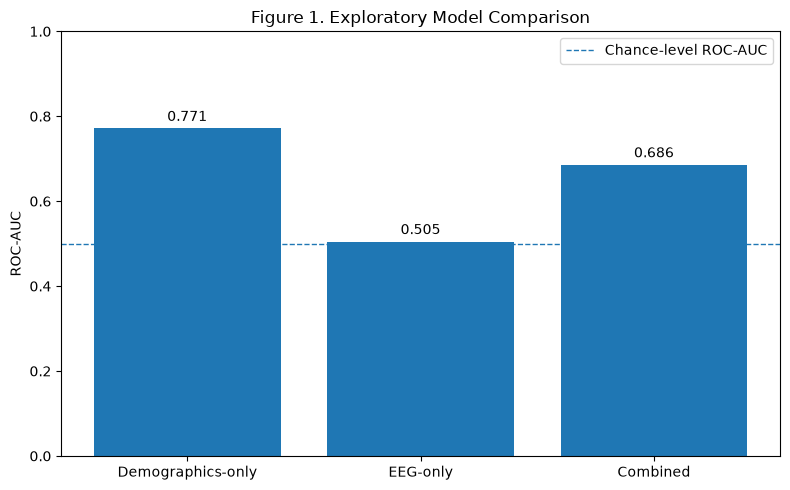

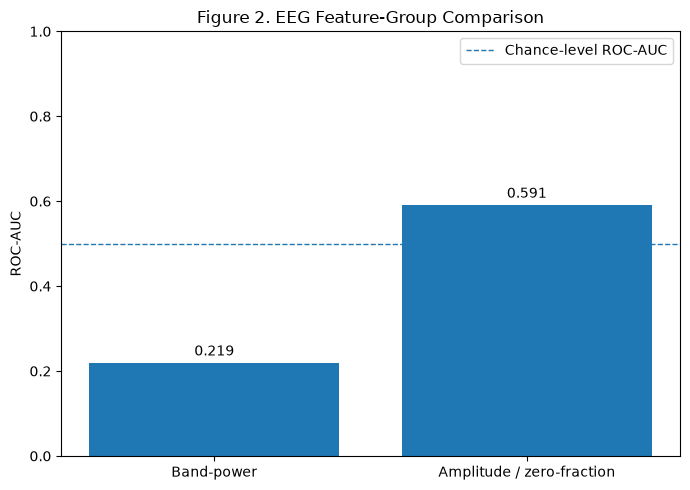

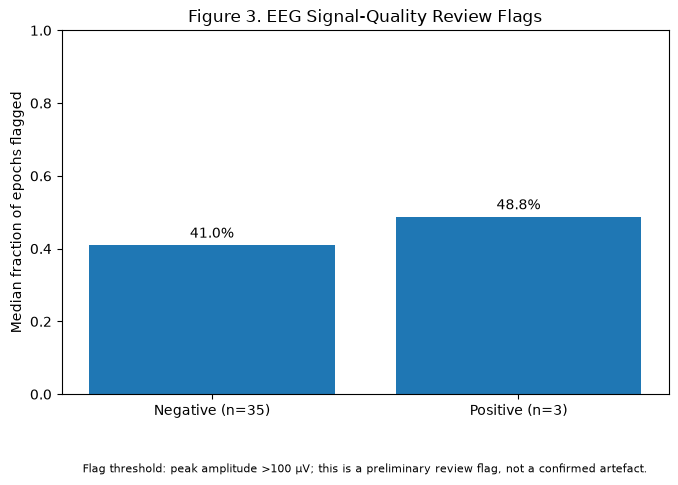

All figures saved in: d:\Downloads\BEST AI PROJECTS\BDS\data


In [266]:
# Create report-ready graphs for model comparison, EEG features, and signal quality.
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path.cwd() / "data"
data_dir.mkdir(exist_ok=True)

# FIGURE 1: Compare the three predictive models
models = pd.DataFrame({
    "Model": ["Demographics-only", "EEG-only", "Combined"],
    "ROC_AUC": [0.7714, 0.5048, 0.6857],
    "Average_Precision": [0.4879, 0.1124, 0.2135]
})

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(models["Model"], models["ROC_AUC"])
ax.axhline(0.5, linestyle="--", linewidth=1, label="Chance-level ROC-AUC")
ax.set_ylim(0, 1)
ax.set_ylabel("ROC-AUC")
ax.set_title("Figure 1. Exploratory Model Comparison")
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.legend()
plt.tight_layout()
plt.savefig(data_dir / "figure1_model_comparison.png", dpi=300)
plt.show()
plt.close()

# FIGURE 2: Compare EEG feature groups
features = pd.DataFrame({
    "Feature Group": ["Band-power", "Amplitude / zero-fraction"],
    "ROC_AUC": [0.2190, 0.5905],
    "Average_Precision": [0.0658, 0.1693]
})

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(features["Feature Group"], features["ROC_AUC"])
ax.axhline(0.5, linestyle="--", linewidth=1, label="Chance-level ROC-AUC")
ax.set_ylim(0, 1)
ax.set_ylabel("ROC-AUC")
ax.set_title("Figure 2. EEG Feature-Group Comparison")
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.legend()
plt.tight_layout()
plt.savefig(data_dir / "figure2_eeg_feature_groups.png", dpi=300)
plt.show()
plt.close()

# FIGURE 3: Compare patient-level EEG quality-review flag fractions
quality_path = data_dir / "pilot_batch_patient_quality_summary.csv"
quality = pd.read_csv(quality_path)

quality["Cognitive_Impairment"] = (
    quality["Cognitive_Impairment"]
    .astype(str).str.lower().map({"true": True, "false": False})
)

group_medians = quality.groupby("Cognitive_Impairment")[
    "flagged_epoch_fraction"
].median()

labels = ["Negative (n=35)", "Positive (n=3)"]
values = [
    group_medians.get(False, float("nan")),
    group_medians.get(True, float("nan"))
]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, values)
ax.set_ylim(0, 1)
ax.set_ylabel("Median fraction of epochs flagged")
ax.set_title("Figure 3. EEG Signal-Quality Review Flags")
ax.bar_label(bars, labels=[f"{v:.1%}" for v in values], padding=3)
ax.text(
    0.5, -0.19,
    "Flag threshold: peak amplitude >100 µV; this is a preliminary review flag, not a confirmed artefact.",
    ha="center", va="top", transform=ax.transAxes, fontsize=8, wrap=True
)
plt.tight_layout()
plt.savefig(data_dir / "figure3_quality_flags_by_label.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Save the plotted values for reproducibility
models.to_csv(data_dir / "figure1_model_comparison_data.csv", index=False)
features.to_csv(data_dir / "figure2_eeg_feature_group_data.csv", index=False)

print("All figures saved in:", data_dir)

In [267]:
print("model_data available:", "model_data" in globals())

if "model_data" in globals():
    print("Shape:", model_data.shape)
    print("Columns:", model_data.columns.tolist())
    print("\nTarget distribution:")
    print(model_data["Cognitive_Impairment"].value_counts())

model_data available: True
Shape: (38, 152)
Columns: ['BidsFolder', 'Cognitive_Impairment', 'C3-M2_std_uV_median', 'C4-M1_std_uV_median', 'F3-M2_std_uV_median', 'F4-M1_std_uV_median', 'O1-M2_std_uV_median', 'O2-M1_std_uV_median', 'C3-M2_std_uV_std', 'C4-M1_std_uV_std', 'F3-M2_std_uV_std', 'F4-M1_std_uV_std', 'O1-M2_std_uV_std', 'O2-M1_std_uV_std', 'C3-M2_std_uV_mean', 'C4-M1_std_uV_mean', 'F3-M2_std_uV_mean', 'F4-M1_std_uV_mean', 'O1-M2_std_uV_mean', 'O2-M1_std_uV_mean', 'C3-M2_peak_abs_uV_median', 'C4-M1_peak_abs_uV_median', 'F3-M2_peak_abs_uV_median', 'F4-M1_peak_abs_uV_median', 'O1-M2_peak_abs_uV_median', 'O2-M1_peak_abs_uV_median', 'C3-M2_peak_abs_uV_std', 'C4-M1_peak_abs_uV_std', 'F3-M2_peak_abs_uV_std', 'F4-M1_peak_abs_uV_std', 'O1-M2_peak_abs_uV_std', 'O2-M1_peak_abs_uV_std', 'C3-M2_peak_abs_uV_mean', 'C4-M1_peak_abs_uV_mean', 'F3-M2_peak_abs_uV_mean', 'F4-M1_peak_abs_uV_mean', 'O1-M2_peak_abs_uV_mean', 'O2-M1_peak_abs_uV_mean', 'C3-M2_zero_fraction_median', 'C4-M1_zero_fraction

C:\Users\Jay\AppData\Local\Temp\ipykernel_30904\2865487467.py:50: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
C:\Users\Jay\AppData\Local\Temp\ipykernel_30904\2865487467.py:50: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pand

,Model,ROC_AUC,Average_Precision
0,Demographics-only,0.7714,0.4879
1,EEG-only,0.5048,0.1124
2,Combined,0.6857,0.2135


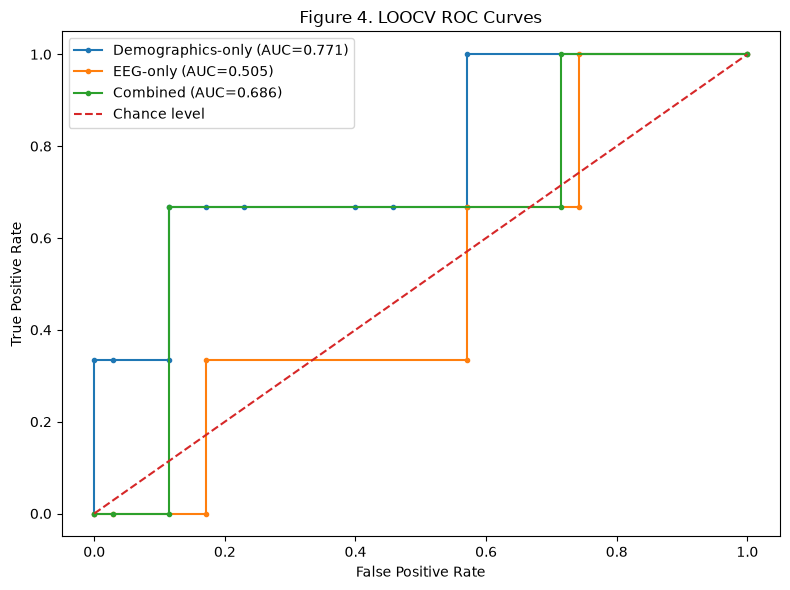

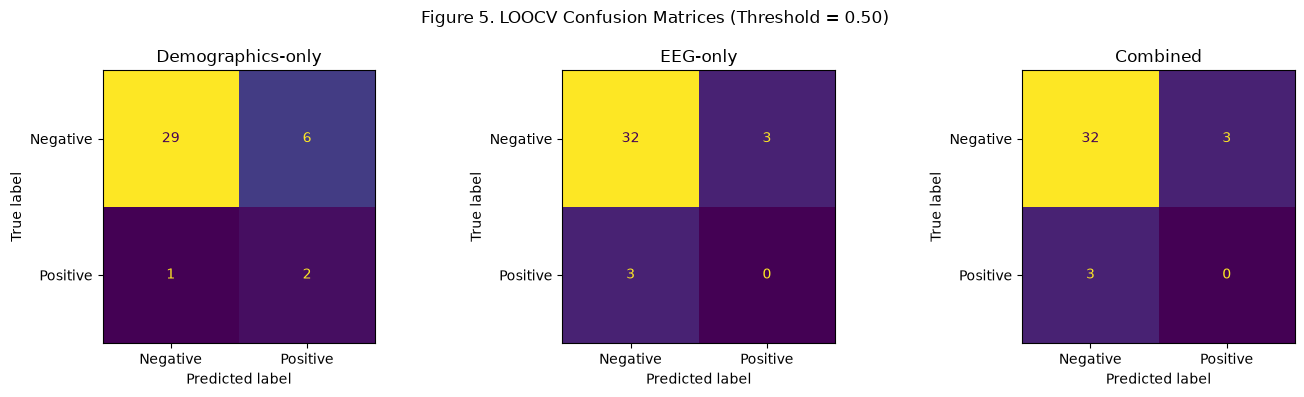

Saved ROC curve, confusion matrices, patient predictions, and metrics in: d:\Downloads\BEST AI PROJECTS\BDS\data
EEG features used: 144


In [268]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay,
    average_precision_score
)

# Target
y = model_data["Cognitive_Impairment"].astype(bool).astype(int)

# Feature groups: exclude IDs and all target-related columns
demo_cols = ["Age", "Sex", "Race", "Ethnicity", "BMI"]

eeg_cols = [
    c for c in model_data.columns
    if any(c.endswith("_" + f) for f in [
        "std_uV_median", "std_uV_std", "std_uV_mean",
        "peak_abs_uV_median", "peak_abs_uV_std", "peak_abs_uV_mean",
        "zero_fraction_median", "zero_fraction_std", "zero_fraction_mean",
        "delta_power_median", "delta_power_std", "delta_power_mean",
        "theta_power_median", "theta_power_std", "theta_power_mean",
        "alpha_power_median", "alpha_power_std", "alpha_power_mean",
        "sigma_power_median", "sigma_power_std", "sigma_power_mean",
        "beta_power_median", "beta_power_std", "beta_power_mean"
    ])
]

feature_sets = {
    "Demographics-only": demo_cols,
    "EEG-only": eeg_cols,
    "Combined": demo_cols + eeg_cols
}

loo = LeaveOneOut()
predictions = {}
summary = []

for name, cols in feature_sets.items():
    X = model_data[cols].copy()

    categorical = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numeric = [c for c in X.columns if c not in categorical]

    preprocess = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical)
    ])

    pipeline = Pipeline([
        ("preprocess", preprocess),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ])

    # Each patient's prediction comes from a model that did not train on that patient
    prob = cross_val_predict(
        pipeline, X, y, cv=loo, method="predict_proba"
    )[:, 1]

    predictions[name] = prob

    summary.append({
        "Model": name,
        "ROC_AUC": roc_auc_score(y, prob),
        "Average_Precision": average_precision_score(y, prob)
    })

results_cv = pd.DataFrame(summary)
display(results_cv.round(4))

# Figure 4: ROC curves
plt.figure(figsize=(8, 6))

for name, prob in predictions.items():
    fpr, tpr, _ = roc_curve(y, prob)
    auc = roc_auc_score(y, prob)
    plt.plot(fpr, tpr, marker=".", label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Chance level")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Figure 4. LOOCV ROC Curves")
plt.legend()
plt.tight_layout()
plt.savefig(data_dir / "figure4_roc_curves.png", dpi=300)
plt.show()
plt.close()

# Figure 5: Confusion matrices using a 0.50 probability threshold
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, prob) in zip(axes, predictions.items()):
    y_pred = (prob >= 0.50).astype(int)
    cm = confusion_matrix(y, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)

plt.suptitle("Figure 5. LOOCV Confusion Matrices (Threshold = 0.50)")
plt.tight_layout()
plt.savefig(data_dir / "figure5_confusion_matrices.png", dpi=300)
plt.show()
plt.close()

# Save predictions and metrics
for name, prob in predictions.items():
    model_data[f"LOOCV_probability_{name}"] = prob

model_data[[
    "BidsFolder", "Cognitive_Impairment"
] + [f"LOOCV_probability_{name}" for name in predictions]].to_csv(
    data_dir / "loocv_patient_predictions.csv", index=False
)

results_cv.to_csv(data_dir / "loocv_model_metrics.csv", index=False)

print("Saved ROC curve, confusion matrices, patient predictions, and metrics in:", data_dir)
print("EEG features used:", len(eeg_cols))

### 5.6 Cross-Validated Model Evaluation

Leave-One-Out Cross-Validation (LOOCV) was used to obtain out-of-fold predictions for three exploratory models: demographics-only, EEG-only, and combined demographics-plus-EEG models. The demographics-only model achieved a ROC-AUC of 0.7714 and an average precision of 0.4879. The EEG-only model achieved a ROC-AUC of 0.5048 and an average precision of 0.1124, while the combined model achieved a ROC-AUC of 0.6857 and an average precision of 0.2135.

These results indicate that the demographics-only model ranked above the EEG-only and combined models in this small pilot. Adding the extracted EEG features did not improve the observed ROC-AUC over the demographics-only baseline. However, this finding should be interpreted cautiously because the pilot included only 38 patients, of whom three had a positive cognitive-impairment label.

### 5.7 Confusion Matrix Analysis

At a probability threshold of 0.50, the demographics-only model correctly identified two of the three positive patients and classified 29 of the 35 negative patients correctly. The EEG-only and combined models classified all three positive patients as negative at this threshold. Although the EEG-only model's ROC-AUC was close to 0.50, the confusion matrix provides complementary information about its predictions at the selected threshold.

The small number of positive cases makes sensitivity estimates highly uncertain. Consequently, these confusion matrices are descriptive results for the pilot dataset and should not be interpreted as evidence of clinical readiness.

### 5.8 Overall Interpretation

The exploratory evaluation did not demonstrate improved predictive performance from adding the extracted EEG features to demographic information. The analysis also identified a potential label-leakage risk associated with the missingness pattern of `Time_to_Event`, which requires careful exclusion or separate investigation. The current results do not establish whether sleep-related EEG features provide independent predictive information, nor do they prove that shortcut learning caused the observed model behaviour.

Further evaluation with more positive cases, independent hospitals, patient-level data partitioning, and appropriately validated signal-quality procedures is required before drawing stronger conclusions.


SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (1958477688.py, line 43)


# Research Objectives, Findings, and Conclusions

## 1. Research Objective

The objective of this study is to investigate whether sleep-based AI models predict cognitive impairment using meaningful EEG information or whether their apparent predictive performance may be influenced by demographic characteristics, hospital-related metadata, recording dates, missingness patterns, or signal quality.

The study focuses on four research questions.

## 2. Research Questions

### RQ1: Does Sleep EEG Contain Predictive Information?

We investigate whether features extracted from sleep EEG recordings can predict the `Cognitive_Impairment` label and whether EEG-based models provide additional predictive value beyond demographic information.

**Preliminary findings:**
- Demographics-only model: ROC-AUC = 0.7714.
- EEG-only model: ROC-AUC = 0.5048.
- Combined demographics-plus-EEG model: ROC-AUC = 0.6857.

In the current pilot, the EEG-only model performed close to chance level, while the demographics-only model achieved a higher ROC-AUC. Adding EEG features did not improve the observed performance over the demographics-only baseline.

**Current conclusion:** The extracted EEG features did not demonstrate strong predictive performance in this pilot. However, only three positive patients were available, so these results are insufficient to conclude that sleep EEG has no predictive value.

### RQ2: Are Models Exploiting Hospital or Recording-Date Information?

We investigate whether hospital site or recording time may act as shortcuts that help a model predict the target without relying on meaningful EEG information.

**Preliminary findings from the demographic cohort:**
- Site-only baseline ROC-AUC: 0.5195.
- Creation-year-only baseline ROC-AUC: 0.6725.

The creation-year baseline showed some ability to distinguish the target labels, whereas the site-only baseline performed close to chance level.

**Current conclusion:** Recording-year information warrants further investigation as a potential source of shortcut learning. However, these baseline results do not prove that a trained EEG model exploits recording dates. All eligible EEG recordings in the current pilot came from one hospital site, so cross-hospital generalization has not been evaluated.

### RQ3: Can Data Leakage or Missingness Make Prediction Artificially Easy?

We investigate whether missing values or metadata fields reveal information about the target that would not legitimately be available at prediction time.

**Key finding:**

The missingness pattern of `Time_to_Event` was perfectly aligned with the target label in the demographic cohort:
- All 1,019 negative cases had missing `Time_to_Event` values.
- All 84 positive cases had non-missing values.

This pattern creates a strong potential data-leakage risk. Consequently, `Time_to_Event` was excluded from the ordinary demographic prediction models.

**Current conclusion:** The analysis identified a concrete leakage risk associated with this field's missingness. Further investigation is needed to understand why the pattern occurs and whether it reflects dataset construction, clinical workflow, or another process.

### RQ4: Does Predictive Performance Remain Under Fair Evaluation?

We investigate whether model performance remains credible when predictions are generated without training on the patient being evaluated.

**Evaluation performed:**
- Leave-One-Out Cross-Validation (LOOCV).
- Demographics-only, EEG-only, and combined model comparison.
- ROC-AUC and average precision.
- Confusion matrices at a probability threshold of 0.50.

**Preliminary findings:**

The demographics-only model performed better than the EEG-only and combined models in the current pilot. However, the EEG pilot contained only 38 patients, including three positive cases, making the estimates highly uncertain.

**Current conclusion:** Initial patient-level cross-validation has been performed, but the available data do not support strong claims about generalization. Confidence intervals and held-out-hospital evaluation remain important next steps, subject to the availability of sufficient eligible data.

## 3. Summary of Current Findings

| Research question | Current status |
|---|---|
| Predictive information in sleep EEG | Explored; independent predictive value remains uncertain |
| Hospital and recording-date shortcuts | Preliminary baselines evaluated; shortcut exploitation not established |
| Data leakage and missingness | Strong potential leakage risk identified |
| Fair evaluation and generalization | LOOCV completed; further validation is required |

## 4. Overall Conclusion

This study identified a strong potential data-leakage risk associated with the missingness of `Time_to_Event`. In the small, single-site EEG pilot, the extracted EEG features did not demonstrate better predictive performance than demographic features under Leave-One-Out Cross-Validation.

The results highlight the importance of auditing metadata, missingness patterns, and signal quality when evaluating sleep-based AI models. However, the small number of positive patients limits the reliability of the current estimates. The independent predictive value of sleep EEG, the extent of shortcut learning, and generalization across hospitals remain unresolved.

The current findings should therefore be interpreted as preliminary evidence from an exploratory audit rather than as a validated dementia-prediction system.

## 5. Future Work

1. Increase the number of eligible patients with positive cognitive-impairment labels.
2. Investigate the source and predictive implications of recording-date and other metadata.
3. Validate signal-quality assessment procedures and evaluate their influence on EEG features.
4. Report uncertainty estimates, including confidence intervals where appropriate.
5. Evaluate models on an independent hospital, if sufficient eligible data are available.
6. Confirm the dataset's definition of `Cognitive_Impairment` and avoid treating it as a confirmed dementia diagnosis without supporting documentation.

## Final Takeaway

**The strongest finding so far is the identification of a potential data-leakage risk. The EEG experiments provide a preliminary comparison, but more evidence is needed to establish independent EEG predictive value or cross-hospital generalization.**
